# IT9002 Natural Language Processing — Individual Project
## Notebook 1 of 3: Task 1 — Clause-type classification of commercial contracts (CUAD, 27 classes)

**Student:** see the setup cell below, which reads `project_info.json` · **Course:** IT9002 Natural Language Processing

**Dataset:** Contract Understanding Atticus Dataset (CUAD) v1 — https://www.atticusprojectai.org/cuad
(data and code: https://github.com/TheAtticusProject/cuad), licence CC BY 4.0.

| Section | Content | Rubric |
|---|---|---|
| 0 | How to run, setup | — |
| 1 | Problem statement and measurable objectives | Part A, problem statement |
| 2 | Dataset: leakage check and confusion hypotheses first, then source, curation, split, distributions | Part A, dataset |
| 3 | Preprocessing study (classical models), transformer input, Task 2 input | Part A, preprocessing |
| 4 | Classical baselines: majority class + three TF-IDF classifiers | Part B, Task 1 classical |
| 5 | Fine-tuned transformer (Legal-BERT) and the controlled ablation (BERT-base) | Part B, Task 1 transformer; Part C ablation |

Task 2 (clause extraction) has its own notebook (`202609212_Task2.ipynb`), and the prompted LLMs are in `202609212_LLM.ipynb`.

### How to run
* **Locally:** open this notebook from the project folder with the project's Python environment (`.venv`)
  and choose *Run All*. The data is already in `data/processed/`.
* **Google Colab:** *File → Open notebook → GitHub*, paste the repository URL, open this notebook and choose
  *Runtime → Run all*. The setup cell detects Colab, downloads the project code and data from GitHub and
  checks the data files against their SHA-256 checksums before anything else runs.
* Heavy steps have a switch (`RUN_SEARCH`, `RETRAIN`). With `False` the notebook loads the saved results of the real
  run, so it can be re-run in a few minutes. With `True` everything is recomputed.

## ▶ Run on Google Colab (skip this on your own computer)
**For markers using Google Colab.** Runtime → Change runtime type → **GPU** (T4 is enough), then Runtime → **Run all**.
The cell below gets the project — from the GitHub repository if its URL is set, otherwise from the submission ZIP uploaded
to Google Drive (default `MyDrive/IT9002_202609212.zip`; change `ZIP_PATH` if it is elsewhere) — installs the pinned
packages and moves into the project folder. On your own computer it does nothing. Colab starts without the trained models
(`models/`, too large to share), so cells that need them print **SKIPPED** with retraining instructions and then show the
outputs those cells produced in the real run (tables, figures, text, labelled SAVED); the DEMO sections do the same.

In [1]:
# ==== RUN ON GOOGLE COLAB - does nothing on your own computer ====
import os, sys, subprocess, zipfile
from pathlib import Path
SIMULATE = os.environ.get("IT9002_SIMULATE_COLAB") == "1"         # local test of the Colab path
IN_COLAB = "google.colab" in sys.modules or SIMULATE
GITHUB_URL = "https://github.com/202609212-AbdullaAlhermi/IT9002-202609212-Project"                             # the project's GitHub repository (as in project_info.json)
ZIP_PATH = "/content/drive/MyDrive/IT9002_202609212.zip"           # used when the repository cannot be cloned

def find_root(start):
    """The project folder = the first folder, going upwards, that contains project_info.json."""
    return next((d for d in [start, *start.parents] if (d / "project_info.json").exists()), None)

if IN_COLAB:
    base = Path(os.environ.get("IT9002_COLAB_BASE", "/content"))
    root = find_root(Path.cwd())
    if root is None and GITHUB_URL.startswith("https://github.com/"):            # a) clone the repository
        clone = base / "IT9002_project"
        if not clone.exists():
            # no password prompt: a private repository simply fails here and the ZIP route below is used instead
            r = subprocess.run(["git", "-c", "credential.helper=", "clone", "--depth", "1", GITHUB_URL, str(clone)],
                               env=dict(os.environ, GIT_TERMINAL_PROMPT="0"), capture_output=True, text=True)
            if r.returncode != 0:
                print("Could not clone the repository (it may be private); using the submission ZIP from Google Drive.")
        root = clone if (clone / "project_info.json").exists() else None
    if root is None:                                                             # b) unzip the submission ZIP from Drive
        if not SIMULATE:
            from google.colab import drive
            drive.mount("/content/drive")
        zp = Path(os.environ.get("IT9002_COLAB_ZIP", ZIP_PATH))
        assert zp.exists(), f"Upload the submission ZIP to Google Drive and set ZIP_PATH (not found: {zp})"
        with zipfile.ZipFile(zp) as z:
            root = base / z.namelist()[0].split("/")[0]
            if not root.exists():
                z.extractall(base)
    os.chdir(root / "notebooks")
    # pinned requirements, but keep Colab's own CUDA build of torch and its Jupyter packages
    keep = ("torch", "jupyterlab", "ipykernel", "nbformat", "nbconvert", "nbclient")
    reqs = [l.strip() for l in (root / "requirements.txt").read_text().splitlines()
            if l.strip() and not l.startswith("#") and not l.split("==")[0].strip().lower().startswith(keep)]
    (root / "requirements_colab.txt").write_text("\n".join(reqs) + "\n")
    loaded = {m: sys.modules[m].__version__ for m in ("numpy", "pandas", "scipy", "sklearn") if m in sys.modules}
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements_colab.txt")]
                   + (["--dry-run"] if SIMULATE else []), check=True)
    pins = dict(l.split("==") for l in reqs if "==" in l)
    stale = [m for m, v in loaded.items() if pins.get({"sklearn": "scikit-learn"}.get(m, m), v) != v]
    if stale and not SIMULATE:
        raise RuntimeError(f"New versions of {stale} were installed: Runtime -> Restart session, then Run all again.")
    from importlib.metadata import version
    print(f"Colab: project folder {root} | pinned requirements {'checked (dry run)' if SIMULATE else 'installed'} | "
          f"torch {version('torch')} kept")
else:
    print("Not on Colab: nothing to do here.")

Not on Colab: nothing to do here.


## 0. Setup

**What these cells do:** find the project folder (on Colab the cell above has fetched it), make our helper code in
`src/` importable, fix the random seed (42), print the software and hardware we use (the report must state them),
and load the frozen dataset after checking its checksums.

In [2]:
import sys, os, json, platform, subprocess, importlib, re, warnings, contextlib, io
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or os.environ.get("IT9002_SIMULATE_COLAB") == "1"
# The project folder = the first folder, going upwards, that contains project_info.json (works from notebooks/, from the
# project folder and on Colab, where the cell above has moved into the project).
ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "project_info.json").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# ---- 2. Our helper modules (src/common.py, src/preprocess.py, src/plotting.py) ----
from src import common as C
from src import preprocess as P
from src import plotting as PL
importlib.reload(C); importlib.reload(P); importlib.reload(PL)

INFO = C.load_project_info()
C.register_needs_models()   # defines %%needs_models: cells that need models/ (not in the ZIP) skip cleanly if it is missing
print(f"Student: {INFO['STUDENT_NAME']}  |  ID: {INFO['STUDENT_ID']}  |  {INFO['COURSE_CODE']} {INFO['COURSE_NAME']}")
print("Dataset:", INFO["DATASET_URL"], "|", INFO["DATASET_CODE_URL"])

# ---- 3. Reproducibility ----
C.set_seed(42)
PL.setup_style()

# ---- 4. Software and hardware (the report must state these) ----
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np, pandas as pd, sklearn, matplotlib, nltk, torch, transformers
transformers.logging.set_verbosity_error()   # hides "sequence longer than 512" notices while we only COUNT tokens
print(f"Python {platform.python_version()} on {platform.platform()}  |  Colab: {IN_COLAB}")
print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"nltk {nltk.__version__} | torch {torch.__version__} | transformers {transformers.__version__}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU only)")
P.ensure_nltk_data()   # stop-word list + WordNet; downloads them once if missing (also behind Colab's proxy)

Student: Abdulla Alhermi  |  ID: 202609212  |  IT9002 Natural Language Processing
Dataset: https://www.atticusprojectai.org/cuad | https://github.com/TheAtticusProject/cuad


Python 3.11.9 on Windows-10-10.0.26200-SP0  |  Colab: False
numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | nltk 3.10.3 | torch 2.11.0+cu128 | transformers 5.20.1
GPU: NVIDIA GeForce RTX 5080


In [3]:
# ---- 5. Data: use the frozen files; if missing, fetch or rebuild them, then verify the checksums ----
PROCESSED = ROOT / "data" / "processed"
# Frozen CSVs: already here, or downloaded from the project's GitHub repository, or rebuilt from the official CUAD release
# (scripts/download_cuad.py + scripts/build_dataset_v2.py); in every case verified against the frozen SHA-256 checksums.
C.ensure_data(INFO["GITHUB_URL"])
df = C.load_clauses()
STATS = C.load_build_stats()               # every dataset number quoted below comes from here or from the CSVs
LABELS = C.get_labels(df)
ROBUST = C.robust_labels(df)               # classes with >= 15 test clauses (robustness number, see 2.8)
train, val, test = (df[df.split == s] for s in ["train", "validation", "test"])
print(f"{len(df):,} clauses | {len(LABELS)} classes | train {len(train):,} / validation {len(val):,} / test {len(test):,}")
df.head(3)

OK  task1_clauses_v2.csv  (SHA-256 matches the frozen file)
OK  task1_ambiguous_v2.csv  (SHA-256 matches the frozen file)
OK  task2_spans.csv  (SHA-256 matches the frozen file)
OK  contract_split.csv  (SHA-256 matches the frozen file)
7,785 clauses | 27 classes | train 5,315 / validation 1,026 / test 1,444


,row_id,contract,category,start,text,split,n_words
0,0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Expiration Date,5268,The term of this Agreement shall be ten (10) y...,train,31
1,1,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Renewal Term,5543,If Distributor complies with all of the terms ...,train,42
2,2,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGRE...,Governing Law,52061,This Agreement is to be construed according to...,train,15


## 1. Problem statement

**Domain.** Legal and policy documents — commercial contract review. The corpus consists of commercial contracts
filed with the U.S. Securities and Exchange Commission (SEC).

**The problem.** Commercial contracts are long (section 2.4 measures them: thousands of words each), yet a reviewer's
job is to find a small number of risk-bearing clauses — for example a cap on liability, an audit right, a
change-of-control provision, the governing law — check each one against the organisation's playbook, and notice
wording that is unusual. Recognising *what legal function a passage performs* and *where it is* is slow, repetitive
expert work.

**Questions addressed — two tasks that build on each other.**
1. *Task 1 (this notebook): what type is this clause?* Given the text of one clause, can a model recognise which of
   the expert-defined clause types it is, and how do classical TF-IDF classifiers, a fine-tuned transformer and two
   prompted LLMs compare in accuracy, cost and latency?
2. *Task 2 (`202609212_Task2.ipynb`): where in the contract are the clauses of each type?* Given a whole contract, find
   the spans that contain a clause of each type (clause extraction as sequence labelling).

Task 1 assumes the clause has already been located; Task 2 locates it. Part F chains them: extract a clause
(Task 2), confirm its type (Task 1), and flag it if it reads unusually for that type.

**Stakeholders.** In-house counsel; contract-management and compliance teams; legal-technology tools (clause search,
contract-review checklists) that support them.

**Intended use.** *Decision support for a human reviewer* — find the clause, name its type, point out unusual wording
— **not** legal advice. Every prediction is meant to be checked by a person. This matters for the choice of metric:
a clause type that the model systematically misses is costlier than a false flag that a reviewer dismisses in seconds,
and rare clause types matter as much as common ones. The primary metric is therefore **macro-F1** (the unweighted mean
of the per-class F1 scores), backed by per-class recall.

**Why clause level for Task 1.** Classifying whole contracts by type was rejected by the tutor (too few contracts per
type, the type is usually in the title, contracts are far longer than a transformer's input window). One clause is
short (section 2.9), so every model can read the whole input.

### Measurable objectives
These replace objectives O1–O4 of the approved proposal form after the tutor's feedback (deviation D6
in the report). Each will be marked **met / not met** at the end, using only saved result files.

| ID | Objective | Measured by | Met if … |
|---|---|---|---|
| **O1** | All Task 1 models are scored on the **same held-out test set** (the test clauses of the 93 official CUAD test contracts that contain a single-label clause) with macro-F1; Task 2 models on all 102 official test contracts | `results/test_eval_log.csv` | each model has exactly one test evaluation, on the same clauses / contracts |
| **O2** | The best TF-IDF classifier beats the majority-class baseline **by a wide margin** | test macro-F1 | gap ≥ **0.50** macro-F1 (only reachable by reading the clauses) |
| **O3** | The fine-tuned transformer is compared with the best classical model and with **two** prompted LLMs on **macro-F1, cost per 1,000 clauses and latency** | comparison table, `results/compute_budget.csv` | all three quantities reported; *H1: Legal-BERT > best TF-IDF* is supported only if the paired contract-level bootstrap 95 % CI of the macro-F1 difference lies above 0 |
| **O4** | Task 2: the Legal-BERT extractor beats the TF-IDF segment baseline on macro entity-F1 at IoU ≥ 0.5, and is compared with the CUAD paper's published AUPR on the same test split | Task 2 notebook | paired contract-level bootstrap CI above 0; comparison reported |
| **O5** | (self-imposed, exploratory) **no clause type is systematically missed** | per-class test recall of the best Task 1 model | recall ≥ **0.70** for every class (expected to fail for some rare classes; reported honestly) |
| **O6** | (Part F) the best anomaly scorer detects injected wrong-type clauses | AUROC with 95 % CI | CI above 0.5; the human part is "not assessed" unless the student fills the blind-review sheet |

## 2. Dataset

The section opens with the two checks that shape everything after it: **why the data is split by contract**
(a measured leakage check) and **which clause types we expect to be confused** (hypotheses written down before any
model is trained, tested in section 4). The descriptive part (source, curation, split sizes, distributions) follows.

### 2.1 Why split by contract? A data-driven leakage check
**Hypothesis:** with a random *clause-level* split, near-identical clauses from the same contract (or the same
template) land on both sides, so the held-out score is inflated.

**Method (test contracts never touched):** we take only the train + validation contracts and, five times
(seeds 0–4), hold out 20 % in two ways — (a) a random clause-level split (stratified by class), (b) a contract-level
split (`GroupShuffleSplit`). For each held-out clause we find its most similar training clause (cosine similarity of
TF-IDF vectors) and count **near-duplicates (similarity ≥ 0.9)** and **nearest neighbours from the same contract**;
and we train the same default TF-IDF + LinearSVC on each split and score macro-F1 on the held-out part.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

pool = pd.concat([train, val]).reset_index(drop=True)           # NO test contracts in this experiment
Xpool = TfidfVectorizer().fit_transform(pool.text)              # rows are L2-normalised -> dot product = cosine

rows = []
for seed in range(5):
    tr_r, ho_r = train_test_split(np.arange(len(pool)), test_size=0.2, random_state=seed, stratify=pool.category)
    tr_g, ho_g = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
                      .split(pool, groups=pool.contract))
    for kind, tr_i, ho_i in [("random clause-level", tr_r, ho_r), ("contract-level", tr_g, ho_g)]:
        sim = (Xpool[ho_i] @ Xpool[tr_i].T).toarray()
        best = sim.argmax(axis=1)
        same_contract = (pool.contract.values[tr_i][best] == pool.contract.values[ho_i]).mean()
        vec = TfidfVectorizer().fit(pool.text.iloc[tr_i])
        clf = LinearSVC(random_state=42).fit(vec.transform(pool.text.iloc[tr_i]), pool.category.iloc[tr_i])
        pred = clf.predict(vec.transform(pool.text.iloc[ho_i]))
        rows.append({"seed": seed, "split": kind, "held_out": len(ho_i),
                     "near_duplicate_share": (sim.max(axis=1) >= 0.9).mean(),
                     "nearest_neighbour_same_contract": same_contract,
                     "macro_f1": f1_score(pool.category.iloc[ho_i], pred, labels=LABELS, average="macro",
                                          zero_division=0)})
leak = pd.DataFrame(rows)
leak.to_csv(C.RESULTS_DIR / "leakage_check.csv", index=False)
leak_sum = leak.groupby("split")[["held_out", "near_duplicate_share", "nearest_neighbour_same_contract", "macro_f1"]].agg(["mean", "std"])
display(leak_sum.round(3))

held_out          near_duplicate_share         \
                        mean      std                 mean    std   
split                                                               
contract-level        1243.2  111.815                0.027  0.008   
random clause-level   1269.0    0.000                0.064  0.008   

                    nearest_neighbour_same_contract        macro_f1         
                                               mean    std     mean    std  
split                                                                       
contract-level                                0.000  0.000    0.765  0.010  
random clause-level                           0.483  0.006    0.791  0.007

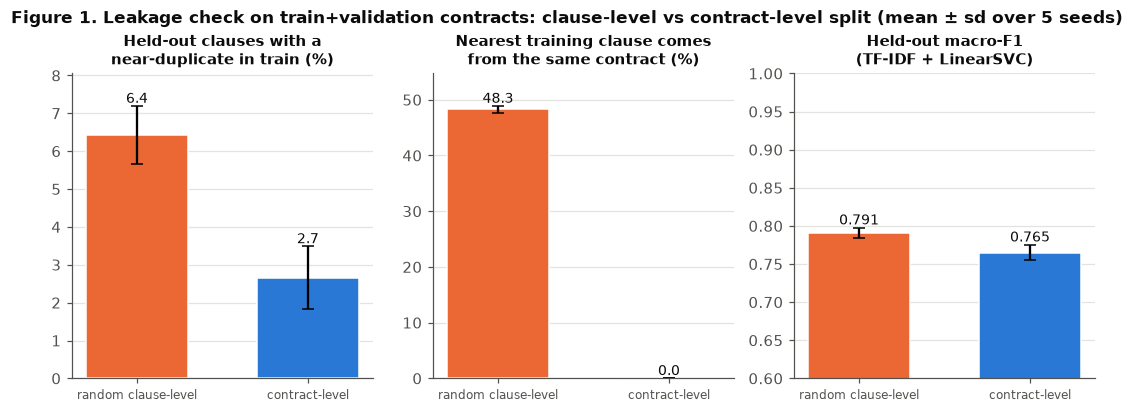

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
order = ["random clause-level", "contract-level"]
cols = [PL.ORANGE, PL.BLUE]
for ax, (col, title, scale) in zip(axes, [
        ("near_duplicate_share", "Held-out clauses with a\nnear-duplicate in train (%)", 100),
        ("nearest_neighbour_same_contract", "Nearest training clause comes\nfrom the same contract (%)", 100),
        ("macro_f1", "Held-out macro-F1\n(TF-IDF + LinearSVC)", 1)]):
    m = leak.groupby("split")[col].mean().loc[order] * scale
    s = leak.groupby("split")[col].std().loc[order] * scale
    ax.bar(order, m, yerr=s, color=cols, width=0.6, capsize=4, edgecolor="white")
    for i, (v, e) in enumerate(zip(m, s)):
        ax.text(i, v + e, f"{v:.3f}" if scale == 1 else f"{v:.1f}", ha="center", va="bottom", fontsize=9,
                color=PL.INK)
    ax.margins(y=0.12)
    ax.set_title(title, fontsize=10); ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8)
axes[2].set_ylim(0.6, 1.0)
fig.suptitle("Figure 1. Leakage check on train+validation contracts: clause-level vs contract-level split "
             "(mean ± sd over 5 seeds)", fontweight="bold", fontsize=11, y=1.04)
PL.savefig(fig, 1, "leakage_check"); plt.show()

**Interpretation (`results/leakage_check.csv`).** With a random clause-level split, **48 %** of held-out clauses have
their most similar training clause in the *same contract*, and 6.4 % have a near-duplicate (cosine ≥ 0.9) in
training, against 0 % and 2.7 % with a contract-level split. (The remaining 2.7 % are boilerplate that genuinely
recurs across different companies' contracts — legitimate, not leakage.) The same default model scores **0.791**
macro-F1 under the clause-level split but **0.765** under the contract-level split: about 0.03 of the apparent
performance comes from recognising the contract, not the clause type. A contract-level split is therefore required
for an honest estimate on *new* contracts — the real use case — and the same contract split is used for Task 2.
Section 4.7 repeats the check with the tuned best classical model.

### 2.2 New classes and the confusions we expect (hypotheses, written before training)
Following the tutor's feedback, the label set grew from the first design to 27 classes by lowering the minimum class
size (section 2.5). The added classes sit right next to existing ones in meaning, which is exactly what makes the
task harder. We write down **which confusions we expect** now, and test them in section 4 against the confusion
pairs of the best classical model on **validation**.

As a first data check (training clauses only), we measure how similar each new class is to its hypothesised
neighbours: the cosine similarity between the classes' average TF-IDF vectors (centroids). A high similarity means a
bag-of-words model will find the pair hard.

,new class,likely confused with,why,centroid cosine,median cosine to all other classes
0,Non-Transferable License,License Grant,both describe the licence that is granted,0.774,0.428
1,Non-Transferable License,Anti-Assignment,both restrict transfer / assignment,0.540,0.428
2,No-Solicit Of Employees,Non-Compete,both are post-contract restrictive covenants,0.579,0.359
3,Competitive Restriction Exception,Exclusivity,an exception is written inside the exclusivity clause,0.701,0.519
4,Competitive Restriction Exception,Non-Compete,an exception is written inside the non-compete clause,0.699,0.519
5,Liquidated Damages,Cap On Liability,both fix an amount payable on breach,0.492,0.407
6,Joint Ip Ownership,Ip Ownership Assignment,both decide who owns intellectual property,0.669,0.418
7,Source Code Escrow,License Grant,escrow release usually triggers a licence to the code,0.386,0.335
8,Non-Disparagement,Covenant Not To Sue,both restrict what one party may say or do against the other,0.557,0.404


Nearest class by TF-IDF centroid (training clauses):
  Competitive Restriction Exception   -> Exclusivity                  cosine 0.701
  Joint Ip Ownership                  -> Ip Ownership Assignment      cosine 0.669
  Liquidated Damages                  -> Post-Termination Services    cosine 0.610
  No-Solicit Of Employees             -> Non-Compete                  cosine 0.579
  Non-Disparagement                   -> Non-Compete                  cosine 0.590
  Non-Transferable License            -> License Grant                cosine 0.774
  Source Code Escrow                  -> Post-Termination Services    cosine 0.439


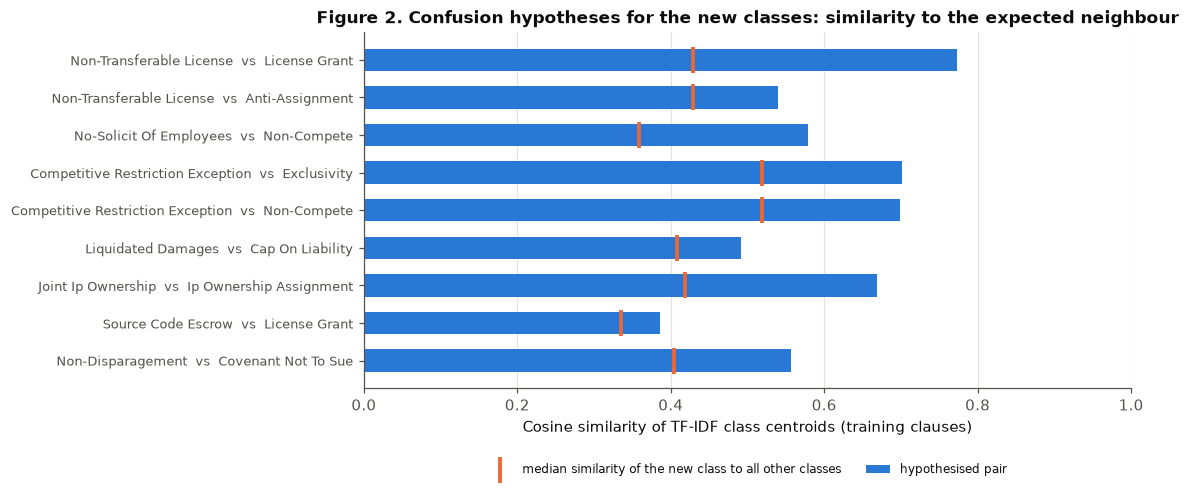

In [6]:
NEW_CLASSES = ["Competitive Restriction Exception", "Joint Ip Ownership", "Liquidated Damages",
               "No-Solicit Of Employees", "Non-Disparagement", "Non-Transferable License", "Source Code Escrow"]
assert set(NEW_CLASSES) <= set(LABELS)
HYPOTHESES = [  # (new class, existing class it is likely to be confused with, why)
    ("Non-Transferable License", "License Grant", "both describe the licence that is granted"),
    ("Non-Transferable License", "Anti-Assignment", "both restrict transfer / assignment"),
    ("No-Solicit Of Employees", "Non-Compete", "both are post-contract restrictive covenants"),
    ("Competitive Restriction Exception", "Exclusivity", "an exception is written inside the exclusivity clause"),
    ("Competitive Restriction Exception", "Non-Compete", "an exception is written inside the non-compete clause"),
    ("Liquidated Damages", "Cap On Liability", "both fix an amount payable on breach"),
    ("Joint Ip Ownership", "Ip Ownership Assignment", "both decide who owns intellectual property"),
    ("Source Code Escrow", "License Grant", "escrow release usually triggers a licence to the code"),
    ("Non-Disparagement", "Covenant Not To Sue", "both restrict what one party may say or do against the other"),
]
vec = TfidfVectorizer(sublinear_tf=True, min_df=2).fit(train.text)
cent = {lab: np.asarray(vec.transform(train.text[train.category == lab]).mean(axis=0)).ravel() for lab in LABELS}
cos = lambda a, b: float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
hyp = pd.DataFrame([(n, e, why, cos(cent[n], cent[e]),
                     np.median([cos(cent[n], cent[o]) for o in LABELS if o != n]))
                    for n, e, why in HYPOTHESES],
                   columns=["new class", "likely confused with", "why", "centroid cosine", "median cosine to all other classes"])
hyp.to_csv(C.RESULTS_DIR / "confusion_hypotheses.csv", index=False)
pd.set_option("display.max_colwidth", 70)
display(hyp.round(3))

# Most similar class for every new class (data, not hypothesis)
nearest = {n: max((o for o in LABELS if o != n), key=lambda o: cos(cent[n], cent[o])) for n in NEW_CLASSES}
print("Nearest class by TF-IDF centroid (training clauses):")
for n, o in nearest.items():
    print(f"  {n:<35} -> {o:<28} cosine {cos(cent[n], cent[o]):.3f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
lab = [f"{n}  vs  {e}" for n, e in zip(hyp["new class"], hyp["likely confused with"])][::-1]
yy = np.arange(len(lab))
ax.barh(yy, hyp["centroid cosine"][::-1], color=PL.BLUE, height=0.6, label="hypothesised pair")
ax.scatter(hyp["median cosine to all other classes"][::-1], yy, color=PL.ORANGE, marker="|", s=300, linewidths=2.5,
           zorder=3, label="median similarity of the new class to all other classes")
ax.set_yticks(yy); ax.set_yticklabels(lab, fontsize=8.5); ax.set_xlim(0, 1)
ax.set_xlabel("Cosine similarity of TF-IDF class centroids (training clauses)"); ax.grid(axis="y", visible=False)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.set_title("Figure 2. Confusion hypotheses for the new classes: similarity to the expected neighbour", fontsize=11)
PL.savefig(fig, 2, "confusion_hypotheses"); plt.show()

**Interpretation (`results/confusion_hypotheses.csv`, Figure 2).** Every hypothesised pair is more similar than the new
class's median similarity to the other classes, so all nine are plausible confusions for a bag-of-words model. The
strongest are **Non-Transferable License vs License Grant** (cosine 0.774 against a median of 0.428),
**Competitive Restriction Exception vs Exclusivity / Non-Compete** (0.701 / 0.699) and **Joint Ip Ownership vs Ip
Ownership Assignment** (0.669). The data also points to neighbours we had not written down: the closest class to
**Liquidated Damages** is Post-Termination Services (0.610, closer than Cap On Liability at 0.492), Non-Disparagement
is closest to Non-Compete (0.590), and Source Code Escrow to Post-Termination Services (0.439). These are similarities
of class *averages*; whether a trained model actually confuses the pairs is tested on validation in section 4.4.

### 2.3 Source, licence, size and modality

| Property | Value |
|---|---|
| Name | Contract Understanding Atticus Dataset (CUAD) v1 |
| Citation | Hendrycks, D., Burns, C., Chen, A., & Ball, S. (2021). CUAD: An expert-annotated NLP dataset for legal contract review. *Proceedings of the Neural Information Processing Systems Track on Datasets and Benchmarks, 1.* |
| Paper | https://datasets-benchmarks-proceedings.neurips.cc/paper/2021/hash/6ea9ab1baa0efb9e19094440c317e21b-Abstract-round1.html |
| Dataset page / data | https://www.atticusprojectai.org/cuad · https://github.com/TheAtticusProject/cuad (`data.zip`) |
| Licence | CC BY 4.0 (free to use, including academic work, with attribution) |
| Modality | Text (English) |
| Original size and our Task 1 / Task 2 data | printed by the cell below from `build_stats_v2.json` and the CSVs |

In [7]:
spans2 = C.load_task2_spans()
csplit = C.load_contract_split()
raw_contracts = json.load(open(C.RAW_CUAD, encoding="utf-8"))["data"]
all_cats = {re.search(r'"([^"]+)"', q["question"]).group(1) for c in raw_contracts for q in c["paragraphs"][0]["qas"]}
print(f"CUAD v1: {STATS['n_contracts']} contracts ({STATS['n_official_test_contracts']} official test contracts), "
      f"{len(all_cats)} clause categories, {STATS['spans_total']:,} expert-labelled spans")
print(f"Task 1: {STATS['task1_clauses']:,} single-label clauses in {len(STATS['kept_categories'])} classes")
print(f"Task 2: {len(spans2):,} (span, category) annotations on "
      f"{spans2.drop_duplicates(['contract', 'start', 'end']).shape[0]:,} distinct spans, in {csplit.contract.nunique()} contracts")
print("Keys available in build_stats_v2.json:", ", ".join(sorted(STATS)))

CUAD v1: 510 contracts (102 official test contracts), 41 clause categories, 13,823 expert-labelled spans
Task 1: 7,785 single-label clauses in 27 classes
Task 2: 8,993 (span, category) annotations on 8,387 distinct spans, in 510 contracts
Keys available in build_stats_v2.json: all_contracts_per_split, ambiguous_clauses, clause_words_median, clause_words_p95, dropped_categories, duplicates_removed_from_val_test, kept_categories, n_contracts, n_official_test_contracts, per_class, raw_sha256, single_label_before_dedup, smallest_test_class, smallest_validation_class, spans_misaligned_with_context, spans_total, task1_clauses, task1_split_clauses, task1_split_contracts, task2_contracts_with_spans_per_split, task2_multi_category_spans, task2_spans, task2_spans_per_split


### 2.4 How clauses are extracted from the original files
CUAD is distributed in the SQuAD question-answering format: each contract is one long text, and for each of the
41 categories there is a "question" (e.g. *Highlight the parts (if any) of this contract related to "Governing
Law"…*) whose "answers" are the character spans that the lawyers highlighted. **Each highlighted span becomes one
clause in Task 1, labelled with the category in the question; Task 2 keeps the span's character offsets in the full
contract.** The cell below shows one real example.

In [8]:
c0 = raw_contracts[0]
qa = next(q for q in c0["paragraphs"][0]["qas"] if q["answers"])
print("Contract title     :", c0["title"])
print("Contract length    :", f'{len(c0["paragraphs"][0]["context"].split()):,} words')
print("Question (category):", qa["question"][:160], "...")
print("First answer span  :", repr(qa["answers"][0]["text"][:200]))
print("answer_start       :", qa["answers"][0]["answer_start"], "(character offset in the contract)")
contract_words = [len(c["paragraphs"][0]["context"].split()) for c in raw_contracts]
print(f"\nWhole contracts: median {int(np.median(contract_words)):,} words, max {max(contract_words):,} "
      "-> far too long for a 512-token transformer; one clause is not.")

Contract title     : LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Contract length    : 5,998 words
Question (category): Highlight the parts (if any) of this contract related to "Document Name" that should be reviewed by a lawyer. Details: The name of the contract ...
First answer span  : 'DISTRIBUTOR AGREEMENT'
answer_start       : 44 (character offset in the contract)

Whole contracts: median 5,006 words, max 47,733 -> far too long for a 512-token transformer; one clause is not.


### 2.5 Curation log (datasheet style)
The dataset was built once by `scripts/build_dataset_v2.py` and frozen. The cell below reads the curation counts it
saved (`build_stats_v2.json`), re-runs the build script into `data/processed/_rebuild_v2/` (never over the frozen
files), and checks that the rebuilt data is identical to the frozen data.

Curation decisions and why:
1. **Drop 4 entity/date categories** (Parties, Document Name, Agreement Date, Effective Date): their spans are short
   names or dates, not clauses, so "classifying" them would be a different task (entity recognition).
2. **Minimum class size — at least 60 unambiguous clauses per category**, applied *iteratively* (drop the weakest
   category, recompute, repeat), because dropping a category can turn an ambiguous span back into an unambiguous one.
   The threshold is lower than in the first design (which kept fewer, larger classes) because the tutor asked for a
   broader range of categories; 60 still leaves every class with training examples and at least a few test clauses.
3. **Hold out ambiguous clauses from Task 1** (section 2.6).
4. **Whitespace normalisation** of the clause text (line breaks and runs of spaces collapsed; nothing else changed).
   Task 2 keeps the original contract text and character offsets untouched.
5. **Remove exact duplicates of training text from validation/test**, so no model can score by recognising
   boilerplate it has already seen verbatim.

In [9]:
ENTITY_CATS = ["Parties", "Document Name", "Agreement Date", "Effective Date"]
def span_count(cats):
    return sum(len(q["answers"]) for c in raw_contracts for q in c["paragraphs"][0]["qas"]
               if re.search(r'"([^"]+)"', q["question"]).group(1) in cats)
n_after_entity = span_count(all_cats - set(ENTITY_CATS))
n_kept_spans = span_count(set(STATS["kept_categories"]))
steps = pd.DataFrame([
    ("All expert-labelled spans in CUAD v1", STATS["spans_total"], len(all_cats)),
    ("Drop the 4 entity/date categories", n_after_entity, len(all_cats) - len(ENTITY_CATS)),
    (f"Iterative rule: keep categories with >= 60 unambiguous clauses ({len(STATS['dropped_categories'])} dropped)",
     n_kept_spans, len(STATS["kept_categories"])),
    ("Keep single-label clauses (ambiguous multi-label clauses held out)", STATS["single_label_before_dedup"],
     len(STATS["kept_categories"])),
    ("Remove val/test clauses whose exact text occurs in train", STATS["task1_clauses"], len(STATS["kept_categories"])),
], columns=["Curation step (Task 1)", "Clauses / spans", "Categories"])
display(steps)
print(f"Ambiguous multi-label clauses held out of Task 1: {STATS['ambiguous_clauses']} | "
      f"duplicates removed from validation/test: {STATS['duplicates_removed_from_val_test']} | "
      f"spans misaligned with the contract text: {STATS['spans_misaligned_with_context']}")
print("Entity/date categories dropped:", ", ".join(ENTITY_CATS))
print(f"Categories dropped by the >= 60 rule ({len(STATS['dropped_categories'])}):", ", ".join(STATS["dropped_categories"]))

with contextlib.redirect_stdout(io.StringIO()):          # reproducibility check: rebuild into _rebuild_v2/
    subprocess.run([sys.executable, "scripts/build_dataset_v2.py"], check=True, capture_output=True)
for name in [C.TASK1_FILE, C.AMBIGUOUS_FILE, C.TASK2_FILE, C.SPLIT_FILE]:
    same = pd.read_csv(PROCESSED / name).equals(pd.read_csv(PROCESSED / "_rebuild_v2" / name))
    print(f"Rebuilt {name} identical to the frozen file: {same}")
assert sorted(STATS["kept_categories"]) == LABELS

,Curation step (Task 1),Clauses / spans,Categories
0,All expert-labelled spans in CUAD v1,13823,41
1,Drop the 4 entity/date categories,9825,37
2,Iterative rule: keep categories with >= 60 unambiguous clauses (10...,8993,27
3,Keep single-label clauses (ambiguous multi-label clauses held out),7830,27
4,Remove val/test clauses whose exact text occurs in train,7785,27


Ambiguous multi-label clauses held out of Task 1: 557 | duplicates removed from validation/test: 45 | spans misaligned with the contract text: 0
Entity/date categories dropped: Parties, Document Name, Agreement Date, Effective Date
Categories dropped by the >= 60 rule (10): Affiliate License-Licensee, Affiliate License-Licensor, Irrevocable Or Perpetual License, Most Favored Nation, No-Solicit Of Customers, Notice Period To Terminate Renewal, Price Restrictions, Third Party Beneficiary, Uncapped Liability, Unlimited/All-You-Can-Eat-License


Rebuilt task1_clauses_v2.csv identical to the frozen file: True
Rebuilt task1_ambiguous_v2.csv identical to the frozen file: True
Rebuilt task2_spans.csv identical to the frozen file: True
Rebuilt contract_split.csv identical to the frozen file: True


**Interpretation.** Of the 13,823 expert-labelled spans in CUAD, 9,825 belong to the 37 genuine clause categories.
The iterative ≥ 60 rule removed 10 small categories (listed above), leaving 27 classes whose 8,993 annotations form
Task 2. Of those, 7,830 clauses carry exactly one kept label; removing the 45 validation/test clauses whose exact text
also appears in training leaves the **7,785 Task 1 clauses**. The rebuild from the official CUAD file matches all four
frozen files exactly, so the curation is fully reproducible, and no span is misaligned with the contract text.

*Honesty note (also in the report's Limitations):* the ≥ 60 rule counted clauses across **all** contracts, including the
test contracts. No model output or test score was involved — only class sizes — but it is a data-level choice made with
knowledge of the whole corpus.

### 2.6 The ambiguous (multi-label) clauses — held out of the main score

In [10]:
amb = C.load_ambiguous()
n_labels = amb.all_labels.str.len()
print(f"Ambiguous clauses: {len(amb):,} (highlighted under 2 or more of the {len(LABELS)} kept categories)")
print("Number of valid labels per ambiguous clause:", n_labels.value_counts().sort_index().to_dict())
print("By split:", amb.split.value_counts().to_dict())
pairs = amb.all_labels.map(lambda l: " + ".join(sorted(l))).value_counts().head(8)
display(pairs.rename("ambiguous clauses").to_frame())

Ambiguous clauses: 557 (highlighted under 2 or more of the 27 kept categories)
Number of valid labels per ambiguous clause: {2: 510, 3: 45, 4: 2}
By split: {'train': 367, 'test': 110, 'validation': 80}


,ambiguous clauses
all_labels,
License Grant + Non-Transferable License,163
Exclusivity + License Grant,69
Expiration Date + Renewal Term,40
Anti-Assignment + Change Of Control,22
Competitive Restriction Exception + Exclusivity,18
Exclusivity + License Grant + Non-Transferable License,15
Expiration Date + Termination For Convenience,10
Cap On Liability + Warranty Duration,10


**Why these 557 clauses are held out of Task 1, and how they are used.** Each of them was highlighted by the lawyers
under **two or more** of the 27 kept categories (510 under two, 45 under three, 2 under four). A single-label classifier
cannot be scored fairly on a clause that has several correct answers, so they are excluded from training and from the
main test score (no multi-label variant of Task 1 is built). They are **not** thrown away: in the error analysis (Part C)
we check how often the best model's prediction is **one of the clause's valid labels** on the validation and test rows
(190 clauses; the 367 training-split rows are not used because their contracts were seen in training). They are also
used by the Part F anomaly study, and Task 2 keeps them because extraction is multi-label by design.

The overlaps are informative in themselves: the most frequent combination, **License Grant + Non-Transferable License**
(163 clauses), is larger than the 96 *single-label* Non-Transferable License clauses — in CUAD a non-transferability
statement is usually part of a licence grant, and the single-label examples are the less typical remainder. Exclusivity +
License Grant (69), Expiration Date + Renewal Term (40), Anti-Assignment + Change Of Control (22) and Competitive
Restriction Exception + Exclusivity (18) mirror the confusion hypotheses of section 2.2.

### 2.7 Train / validation / test split (shared by Task 1 and Task 2)
* **Test** = CUAD's **official test contracts** (102). Using them keeps the evaluation comparable with published CUAD
  work. Task 1 uses the ones that still contain a single-label clause after curation; Task 2 uses all 102, so false
  positives on contracts without any kept clause also count.
* **Validation** = a hold-out of the remaining (official training) contracts chosen with
  `StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)`: *grouped* so that a contract is entirely in one
  split, *stratified* so that every class keeps roughly the same share (6 folds instead of more, so that even the
  rarest class keeps several validation clauses). All tuning uses validation only.
* **Train** = everything else.
* **The split is by contract, never by clause** (section 2.1 measured why), and the *same* contract split
  (`contract_split.csv`) is used by both tasks, so no contract seen in training by one task is tested by the other.

In [11]:
split_tab = pd.DataFrame({
    "Task 1 clauses": df.split.value_counts(),
    "Task 1 contracts": df.groupby("split").contract.nunique(),
    "Task 2 annotations": spans2.split.value_counts(),
    "all contracts (both tasks)": csplit.split.value_counts(),
}).loc[["train", "validation", "test"]]
split_tab.loc["total"] = split_tab.sum()
display(split_tab)

# Integrity checks (they raise an error if anything is wrong)
sp = csplit.set_index("contract").split
for name, d in [("Task 1", df), ("ambiguous", amb), ("Task 2", spans2)]:
    assert d.groupby("contract").split.nunique().max() == 1, f"{name}: a contract appears in two splits"
    assert (d.contract.map(sp) == d.split).all(), f"{name}: split differs from contract_split.csv"
assert not set(train.text.str.lower()) & set(pd.concat([val, test]).text.str.lower()), "duplicate text across splits"
print("OK: every file follows contract_split.csv; no contract in two splits; no val/test clause text occurs in train.")

,Task 1 clauses,Task 1 contracts,Task 2 annotations,all contracts (both tasks)
split,,,,
train,5315,323,6084,343
validation,1026,65,1227,65
test,1444,93,1682,102
total,7785,481,8993,510


OK: every file follows contract_split.csv; no contract in two splits; no val/test clause text occurs in train.


### 2.8 Label distribution, rare classes and the pre-declared metrics

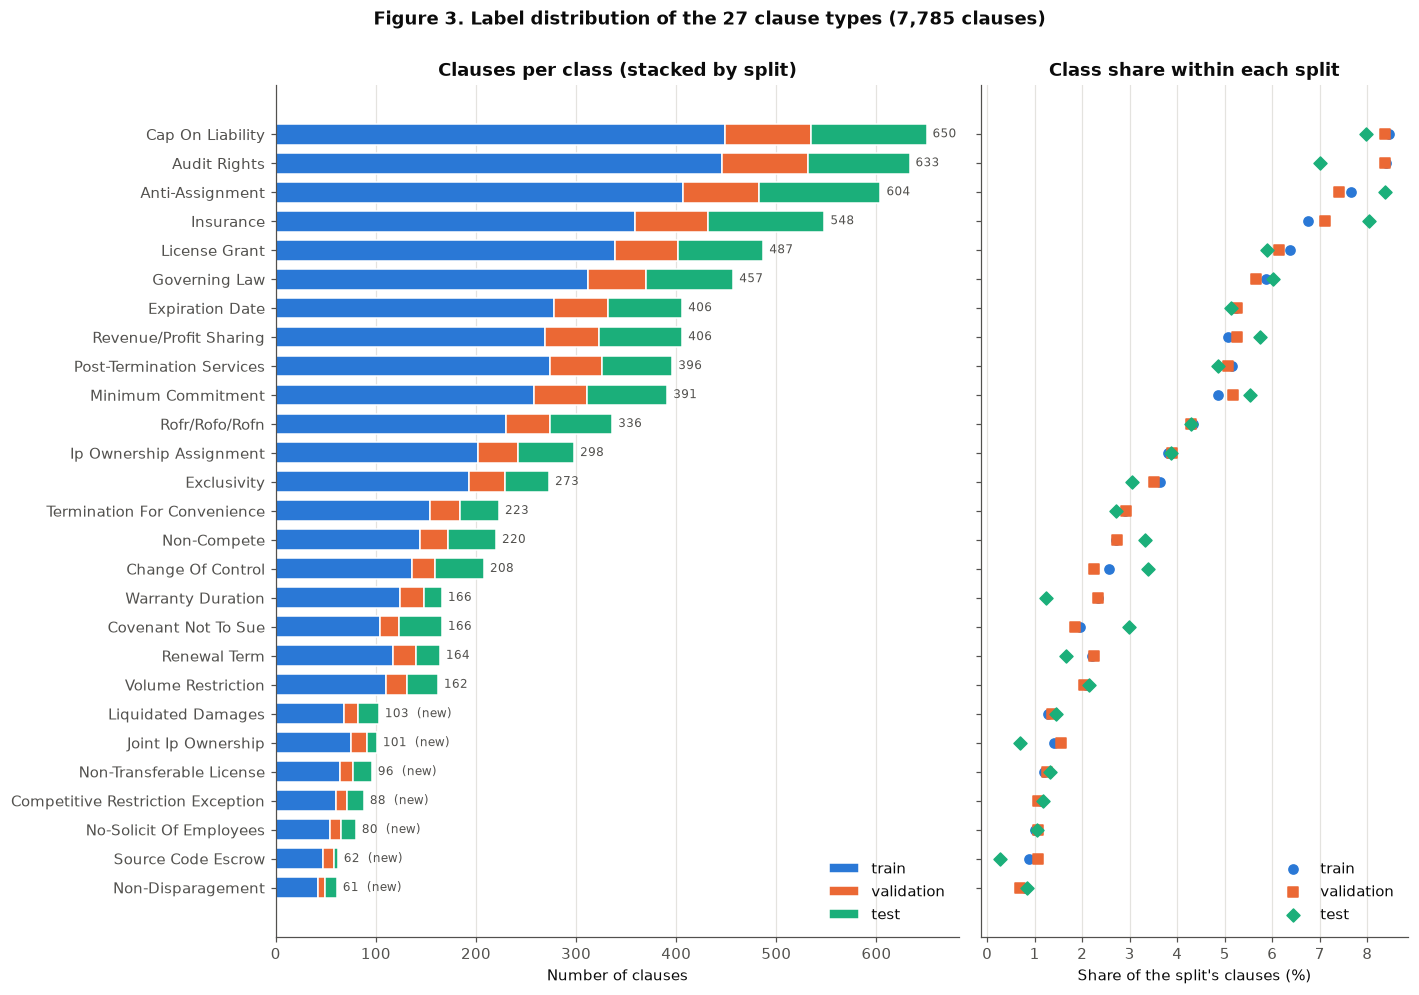

Largest class: Cap On Liability (650) | smallest: Non-Disparagement (61) | imbalance ratio 10.7:1
Classes with fewer than 15 test clauses: {'Source Code Escrow': 4, 'Joint Ip Ownership': 10, 'Non-Disparagement': 12}
Robustness set = the 24 classes with >= 15 test clauses


In [12]:
counts = df.pivot_table(index="category", columns="split", values="text", aggfunc="count")[["train", "validation", "test"]]
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total")
share = 100 * counts[["train", "validation", "test"]] / counts[["train", "validation", "test"]].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 9), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
left = np.zeros(len(counts))
for s in ["train", "validation", "test"]:
    ax1.barh(counts.index, counts[s], left=left, color=PL.SPLIT_COLORS[s], label=s, height=0.72,
             edgecolor="white", linewidth=1)
    left += counts[s].values
for y, (lab, tot) in enumerate(counts.total.items()):
    ax1.text(tot + 6, y, f"{tot}" + ("  (new)" if lab in NEW_CLASSES else ""), va="center", fontsize=8, color=PL.INK_2)
ax1.set_xlabel("Number of clauses"); ax1.set_title("Clauses per class (stacked by split)")
ax1.legend(loc="lower right"); ax1.grid(axis="y", visible=False)
for s, m in zip(["train", "validation", "test"], ["o", "s", "D"]):
    ax2.scatter(share[s], share.index, color=PL.SPLIT_COLORS[s], marker=m, s=36, label=s, zorder=3)
ax2.set_xlabel("Share of the split's clauses (%)"); ax2.set_title("Class share within each split")
ax2.legend(loc="lower right"); ax2.grid(axis="y", visible=False)
fig.suptitle(f"Figure 3. Label distribution of the {len(LABELS)} clause types ({len(df):,} clauses)",
             fontweight="bold", y=1.0)
fig.tight_layout(); PL.savefig(fig, 3, "label_distribution"); plt.show()

imbalance = counts.total.max() / counts.total.min()
print(f"Largest class: {counts.total.idxmax()} ({counts.total.max()}) | smallest: {counts.total.idxmin()} "
      f"({counts.total.min()}) | imbalance ratio {imbalance:.1f}:1")
rare = counts.test[counts.test < C.MIN_TEST_CLAUSES_ROBUST].sort_values()
print(f"Classes with fewer than {C.MIN_TEST_CLAUSES_ROBUST} test clauses: {rare.to_dict()}")
print(f"Robustness set = the {len(ROBUST)} classes with >= {C.MIN_TEST_CLAUSES_ROBUST} test clauses")

In [13]:
# Class table with counts (all numbers computed from the CSV)
class_tab = counts[["train", "validation", "test", "total"]].sort_values("total", ascending=False).astype(int)
class_tab["% of all"] = (100 * class_tab.total / class_tab.total.sum()).round(1)
class_tab["new class"] = ["yes" if c in NEW_CLASSES else "" for c in class_tab.index]
class_tab["in robustness set"] = ["yes" if c in ROBUST else "no" for c in class_tab.index]
class_tab

split,train,validation,test,total,% of all,new class,in robustness set
category,,,,,,,
Cap On Liability,449,86,115,650,8.3,,yes
Audit Rights,446,86,101,633,8.1,,yes
Anti-Assignment,407,76,121,604,7.8,,yes
Insurance,359,73,116,548,7.0,,yes
License Grant,339,63,85,487,6.3,,yes
Governing Law,312,58,87,457,5.9,,yes
Expiration Date,278,54,74,406,5.2,,yes
Revenue/Profit Sharing,269,54,83,406,5.2,,yes
Post-Termination Services,274,52,70,396,5.1,,yes


**Pre-declared metrics (fixed here, before any model is trained):**
* **Primary metric: macro-F1 over all 27 classes.** Every class counts equally, including the rare ones.
* **Robustness number: macro-F1 over the classes with at least 15 test clauses** (the robustness set above). A class
  with 4–12 test clauses can move its F1 by a large step with a single clause, so this second number shows whether a
  conclusion depends on those few clauses.
* **Per-class F1 with 95 % contract-level bootstrap confidence intervals** for every class, so the uncertainty of the
  rare classes is visible.
* **How the bootstrap treats rare classes.** Each resample draws whole contracts with replacement, so a rare class
  (e.g. Source Code Escrow, whose 4 test clauses all come from one contract) is often missing from a resample; in each
  resample macro-F1 is therefore averaged over the classes present in that resample's true labels, while the point
  estimate is always over all 27 classes. For a per-class CI, resamples without that class are skipped, and a class whose
  clauses all come from one contract gets no CI ("not estimable").
* **The class set is never changed after seeing results.** No class is dropped, merged or re-weighted in the
  evaluation because it scores badly; the robustness set is fixed by test-set *counts* only, which are known before
  any model is run.

**Interpretation.** The classes are strongly imbalanced: **10.7 : 1** between Cap On Liability (650 clauses) and
Non-Disparagement (61). Three classes have fewer than 15 test clauses — **Source Code Escrow (4), Joint Ip Ownership (10)
and Non-Disparagement (12)** — so a single clause changes their test F1 by a large step; their confidence intervals will
be wide and the robustness macro-F1 over the other 24 classes is reported next to the primary metric. The validation
split mirrors the training distribution closely (it is stratified); the test split is fixed by CUAD's official contract
list and differs more, a realistic distribution shift that macro-F1 is not sensitive to (each class counts once, however
many test clauses it has).

### 2.9 Clause length

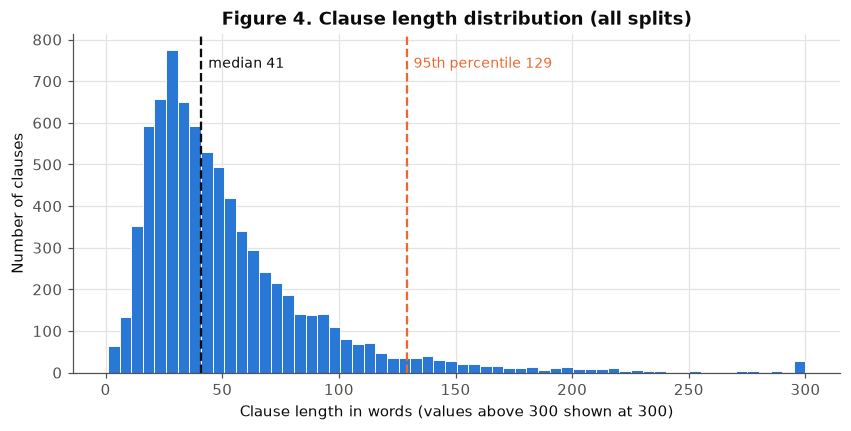

words per clause: median 41, 95th percentile 129, max 479, share <= 128 words: 94.9 %


category,Termination For Convenience,Governing Law,Expiration Date,Anti-Assignment,Non-Disparagement,Volume Restriction,Non-Transferable License,Insurance,Source Code Escrow,Exclusivity,...,Covenant Not To Sue,Change Of Control,Cap On Liability,License Grant,Liquidated Damages,Ip Ownership Assignment,Competitive Restriction Exception,Rofr/Rofo/Rofn,Post-Termination Services,No-Solicit Of Employees
median words,27.0,29.0,30.0,34.0,35.0,36.0,37.0,37.0,37.0,40.0,...,47.5,48.5,49.0,50.0,51.0,51.0,51.0,52.0,55.0,55.5


In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df.n_words.clip(upper=300), bins=60, color=PL.BLUE, edgecolor="white", linewidth=0.6)
med, p95, mx = df.n_words.median(), df.n_words.quantile(0.95), df.n_words.max()
for v, lab, col in [(med, f"median {med:.0f}", PL.INK), (p95, f"95th percentile {p95:.0f}", PL.ORANGE)]:
    ax.axvline(v, color=col, linestyle="--", linewidth=1.5)
    ax.text(v + 3, ax.get_ylim()[1] * 0.9, lab, color=col, fontsize=9)
ax.set_xlabel("Clause length in words (values above 300 shown at 300)"); ax.set_ylabel("Number of clauses")
ax.set_title("Figure 4. Clause length distribution (all splits)")
PL.savefig(fig, 4, "clause_length_words"); plt.show()
print(f"words per clause: median {med:.0f}, 95th percentile {p95:.0f}, max {mx}, "
      f"share <= 128 words: {100 * (df.n_words <= 128).mean():.1f} %")
display(df.groupby("category").n_words.median().sort_values().rename("median words").to_frame().T)

**Interpretation.** Clauses are short: the median is 41 words, 95 % have ≤ 129 words and 94.9 % have ≤ 128, against a
median of about 5,000 words for a whole contract (section 2.4). A whole clause therefore fits in a transformer's input
window (section 3.5 measures the tokens), and the texts are short enough that TF-IDF vectors are sparse. Length differs by
class — Termination For Convenience, Governing Law and Expiration Date have medians of 27–30 words, Post-Termination
Services and No-Solicit Of Employees about 55 — so length alone is weak evidence of the type, and long clauses are a
natural subgroup for the error analysis.

### 2.10 Example clauses (two per class)
Two training clauses per class — the two whose length is closest to the class median — so the reader can see what the
labels mean in practice (shortened to 200 characters).

In [15]:
pd.set_option("display.max_colwidth", 210)
ex = (train.assign(gap=lambda d: (d.n_words - d.groupby("category").n_words.transform("median")).abs())
           .sort_values(["category", "gap", "row_id"]).groupby("category").head(2))
ex[["category", "n_words", "text"]].assign(text=lambda d: d.text.str.slice(0, 200)).reset_index(drop=True)

,category,n_words,text
0,Anti-Assignment,34,"Investor will not assign to any Third Party any rights under this IP Agreement not specifically transferable by its terms without the prior written consent of Company, such consent not to be unreasona"
1,Anti-Assignment,34,Neither Newegg nor Allied shall have the right or power to assign or transfer any part of its rights or obligations under this Agreement without the prior consent in writing of the other Party
2,Audit Rights,40,Accurate and complete books of account of the transactions of the Venture will be kept in accordance with generally accepted accounting principles (GAAP) and at all reasonable times will be available
3,Audit Rights,40,NICE agrees to conduct the audits in a reasonable manner so as not to cause undue disruption to Contractor's provision of the Manufacturing Outsourcing Services and such audits shall be conducted duri
4,Cap On Liability,49,"FOR CLARITY AND NOTWITHSTANDING THE PROVISIONS OF THE FIRST SENTENCE OF THIS SECTION 13.5, ROYALTIES AND MILESTONES PAYABLE TO CYTODYN IN CONNECTION WITH VYERA'S COMMERCIALIZATION OF LICENSED PRODUCTS"
5,Cap On Liability,49,"EXCEPT IN CONNECTION WITH A BREACH BY EITHER PARTY OF ARTICLE 13, THE INDEMNIFICATION OBLIGATIONS OF NEOFORMA UNDER SECTION 15.4(c) [INDEMNIFICATION BY NEOFORMA] AND (d) AND THE INDEMNIFICATION OBLIGA"
6,Change Of Control,49,"Skunkware further agrees that, so long as the Option shall be in existence (whether or not exercisable), it shall be and remain the sole Stockholder Licensor, and Licensor shall not issue to any other"
7,Change Of Control,50,"For the avoidance of doubt, a merger, change of control, reorganization or sale of all or substantially all of the stock of Licensee shall be deemed an ""assignment"" requiring the above consent, regard"
8,Competitive Restriction Exception,51,The parties expressly agree that CONSULTANT may permit [*****] the use of CONSULTANT'S name and/or likeness in [*****] print and/or television advertisement provided that this is executed in a manner
9,Competitive Restriction Exception,51,"For purposes of clarity, the foregoing does not prevent Conformis from granting any license, release, covenant not to sue or other immunity to any third party under any Patents, including any such imm"


## 3. Preprocessing

### 3.1 Approach: preprocessing as an experiment
Each candidate step is treated as a **hypothesis about the data** and tested on the 27-class data, not applied by habit
and not carried over from the first design.

* **Fixed test bench:** default TF-IDF features + `LinearSVC(C=1)`; trained on *train*, scored on **validation**
  (macro-F1 over all classes). The test set is never used. The classifier is deliberately left untuned so that
  differences come from the preprocessing alone (the classifiers are tuned in section 4).
* **Order (greedy, forward):** steps are tried one at a time — characters → case → cross-references → numbers →
  symbols → stop words → word forms → n-grams. Each candidate is compared with the pipeline built so far.
* **Decision rule, fixed before running:** small differences on one validation set are noise. An option is
  **adopted if it improves validation macro-F1 by ≥ 0.003**. If no option clears that bar, the options within ±0.003
  are treated as equivalent and the one with the **smallest vocabulary** (the simpler model) is kept. Options worse by
  more than 0.003 are rejected.
* **Uncertainty:** every change gets a 95 % confidence interval from a *contract-level paired bootstrap* on
  validation (1,000 resamples of the validation contracts; macro-F1 in each resample over the classes present in it,
  see 2.8), so the reader can see which effects are real.

| Step | Hypothesis | Options |
|---|---|---|
| 1 Unicode | typographic characters (curly quotes, bullets, zero-width spaces) split identical words | off / on |
| 2 Lower-casing | "Licensee" and "licensee" should be one feature — but ALL-CAPS text may itself signal certain clauses (e.g. liability caps) | off / on |
| 3 Cross-references | "Section 12.3(b)" numbers are contract-specific noise; the *presence* of a reference may matter | keep / replace with `secref` |
| 4 Numbers | exact values ("30", "5,000,000") are rare features; the presence of a number matters (durations, caps) | keep / replace with `num` |
| 5 Symbols | "$" and "%" signal money and percentages but are deleted by the default tokenizer | drop / keep as words |
| 6 Stop words | function words add noise — but "not", "no", "until", "without", "only", "may" carry legal meaning | none / full NLTK list / NLTK minus legal words |
| 7 Word forms | merging "terminate/terminates/termination" pools evidence | none / Porter stemming / WordNet lemmatisation |
| 8 N-grams | word pairs ("governing law", "change of control") are more specific than single words | 1 / 1–2 / 1–3 |

### 3.2 What each step does to a real clause (before → after)
For each step we show one training clause that the step changes, with the step switched off (before) and on (after).

In [16]:
DEMO_STEPS = [("unicode", True), ("lowercase", True), ("section_refs", True), ("numbers", True),
              ("symbols", True), ("stopwords", "nltk_legal"), ("stem", "porter"), ("stem", "lemma")]
base = dict(P.BASELINE_CONFIG)
short = train[train.n_words.between(15, 45)].sort_values("row_id")
for key, value in DEMO_STEPS:
    on = {**base, key: value}
    for text in short.text:
        before, after = P.tokenize(text, base), P.tokenize(text, on)
        if before != after:
            break
    print(f"--- step: {key} = {value}")
    print("  text  :", text[:200])
    print("  before:", " ".join(before)[:200])
    print("  after :", " ".join(after)[:200], "\n")

--- step: unicode = True
  text  : Improvements that (i) relate specifically to BII Confidential Information and Know-How, and (ii) do not relate to XENCOR Confidential Information and Know­How (collectively, "BII Intellectual Property
  before: Improvements that relate specifically to BII Confidential Information and Know How and ii do not relate to XENCOR Confidential Information and Know How collectively BII Intellectual Property will be e
  after : Improvements that relate specifically to BII Confidential Information and Know How and ii do not relate to XENCOR Confidential Information and KnowHow collectively BII Intellectual Property will be ex 

--- step: lowercase = True
  text  : The term of this Agreement shall be ten (10) years (the "Term") which shall commence on the date upon which the Company delivers to Distributor the last Sample, as defined hereinafter.
  before: The term of this Agreement shall be ten 10 years the Term which shall commence on the date upon which the Co

--- step: stem = lemma
  text  : The term of this Agreement shall be ten (10) years (the "Term") which shall commence on the date upon which the Company delivers to Distributor the last Sample, as defined hereinafter.
  before: The term of this Agreement shall be ten 10 years the Term which shall commence on the date upon which the Company delivers to Distributor the last Sample as defined hereinafter
  after : The term of this Agreement shall be ten 10 year the Term which shall commence on the date upon which the Company delivers to Distributor the last Sample a defined hereinafter 



### 3.3 The preprocessing study (validation set only)

In [17]:
def run_config(cfg):
    """Fit TF-IDF + LinearSVC(C=1) on train with preprocessing `cfg`; return validation predictions and stats."""
    vec = P.make_vectorizer(cfg)
    Xtr = vec.fit_transform(train.text)
    clf = LinearSVC(C=1.0, random_state=42).fit(Xtr, train.category)
    pred = clf.predict(vec.transform(val.text))
    n_tok = np.mean([len(P.tokenize(t, cfg)) for t in train.text])
    return pred, Xtr.shape[1], n_tok

def macro(pred):
    return f1_score(val.category, pred, labels=LABELS, average="macro", zero_division=0)

STUDY = [  # (step, config key, options in the order they are tried; the first option = "off")
    ("1 Unicode normalisation", "unicode", [False, True]),
    ("2 Lower-casing", "lowercase", [False, True]),
    ("3 Cross-references -> secref", "section_refs", [False, True]),
    ("4 Numbers -> num", "numbers", [False, True]),
    ("5 Keep $ and % as words", "symbols", [False, True]),
    ("6 Stop-word removal", "stopwords", ["none", "nltk", "nltk_legal"]),
    ("7 Stemming / lemmatisation", "stem", ["none", "porter", "lemma"]),
    ("8 N-gram range (max n)", "ngram_max", [1, 2, 3]),
]
TOL = 0.003
print(f"Validation set: {len(val):,} clauses from {val.contract.nunique()} contracts")

with C.timer("preprocessing_study", "greedy_forward_selection", notes="TF-IDF + LinearSVC(C=1), validation only"):
    current = dict(P.BASELINE_CONFIG)
    cur_pred, cur_vocab, cur_tok = run_config(current)
    records = [{"step": "0 Baseline", "option": "raw text, default tokenizer", "macro_f1": macro(cur_pred),
                "delta": 0.0, "ci_low": 0.0, "ci_high": 0.0, "vocab": cur_vocab, "mean_tokens": cur_tok,
                "decision": "baseline", "config": json.dumps(current)}]
    for step, key, options in STUDY:
        cands = []
        for opt in options:
            cfg = {**current, key: opt}
            if opt == current[key]:
                pred, vocab, tok = cur_pred, cur_vocab, cur_tok
            else:
                pred, vocab, tok = run_config(cfg)
            pb = C.paired_bootstrap(val.category, pred, cur_pred, val.contract, labels=LABELS, n_boot=1000)
            cands.append(dict(step=step, option=str(opt), opt=opt, cfg=cfg, pred=pred, macro_f1=macro(pred),
                              delta=pb["diff"], ci_low=pb["ci_low"], ci_high=pb["ci_high"], vocab=vocab,
                              mean_tokens=tok, is_current=(opt == current[key])))
        # --- the pre-declared decision rule ---
        best = max(cands, key=lambda c: c["delta"])
        if best["delta"] >= TOL:
            chosen, why = best, f"adopted: +{best['delta']:.3f} >= {TOL}"
        else:
            ties = [c for c in cands if abs(c["delta"]) < TOL]
            chosen = min(ties, key=lambda c: c["vocab"])
            why = ("no option better by >= 0.003; kept the smallest vocabulary among equivalent options")
        for c in cands:
            if c["is_current"] and c is not chosen:
                dec = "replaced"
            elif c is chosen:
                dec = "KEPT (" + why + ")"
            elif c["delta"] <= -TOL:
                dec = f"rejected: {c['delta']:+.3f}"
            else:
                dec = "not chosen (equivalent)"
            records.append({k: c[k] for k in ["step", "option", "macro_f1", "delta", "ci_low", "ci_high", "vocab",
                                              "mean_tokens"]} | {"decision": dec, "config": json.dumps(c["cfg"])})
        current, cur_pred, cur_vocab, cur_tok = chosen["cfg"], chosen["pred"], chosen["vocab"], chosen["mean_tokens"]

study = pd.DataFrame(records)
study.to_csv(C.RESULTS_DIR / "preprocessing_study.csv", index=False)
SELECTED_CONFIG = current
pd.set_option("display.max_colwidth", 90)
study.drop(columns="config").round(4)

Validation set: 1,026 clauses from 65 contracts


[timer] preprocessing_study / greedy_forward_selection: 93.1 s


,step,option,macro_f1,delta,ci_low,ci_high,vocab,mean_tokens,decision
0,0 Baseline,"raw text, default tokenizer",0.7572,0.0000,0.0000,0.0000,9419,51.2907,baseline
1,1 Unicode normalisation,False,0.7572,0.0000,0.0000,0.0000,9419,51.2907,KEPT (no option better by >= 0.003; kept the smallest vocabulary among equivalent opti...
2,1 Unicode normalisation,True,0.7590,0.0018,0.0000,0.0035,9423,51.2897,not chosen (equivalent)
3,2 Lower-casing,False,0.7572,0.0000,0.0000,0.0000,9419,51.2907,KEPT (no option better by >= 0.003; kept the smallest vocabulary among equivalent opti...
4,2 Lower-casing,True,0.7539,-0.0033,-0.0332,0.0204,7005,51.2907,rejected: -0.003
5,3 Cross-references -> secref,False,0.7572,0.0000,0.0000,0.0000,9419,51.2907,replaced
6,3 Cross-references -> secref,True,0.7570,-0.0002,-0.0100,0.0086,9396,51.1857,KEPT (no option better by >= 0.003; kept the smallest vocabulary among equivalent opti...
7,4 Numbers -> num,False,0.7570,0.0000,0.0000,0.0000,9396,51.1857,KEPT (no option better by >= 0.003; kept the smallest vocabulary among equivalent opti...
8,4 Numbers -> num,True,0.7531,-0.0038,-0.0125,0.0065,9122,51.4111,rejected: -0.004
9,5 Keep $ and % as words,False,0.7570,0.0000,0.0000,0.0000,9396,51.1857,KEPT (no option better by >= 0.003; kept the smallest vocabulary among equivalent opti...


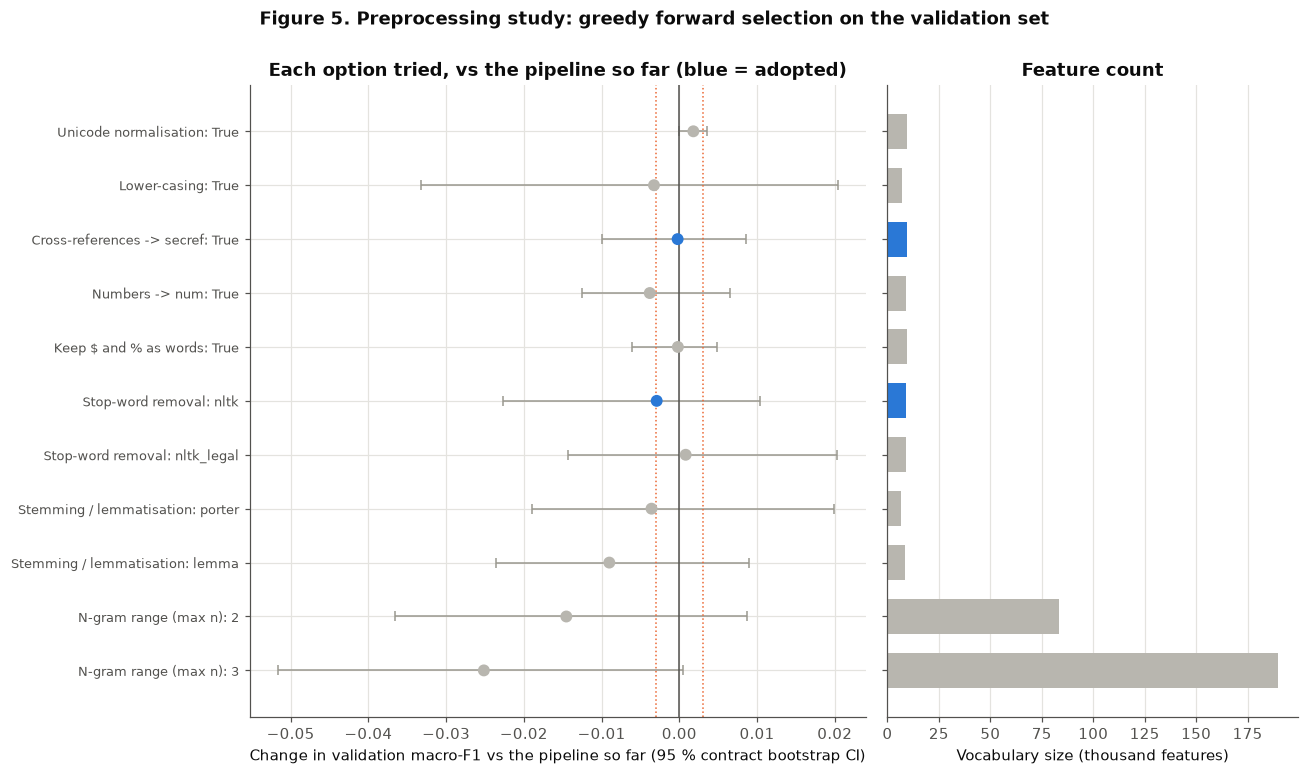

In [18]:
plot = study[(study.step != "0 Baseline") & ~study.decision.isin(["replaced"])].copy()
plot = plot[~((plot.delta == 0) & (plot.ci_low == 0) & (plot.ci_high == 0))]   # the reference itself (change = 0 by definition)
plot["label"] = plot.step.str.replace(r"^\d ", "", regex=True) + ": " + plot.option
plot["kept"] = plot.decision.str.startswith("KEPT")
plot = plot.iloc[::-1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 7), sharey=True, gridspec_kw={"width_ratios": [1.5, 1]})
y = np.arange(len(plot))
colors = [PL.BLUE if k else "#b8b6af" for k in plot.kept]
ax1.errorbar(plot.delta, y, xerr=[plot.delta - plot.ci_low, plot.ci_high - plot.delta], fmt="none",
             ecolor="#9a988f", capsize=3, linewidth=1)
ax1.scatter(plot.delta, y, c=colors, s=46, zorder=3)
ax1.axvline(0, color=PL.INK_2, linewidth=1)
for x in (-TOL, TOL):
    ax1.axvline(x, color=PL.ORANGE, linewidth=1, linestyle=":")
ax1.set_yticks(y); ax1.set_yticklabels(plot.label, fontsize=8.5)
ax1.set_xlabel("Change in validation macro-F1 vs the pipeline so far (95 % contract bootstrap CI)")
ax1.set_title("Each option tried, vs the pipeline so far (blue = adopted)")
ax2.barh(y, plot.vocab / 1000, color=colors, height=0.65)
ax2.set_xlabel("Vocabulary size (thousand features)"); ax2.set_title("Feature count")
ax2.grid(axis="y", visible=False)
fig.suptitle("Figure 5. Preprocessing study: greedy forward selection on the validation set", fontweight="bold", y=1.0)
fig.tight_layout(); PL.savefig(fig, 5, "preprocessing_study"); plt.show()

In [19]:
# Final pipeline vs the raw baseline, and consistency with src/preprocess.py
base_pred, base_vocab, base_tok = run_config(P.BASELINE_CONFIG)
fin_pred, fin_vocab, fin_tok = run_config(SELECTED_CONFIG)
pb = C.paired_bootstrap(val.category, fin_pred, base_pred, val.contract, labels=LABELS, n_boot=1000)
print("Selected configuration:", SELECTED_CONFIG)
print(f"Validation macro-F1: baseline {macro(base_pred):.4f} -> selected pipeline {macro(fin_pred):.4f} "
      f"(diff {pb['diff']:+.4f}, 95 % CI [{pb['ci_low']:+.4f}, {pb['ci_high']:+.4f}])")
print(f"Vocabulary: {base_vocab:,} -> {fin_vocab:,} features | mean tokens per clause: {base_tok:.1f} -> {fin_tok:.1f}")
json.dump({"selected_config": SELECTED_CONFIG, "baseline_val_macro_f1": macro(base_pred),
           "selected_val_macro_f1": macro(fin_pred), "paired_bootstrap": pb,
           "vocab_baseline": base_vocab, "vocab_selected": fin_vocab},
          open(C.RESULTS_DIR / "preprocessing_selected.json", "w"), indent=2)
assert P.FINAL_CLASSICAL_CONFIG == SELECTED_CONFIG, "src/preprocess.py FINAL_CLASSICAL_CONFIG is out of date"
print("OK: src/preprocess.py FINAL_CLASSICAL_CONFIG matches the configuration selected by the study.")

Selected configuration: {'unicode': False, 'lowercase': False, 'section_refs': True, 'numbers': False, 'symbols': False, 'stopwords': 'nltk', 'stem': 'none', 'ngram_max': 1}
Validation macro-F1: baseline 0.7572 -> selected pipeline 0.7540 (diff -0.0031, 95 % CI [-0.0239, +0.0114])
Vocabulary: 9,419 -> 9,149 features | mean tokens per clause: 51.3 -> 29.0
OK: src/preprocess.py FINAL_CLASSICAL_CONFIG matches the configuration selected by the study.


**Interpretation (all numbers from `results/preprocessing_study.csv`).**

* **No preprocessing step reliably helps on the 27-class data.** The raw-text baseline scores **0.757** validation
  macro-F1. No option improved it by the pre-declared +0.003; the largest gain was Unicode normalisation (+0.0018,
  4 extra features), and every option's 95 % CI includes zero.
* **Lower-casing (−0.003), numbers → `num` (−0.004), Porter stemming (−0.004) and lemmatisation (−0.009) were rejected.**
  Merging word forms or numbers throws away distinctions the linear model can use (e.g. "Term" as a defined term versus
  "term", "30 days" versus "num days").
* **Stop words:** the full NLTK list scored −0.003 (CI −0.023 to +0.010) and the legal-aware list +0.001; both are inside
  the noise band, so the pre-declared tie-break kept the **smallest vocabulary** — full stop-word removal. This choice was
  made by the rule, not by evidence that stop words hurt or help.
* **Word pairs:** after stop-word removal, 1–2-grams (−0.015) and 1–3-grams (−0.025) were clearly worse than single words
  on this untuned bench.
* **Overall:** the selected pipeline (`secref` for cross-references, full stop-word removal, single words) scores 0.754 —
  **−0.003 against raw text, CI [−0.024, +0.011]**. The honest conclusion is that, for a linear TF-IDF model on these
  clauses, the text-level choices tested here make no measurable difference; the gains must come from the
  representation and the classifier settings (section 4).
* **Several findings of the first-version (20-class) dry run did not replicate** (that run favoured lower-casing and word
  pairs and found stop-word removal clearly harmful). The class set changed, and with it the evidence — which is why every
  choice was re-tested on the v2 validation set instead of being carried over.
* **Path dependence and the follow-up.** A greedy study decides each step given the earlier ones, with an untuned
  classifier, so a near-tie early on (stop words) can change later results (n-grams). The tuned grid in section 4 therefore
  re-tests the stop-word decision as a grid dimension. **This re-test was decided after the study and before any tuning,
  and it uses the validation set only** (no test data was involved in this or any other choice). There, keeping stop words is better for every
  word-level model (best LinearSVC 0.783 vs 0.775, Logistic Regression 0.779 vs 0.771, Complement NB 0.712 vs 0.683), and
  character n-grams — which do not depend on the stop-word step — give the best linear models.

### 3.4 Before → after on five sample clauses (final classical pipeline)
This is the view used in the demo video: the raw clause, the cleaned text, and the tokens the TF-IDF model sees.

In [20]:
samples = (train[train.n_words.between(20, 60)]
           .groupby("category").head(1).sort_values("row_id")
           .loc[lambda d: d.category.isin(["Cap On Liability", "Renewal Term", "Liquidated Damages",
                                           "Non-Transferable License", "Anti-Assignment"])])
for _, r in samples.iterrows():
    toks = P.tokenize(r.text, P.FINAL_CLASSICAL_CONFIG)
    print(f"[{r.category}]  ({r.n_words} words -> {len(toks)} tokens)")
    print("  BEFORE :", r.text[:260])
    print("  CLEANED:", P.clean_text(r.text, P.FINAL_CLASSICAL_CONFIG)[:260])
    print("  TOKENS :", toks[:30], "\n")

[Renewal Term]  (42 words -> 21 tokens)
  BEFORE : If Distributor complies with all of the terms of this Agreement, the Agreement shall be renewable on an annual basis for one (1) year terms for up to another ten (10) years on the same terms and conditions as set forth herein.
  CLEANED: If Distributor complies with all of the terms of this Agreement, the Agreement shall be renewable on an annual basis for one (1) year terms for up to another ten (10) years on the same terms and conditions as set forth herein.
  TOKENS : ['Distributor', 'complies', 'terms', 'Agreement', 'Agreement', 'shall', 'renewable', 'annual', 'basis', 'one', 'year', 'terms', 'another', 'ten', '10', 'years', 'terms', 'conditions', 'set', 'forth', 'herein'] 

[Anti-Assignment]  (36 words -> 19 tokens)
  BEFORE : No assignment of this Agreement or any right accruing hereunder shall be made by the Distributor in whole or in part, without the prior written consent of the Company, which consent shall not be unreasonably

### 3.5 Preprocessing for the transformer (Legal-BERT) — deliberately light
A fine-tuned transformer needs very different input from a bag-of-words model:
* **No stop-word removal, no stemming:** the model reads words *in context*; "shall **not** assign" and
  "shall assign" must stay different, and its attention needs the full sentence.
* **Casing follows the checkpoint:** `nlpaueb/legal-bert-base-uncased` (and the ablation model `bert-base-uncased`)
  are *uncased* — their tokenizer lower-cases internally. We pass the text as it is.
* **Subword tokenizer instead of our word tokenizer:** rare words are split into known pieces, so there is no
  out-of-vocabulary problem and no need for number or cross-reference placeholders.
* We only apply **Unicode normalisation** (`P.preprocess_for_transformer`) so that typographic characters do not
  become unknown tokens.
* **Maximum sequence length** is chosen from the *training* clauses' token lengths: the larger of the two
  tokenizers' 99th percentiles, rounded up to a multiple of 32, so that the Legal-BERT model and the BERT-base
  ablation model use the **same** `max_length` and almost no clause is truncated by either.

In [21]:
from transformers import AutoTokenizer
TOK_NAMES = {"Legal-BERT": "nlpaueb/legal-bert-base-uncased", "BERT-base": "bert-base-uncased"}
toks = {k: AutoTokenizer.from_pretrained(v) for k, v in TOK_NAMES.items()}
texts = df.text.map(P.preprocess_for_transformer)
for k, t in toks.items():
    df[f"tok_{k}"] = [len(ids) for ids in t(list(texts), add_special_tokens=True)["input_ids"]]

trn = df[df.split == "train"]
p99 = max(trn["tok_Legal-BERT"].quantile(0.99), trn["tok_BERT-base"].quantile(0.99))   # the longer of the two
MAX_LEN = int(min(512, np.ceil(p99 / 32) * 32))          # round up to a multiple of 32; same value for both models
tok_stats = {k: {"median": float(trn[f"tok_{k}"].median()), "p95": float(trn[f"tok_{k}"].quantile(.95)),
                 "p99": float(trn[f"tok_{k}"].quantile(.99)), "max": int(df[f"tok_{k}"].max()),
                 "mean": float(df[f"tok_{k}"].mean()),
                 "truncated_at_max_len_%": {s: float(100 * (df.loc[df.split == s, f"tok_{k}"] > MAX_LEN).mean())
                                            for s in ["train", "validation", "test"]}}
             for k in toks}
ratio = df["tok_BERT-base"].sum() / df["tok_Legal-BERT"].sum()
json.dump({"max_len": MAX_LEN, "chosen_from": "max of the 99th percentiles of the train token lengths under both tokenizers, rounded up to x32",
           "stats": tok_stats, "bert_to_legalbert_token_ratio": ratio},
          open(C.RESULTS_DIR / "token_lengths.json", "w"), indent=2)
display(pd.DataFrame({k: {**{m: v for m, v in s.items() if m != "truncated_at_max_len_%"},
                          **{f"truncated {sp} %": v for sp, v in s["truncated_at_max_len_%"].items()}}
                      for k, s in tok_stats.items()}).round(2))
print(f"Chosen max_length = {MAX_LEN} tokens.  BERT-base needs {100 * (ratio - 1):.1f} % more tokens than "
      "Legal-BERT for the same clauses (its vocabulary was not built from legal text).")

,Legal-BERT,BERT-base
median,53.00,54.00
p95,174.00,177.00
p99,311.86,314.44
max,1180.00,1171.00
mean,69.28,70.59
truncated train %,0.94,0.98
truncated validation %,0.49,0.49
truncated test %,0.55,0.55


Chosen max_length = 320 tokens.  BERT-base needs 1.9 % more tokens than Legal-BERT for the same clauses (its vocabulary was not built from legal text).


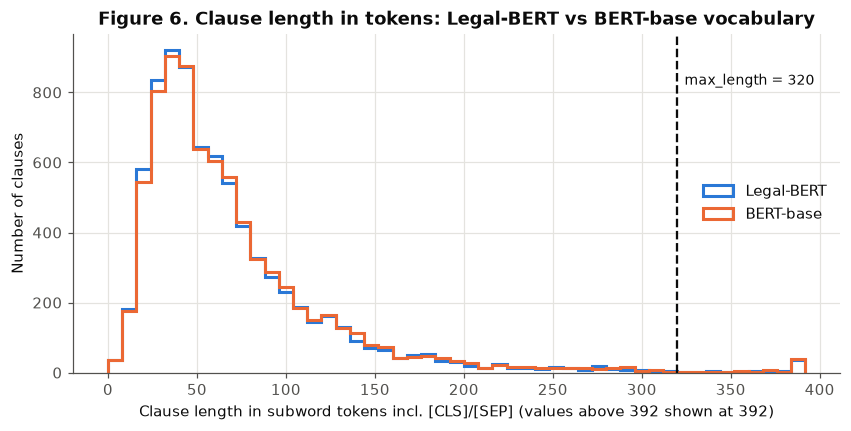

Legal-BERT: ['the', 'licensee', 'shall', 'indemnify', 'the', 'licensor', 'against', 'any', 'infringement', 'of', 'the', 'sublicense', '##d', 'trademarks', '.']
 BERT-base: ['the', 'license', '##e', 'shall', 'ind', '##em', '##ni', '##fy', 'the', 'li', '##cens', '##or', 'against', 'any', 'infringement', 'of', 'the', 'sub', '##lice', '##nsed', 'trademark', '##s', '.']


In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 400, 8)
for k, col in [("Legal-BERT", PL.BLUE), ("BERT-base", PL.ORANGE)]:
    ax.hist(df[f"tok_{k}"].clip(upper=392), bins=bins, histtype="step", linewidth=2, color=col, label=k)
ax.axvline(MAX_LEN, color=PL.INK, linestyle="--", linewidth=1.5)
ax.text(MAX_LEN + 4, ax.get_ylim()[1] * 0.85, f"max_length = {MAX_LEN}", fontsize=9)
ax.set_xlabel("Clause length in subword tokens incl. [CLS]/[SEP] (values above 392 shown at 392)")
ax.set_ylabel("Number of clauses"); ax.legend()
ax.set_title("Figure 6. Clause length in tokens: Legal-BERT vs BERT-base vocabulary")
PL.savefig(fig, 6, "clause_length_tokens"); plt.show()

example = "The Licensee shall indemnify the Licensor against any infringement of the sublicensed trademarks."
for k, t in toks.items():
    print(f"{k:>10}: {t.tokenize(example)}")

**Interpretation (`results/token_lengths.json`).** On the training clauses the 99th percentile is 312 Legal-BERT tokens and
314 BERT-base tokens; the larger, rounded up to a multiple of 32, gives `max_length` = **320** for both models; fewer than 1 % of clauses in any split are truncated (0.94 % train, 0.49 % validation, 0.55 %
test), and for those the first 320 tokens normally contain the operative wording. Padding every clause to the model
maximum of 512 would make batches much longer for almost no extra text.

The two vocabularies give nearly the same *total* token count (BERT-base needs 1.9 % more tokens for the same clauses),
but the example shows *where* they differ: Legal-BERT keeps core legal terms whole ("licensee", "indemnify", "licensor"),
while BERT-base breaks them into fragments ("license ##e", "ind ##em ##ni ##fy", "li ##cens ##or"). This matters for the
controlled ablation (Legal-BERT vs BERT-base): the two models differ in their pre-training **corpus and** their
**vocabulary**, and the ablation cannot separate the two effects.

### 3.6 Input preparation for Task 2 (clause extraction) — full contracts, offsets untouched
Task 2 works on **whole contracts**, and its labels are **character offsets** into the original contract text. Two
consequences, measured below:
* **No text normalisation that changes characters.** Even Unicode normalisation or whitespace collapsing would shift
  every later offset and misplace the gold spans. The tokenizer's offset mapping (each word-piece knows its character
  range) is used instead, so labels stay exact.
* **Sliding windows.** A contract is far longer than the 512-token limit, so it is cut into overlapping windows of
  about 256 word-pieces with a stride of about 128; predictions from overlapping windows are averaged. The cell
  counts how many windows that produces. The full Task 2 data preparation (token labels, oracle check) is in
  `202609212_Task2.ipynb`.

In [23]:
texts_full = {t: C.load_contract_text(t) for t in csplit.contract}
n_chars = pd.Series({t: len(x) for t, x in texts_full.items()})
assert (n_chars.reindex(csplit.contract).values == csplit.n_chars.values).all()
import unicodedata
changed_nfkc = sum(len(unicodedata.normalize("NFKC", x)) != len(x) for x in texts_full.values())
changed_ws = sum(len(re.sub(r"\s+", " ", x)) != len(x) for x in texts_full.values())
lb = toks["Legal-BERT"]
n_tokens = pd.Series({t: len(lb(x, add_special_tokens=False)["input_ids"]) for t, x in texts_full.items()})
WIN, STRIDE = 256, 128
n_windows = np.maximum(1, np.ceil((n_tokens - WIN) / STRIDE).clip(lower=0) + 1)
t2prep = {"contracts": int(len(n_chars)), "chars_median": float(n_chars.median()), "chars_p95": float(n_chars.quantile(.95)),
          "chars_max": int(n_chars.max()), "legalbert_tokens_median": float(n_tokens.median()),
          "legalbert_tokens_max": int(n_tokens.max()), "windows_total": int(n_windows.sum()),
          "contracts_where_NFKC_changes_length": int(changed_nfkc),
          "contracts_where_whitespace_collapse_changes_length": int(changed_ws), "window": WIN, "stride": STRIDE}
json.dump(t2prep, open(C.RESULTS_DIR / "task2_input_stats.json", "w"), indent=2)
display(pd.Series(t2prep).to_frame("value"))

,value
contracts,510.00
chars_median,33143.00
chars_p95,162491.15
chars_max,338211.00
legalbert_tokens_median,6641.50
legalbert_tokens_max,78958.00
windows_total,42168.00
contracts_where_NFKC_changes_length,39.00
contracts_where_whitespace_collapse_changes_length,505.00
window,256.00


**Interpretation (`results/task2_input_stats.json`).** Contracts have a median of 33,143 characters (95th percentile
162,491, maximum 338,211), i.e. a median of about 6,600 Legal-BERT tokens and up to 78,958 — up to about 150 times the
512-token limit, so sliding windows are unavoidable. With 256-token windows and a stride of 128 the 510 contracts give
**42,168 windows**. Normalising the text would break the labels: Unicode (NFKC) normalisation changes the length of 39
contracts and collapsing whitespace changes 505 of the 510, which would shift every later character offset. Task 2
therefore keeps the raw text and maps word-pieces to characters through the tokenizer's offsets (details and the oracle
check in `202609212_Task2.ipynb`).

### 3.7 The representation decisions that did matter: character n-grams and class weighting
The cleaning steps above made no measurable difference, but two **feature / weighting decisions** did. They are
measured here on the **same untuned bench** as the study (LinearSVC, C = 1, train → validation) so the comparison is
controlled: only one thing changes at a time.

* **Word tokens vs character n-grams.** Word features: the study's token configuration (section 3.3), single words.
  Character features: `char_wb` 3–6-character pieces taken inside word boundaries, from the same cleaned text. Character
  pieces match word stems and fragments ("assign" in *assignment, assigned, reassign*) without any stemming rule and are
  robust to hyphenation and typing variants in the filings — the hypothesis is that this suits short legal clauses.
* **No class weights vs `class_weight="balanced"`.** Balanced weighting gives every class the same total weight in the
  loss, so a class with 42 training clauses is not drowned by one with 449. The hypothesis: with a 10.7 : 1 imbalance,
  unweighted models under-predict the rare classes, which hurts macro-F1.

Section 4 then tunes both choices inside the full grid; this controlled 2 × 2 is the before/after evidence.

,features,class_weight,vocab,val_macro_f1,val_macro_f1_robust,delta_vs_word_unweighted,ci_low,ci_high
0,word tokens (study config),None,9149,0.7540,0.7484,0.0000,0.0000,0.0000
1,word tokens (study config),balanced,9149,0.7472,0.7404,-0.0068,-0.0218,0.0150
2,char_wb 3-6 n-grams,None,110858,0.7742,0.7654,0.0202,-0.0027,0.0463
3,char_wb 3-6 n-grams,balanced,110858,0.7867,0.7777,0.0327,0.0012,0.0660


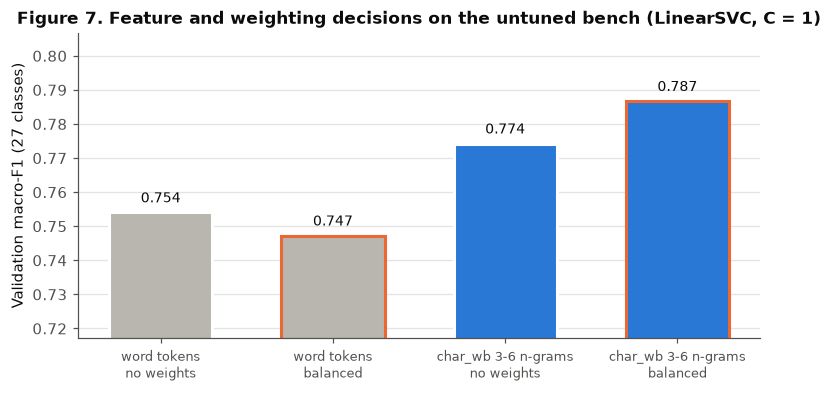

In [24]:
def bench(features, weight):
    if features == "word tokens (study config)":
        vec = P.make_vectorizer(P.FINAL_CLASSICAL_CONFIG)
    else:
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), lowercase=False,
                              preprocessor=lambda t: P.clean_text(t, P.FINAL_CLASSICAL_CONFIG))
    Xtr = vec.fit_transform(train.text)
    clf = LinearSVC(C=1.0, class_weight=weight, random_state=42).fit(Xtr, train.category)
    return clf.predict(vec.transform(val.text)), Xtr.shape[1]

feat_rows, feat_preds = [], {}
for features in ["word tokens (study config)", "char_wb 3-6 n-grams"]:
    for weight in [None, "balanced"]:
        pred, vocab = bench(features, weight)
        feat_preds[(features, weight)] = pred
        feat_rows.append({"features": features, "class_weight": str(weight), "vocab": vocab,
                          "val_macro_f1": macro(pred),
                          "val_macro_f1_robust": f1_score(val.category, pred, labels=ROBUST, average="macro", zero_division=0)})
feat = pd.DataFrame(feat_rows)
ref = feat_preds[("word tokens (study config)", None)]
for k, row in feat.iterrows():
    pb = C.paired_bootstrap(val.category, feat_preds[(row.features, None if row.class_weight == "None" else row.class_weight)],
                            ref, val.contract, labels=LABELS, n_boot=1000)
    feat.loc[k, ["delta_vs_word_unweighted", "ci_low", "ci_high"]] = [pb["diff"], pb["ci_low"], pb["ci_high"]]
feat.to_csv(C.RESULTS_DIR / "feature_decisions.csv", index=False)
display(feat.round(4))

fig, ax = plt.subplots(figsize=(8, 3.6))
lab = [f"{f.split(' (')[0]}\n{'balanced' if w == 'balanced' else 'no weights'}" for f, w in zip(feat.features, feat.class_weight)]
cols = [PL.BLUE if "char" in f else "#b8b6af" for f in feat.features]
ax.bar(range(len(feat)), feat.val_macro_f1, color=cols, width=0.6, edgecolor=[PL.ORANGE if w == "balanced" else "white" for w in feat.class_weight], linewidth=2)
for i_, v_ in enumerate(feat.val_macro_f1):
    ax.text(i_, v_ + 0.002, f"{v_:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(feat))); ax.set_xticklabels(lab, fontsize=8.5)
ax.set_ylim(feat.val_macro_f1.min() - 0.03, feat.val_macro_f1.max() + 0.02); ax.grid(axis="x", visible=False)
ax.set_ylabel("Validation macro-F1 (27 classes)")
ax.set_title("Figure 7. Feature and weighting decisions on the untuned bench (LinearSVC, C = 1)", fontsize=11)
PL.savefig(fig, 7, "feature_decisions"); plt.show()

In [25]:
# One clause shown both ways: what the word model and the character model actually see
r = train[(train.category == "Anti-Assignment") & train.n_words.between(15, 25)].sort_values("row_id").iloc[0]
cv = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 6), lowercase=False,
                     preprocessor=lambda t: P.clean_text(t, P.FINAL_CLASSICAL_CONFIG)).build_analyzer()
chars = cv(r.text)
print(f"[{r.category}] {r.text}\n")
print(f"WORD tokens ({len(P.tokenize(r.text, P.FINAL_CLASSICAL_CONFIG))}):", P.tokenize(r.text, P.FINAL_CLASSICAL_CONFIG))
print(f"\nCHARACTER n-grams ({len(chars)}), first 40:", chars[:40])

[Anti-Assignment] [ * ] may [ * ]any of its rights or obligations under this Agreement without the prior written consent of [ * ].

WORD tokens (8): ['may', 'rights', 'obligations', 'Agreement', 'without', 'prior', 'written', 'consent']

CHARACTER n-grams (237), first 40: [' [ ', ' * ', ' ] ', ' ma', 'may', 'ay ', ' may', 'may ', ' may ', ' [ ', ' * ', ' ]a', ']an', 'any', 'ny ', ' ]an', ']any', 'any ', ' ]any', ']any ', ' ]any ', ' of', 'of ', ' of ', ' it', 'its', 'ts ', ' its', 'its ', ' its ', ' ri', 'rig', 'igh', 'ght', 'hts', 'ts ', ' rig', 'righ', 'ight', 'ghts']


**Interpretation (`results/feature_decisions.csv`, Figure 7).** On the same untuned bench, the representation matters far
more than any cleaning step:
* **Character n-grams vs word tokens: +0.020** validation macro-F1 without class weights (0.774 vs 0.754, CI −0.003 to
  +0.046) and the best cell overall with balanced weights (**0.787, +0.033 over the word baseline, CI +0.001 to +0.066** —
  the only change in the whole preprocessing section whose CI excludes zero). The price is a vocabulary 12 times larger
  (110,858 character features vs 9,149 words), which the linear model handles easily.
* **Balanced class weights interact with the features:** they *lower* the word model slightly (−0.007, CI includes zero) but
  *raise* the character model (0.774 → 0.787). With the much richer character features, re-weighting lets the rare classes
  use them instead of being out-voted by the large classes.
* **The sample clause shows why:** its text is partly redacted (`[ * ]`), so the word model keeps only 8 tokens, while the
  character model still sees 237 overlapping pieces (`ight`, `ghts`, `cons`…) that carry the meaning of *rights*, *consent*
  and *assign*.
* Section 4 tunes both decisions jointly with the classifiers; the tuned grid confirms them (all ten best linear
  configurations use character n-grams or balanced weights, and the selected linear models use both).

### 3.8 Summary: one corpus, three input pipelines

| | Classical TF-IDF models (Task 1) | Transformer (Task 1: Legal-BERT / BERT) | Task 2 extractor |
|---|---|---|---|
| Function | `P.tokenize(text, P.FINAL_CLASSICAL_CONFIG)` | `P.preprocess_for_transformer` + checkpoint tokenizer | raw contract text + tokenizer offset mapping |
| Chosen by | the validation study in 3.3 (Figure 5) and 3.7 (Figure 7); tuned in section 4 | the model's pre-training (uncased WordPiece) | the need to keep exact character offsets |
| Stop words | decided by the study | never removed | never removed |
| Word forms | decided by the study | subword pieces | subword pieces |
| Input length | whole clause | max_length from the 99th percentile (Figure 6) | sliding windows over the whole contract |

All use the same corpus and the same contract-level split. The code lives in `src/preprocess.py`; the study results
are in `results/preprocessing_study.csv` and `results/preprocessing_selected.json`.

## 4. Classical baselines (Task 1)

> **Progress checkpoint (13 Nov 2026):** sections 2 and 4 hold the dataset and the Task 1 baseline results.

### 4.1 The models and why they suit this data
Our data (section 2): a few thousand **short training clauses** (median about 40 words), **27 classes** with
strong imbalance (about 11 : 1 between the largest and smallest class) and several classes with very few examples,
and TF-IDF features that are **sparse and high-dimensional** (tens of thousands of word and word-pair features —
more features than training examples — but only a few dozen non-zero per clause).

| Model | Why it fits this task | What we expect |
|---|---|---|
| **Majority class** (`DummyClassifier`, most frequent) | The floor: always predicts the largest training class. Anything useful must beat it by far. | macro-F1 close to 0 |
| **Linear SVM** (`LinearSVC`) | In very high-dimensional sparse spaces the classes are close to *linearly separable*; a max-margin linear model with L2 regularisation (parameter C) generalises well even with more features than examples, and trains in about a second. The standard strong baseline for TF-IDF text classification. `class_weight="balanced"` re-weights the loss so rare classes are not ignored. | strongest or joint-strongest |
| **Logistic Regression** (multinomial) | Also linear and L2-regularised, but it outputs **class probabilities**, useful for decision support (route low-confidence clauses to a human first, rank clauses for review). Same `class_weight` option. | similar to the SVM |
| **Complement Naive Bayes** | A generative model that is extremely fast and works with few examples per class; the *complement* variant was designed for imbalanced text classes (it estimates each class from all *other* classes' data, which is larger). Its independence assumption is clearly violated by overlapping word pairs, so it is a useful *contrasting* family. | weaker than the linear models |

All three classifiers use the preprocessing selected in section 3 (`P.FINAL_CLASSICAL_CONFIG`). The search below
varies the TF-IDF settings again (including the n-gram range); the preprocessing study only fixes *how text is
turned into tokens*.

### 4.2 Majority-class baseline

In [26]:
from sklearn.dummy import DummyClassifier

majority = DummyClassifier(strategy="most_frequent").fit(train.text, train.category)
maj_val = C.compute_metrics(val.category, majority.predict(val.text), LABELS, "majority", "validation",
                            robust_labels=ROBUST)
print(f"Majority class = '{majority.classes_[majority.class_prior_.argmax()]}' | validation macro-F1 "
      f"{maj_val['macro_f1']:.4f}, accuracy {maj_val['accuracy']:.4f}")

Majority class = 'Cap On Liability' | validation macro-F1 0.0057, accuracy 0.0838


### 4.3 Systematic hyper-parameter search (validation set only)
**Protocol.** Every combination in the grid below is trained on *train* and scored on *validation* (macro-F1 over
all 27 classes). The test set is not touched. Every configuration is recorded in `results/classical_search.csv` with
its validation macro-F1, robustness macro-F1, accuracy, number of features and fit time.

| Part | Setting | Values | Why it is searched |
|---|---|---|---|
| TF-IDF (word) | `ngram_range` | (1,1), (1,2), (1,3) | word pairs/triples capture legal phrases ("governing law") |
| | `min_df` | 1, 2, 5 | drop features seen in very few clauses (typos, names) |
| | `max_df` | 0.5, 1.0 | drop features in > 50 % of clauses (a data-driven stop-word filter) |
| | `sublinear_tf` | False, True | 1 + log(tf): a word repeated 5 times is not 5 times as informative |
| | `max_features` | all, 20,000 | cap the vocabulary (simpler, faster model) |
| TF-IDF (character) | `char_wb` n-grams | (2,5), (3,6) × `min_df` 2, 5 × `sublinear_tf` | robust to word variants and typos from the PDF conversion |
| LinearSVC | `C` | 0.03, 0.1, 0.3, 1, 3, 10, 30 | regularisation strength (small C = simpler model) |
| | `class_weight` | none, **balanced** | up-weight rare classes (27 imbalanced classes) |
| Logistic Regression | `C` | 1, 3, 10, 30, 100, 300 | regularisation strength |
| | `class_weight` | none, **balanced** | up-weight rare classes |
| Complement NB | `alpha` | 0.003, 0.01, 0.03, 0.1, 0.3, 1 | smoothing of word counts |
| | `norm` | False, True | weight normalisation (part of the complement NB method) |

**Token configuration (added after the preprocessing study, before any tuning).** The study in 3.3 decided the
stop-word step on a near-tie (−0.003, inside the ±0.003 noise band) using an *untuned* classifier, and removing stop
words changes what word pairs can capture. So the word-level grid is run twice: with the study's token configuration
(`study`) and with the identical configuration except that stop words are kept (`study_keep_stopwords`). This uses the
validation set only, like the rest of the search.

That is (72 word settings × 2 token configurations + 8 character settings) × 38 classifier settings = **5,776
trained models**, run in parallel on the CPU.
The grid edges were set wide on purpose; a cell below checks whether any selected value still sits on an edge.
**Selection rule (fixed in advance):** per model, the configuration with the highest validation macro-F1;
configurations within 0.001 of the best are treated as tied, and the one with the fewest features (then the fastest
fit) wins.

`RUN_SEARCH = False` loads the saved search; the outputs shown below are from the real search run.

In [27]:
import time, itertools
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import accuracy_score

RUN_SEARCH = False   # the real search ran once (its output is kept below); True = run all configurations again (~1 h)
SEARCH_CSV = C.RESULTS_DIR / "classical_search.csv"
TOKEN_CONFIGS = {"study": P.FINAL_CLASSICAL_CONFIG,
                 "study_keep_stopwords": {**P.FINAL_CLASSICAL_CONFIG, "stopwords": "none"}}
CFG = P.FINAL_CLASSICAL_CONFIG          # character models use the study's cleaned text

# Pre-process once: word tokens per token configuration, cleaned strings for the character models.
TOK = {name: {"train": [P.tokenize(t, c) for t in train.text], "val": [P.tokenize(t, c) for t in val.text]}
       for name, c in TOKEN_CONFIGS.items()}
TXT = {"train": [P.clean_text(t, CFG) for t in train.text], "val": [P.clean_text(t, CFG) for t in val.text]}

VEC_GRID = (
    [dict(analyzer="word", tok=tk, ngram_range=ng, min_df=mn, max_df=mx, sublinear_tf=sl, max_features=mf)
     for tk, ng, mn, mx, sl, mf in itertools.product(TOKEN_CONFIGS, [(1, 1), (1, 2), (1, 3)], [1, 2, 5], [0.5, 1.0],
                                                      [False, True], [None, 20000])]
    + [dict(analyzer="char_wb", tok="study", ngram_range=ng, min_df=mn, max_df=1.0, sublinear_tf=sl, max_features=None)
       for ng, mn, sl in itertools.product([(2, 5), (3, 6)], [2, 5], [False, True])])
GRID_VALUES = {"LinearSVC": [0.03, 0.1, 0.3, 1, 3, 10, 30], "LogisticRegression": [1, 3, 10, 30, 100, 300],
               "ComplementNB": [0.003, 0.01, 0.03, 0.1, 0.3, 1]}
CLF_GRID = (
    [("LinearSVC", dict(C=c, class_weight=w)) for c in GRID_VALUES["LinearSVC"] for w in [None, "balanced"]]
    + [("LogisticRegression", dict(C=c, class_weight=w)) for c in GRID_VALUES["LogisticRegression"]
       for w in [None, "balanced"]]
    + [("ComplementNB", dict(alpha=a, norm=n)) for a in GRID_VALUES["ComplementNB"] for n in [False, True]])

def identity(x):
    return x

def make_tfidf(v):
    if v["analyzer"] == "word":     # input = our token lists
        return TfidfVectorizer(tokenizer=identity, preprocessor=identity, lowercase=False, token_pattern=None,
                               ngram_range=v["ngram_range"], min_df=v["min_df"], max_df=v["max_df"],
                               sublinear_tf=v["sublinear_tf"], max_features=v["max_features"])
    return TfidfVectorizer(analyzer="char_wb", lowercase=False, ngram_range=v["ngram_range"], min_df=v["min_df"],
                           max_df=v["max_df"], sublinear_tf=v["sublinear_tf"])

def make_clf(name, p):
    if name == "LinearSVC":
        return LinearSVC(C=p["C"], class_weight=p["class_weight"], random_state=42, max_iter=5000)
    if name == "LogisticRegression":
        return LogisticRegression(C=p["C"], class_weight=p["class_weight"], max_iter=3000)
    return ComplementNB(alpha=p["alpha"], norm=p["norm"])

def run_vec_config(v, y_tr, y_va):
    data = TOK[v["tok"]] if v["analyzer"] == "word" else TXT
    vec = make_tfidf(v)
    Xtr = vec.fit_transform(data["train"])
    Xva = vec.transform(data["val"])
    out = []
    for name, p in CLF_GRID:
        t0 = time.perf_counter()
        clf = make_clf(name, p).fit(Xtr, y_tr)
        fit_s = time.perf_counter() - t0
        pred = clf.predict(Xva)
        out.append({"model": name, "analyzer": v["analyzer"], "token_config": v["tok"],
                    "ngram_range": str(v["ngram_range"]),
                    "min_df": v["min_df"], "max_df": v["max_df"], "sublinear_tf": v["sublinear_tf"],
                    "max_features": v["max_features"] or "all",
                    "C_or_alpha": p.get("C", p.get("alpha")),
                    "class_weight_or_norm": str(p.get("class_weight", p.get("norm"))),
                    "n_features": Xtr.shape[1],
                    "val_macro_f1": f1_score(y_va, pred, labels=LABELS, average="macro", zero_division=0),
                    "val_macro_f1_robust": f1_score(y_va, pred, labels=ROBUST, average="macro", zero_division=0),
                    "val_accuracy": accuracy_score(y_va, pred), "fit_seconds": fit_s})
    return out

if RUN_SEARCH:
    n_jobs = max(1, os.cpu_count() - 2)
    with C.timer("classical_search", "grid_search",
                 notes=f"{len(VEC_GRID) * len(CLF_GRID)} configs; {n_jobs} parallel CPU workers; validation only"):
        rows = Parallel(n_jobs=n_jobs)(delayed(run_vec_config)(v, train.category.values, val.category.values)
                                       for v in VEC_GRID)
    search = pd.DataFrame([r for rs in rows for r in rs])
    search.to_csv(SEARCH_CSV, index=False)
else:
    search = pd.read_csv(SEARCH_CSV, keep_default_na=False)   # keep the text "None" (no class weights) as text
print(f"{len(search):,} configurations recorded in {SEARCH_CSV.name} "
      f"(sum of individual fit times: {search.fit_seconds.sum() / 60:.1f} min)")
search.groupby("model").val_macro_f1.describe()[["count", "min", "50%", "max"]].round(4)

5,776 configurations recorded in classical_search.csv (sum of individual fit times: 730.8 min)


,count,min,50%,max
model,,,,
ComplementNB,1824.0,0.5122,0.6560,0.7121
LinearSVC,2128.0,0.5557,0.7483,0.7877
LogisticRegression,1824.0,0.5810,0.7424,0.7934


In [28]:
# Top 10 configurations per model (validation macro-F1)
pd.set_option("display.max_colwidth", 40)
for name in ["LinearSVC", "LogisticRegression", "ComplementNB"]:
    print(f"\n=== {name}: top 10 of {len(search[search.model == name])} configurations ===")
    display(search[search.model == name].sort_values("val_macro_f1", ascending=False).head(10)
            .drop(columns="model").round(4).reset_index(drop=True))


=== LinearSVC: top 10 of 2128 configurations ===


,analyzer,token_config,ngram_range,min_df,max_df,sublinear_tf,max_features,C_or_alpha,class_weight_or_norm,n_features,val_macro_f1,val_macro_f1_robust,val_accuracy,fit_seconds
0,char_wb,study,"(3, 6)",5,1.0,True,all,0.3,balanced,41209,0.7877,0.7796,0.8441,4.3526
1,char_wb,study,"(3, 6)",2,1.0,True,all,1.0,balanced,69247,0.7872,0.7773,0.8382,5.2795
2,char_wb,study,"(2, 5)",2,1.0,True,all,0.3,balanced,49406,0.7868,0.7795,0.8450,6.1043
3,char_wb,study,"(3, 6)",2,1.0,True,all,0.3,balanced,69247,0.7864,0.7791,0.8431,4.5893
4,char_wb,study,"(3, 6)",2,1.0,False,all,1.0,balanced,69247,0.7861,0.7771,0.8363,5.4933
5,char_wb,study,"(3, 6)",5,1.0,True,all,1.0,balanced,41209,0.7861,0.7760,0.8363,5.2640
6,char_wb,study,"(2, 5)",2,1.0,True,all,1.0,balanced,49406,0.7856,0.7773,0.8421,7.1050
7,char_wb,study,"(2, 5)",5,1.0,False,all,0.3,balanced,30939,0.7848,0.7774,0.8372,6.1809
8,word,study_keep_stopwords,"(1, 1)",2,1.0,True,all,0.3,balanced,6126,0.7832,0.7764,0.8392,0.1546
9,word,study_keep_stopwords,"(1, 1)",2,1.0,True,20000,0.3,balanced,6126,0.7832,0.7764,0.8392,0.1585



=== LogisticRegression: top 10 of 1824 configurations ===


,analyzer,token_config,ngram_range,min_df,max_df,sublinear_tf,max_features,C_or_alpha,class_weight_or_norm,n_features,val_macro_f1,val_macro_f1_robust,val_accuracy,fit_seconds
0,char_wb,study,"(3, 6)",2,1.0,True,all,3.0,balanced,69247,0.7934,0.7843,0.8382,32.2983
1,char_wb,study,"(3, 6)",5,1.0,True,all,3.0,balanced,41209,0.7907,0.7813,0.8372,20.9866
2,char_wb,study,"(3, 6)",2,1.0,True,all,1.0,balanced,69247,0.7891,0.7795,0.8343,20.9212
3,char_wb,study,"(3, 6)",5,1.0,True,all,1.0,balanced,41209,0.7876,0.7796,0.8324,16.6668
4,char_wb,study,"(3, 6)",2,1.0,True,all,10.0,balanced,69247,0.7832,0.7733,0.8324,52.6720
5,char_wb,study,"(3, 6)",5,1.0,True,all,100.0,balanced,41209,0.7830,0.7740,0.8294,35.8435
6,char_wb,study,"(3, 6)",2,1.0,True,all,30.0,balanced,69247,0.7829,0.7729,0.8333,51.1071
7,char_wb,study,"(2, 5)",2,1.0,False,all,30.0,balanced,49406,0.7825,0.7758,0.8314,47.0185
8,char_wb,study,"(2, 5)",2,1.0,False,all,10.0,balanced,49406,0.7813,0.7744,0.8294,41.6168
9,char_wb,study,"(3, 6)",2,1.0,True,all,100.0,balanced,69247,0.7811,0.7718,0.8294,36.0299



=== ComplementNB: top 10 of 1824 configurations ===


,analyzer,token_config,ngram_range,min_df,max_df,sublinear_tf,max_features,C_or_alpha,class_weight_or_norm,n_features,val_macro_f1,val_macro_f1_robust,val_accuracy,fit_seconds
0,word,study_keep_stopwords,"(1, 2)",2,1.0,False,20000,0.100,True,20000,0.7121,0.7049,0.7856,0.0768
1,word,study_keep_stopwords,"(1, 2)",2,0.5,False,20000,0.100,True,20000,0.7113,0.7040,0.7856,0.0632
2,word,study_keep_stopwords,"(1, 3)",2,0.5,False,20000,0.030,True,20000,0.7095,0.7044,0.7953,0.0930
3,word,study_keep_stopwords,"(1, 2)",2,1.0,True,20000,0.100,True,20000,0.7087,0.7011,0.7875,0.0760
4,word,study_keep_stopwords,"(1, 2)",2,0.5,True,20000,0.100,True,20000,0.7087,0.7011,0.7875,0.0777
5,word,study_keep_stopwords,"(1, 3)",2,1.0,False,20000,0.030,True,20000,0.7085,0.7033,0.7953,0.0832
6,word,study_keep_stopwords,"(1, 3)",5,0.5,True,all,0.003,True,16869,0.7080,0.7085,0.7943,0.0600
7,word,study_keep_stopwords,"(1, 3)",5,0.5,True,20000,0.003,True,16869,0.7080,0.7085,0.7943,0.0575
8,word,study_keep_stopwords,"(1, 3)",5,1.0,True,all,0.003,True,16875,0.7079,0.7084,0.7943,0.0435
9,word,study_keep_stopwords,"(1, 3)",5,1.0,True,20000,0.003,True,16875,0.7079,0.7084,0.7943,0.0399


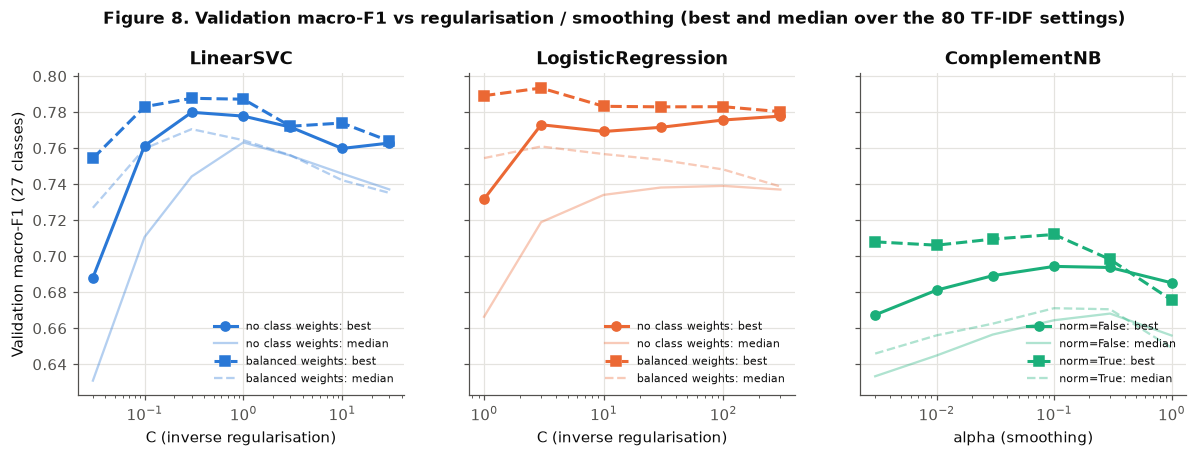

In [29]:
MODEL_COLORS = {"LinearSVC": PL.BLUE, "LogisticRegression": PL.ORANGE, "ComplementNB": PL.AQUA}
WEIGHT_LABEL = {"None": "no class weights", "balanced": "balanced weights", "False": "norm=False", "True": "norm=True"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, name in zip(axes, MODEL_COLORS):
    g = search[search.model == name]
    for w, ls, mk in zip(sorted(g.class_weight_or_norm.unique()), ["-", "--"], ["o", "s"]):
        best = g[g.class_weight_or_norm == w].groupby("C_or_alpha").val_macro_f1.max()
        med = g[g.class_weight_or_norm == w].groupby("C_or_alpha").val_macro_f1.median()
        ax.plot(best.index, best.values, ls, marker=mk, color=MODEL_COLORS[name], linewidth=2, markersize=6,
                label=f"{WEIGHT_LABEL[w]}: best")
        ax.plot(med.index, med.values, ls, color=MODEL_COLORS[name], alpha=0.35, linewidth=1.5,
                label=f"{WEIGHT_LABEL[w]}: median")
    ax.set_xscale("log"); ax.set_title(name)
    ax.set_xlabel("alpha (smoothing)" if name == "ComplementNB" else "C (inverse regularisation)")
    ax.legend(fontsize=7.5, loc="lower right")
axes[0].set_ylabel("Validation macro-F1 (27 classes)")
fig.suptitle("Figure 8. Validation macro-F1 vs regularisation / smoothing (best and median over the 80 TF-IDF settings)",
             fontweight="bold", y=1.03, fontsize=11)
PL.savefig(fig, 8, "classical_search_C"); plt.show()

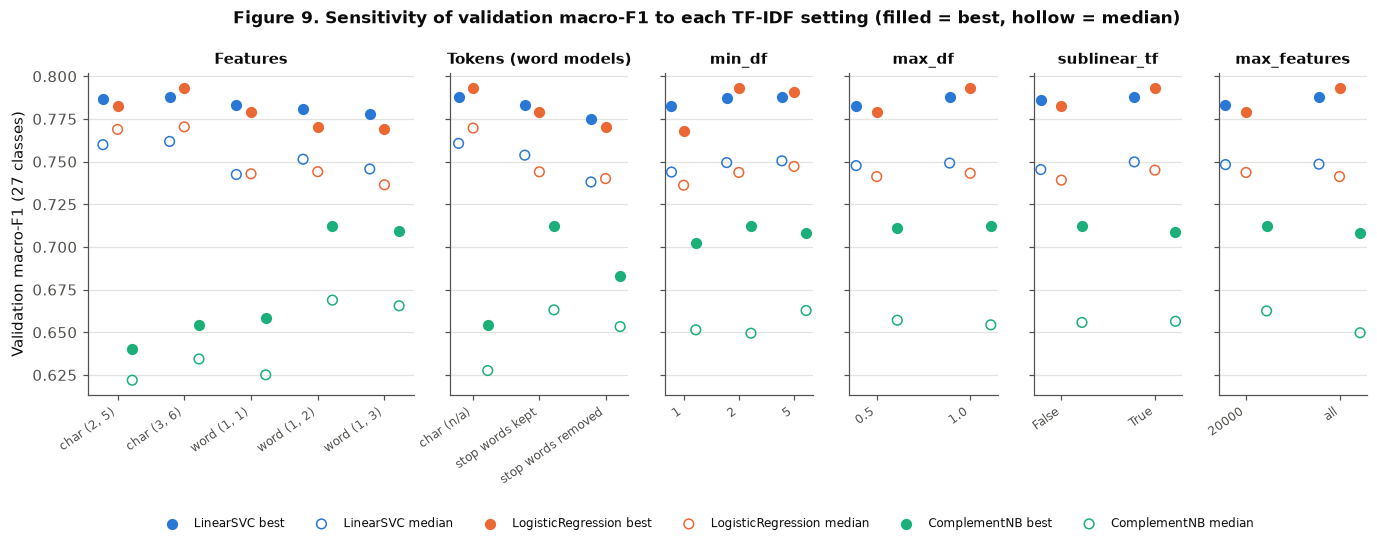

In [30]:
# Which TF-IDF settings mattered? Best (filled) and median (hollow) validation macro-F1 for each value.
search["features"] = np.where(search.analyzer == "word", "word " + search.ngram_range, "char " + search.ngram_range)
search["tokens"] = np.where(search.analyzer == "char_wb", "char (n/a)",
                            search.token_config.map({"study": "stop words removed", "study_keep_stopwords": "stop words kept"}))
params = [("features", "Features"), ("tokens", "Tokens (word models)"), ("min_df", "min_df"), ("max_df", "max_df"),
          ("sublinear_tf", "sublinear_tf"), ("max_features", "max_features")]
fig, axes = plt.subplots(1, len(params), figsize=(15, 3.8), sharey=True,
                         gridspec_kw={"width_ratios": [2.2, 1.2, 1, 1, 1, 1]})
for ax, (col, title) in zip(axes, params):
    vals = sorted(search[col].astype(str).unique())
    for k, name in enumerate(MODEL_COLORS):
        g = search[search.model == name]
        x = np.arange(len(vals)) + (k - 1) * 0.22
        best = [g[g[col].astype(str) == v].val_macro_f1.max() for v in vals]
        med = [g[g[col].astype(str) == v].val_macro_f1.median() for v in vals]
        ax.scatter(x, best, color=MODEL_COLORS[name], s=40, label=f"{name} best" if col == "features" else None, zorder=3)
        ax.scatter(x, med, facecolors="none", edgecolors=MODEL_COLORS[name], s=40,
                   label=f"{name} median" if col == "features" else None, zorder=3)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(vals, rotation=35, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Validation macro-F1 (27 classes)")
fig.legend(loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, -0.24))
fig.suptitle("Figure 9. Sensitivity of validation macro-F1 to each TF-IDF setting (filled = best, hollow = median)",
             fontweight="bold", y=1.03, fontsize=11)
PL.savefig(fig, 9, "classical_search_sensitivity"); plt.show()

In [31]:
# Selection rule: highest validation macro-F1; within 0.001 of the best -> fewest features, then fastest.
def select(g):
    cand = g[g.val_macro_f1 >= g.val_macro_f1.max() - 0.001]
    return cand.sort_values(["n_features", "fit_seconds"]).iloc[0]

selected = search.groupby("model").apply(select, include_groups=False)
display(selected.drop(columns="features").round(4))
# Edge check: does a selected regularisation / smoothing value sit on the edge of its grid?
for name, row in selected.iterrows():
    grid = GRID_VALUES[name]
    v = float(row.C_or_alpha)
    edge = "ON THE EDGE of the grid" if v in (min(grid), max(grid)) else "inside the grid"
    print(f"{name:>18}: selected {'alpha' if name == 'ComplementNB' else 'C'} = {v:g} -> {edge} {grid}")

,analyzer,token_config,ngram_range,min_df,max_df,sublinear_tf,max_features,C_or_alpha,class_weight_or_norm,n_features,val_macro_f1,val_macro_f1_robust,val_accuracy,fit_seconds,tokens
model,,,,,,,,,,,,,,,
ComplementNB,word,study_keep_stopwords,"(1, 2)",2,0.5,False,20000,0.1,True,20000,0.7113,0.7040,0.7856,0.0632,stop words kept
LinearSVC,char_wb,study,"(3, 6)",5,1.0,True,all,0.3,balanced,41209,0.7877,0.7796,0.8441,4.3526,char (n/a)
LogisticRegression,char_wb,study,"(3, 6)",2,1.0,True,all,3.0,balanced,69247,0.7934,0.7843,0.8382,32.2983,char (n/a)


      ComplementNB: selected alpha = 0.1 -> inside the grid [0.003, 0.01, 0.03, 0.1, 0.3, 1]
         LinearSVC: selected C = 0.3 -> inside the grid [0.03, 0.1, 0.3, 1, 3, 10, 30]
LogisticRegression: selected C = 3 -> inside the grid [1, 3, 10, 30, 100, 300]


**What the search showed (5,776 configurations, `results/classical_search.csv`).**

* **The two linear models are clearly ahead and close to each other.** Best validation macro-F1: Logistic Regression
  **0.793**, LinearSVC **0.788**, Complement NB 0.712.
* **Character n-grams won for both linear models** (`char_wb`, 3–6 characters: 0.793 / 0.788 against 0.779 / 0.783 for the
  best word-level settings). Character n-grams match word stems and fragments ("assign", "liab", "escrow") without any
  stemming rule, and they are robust to the hyphenation and typing variants of the filings.
* **Balanced class weights mattered more than any text preprocessing:** all ten best configurations of both linear models
  use `class_weight="balanced"`, and the best score without weights is lower (LinearSVC 0.780, Logistic Regression 0.778).
  With 27 imbalanced classes, unweighted models under-predict the rare ones.
* **Keeping stop words helped the word-level models** (see 3.3); for Complement NB, word pairs helped (best 0.712 with
  1–2-grams vs 0.659 with single words), while the linear models did slightly better with single words.
* **Settings that hardly mattered:** `min_df`, `max_df`, `max_features` and `sublinear_tf` move the best score by about
  0.01 or less (Figure 9).
* **No selected value sits on the edge of its grid** (cell above), so the grid was wide enough.
* **The top of the search is flat:** the ten best LinearSVC configurations lie within 0.005 of each other and the ten best
  Logistic Regression configurations within 0.012. Picking the maximum out of thousands of tries on one validation set is
  optimistic (the *winner's curse*), so the test score may be lower.

### 4.4 Validation confusions: testing the hypotheses of section 2.2
Before the test set is used at all, we look at **which classes the best classical model (by validation macro-F1)
confuses on validation**, and check the confusion hypotheses written down in section 2.2.

In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

def build_final(row, name):
    """Raw text -> selected TF-IDF -> selected classifier."""
    mf = None if str(row.max_features) == "all" else int(row.max_features)
    ng = tuple(int(x) for x in row.ngram_range.strip("()").split(","))
    if row.analyzer == "word":
        vec = P.make_vectorizer(TOKEN_CONFIGS[row.token_config], min_df=int(row.min_df), max_df=float(row.max_df),
                                sublinear_tf=bool(row.sublinear_tf), max_features=mf)
        vec.set_params(ngram_range=ng)
        if mf is not None:   # numpy breaks ties between equally frequent words differently on different CPUs (AVX-512
            # vs AVX2); where the max_features cut-off falls inside such a tie, the kept words of the original run are loaded
            key = (f"{row.token_config} {row.ngram_range} min_df={int(row.min_df)} max_df={float(row.max_df)} "
                   f"sublinear_tf={bool(row.sublinear_tf)} max_features={mf}")
            frozen = json.load(open(C.RESULTS_DIR / "frozen_vocabularies.json", encoding="utf-8"))
            if key in frozen:
                vec.set_params(vocabulary=frozen[key], max_features=None)
    else:
        vec = TfidfVectorizer(analyzer="char_wb", preprocessor=lambda s: P.clean_text(s, CFG), lowercase=False,
                              ngram_range=ng, min_df=int(row.min_df), max_df=float(row.max_df),
                              sublinear_tf=bool(row.sublinear_tf))
    cw = row.class_weight_or_norm
    p = ({"alpha": float(row.C_or_alpha), "norm": cw == "True"} if name == "ComplementNB"
         else {"C": float(row.C_or_alpha), "class_weight": None if cw == "None" else cw})
    return make_pipeline(vec, make_clf(name, p))

NAMES = {"LinearSVC": "tfidf_linearsvc", "LogisticRegression": "tfidf_logreg", "ComplementNB": "tfidf_complementnb"}
final_models, val_pred = {}, {}
for model, row in selected.iterrows():
    with C.timer(NAMES[model], "train_final", notes="refit of selected config on train"):
        pipe = build_final(row, model).fit(train.text, train.category)
    final_models[model] = pipe
    val_pred[model] = pipe.predict(val.text)
    m = C.compute_metrics(val.category, val_pred[model], LABELS, NAMES[model], "validation", robust_labels=ROBUST)
    assert abs(m["macro_f1"] - row.val_macro_f1) < 1e-9, "refit does not reproduce the search score"
    print(f"{model:>18}: validation macro-F1 {m['macro_f1']:.4f} (identical to the search), "
          f"robustness macro-F1 {m['macro_f1_robust']:.4f}")

BEST = selected.val_macro_f1.idxmax()              # chosen on VALIDATION, not on test
print(f"\nBest classical model by validation macro-F1: {BEST}")

def top_pairs(y_true, y_pred, k=10):
    cmx = confusion_matrix(y_true, y_pred, labels=LABELS)
    rows_ = [(LABELS[i], LABELS[j], int(cmx[i, j]), cmx[i, j] / cmx[i].sum()) for i in range(len(LABELS))
             for j in range(len(LABELS)) if i != j and cmx[i, j] > 0]
    out = (pd.DataFrame(rows_, columns=["true class", "predicted as", "clauses", "share of true class"])
           .sort_values(["clauses", "share of true class"], ascending=False).head(k).reset_index(drop=True))
    out.index += 1
    return out

val_conf = top_pairs(val.category, val_pred[BEST])
val_conf.to_csv(C.RESULTS_DIR / "top_confusions_validation.csv")
display(val_conf.round(3))

# Hypothesis check: how often is each new class predicted as its hypothesised neighbour (validation)?
cmv = pd.DataFrame(confusion_matrix(val.category, val_pred[BEST], labels=LABELS), index=LABELS, columns=LABELS)
hyp_check = hyp[["new class", "likely confused with"]].copy()
hyp_check["val clauses of new class"] = [int(cmv.loc[n].sum()) for n in hyp_check["new class"]]
hyp_check["predicted as that class"] = [int(cmv.loc[n, e]) for n, e in zip(hyp_check["new class"], hyp_check["likely confused with"])]
hyp_check["and the reverse"] = [int(cmv.loc[e, n]) for n, e in zip(hyp_check["new class"], hyp_check["likely confused with"])]
hyp_check["validation recall of new class"] = [cmv.loc[n, n] / cmv.loc[n].sum() for n in hyp_check["new class"]]
hyp_check["supported?"] = np.where(hyp_check["predicted as that class"] + hyp_check["and the reverse"] > 0, "yes", "no")
hyp_check.to_csv(C.RESULTS_DIR / "confusion_hypotheses_check.csv", index=False)
display(hyp_check.round(3))

[timer] tfidf_complementnb / train_final: 0.3 s
      ComplementNB: validation macro-F1 0.7113 (identical to the search), robustness macro-F1 0.7040


[timer] tfidf_linearsvc / train_final: 2.1 s


         LinearSVC: validation macro-F1 0.7877 (identical to the search), robustness macro-F1 0.7796


[timer] tfidf_logreg / train_final: 6.6 s


LogisticRegression: validation macro-F1 0.7934 (identical to the search), robustness macro-F1 0.7843

Best classical model by validation macro-F1: LogisticRegression


,true class,predicted as,clauses,share of true class
1,Exclusivity,License Grant,6,0.167
2,Post-Termination Services,Revenue/Profit Sharing,6,0.115
3,Non-Transferable License,Anti-Assignment,5,0.385
4,Renewal Term,Expiration Date,4,0.174
5,Rofr/Rofo/Rofn,License Grant,4,0.091
6,Minimum Commitment,Volume Restriction,4,0.075
7,Competitive Restriction Exception,Exclusivity,3,0.273
8,Rofr/Rofo/Rofn,Post-Termination Services,3,0.068
9,Anti-Assignment,Non-Transferable License,3,0.039
10,Competitive Restriction Exception,Rofr/Rofo/Rofn,2,0.182


,new class,likely confused with,val clauses of new class,predicted as that class,and the reverse,validation recall of new class,supported?
0,Non-Transferable License,License Grant,13,1,1,0.308,yes
1,Non-Transferable License,Anti-Assignment,13,5,3,0.308,yes
2,No-Solicit Of Employees,Non-Compete,11,0,0,0.727,no
3,Competitive Restriction Exception,Exclusivity,11,3,0,0.273,yes
4,Competitive Restriction Exception,Non-Compete,11,1,0,0.273,yes
5,Liquidated Damages,Cap On Liability,14,0,0,0.857,no
6,Joint Ip Ownership,Ip Ownership Assignment,16,0,0,0.938,no
7,Source Code Escrow,License Grant,11,0,0,0.727,no
8,Non-Disparagement,Covenant Not To Sue,7,0,0,0.857,no


**Interpretation (`results/top_confusions_validation.csv`, `results/confusion_hypotheses_check.csv`).** On validation,
the best classical model (Logistic Regression) makes these confusions most often: Exclusivity → License Grant (6) and
Post-Termination Services → Revenue/Profit Sharing (6), then Non-Transferable License → Anti-Assignment (5),
Renewal Term → Expiration Date, Rofr/Rofo/Rofn → License Grant and Minimum Commitment → Volume Restriction (4 each).

* **Supported hypotheses:** *Non-Transferable License ↔ Anti-Assignment* (5 clauses one way, 3 the other; only 4 of 13
  validation clauses of the new class are correct) and *Non-Transferable License ↔ License Grant* (1 + 1);
  *Competitive Restriction Exception → Exclusivity* (3 of 11) and *→ Non-Compete* (1). These are the two weakest new
  classes on validation (recall 0.31 and 0.27).
* **Not observed on validation:** No-Solicit Of Employees vs Non-Compete, Liquidated Damages vs Cap On Liability, Joint Ip
  Ownership vs Ip Ownership Assignment, Source Code Escrow vs License Grant, Non-Disparagement vs Covenant Not To Sue (0
  confusions each; these new classes reach validation recall 0.73–0.94). With only 7–16 validation clauses per new
  class, "not observed" is weak evidence; the test confusions below are a second, independent look.
* **Unexpected confusions** between *old* classes (Post-Termination Services → Revenue/Profit Sharing, Renewal Term →
  Expiration Date) show that the harder 27-class task is not only about the new classes.

### 4.5 Final models: refit on train, then one evaluation on test
**Refit on train only.** Each selected configuration was refitted on the training set exactly as in the search
(validation is *not* merged into training). Reasons: (1) the selected hyper-parameters were optimal for a model trained
on the training set, and adding the validation clauses changes the effective regularisation; (2) the fine-tuned
transformer needs validation for choosing the epoch, so every model in the comparison is trained on the same data;
(3) the validation score of each final model then matches the search exactly (checked above).

The final pipelines start from **raw text** (our tokenizer is built into the vectorizer), so exactly the same
preprocessing is applied to training, validation and test text. Only now are the four models scored on the test set —
**once each**, through `C.test_once`, which logs the evaluation in `results/test_eval_log.csv` and refuses a second
evaluation (the helper has no override in its normal path).

In [33]:
test_pred, test_res = {}, {}
test_res["majority"] = C.test_once("majority", {"strategy": "most_frequent"}, test.category,
                                   majority.predict(test.text), LABELS, test.row_id, test.contract, ROBUST)
for model, pipe in final_models.items():
    cfg = {"preprocessing": TOKEN_CONFIGS[selected.loc[model, "token_config"]], **{k: (v if not isinstance(v, (np.integer, np.floating)) else v.item())
                                    for k, v in selected.loc[model].drop(["features"]).items()}}
    test_pred[model] = pipe.predict(test.text)
    test_res[model] = C.test_once(NAMES[model], cfg, test.category, test_pred[model], LABELS,
                                  test.row_id, test.contract, ROBUST)

[test] majority: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.
[test] tfidf_complementnb: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.


[test] tfidf_linearsvc: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.


[test] tfidf_logreg: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.


In [34]:
# Summary table with contract-level bootstrap 95 % confidence intervals on test.
# Point estimates use all 27 classes (or the 24 robustness classes); inside each resample macro-F1 is averaged over the
# classes present in that resample's true labels (section 2.8). This is re-analysis of saved predictions, not a new test run.
budget = pd.read_csv(C.RESULTS_DIR / "compute_budget.csv")
rows = []
for key, name in [("majority", "majority")] + [(m, NAMES[m]) for m in final_models]:
    preds = majority.predict(test.text) if key == "majority" else test_pred[key]
    ci = C.bootstrap_ci(test.category.values, preds, test.contract.values, labels=LABELS, n_boot=1000)
    cir = C.bootstrap_ci(test.category.values, preds, test.contract.values, labels=ROBUST, n_boot=1000)
    vm = maj_val["macro_f1"] if key == "majority" else selected.loc[key, "val_macro_f1"]
    fit = budget[(budget.model == name) & (budget.stage == "train_final")].seconds
    rows.append({"model": name, "val_macro_f1": vm, "test_macro_f1": test_res[key]["macro_f1"],
                 "test_macro_f1_95ci": f"[{ci['ci_low']:.3f}, {ci['ci_high']:.3f}]", "bootstrap_median": ci["boot_median"],
                 f"test_macro_f1_robust_{len(ROBUST)}": test_res[key]["macro_f1_robust"],
                 "robust_95ci": f"[{cir['ci_low']:.3f}, {cir['ci_high']:.3f}]",
                 "test_accuracy": test_res[key]["accuracy"], "test_weighted_f1": test_res[key]["weighted_f1"],
                 "train_seconds": fit.iloc[-1] if len(fit) else np.nan})
summary = pd.DataFrame(rows)
summary.to_csv(C.RESULTS_DIR / "classical_summary.csv", index=False)
display(summary.round(4))

SECOND = selected.val_macro_f1.drop(BEST).idxmax()
pb = C.paired_bootstrap(test.category.values, test_pred[BEST], test_pred[SECOND], test.contract.values,
                        labels=LABELS, n_boot=1000)
print(f"Best classical model (chosen by validation macro-F1): {BEST}.")
print(f"Test macro-F1 difference {BEST} - {SECOND}: {pb['diff']:+.4f}  95 % CI [{pb['ci_low']:+.4f}, {pb['ci_high']:+.4f}]"
      f"  (share of resamples where {BEST} is not better: {pb['p_a_not_better']:.3f})")
gap = test_res[BEST]["macro_f1"] - test_res["majority"]["macro_f1"]
print(f"Objective O2 (best TF-IDF beats majority by >= 0.50 macro-F1 on test): gap = {gap:.3f} -> "
      f"{'MET' if gap >= 0.50 else 'NOT MET'}")
json.dump({"best_classical": NAMES[BEST], "second": NAMES[SECOND], "paired_bootstrap_test": pb,
           "O2_gap": gap}, open(C.RESULTS_DIR / "classical_best.json", "w"), indent=2)

,model,val_macro_f1,test_macro_f1,test_macro_f1_95ci,bootstrap_median,test_macro_f1_robust_24,robust_95ci,test_accuracy,test_weighted_f1,train_seconds
0,majority,0.0057,0.0055,"[0.004, 0.007]",0.0055,0.0061,"[0.005, 0.008]",0.0796,0.0117,NaN
1,tfidf_complementnb,0.7113,0.7133,"[0.669, 0.738]",0.7052,0.7009,"[0.664, 0.727]",0.7777,0.7643,0.33
2,tfidf_linearsvc,0.7877,0.7862,"[0.750, 0.817]",0.7831,0.7900,"[0.754, 0.818]",0.8317,0.8306,2.08
3,tfidf_logreg,0.7934,0.7939,"[0.752, 0.824]",0.7890,0.7962,"[0.761, 0.825]",0.8289,0.8300,6.59


Best classical model (chosen by validation macro-F1): LogisticRegression.
Test macro-F1 difference LogisticRegression - LinearSVC: +0.0077  95 % CI [-0.0113, +0.0240]  (share of resamples where LogisticRegression is not better: 0.250)
Objective O2 (best TF-IDF beats majority by >= 0.50 macro-F1 on test): gap = 0.788 -> MET


**Interpretation of the test results (each model scored once; `results/test_eval_log.csv`).**

* **Objective O2 is met:** the best TF-IDF model beats the majority baseline (test macro-F1 0.006) by **0.788**, far above
  the 0.50 target.
* **Logistic Regression (0.794, 95 % CI 0.752–0.824) and LinearSVC (0.786, CI 0.750–0.817) are statistically tied:** the
  paired contract-level bootstrap gives a difference of +0.008 with CI [−0.011, +0.024]. Logistic Regression is the "best
  classical model" because it was best on *validation* (0.793 vs 0.788), the pre-declared rule. It also gives class
  probabilities, useful for ranking clauses for a reviewer.
* **Complement NB is clearly weaker** (0.713, CI 0.669–0.738).
* **The robustness number agrees:** over the 24 classes with ≥ 15 test clauses, Logistic Regression scores 0.796 and
  LinearSVC 0.790 — the conclusions do not depend on the three rare classes.
* **Validation and test agree** for the best model (0.793 vs 0.794), so the winner's-curse effect was small here.
* Accuracy (0.829) is higher than macro-F1 (0.794) because the large classes are easier than several small ones — the
  reason macro-F1 is the primary metric.

### 4.6 The best classical model in detail
Per-class results with 95 % contract-level bootstrap CIs (rare classes get wide intervals), the confusion matrices,
the most-confused pairs on test, and the most important features per class.

tfidf_logreg - per-class results on the test set (sorted by F1)


,precision,recall,f1,ci_low,ci_high,resamples_used,support,test_contracts,recall < 0.70,< 15 test clauses,CI
Exclusivity,0.532,0.568,0.549,0.430,0.667,1000,44,27,*,,
Competitive Restriction Exception,0.579,0.647,0.611,0.381,0.783,999,17,11,*,,
Liquidated Damages,0.706,0.571,0.632,0.400,0.818,1000,21,14,*,,
Non-Transferable License,0.591,0.684,0.634,0.300,0.818,1000,19,11,*,,
Non-Disparagement,0.875,0.583,0.700,0.460,0.890,997,12,7,*,rare,
Post-Termination Services,0.679,0.757,0.716,0.647,0.797,1000,70,29,,,
Change Of Control,0.767,0.673,0.717,0.571,0.824,1000,49,23,*,,
Warranty Duration,0.722,0.722,0.722,0.417,0.878,1000,18,10,,,
Volume Restriction,0.650,0.839,0.732,0.585,0.849,1000,31,16,,,
Termination For Convenience,0.689,0.795,0.738,0.635,0.832,1000,39,28,,,


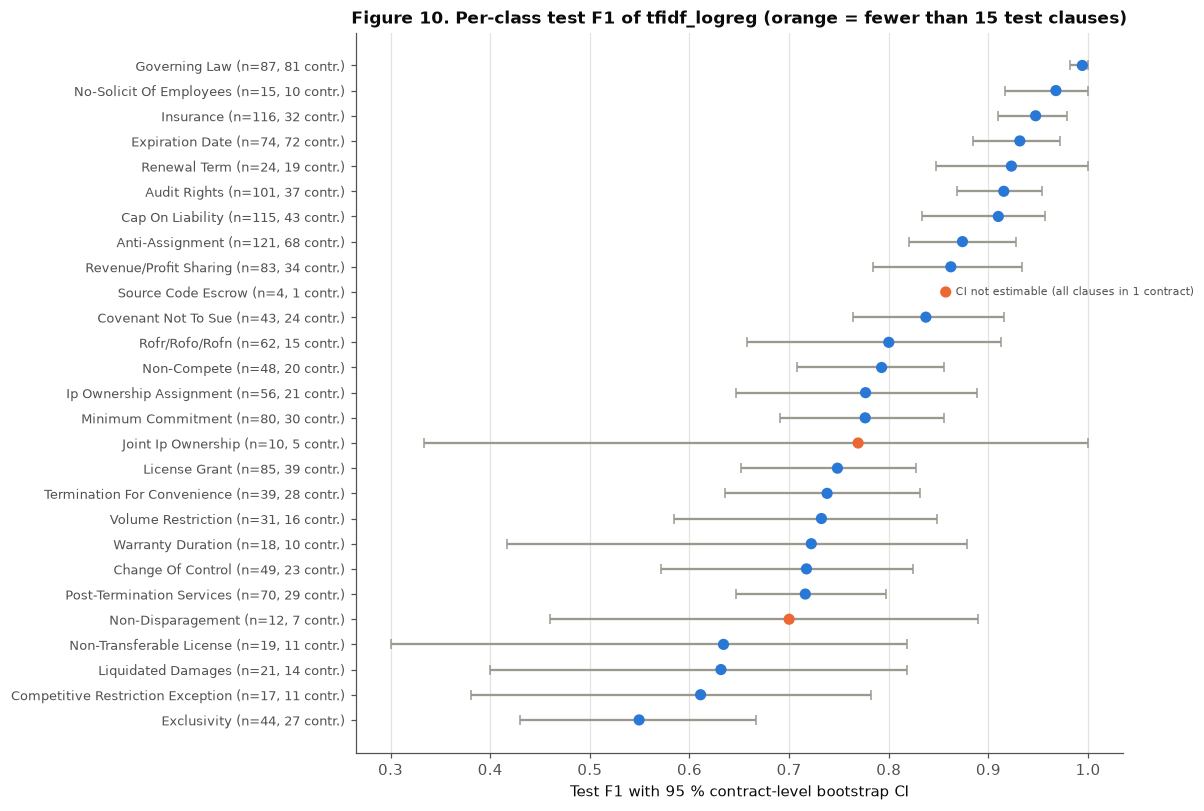

In [35]:
pc = C.per_class_bootstrap_ci(test.category.values, test_pred[BEST], test.contract.values, LABELS, n_boot=1000)
pr = pd.DataFrame(test_res[BEST]["per_class"]).T[["precision", "recall"]]
pc = pr.join(pc).sort_values("f1")
pc["recall < 0.70"] = np.where(pc.recall < 0.70, "*", "")
pc["< 15 test clauses"] = np.where(pc.support < C.MIN_TEST_CLAUSES_ROBUST, "rare", "")
pc["CI"] = np.where(pc.ci_low.isna(), "not estimable (1 contract)", "")
pc.to_csv(C.RESULTS_DIR / "per_class_best_classical.csv")
print(f"{NAMES[BEST]} - per-class results on the test set (sorted by F1)")
display(pc.round(3))

fig, ax = plt.subplots(figsize=(9, 8.5))
yy = np.arange(len(pc))
colors = [PL.ORANGE if s < C.MIN_TEST_CLAUSES_ROBUST else PL.BLUE for s in pc.support]
ok = pc.ci_low.notna().values
ax.errorbar(pc.f1[ok], yy[ok], xerr=[(pc.f1 - pc.ci_low)[ok], (pc.ci_high - pc.f1)[ok]], fmt="none", ecolor="#9a988f", capsize=3)
ax.scatter(pc.f1, yy, c=colors, s=40, zorder=3)
for y_, (c_, r_) in zip(yy, pc.iterrows()):
    if pd.isna(r_.ci_low):
        ax.text(r_.f1 + 0.01, y_, "CI not estimable (all clauses in 1 contract)", va="center", fontsize=7.5, color=PL.INK_2)
ax.set_yticks(yy); ax.set_yticklabels([f"{c} (n={s}, {k} contr.)" for c, s, k in zip(pc.index, pc.support, pc.test_contracts)],
                                      fontsize=8.5)
ax.set_xlabel("Test F1 with 95 % contract-level bootstrap CI"); ax.grid(axis="y", visible=False)
ax.set_title(f"Figure 10. Per-class test F1 of {NAMES[BEST]} (orange = fewer than {C.MIN_TEST_CLAUSES_ROBUST} test clauses)",
             fontsize=11)
PL.savefig(fig, 10, "per_class_f1_best_classical"); plt.show()

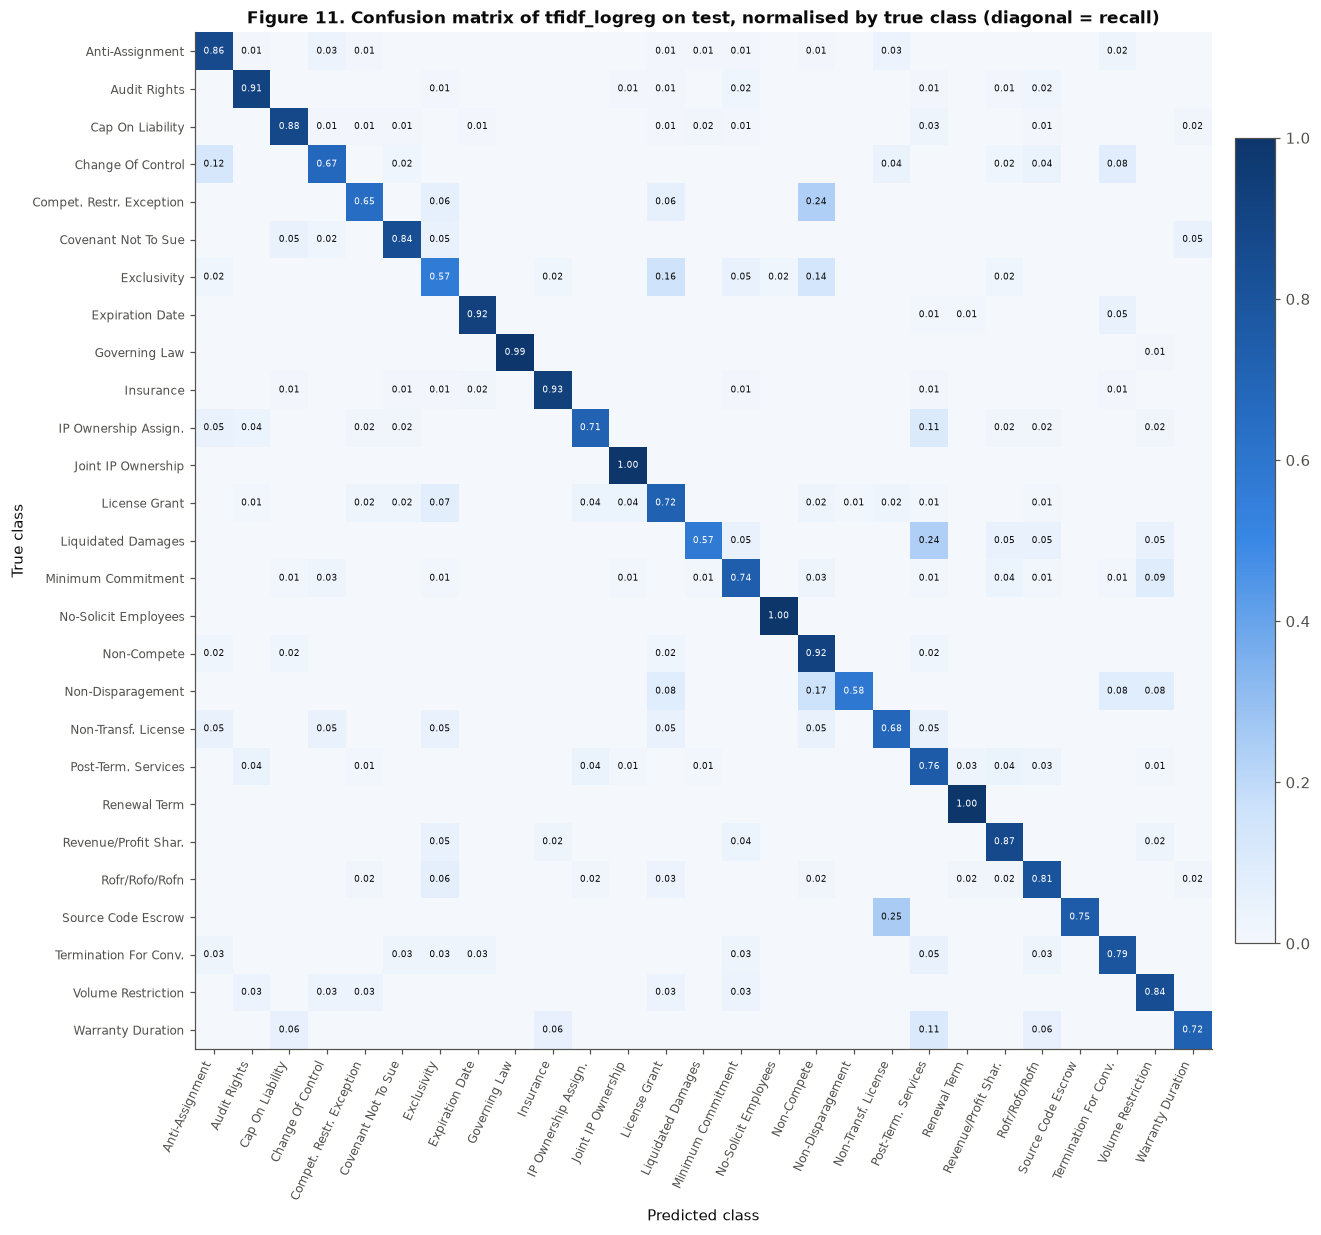

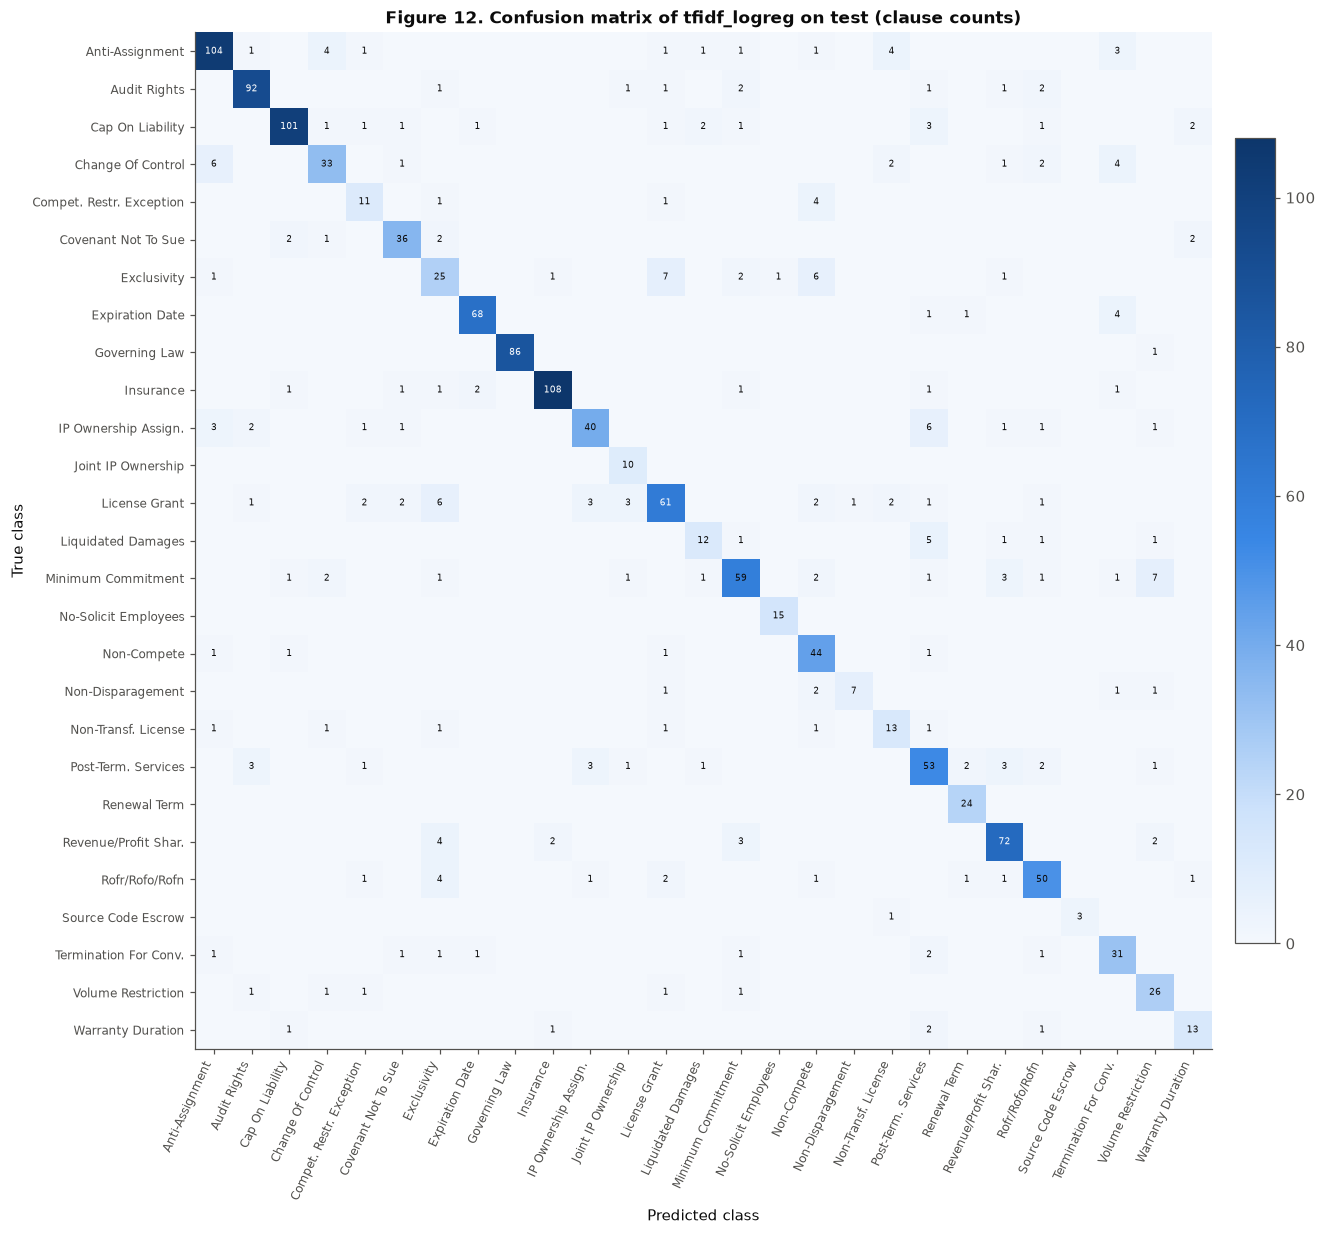

In [36]:
SHORT = {"Post-Termination Services": "Post-Term. Services", "Termination For Convenience": "Termination For Conv.",
         "Ip Ownership Assignment": "IP Ownership Assign.", "Revenue/Profit Sharing": "Revenue/Profit Shar.",
         "Competitive Restriction Exception": "Compet. Restr. Exception", "Non-Transferable License": "Non-Transf. License",
         "No-Solicit Of Employees": "No-Solicit Employees", "Joint Ip Ownership": "Joint IP Ownership"}
short = [SHORT.get(l, l) for l in LABELS]

def plot_cm(mat, fmt, title, number, fname, vmax=None):
    fig, ax = plt.subplots(figsize=(13.5, 12))
    im = ax.imshow(mat, cmap=PL.BLUES, vmin=0, vmax=vmax)
    ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(short, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(short, fontsize=8)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.grid(False)
    thresh = (vmax or mat.max()) * 0.55
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            if mat[i, j] > 0:
                ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center", fontsize=6,
                        color="white" if mat[i, j] > thresh else PL.INK)
    fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    ax.set_title(title, fontsize=11)
    PL.savefig(fig, number, fname); plt.show()

cm = np.array(test_res[BEST]["confusion_matrix"])
plot_cm(cm / cm.sum(axis=1, keepdims=True), ".2f",
        f"Figure 11. Confusion matrix of {NAMES[BEST]} on test, normalised by true class (diagonal = recall)",
        11, "cm_best_classical_normalised", vmax=1)
plot_cm(cm, "d", f"Figure 12. Confusion matrix of {NAMES[BEST]} on test (clause counts)", 12, "cm_best_classical_counts")

In [37]:
# The 10 most frequent confusions on test (true -> predicted), for comparison with validation (4.4)
test_conf = top_pairs(test.category, test_pred[BEST])
test_conf.to_csv(C.RESULTS_DIR / "top_confusions_best_classical.csv")
display(test_conf.round(3))

,true class,predicted as,clauses,share of true class
1,Exclusivity,License Grant,7,0.159
2,Minimum Commitment,Volume Restriction,7,0.088
3,Exclusivity,Non-Compete,6,0.136
4,Change Of Control,Anti-Assignment,6,0.122
5,Ip Ownership Assignment,Post-Termination Services,6,0.107
6,License Grant,Exclusivity,6,0.071
7,Liquidated Damages,Post-Termination Services,5,0.238
8,Competitive Restriction Exception,Non-Compete,4,0.235
9,Change Of Control,Termination For Convenience,4,0.082
10,Rofr/Rofo/Rofn,Exclusivity,4,0.065


In [38]:
# Interpretability: the TF-IDF features with the largest positive weight for each class (preprocessed tokens)
pipe = final_models[BEST]
vec_b, clf_b = pipe[0], pipe[-1]
feat = vec_b.get_feature_names_out()
weights = clf_b.coef_ if hasattr(clf_b, "coef_") else clf_b.feature_log_prob_
top = {cls: ", ".join(feat[np.argsort(weights[k])[::-1][:8]]) for k, cls in enumerate(clf_b.classes_)}
pd.set_option("display.max_colwidth", 140)
display(pd.DataFrame.from_dict(top, orient="index", columns=[f"{NAMES[BEST]}: top 8 character n-gram features"]))

,tfidf_logreg: top 8 character n-gram features
Anti-Assignment,"ssig, ssign, assig, assign, assig, assi, assi, ign"
Audit Rights,"udit, audit, audi, audit, audi, aud, aud, au"
Cap On Liability,"iab, liab, liab, lia, lia, bili, bilit, bility"
Change Of Control,"hange , ange , hange, hang, nge , ange, ang, nge"
Competitive Restriction Exception,"othin, othi, othing, sivi, usivit, lusivi, sivity, sivit"
Covenant Not To Sue,"ontes, ontest, contes, ntest, ntes, test, conte, conte"
Exclusivity,"excl, exclu, xclus, xclusi, lusiv, usiv, clusiv, lusi"
Expiration Date,"20, term , term , Date, Date, Dat, Dat, term"
Governing Law,"law, law, la, laws, laws, aws, laws , laws"
Insurance,"nsur, sur, insur, insu, insur, insu, nsu, sura"


**Readable version: the best word-level Logistic Regression.** Character fragments are hard to read, so we also fit the
Logistic Regression configuration with the highest validation macro-F1 **among word-level settings** (same selection
rule as above, restricted to `analyzer = word`) and show its strongest words. This model is used only for
interpretation; it is not evaluated on the test set.

In [39]:
wl = search[(search.model == "LogisticRegression") & (search.analyzer == "word")]
word_row = select(wl)
print("Best word-level Logistic Regression (validation):",
      {k: (word_row[k].item() if hasattr(word_row[k], "item") else word_row[k])
       for k in ["token_config", "ngram_range", "min_df", "max_df", "sublinear_tf", "max_features",
                 "C_or_alpha", "class_weight_or_norm", "val_macro_f1"]})
word_pipe = build_final(word_row, "LogisticRegression").fit(train.text, train.category)
assert abs(f1_score(val.category, word_pipe.predict(val.text), labels=LABELS, average="macro", zero_division=0)
           - word_row.val_macro_f1) < 1e-9
wfeat = word_pipe[0].get_feature_names_out()
wcoef = word_pipe[-1].coef_
wtop = {cls: ", ".join(wfeat[np.argsort(wcoef[k])[::-1][:10]]) for k, cls in enumerate(word_pipe[-1].classes_)}
pd.DataFrame.from_dict(wtop, orient="index", columns=["word-level Logistic Regression: top 10 words"])

Best word-level Logistic Regression (validation): {'token_config': 'study_keep_stopwords', 'ngram_range': '(1, 1)', 'min_df': 5, 'max_df': 0.5, 'sublinear_tf': True, 'max_features': '20000', 'C_or_alpha': 30.0, 'class_weight_or_norm': 'balanced', 'val_macro_f1': 0.7793249005680762}


,word-level Logistic Regression: top 10 words
Anti-Assignment,"assign, assignment, assigned, consent, Party, assignable, void, Transfer, subcontract, Sparkling"
Audit Rights,"audit, records, inspect, audits, inspection, reasonable, inspections, access, examination, audited"
Cap On Liability,"liability, liable, damages, sole, remedy, exceed, claim, OR, breach, FOR"
Change Of Control,"Change, Control, change, terminated, merger, transaction, control, terminate, Licensor, may"
Competitive Restriction Exception,"MBE, Notwithstanding, traded, stock, market, from, Exclusivity, exclusivity, nothing, Hearing"
Covenant Not To Sue,"contest, validity, challenge, ownership, any, Entities, against, trademarks, register, MLX"
Exclusivity,"exclusive, exclusively, Exclusivity, provider, exclusivity, Exclusive, During, Term, other, Territory"
Expiration Date,"term, Date, continue, years, addition, terminate, The, effect, unless, date"
Governing Law,"laws, governed, State, state, law, Agreement, construed, accordance, This, LAWS"
Insurance,"insurance, coverage, insured, Insurance, policies, policy, maintain, liability, insure, less"


**Interpretation of the best classical model (Logistic Regression on character n-grams).**

* **Easy classes have distinctive vocabulary:** Governing Law (F1 0.994), No-Solicit Of Employees (0.968), Insurance,
  Expiration Date, Renewal Term, Audit Rights and Cap On Liability (all ≥ 0.91).
* **Six classes fall below 0.70 recall** — Exclusivity (0.57), Liquidated Damages (0.57), Non-Disparagement (0.58),
  Competitive Restriction Exception (0.65), Change Of Control (0.67) and Non-Transferable License (0.68) — so this model
  does **not** satisfy objective O5 (O5 is judged on the overall best model in Part C).
* **The test confusions repeat the validation picture:** Exclusivity → License Grant (7) and → Non-Compete (6), Change Of
  Control → Anti-Assignment (6), License Grant → Exclusivity (6), Competitive Restriction Exception → Non-Compete (4, 24 %
  of its test clauses). **Liquidated Damages → Post-Termination Services (5, 24 %)** confirms the data-driven neighbour
  found in section 2.2 rather than the hypothesised Cap On Liability. Minimum Commitment → Volume Restriction (7) is the
  most frequent confusion between two old classes.
* **Rare classes are essentially unmeasured:** all 4 Source Code Escrow test clauses come from **one** contract, so a
  contract-level CI cannot be estimated at all (F1 0.857 is a single-contract result); Joint Ip Ownership (10 clauses, 5
  contracts) has F1 0.769 with a CI of 0.33–1.00 (Figure 10). Their point values should not be over-read.
* **The strongest features are fragments of legal cue words** (`assign`, `audit`, `liab`, `insur`, `escrow`, `dispar`,
  `empl`, `renew`, `warrant`), so the model is interpretable for a legal reviewer; a few are generic (`pay`, `use`, `20`).
* **The readable word-level version** (best word-level Logistic Regression on validation: single words, stop words kept,
  balanced, validation macro-F1 0.779) shows the same picture in plain words — *assign, consent, void* (Anti-Assignment),
  *audit, records, inspect* (Audit Rights), *liquidated, damages, penalty* (Liquidated Damages), *disparage, reputation,
  goodwill* (Non-Disparagement), *sublicense, transferable* (Non-Transferable License). It also exposes a weakness: some
  strong features are company or product names from a few training contracts (*Sparkling*, *MBE*, *MLX*, *XLI*), i.e. the
  word model partly memorises parties. The contract-level split prevents this from inflating the test score, but it is
  noted in Limitations.

### 4.7 Leakage check with the best classical model
Section 2.1 used a default model. Here the **selected best classical pipeline** is trained and scored on a random
clause-level split and on a contract-level split of the *train + validation* contracts (same held-out size, 5 seeds;
test contracts not used), to measure how much a naive split would overstate its performance.

In [40]:
best_row = selected.loc[BEST]
def leak_fit(seed, kind, tr_i, ho_i):
    m_ = build_final(best_row, BEST).fit(pool.text.iloc[tr_i], pool.category.iloc[tr_i])
    pred = m_.predict(pool.text.iloc[ho_i])
    return {"seed": seed, "split": kind, "held_out": len(ho_i),
            "macro_f1": f1_score(pool.category.iloc[ho_i], pred, labels=LABELS, average="macro", zero_division=0)}

jobs = []
for seed in range(5):
    tr_r, ho_r = train_test_split(np.arange(len(pool)), test_size=0.2, random_state=seed, stratify=pool.category)
    tr_g, ho_g = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(pool, groups=pool.contract))
    jobs += [(seed, "random clause-level", tr_r, ho_r), (seed, "contract-level", tr_g, ho_g)]
rows = Parallel(n_jobs=-1)(delayed(leak_fit)(*j) for j in jobs)   # the 10 fits are independent: run them in parallel
leak_best = pd.DataFrame(rows)
leak_best.to_csv(C.RESULTS_DIR / "leakage_check_best_classical.csv", index=False)
lb_sum = leak_best.groupby("split")[["held_out", "macro_f1"]].agg(["mean", "std"])
display(lb_sum.round(4))
infl = lb_sum.loc["random clause-level", ("macro_f1", "mean")] - lb_sum.loc["contract-level", ("macro_f1", "mean")]
print(f"A random clause-level split overstates the best classical model's macro-F1 by {infl:+.3f} on average.")

held_out           macro_f1        
                        mean       std     mean     std
split                                                  
contract-level        1243.2  111.8155   0.7857  0.0118
random clause-level   1269.0    0.0000   0.7985  0.0155

A random clause-level split overstates the best classical model's macro-F1 by +0.013 on average.


**Interpretation (`results/leakage_check_best_classical.csv`).** For the tuned best classical pipeline, a random
clause-level split gives 0.799 ± 0.016 macro-F1 against 0.786 ± 0.012 with a contract-level split: the naive split would
overstate its performance by **+0.013**. The effect is about half of the default model's +0.026 (section 2.1) —
character n-grams with balanced weights rely less on contract-specific wording — but it is still positive in the mean,
which confirms that the contract-level split is the right protocol.

### 4.8 What this tells us so far

* **The 27-class task is learnable with simple models but clearly harder.** Tuned TF-IDF + linear classifiers reach about
  **0.79 test macro-F1** (Logistic Regression 0.794 [0.752, 0.824], LinearSVC 0.786) on contracts never seen in training, against 0.006
  for the majority baseline.
* **What mattered:** character n-grams and balanced class weights (sections 3.7 and 4.3). Text preprocessing (lower-casing,
  stemming, placeholders, stop words, n-gram range) made no measurable difference on the untuned bench (section 3.3), and
  keeping stop words was better once the classifiers were tuned.
* **Where the errors are:** between classes that overlap in legal meaning — Exclusivity vs License Grant / Non-Compete,
  Change Of Control vs Anti-Assignment, and the new classes Competitive Restriction Exception, Non-Transferable License and
  Liquidated Damages. Several of these clauses genuinely carry two labels (section 2.6), which limits any single-label
  model. The rare classes cannot be measured precisely with 4–12 test clauses.
* **Honesty notes** (also in the report's limitations): the ≥ 60 class-size rule used whole-corpus
  counts (class sizes only); a first-version 20-class pipeline was run before the proposal was approved — its outputs are
  archived and never reported, and every v2 choice was re-made on v2 validation (deviation D7 in the report); the multi-label clauses are
  held out of the main score; the contracts are US, SEC-filed and English only.
* **Next:** fine-tuned Legal-BERT and the BERT-base ablation on the same split (section 5), compared with these baselines
  with the paired contract-level bootstrap.

## 5. Fine-tuned transformer: Legal-BERT (and the controlled ablation with BERT-base)

### 5.1 Why this checkpoint
**`nlpaueb/legal-bert-base-uncased`** (Chalkidis et al., 2020, *Findings of EMNLP*; model licence CC BY-SA 4.0):
* **Domain match.** It was pre-trained from scratch on about 12 GB of English legal text — legislation, court cases
  and **76,366 US contracts from SEC EDGAR**, the same kind of document as CUAD. Its WordPiece vocabulary was built
  from that legal text, so legal terms such as "licensee" or "indemnify" are single tokens (section 3.5).
* **Size fits the compute.** BERT-base architecture: 12 layers, 768 hidden units, about 110 M parameters. On our
  RTX 5080 (16 GB) one epoch over the training clauses takes seconds (benchmark below), so we can afford a
  learning-rate search, three seeds, a class-weighting test and the ablation. The same model would also train on a
  free Colab GPU.
* **Input window covers the clauses.** The 512-token limit is far above typical clause length; we use the
  `max_length` chosen in section 3.5 from both tokenizers, which truncates fewer than 1 % of clauses.
* **Honesty note (Honesty log):** Legal-BERT's pre-training corpus contains EDGAR contracts, and CUAD contracts are
  EDGAR filings too, so some CUAD *text* may have been seen during pre-training. This is unlabelled text, so no label
  can leak, but memorised boilerplate could help a little. We cannot check the overlap; it is stated as a limitation.

**Ablation model:** `bert-base-uncased` (Devlin et al., 2019) — identical architecture and size, pre-trained on general
English (books and Wikipedia). Legal-BERT-base was pre-trained **from scratch on legal text with its own legal
vocabulary**, so the ablation changes the pre-training corpus **and** the vocabulary together; it measures their
combined effect and cannot separate them.

### 5.2 The fine-tuning recipe (identical for both models)

| Setting | Value | Why |
|---|---|---|
| Optimiser | AdamW, weight decay 0.01 (none on biases / LayerNorm) | standard for BERT fine-tuning; decoupled weight decay regularises without disturbing Adam's step sizes |
| Learning rate | searched over {2e-5, 3e-5, 5e-5} on validation | the range recommended for BERT fine-tuning by Devlin et al. (2019) |
| Schedule | linear warm-up over the first 10 % of steps, then linear decay to 0 | warm-up avoids large, destructive updates while the new classification layer is still random |
| Batch size | 16 | recommended range (16/32); more parameter updates per epoch on a small dataset |
| Epochs | 5, best epoch chosen by validation macro-F1 | Devlin et al. suggest 2–4; one extra epoch lets the curves show whether the model over-fits |
| Gradient clipping | max norm 1.0 | protects against occasional exploding gradients |
| Precision | bfloat16 mixed precision on the GPU | about 2× faster, half the memory; bfloat16 needs no loss scaling |
| Padding | dynamic (each batch padded to its own longest clause), `max_length` from section 3.5 | most clauses are short, so padding every clause to the maximum would waste most of the compute |
| Loss | cross-entropy; a class-weighted variant (inverse class frequency) is tested with 3 seeds | 27 imbalanced classes; adopted only if it clearly helps (rule below) |
| Seeds | 42, 43, 44 → mean ± std on validation | the test model is **pre-declared**: seed 42 — never the best seed |
| Selection rules | LR = best Legal-BERT validation macro-F1 (seed 42); BERT-base uses the **same** LR; class weights adopted only if the 3-seed mean gain is ≥ 0.003 **and** larger than the seed spread (max − min) of the unweighted runs | fixed in `src/finetune.py` (`run_full_plan`) before any run |

The training loop is plain PyTorch in `src/finetune.py` (function `train_run`, about 100 commented lines). After every
epoch it writes a resume checkpoint (model, optimiser, scheduler, random-number state), so an interrupted run continues
from the last finished epoch.

In [41]:
import inspect, torch, logging
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"          # keep the outputs readable
transformers.utils.logging.disable_progress_bar()
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
from src import finetune as F
importlib.reload(F)
print("Recipe used by every run:", F.RECIPE)
# The core of one training step, printed from src/finetune.py so the notebook shows the real code:
src_lines = inspect.getsource(F.train_run).splitlines()
start = next(i for i, l in enumerate(src_lines) if "for i, batch in enumerate(loader)" in l)
print("\n".join(src_lines[start:start + 12]))

W1113 16:54:21.555000 12484 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Recipe used by every run: {'max_length': 320, 'batch_size': 16, 'epochs': 5, 'warmup_ratio': 0.1, 'weight_decay': 0.01, 'max_grad_norm': 1.0, 'eval_batch_size': 64}
        for i, batch in enumerate(loader):
            batch = {k: v.to(device) for k, v in batch.items()}
            y = batch.pop("labels")
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=device.type == "cuda"):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), recipe["max_grad_norm"])
            optimizer.step(); scheduler.step(); optimizer.zero_grad(set_to_none=True)
            rows.append({"run_id": rid, "kind": "step", "epoch": epoch, "step": (epoch - 1) * steps_per_epoch + i + 1,
                         "train_loss": loss.item(), "lr": scheduler.get_last_lr()[0]})
        if device.type == "cuda":


### 5.3 Benchmark before training (measure first)
Twenty training steps at the batch size we use, timed on this machine, to project the cost of the whole plan before
starting it. (Without a GPU, e.g. on Colab's CPU runtime, this cell shows the saved measurement instead.)

In [42]:
from transformers import AutoModelForSequenceClassification
BENCH_JSON = C.RESULTS_DIR / "transformer_benchmark.json"
if torch.cuda.is_available() and not BENCH_JSON.exists():
    bench = {}
    for key, ckpt in F.CHECKPOINTS.items():
        tok = AutoTokenizer.from_pretrained(ckpt)
        mdl = AutoModelForSequenceClassification.from_pretrained(ckpt, id2label=dict(enumerate(LABELS))).cuda()
        items = F.encode(tok, list(train.text[:16 * 25]), list(train.category[:16 * 25]),
                         {l: i for i, l in enumerate(LABELS)}, F.RECIPE["max_length"])
        loader = F.make_loader(items, tok, 16, shuffle=False)
        opt = torch.optim.AdamW(mdl.parameters(), lr=3e-5)
        torch.cuda.reset_peak_memory_stats()
        for i, b in enumerate(loader):
            if i == 5:
                torch.cuda.synchronize(); t0 = time.perf_counter()
            b = {k: v.cuda() for k, v in b.items()}
            with torch.autocast("cuda", dtype=torch.bfloat16):
                loss = mdl(**b).loss
            loss.backward(); torch.nn.utils.clip_grad_norm_(mdl.parameters(), 1.0); opt.step(); opt.zero_grad()
        torch.cuda.synchronize()
        ms = (time.perf_counter() - t0) / 20 * 1000
        steps = -(-len(train) // 16)
        bench[key] = {"ms_per_step": ms, "steps_per_epoch": steps, "projected_epoch_seconds": ms * steps / 1000,
                      "peak_gpu_mem_gb": torch.cuda.max_memory_allocated() / 1e9, "gpu": torch.cuda.get_device_name(0)}
        del mdl, opt; torch.cuda.empty_cache()
    n_runs, epochs = 13, F.RECIPE["epochs"]      # 6 LR runs + 4 extra seeds + 3 class-weighted (+3 if adopted)
    bench["projection"] = {"runs": n_runs, "runs_if_class_weights_adopted": n_runs + 3, "epochs_per_run": epochs,
                           "projected_total_minutes": n_runs * epochs * bench["legalbert"]["projected_epoch_seconds"] / 60}
    json.dump(bench, open(BENCH_JSON, "w"), indent=2)
bench = json.load(open(BENCH_JSON))
for key in F.CHECKPOINTS:
    b = bench[key]
    print(f"{key:>9}: {b['ms_per_step']:.0f} ms per step (batch 16) -> {b['projected_epoch_seconds']:.0f} s per epoch, "
          f"peak GPU memory {b['peak_gpu_mem_gb']:.1f} GB on {b['gpu']}")
pj = bench["projection"]
print(f"Projected plan: {pj['runs']} runs (up to {pj['runs_if_class_weights_adopted']}) x {pj['epochs_per_run']} epochs ≈ "
      f"{pj['projected_total_minutes']:.0f} min of training steps (+ validation) -> far below the 6-hour limit, so the "
      "whole plan runs locally.")

legalbert: 49 ms per step (batch 16) -> 16 s per epoch, peak GPU memory 3.6 GB on NVIDIA GeForce RTX 5080
     bert: 49 ms per step (batch 16) -> 16 s per epoch, peak GPU memory 3.6 GB on NVIDIA GeForce RTX 5080
Projected plan: 13 runs (up to 16) x 5 epochs ≈ 18 min of training steps (+ validation) -> far below the 6-hour limit, so the whole plan runs locally.


### 5.4 Training all runs
The plan (all decision rules fixed in advance in `F.run_full_plan`):
1. learning-rate search {2e-5, 3e-5, 5e-5} with seed 42 for **both** checkpoints (6 runs);
2. seeds 43 and 44 at the chosen learning rate for both checkpoints (4 runs);
3. class-weighted Legal-BERT with seeds 42, 43, 44 (3 runs); if adopted, the same for BERT-base (3 more runs).

The real run was executed with `python scripts/train_transformer.py` (same function, run in the background with a log
file). `RETRAIN = False` loads its logs; `RETRAIN = True` re-runs everything (about 20–25 min on an RTX 5080).

In [43]:
RETRAIN = False
if RETRAIN:
    with C.timer("transformer_plan", "all_runs", notes="re-run from notebook", device="GPU"):
        choice = F.run_full_plan(train, val, LABELS)
choice = json.load(open(C.RESULTS_DIR / "transformer_choice.json"))
tsearch = pd.read_csv(C.RESULTS_DIR / "transformer_search.csv")
tlog = pd.read_csv(C.RESULTS_DIR / "transformer_log.csv")
cols = ["run_id", "model", "lr", "seed", "class_weighted", "best_epoch", "val_macro_f1", "val_accuracy",
        "mean_epoch_seconds", "run_seconds", "peak_gpu_mem_gb"]
display(tsearch[cols].round(4).assign(lr=tsearch.lr.map("{:.0e}".format)))
print("Decisions:", {k: (f"{v:.0e}" if k == "best_lr" else round(v, 4) if isinstance(v, float) else v)
                     for k, v in choice.items() if k != "test_runs"})
print("Pre-declared test models:", choice["test_runs"])

,run_id,model,lr,seed,class_weighted,best_epoch,val_macro_f1,val_accuracy,mean_epoch_seconds,run_seconds,peak_gpu_mem_gb
0,legalbert_lr2e-05_s42,legalbert,2e-05,42,False,5,0.8388,0.8850,16.4285,91.9765,3.6932
1,legalbert_lr3e-05_s42,legalbert,3e-05,42,False,5,0.8339,0.8830,16.4004,92.1447,3.6909
2,legalbert_lr5e-05_s42,legalbert,5e-05,42,False,4,0.8512,0.8899,16.8215,94.2541,3.6909
3,bert_lr2e-05_s42,bert,2e-05,42,False,5,0.7595,0.8441,16.9695,95.2745,3.6940
4,bert_lr3e-05_s42,bert,3e-05,42,False,5,0.7971,0.8626,16.9114,94.8425,3.6893
5,bert_lr5e-05_s42,bert,5e-05,42,False,5,0.8358,0.8811,16.9486,95.0564,3.6919
6,legalbert_lr5e-05_s43,legalbert,5e-05,43,False,4,0.8432,0.8821,17.5653,97.8092,3.7039
7,legalbert_lr5e-05_s44,legalbert,5e-05,44,False,5,0.8507,0.8938,17.6763,98.1332,3.6971
8,bert_lr5e-05_s43,bert,5e-05,43,False,4,0.8185,0.8684,17.7926,98.7552,3.6908
9,bert_lr5e-05_s44,bert,5e-05,44,False,5,0.8239,0.8723,17.7818,98.7479,3.6995


Decisions: {'best_lr': '5e-05', 'seed_for_test': 42, 'unweighted_val_mean': 0.8484, 'unweighted_val_std': 0.0045, 'class_weighted_val_mean': 0.8488, 'class_weighted_val_std': 0.0117, 'class_weighted_gain': 0.0004, 'seed_spread': 0.008, 'use_class_weights': False}
Pre-declared test models: {'legalbert': 'legalbert_lr5e-05_s42', 'bert': 'bert_lr5e-05_s42'}


### 5.5 Training and validation curves

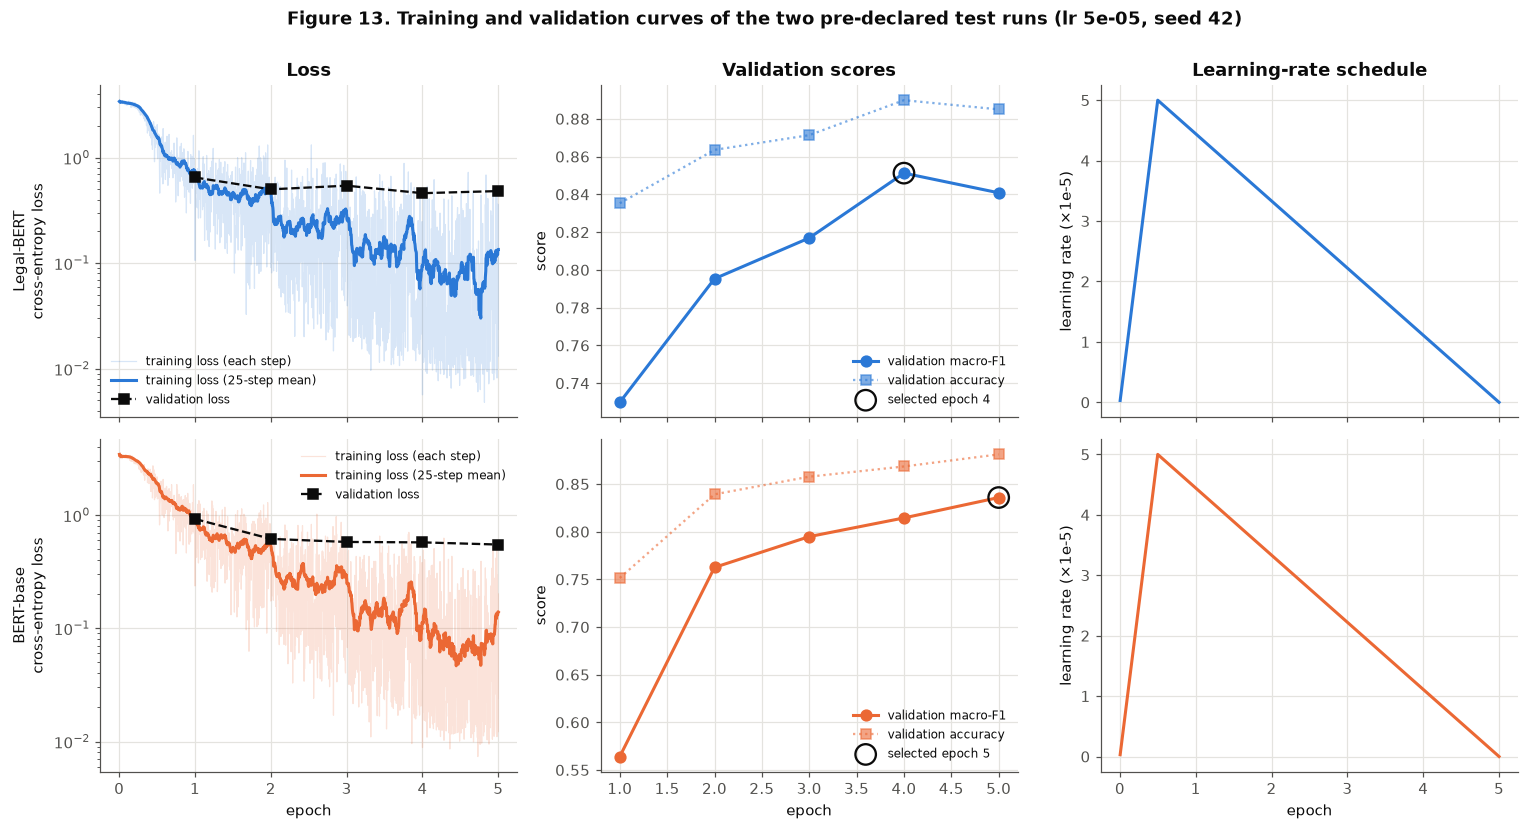

,run_id,epoch,train_loss,val_loss,val_macro_f1,val_accuracy,epoch_train_seconds
3673,legalbert_lr5e-05_s42,1,1.7845,0.6481,0.7299,0.8353,17.0461
4007,legalbert_lr5e-05_s42,2,0.4647,0.5004,0.7953,0.8635,16.5540
4341,legalbert_lr5e-05_s42,3,0.2384,0.5421,0.8169,0.8713,16.8206
4675,legalbert_lr5e-05_s42,4,0.1395,0.4602,0.8512,0.8899,16.7560
5009,legalbert_lr5e-05_s42,5,0.0862,0.4819,0.8408,0.8850,16.9308
8683,bert_lr5e-05_s42,1,1.9491,0.9239,0.5641,0.7515,16.9902
9017,bert_lr5e-05_s42,2,0.5760,0.6165,0.7625,0.8392,16.9251
9351,bert_lr5e-05_s42,3,0.2705,0.5793,0.7948,0.8577,16.8500
9685,bert_lr5e-05_s42,4,0.1415,0.5743,0.8144,0.8684,17.1123
10019,bert_lr5e-05_s42,5,0.0798,0.5495,0.8358,0.8811,16.8655


In [44]:
TEST_RUNS = choice["test_runs"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex="col")
for r, (key, name, col) in enumerate([("legalbert", "Legal-BERT", PL.BLUE), ("bert", "BERT-base", PL.ORANGE)]):
    rid = TEST_RUNS[key]
    st = tlog[(tlog.run_id == rid) & (tlog.kind == "step")]
    ep = tlog[(tlog.run_id == rid) & (tlog.kind == "epoch")]
    spe = int(ep.step.iloc[0])
    ax = axes[r, 0]
    ax.plot(st.step / spe, st.train_loss, color=col, alpha=0.18, linewidth=0.8, label="training loss (each step)")
    ax.plot(st.step / spe, st.train_loss.rolling(25, min_periods=1).mean(), color=col, linewidth=2,
            label="training loss (25-step mean)")
    ax.plot(ep.epoch, ep.val_loss, "s--", color=PL.INK, markersize=7, linewidth=1.5, label="validation loss")
    ax.set_ylabel(f"{name}\ncross-entropy loss"); ax.set_yscale("log"); ax.legend(fontsize=8)
    ax = axes[r, 1]
    ax.plot(ep.epoch, ep.val_macro_f1, "o-", color=col, linewidth=2, markersize=7, label="validation macro-F1")
    ax.plot(ep.epoch, ep.val_accuracy, "s:", color=col, alpha=0.6, linewidth=1.5, label="validation accuracy")
    be = ep.loc[ep.val_macro_f1.idxmax()]
    ax.scatter([be.epoch], [be.val_macro_f1], s=180, facecolors="none", edgecolors=PL.INK, linewidths=1.5, zorder=4,
               label=f"selected epoch {int(be.epoch)}")
    ax.set_ylabel("score"); ax.legend(fontsize=8, loc="lower right")
    ax = axes[r, 2]
    ax.plot(st.step / spe, st.lr * 1e5, color=col, linewidth=2)
    ax.set_ylabel("learning rate (×1e-5)")
for ax in axes[1]:
    ax.set_xlabel("epoch")
axes[0, 0].set_title("Loss"); axes[0, 1].set_title("Validation scores"); axes[0, 2].set_title("Learning-rate schedule")
fig.suptitle(f"Figure 13. Training and validation curves of the two pre-declared test runs "
             f"(lr {choice['best_lr']:.0e}, seed 42)", fontweight="bold", y=1.0)
fig.tight_layout(); PL.savefig(fig, 13, "transformer_curves"); plt.show()
display(tlog[(tlog.run_id.isin(TEST_RUNS.values())) & (tlog.kind == "epoch")]
        [["run_id", "epoch", "train_loss", "val_loss", "val_macro_f1", "val_accuracy", "epoch_train_seconds"]].round(4))

**Interpretation of the curves (Figure 13).**
* **Warm-up.** During roughly the first half epoch the training loss stays near 3.3 — ln 27, the loss of guessing uniformly
  among 27 classes — while the learning rate ramps up from 0; once the rate is high enough the loss drops steeply. The
  warm-up let the randomly initialised classification layer settle before large updates reached the pre-trained layers.
* **Fit and generalisation.** Legal-BERT's mean training loss falls from 1.78 (epoch 1) to 0.09 (epoch 5), while its
  validation loss levels off after epoch 2 (0.50 → 0.46–0.54): the model fits the training clauses almost perfectly and its
  *confidence* stops improving on validation. Its decisions still improve until epoch 4 (validation macro-F1 0.730 → 0.795
  → 0.817 → **0.851**) and then drop slightly at epoch 5 (0.841) — the first sign of over-fitting, so epoch 4 is selected.
* **BERT-base learns more slowly:** after one epoch it reaches 0.564 validation macro-F1 against Legal-BERT's 0.730, its
  validation loss is higher at every epoch (0.55 at the end vs 0.46–0.48), and it is still improving at epoch 5 (0.814 →
  0.836), so it might gain slightly from more epochs. Starting from a legal-domain model means less has to be learnt during
  fine-tuning.

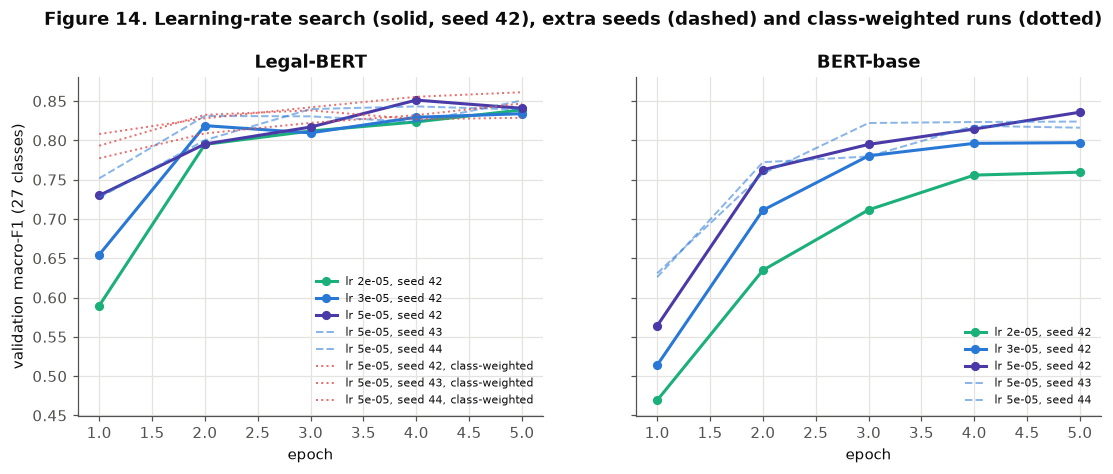

Validation macro-F1 over 3 seeds at lr 5e-05 (best epoch of each run):


mean     std     min     max  count
model     class_weighted                                       
bert      False           0.8261  0.0089  0.8185  0.8358      3
legalbert False           0.8484  0.0045  0.8432  0.8512      3
          True            0.8488  0.0117  0.8381  0.8612      3

Class-weighted loss: 3-seed mean gain +0.0004 vs seed spread 0.0080 -> adopted: False


In [45]:
# Learning-rate search, seed variation and the class-weighted runs (validation macro-F1 per epoch)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (key, name) in zip(axes, [("legalbert", "Legal-BERT"), ("bert", "BERT-base")]):
    for _, r in tsearch[tsearch.model == key].iterrows():
        ep = tlog[(tlog.run_id == r.run_id) & (tlog.kind == "epoch")]
        if r.class_weighted:
            style, color, lw, alpha = ":", PL.RED, 1.3, 0.8
        elif r.seed == 42:
            style, color, lw, alpha = "o-", {2e-5: PL.AQUA, 3e-5: PL.BLUE, 5e-5: PL.VIOLET}[r.lr], 2, 1
        else:
            style, color, lw, alpha = "--", PL.BLUE, 1.3, 0.55
        ax.plot(ep.epoch, ep.val_macro_f1, style, color=color, alpha=alpha, linewidth=lw, markersize=5,
                label=f"lr {r.lr:.0e}, seed {r.seed}" + (", class-weighted" if r.class_weighted else ""))
    ax.set_title(name); ax.set_xlabel("epoch"); ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("validation macro-F1 (27 classes)")
fig.suptitle("Figure 14. Learning-rate search (solid, seed 42), extra seeds (dashed) and class-weighted runs (dotted)",
             fontweight="bold", y=1.03)
PL.savefig(fig, 14, "transformer_lr_seeds"); plt.show()

seed_tab = (tsearch[(tsearch.lr == choice["best_lr"])]
            .groupby(["model", "class_weighted"]).val_macro_f1.agg(["mean", "std", "min", "max", "count"]))
print(f"Validation macro-F1 over 3 seeds at lr {choice['best_lr']:.0e} (best epoch of each run):")
display(seed_tab.round(4))
seed_tab.to_csv(C.RESULTS_DIR / "transformer_seeds.csv")
print(f"Class-weighted loss: 3-seed mean gain {choice['class_weighted_gain']:+.4f} vs seed spread "
      f"{choice['seed_spread']:.4f} -> adopted: {choice['use_class_weights']}")

**Interpretation (Figure 14, seed table, `results/transformer_choice.json`).**
* **Learning rate.** Both models were best at **5e-5**, the top of the range recommended by Devlin et al. (2019): Legal-BERT
  0.839 / 0.834 / **0.851** and BERT-base 0.760 / 0.797 / **0.836** at 2e-5 / 3e-5 / 5e-5. BERT-base is much more sensitive to
  the rate. Because the best value is at the edge of the searched range, a slightly higher rate might be better still; we
  kept the recommended range and state this as a limitation.
* **Seeds.** At 5e-5, Legal-BERT scores **0.848 ± 0.004** and BERT-base **0.826 ± 0.009** on validation (mean ± sd over 3
  seeds). Every Legal-BERT seed (lowest 0.843) beats every BERT-base seed (highest 0.836). The pre-declared test run (seed 42)
  is the best of its three Legal-BERT seeds on validation (0.851), so its single validation number is slightly optimistic; the
  3-seed mean is the fairer validation estimate.
* **Class-weighted loss — not adopted.** Over the same 3 seeds it scored 0.849 ± 0.012 against 0.848 ± 0.004 unweighted: a
  mean gain of **+0.0004**, far below the seed spread of 0.008 (and the 0.003 minimum). It also made results *less* stable
  (sd 0.012 vs 0.004). Unlike the linear models, the fine-tuned transformer does not need re-weighting for these classes.

### 5.6 Test evaluation (once) and computational budget
The two pre-declared runs (seed 42, chosen recipe, best validation epoch) are now scored on the test set once each. If
the saved weights are not available (e.g. on Colab without re-training), the saved test predictions are loaded instead.
We also measure inference speed on the GPU and on the CPU, and the model size on disk.

In [46]:
TEST_NAMES = {"legalbert": "legalbert", "bert": "bert_base"}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
label2id = {l: i for i, l in enumerate(LABELS)}
budget_json = C.RESULTS_DIR / "transformer_budget.json"
budget_info = json.load(open(budget_json)) if budget_json.exists() else {}
tf_test_pred = {}
for key, name in TEST_NAMES.items():
    rid = TEST_RUNS[key]
    wdir = F.MODELS_DIR / rid / "best"
    if wdir.exists():
        tok, mdl = F.load_best(rid, device)
        items = F.encode(tok, list(test.text), list(test.category), label2id, F.RECIPE["max_length"])
        _, pred_ids, gpu_s = F.predict(mdl, F.make_loader(items, tok, 64, shuffle=False), device)
        preds = [LABELS[i] for i in pred_ids]
        if name not in budget_info:      # timings of the real test run are kept, not overwritten by re-runs
            torch.set_num_threads(os.cpu_count())
            cpu_mdl = mdl.float().to("cpu")
            _, _, cpu_s = F.predict(cpu_mdl, F.make_loader(items[:200], tok, 16, shuffle=False), torch.device("cpu"))
            size_mb = sum(f.stat().st_size for f in wdir.glob("*") if f.is_file()) / 1e6
            run = tsearch.set_index("run_id").loc[rid]
            budget_info[name] = {
                "run_id": rid, "params_million": float(run.params_million), "best_epoch": int(run.best_epoch),
                "train_seconds_run": float(run.run_seconds), "mean_epoch_seconds": float(run.mean_epoch_seconds),
                "peak_gpu_mem_gb_train": float(run.peak_gpu_mem_gb), "model_size_mb": size_mb,
                "gpu_test_seconds": gpu_s, "gpu_clauses_per_second": len(test) / gpu_s,
                "gpu_ms_per_clause": 1000 * gpu_s / len(test),
                "cpu_clauses_per_second": 200 / cpu_s, "cpu_ms_per_clause": 1000 * cpu_s / 200,
                "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
            del cpu_mdl
        del mdl; torch.cuda.empty_cache()
        tf_test_pred[key] = preds
        C.test_once(name, {"run_id": rid, "recipe": F.RECIPE, "lr": choice["best_lr"], "seed": 42,
                           "class_weighted": choice["use_class_weights"],
                           "best_epoch": int(tsearch.set_index("run_id").loc[rid].best_epoch)},
                    test.category, preds, LABELS, test.row_id, test.contract, ROBUST)
    else:
        print(f"{name}: weights not found ({wdir}); using the saved test predictions.")
        tf_test_pred[key] = pd.read_csv(C.RESULTS_DIR / "predictions" / f"{name}.csv").pred.tolist()
json.dump(budget_info, open(budget_json, "w"), indent=2)

btab = pd.DataFrame(budget_info).T[["params_million", "best_epoch", "mean_epoch_seconds", "train_seconds_run",
                                    "peak_gpu_mem_gb_train", "model_size_mb", "gpu_clauses_per_second",
                                    "gpu_ms_per_clause", "cpu_clauses_per_second", "cpu_ms_per_clause"]]
display(btab.astype(float).round(2))

[test] legalbert: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.


[test] bert_base: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.


,params_million,best_epoch,mean_epoch_seconds,train_seconds_run,peak_gpu_mem_gb_train,model_size_mb,gpu_clauses_per_second,gpu_ms_per_clause,cpu_clauses_per_second,cpu_ms_per_clause
legalbert,109.5,4.0,16.82,94.25,3.69,438.74,1027.88,0.97,19.30,51.80
bert_base,109.5,5.0,16.95,95.06,3.69,438.75,1125.10,0.89,20.08,49.81


In [47]:
# Log the budget of the two test models in results/compute_budget.csv (once)
budget = pd.read_csv(C.RESULTS_DIR / "compute_budget.csv")
for name, b in budget_info.items():
    if not ((budget.model == name) & (budget.stage == "train_final")).any():
        new = pd.DataFrame([
            {"timestamp": pd.Timestamp.now().isoformat(timespec="seconds"), "model": name, "stage": "train_final",
             "seconds": round(b["train_seconds_run"], 2), "device": b["gpu"],
             "notes": f"5 epochs incl. validation; best epoch {b['best_epoch']}; peak {b['peak_gpu_mem_gb_train']:.1f} GB"},
            {"timestamp": pd.Timestamp.now().isoformat(timespec="seconds"), "model": name, "stage": "inference_test_gpu",
             "seconds": round(b["gpu_test_seconds"], 2), "device": b["gpu"],
             "notes": f"{len(test):,} test clauses, batch 64, bf16"}])
        budget = pd.concat([budget, new], ignore_index=True)
budget.to_csv(C.RESULTS_DIR / "compute_budget.csv", index=False)
plan_rows = budget[budget.model == "transformer_plan"]
if len(plan_rows):
    print(f"Whole transformer plan ({len(tsearch)} runs, both checkpoints): {plan_rows.seconds.iloc[0] / 60:.1f} min "
          f"wall-clock on {plan_rows.device.iloc[0]}")

Whole transformer plan (13 runs, both checkpoints): 21.0 min wall-clock on NVIDIA GeForce RTX 5080


### 5.7 Results: Legal-BERT vs BERT-base vs the best classical model
Confidence intervals and paired differences use the contract-level bootstrap of section 2.8 (point estimate over all 27
classes; in each resample, macro-F1 over the classes present). The best classical model is the one selected on
validation in section 4 (`results/classical_best.json`).

In [48]:
best_classical = json.load(open(C.RESULTS_DIR / "classical_best.json"))["best_classical"]
METRICS = json.load(open(C.RESULTS_DIR / "metrics.json"))
cls_pred = pd.read_csv(C.RESULTS_DIR / "predictions" / f"{best_classical}.csv").pred.values
y, grp = test.category.values, test.contract.values
PRED = {best_classical: cls_pred, "bert_base": np.array(tf_test_pred["bert"]), "legalbert": np.array(tf_test_pred["legalbert"])}
rows = []
for name, label in [(best_classical, "best classical (TF-IDF char n-grams + LogReg)"), ("bert_base", "BERT-base (ablation)"),
                    ("legalbert", "Legal-BERT (main)")]:
    ci = C.bootstrap_ci(y, PRED[name], grp, labels=LABELS, n_boot=1000)
    cir = C.bootstrap_ci(y, PRED[name], grp, labels=ROBUST, n_boot=1000)
    m = METRICS[f"{name}__test"]
    rows.append({"model": name, "description": label, "test_macro_f1": m["macro_f1"],
                 "95% CI": f"[{ci['ci_low']:.3f}, {ci['ci_high']:.3f}]",
                 f"macro_f1_robust_{len(ROBUST)}": m["macro_f1_robust"], "robust 95% CI": f"[{cir['ci_low']:.3f}, {cir['ci_high']:.3f}]",
                 "test_accuracy": m["accuracy"], "test_weighted_f1": m["weighted_f1"]})
cmp_tab = pd.DataFrame(rows)
cmp_tab.to_csv(C.RESULTS_DIR / "transformer_vs_classical.csv", index=False)
display(cmp_tab.round(4))

pairs = {"H1_legalbert_vs_best_classical": ("legalbert", best_classical),
         "ablation_legalbert_vs_bert_base": ("legalbert", "bert_base"),
         "bert_base_vs_best_classical": ("bert_base", best_classical)}
comparison = {}
for key, (a, b) in pairs.items():
    comparison[key] = {"all_27": C.paired_bootstrap(y, PRED[a], PRED[b], grp, labels=LABELS, n_boot=1000),
                       f"robust_{len(ROBUST)}": C.paired_bootstrap(y, PRED[a], PRED[b], grp, labels=ROBUST, n_boot=1000)}
    for which, pb in comparison[key].items():
        print(f"{a} - {b} ({which}): {pb['diff']:+.4f}, 95 % CI [{pb['ci_low']:+.4f}, {pb['ci_high']:+.4f}], "
              f"share of resamples where {a} is not better: {pb['p_a_not_better']:.3f}")
h1 = comparison["H1_legalbert_vs_best_classical"]["all_27"]
print(f"\nH1 (objective O3): Legal-BERT > best TF-IDF -> {'SUPPORTED' if h1['ci_low'] > 0 else 'NOT supported'} "
      "(the 95 % CI of the difference must lie above 0)")
json.dump(comparison, open(C.RESULTS_DIR / "transformer_comparison.json", "w"), indent=2)

,model,description,test_macro_f1,95% CI,macro_f1_robust_24,robust 95% CI,test_accuracy,test_weighted_f1
0,tfidf_logreg,best classical (TF-IDF char n-grams + LogReg),0.7939,"[0.752, 0.824]",0.7962,"[0.761, 0.825]",0.8289,0.8300
1,bert_base,BERT-base (ablation),0.8256,"[0.796, 0.857]",0.8302,"[0.799, 0.858]",0.8615,0.8600
2,legalbert,Legal-BERT (main),0.8708,"[0.836, 0.896]",0.8661,"[0.838, 0.892]",0.8906,0.8897


legalbert - tfidf_logreg (all_27): +0.0769, 95 % CI [+0.0471, +0.1100], share of resamples where legalbert is not better: 0.000
legalbert - tfidf_logreg (robust_24): +0.0698, 95 % CI [+0.0440, +0.1022], share of resamples where legalbert is not better: 0.000


legalbert - bert_base (all_27): +0.0452, 95 % CI [+0.0177, +0.0640], share of resamples where legalbert is not better: 0.000
legalbert - bert_base (robust_24): +0.0359, 95 % CI [+0.0153, +0.0568], share of resamples where legalbert is not better: 0.000


bert_base - tfidf_logreg (all_27): +0.0317, 95 % CI [+0.0073, +0.0641], share of resamples where bert_base is not better: 0.007
bert_base - tfidf_logreg (robust_24): +0.0339, 95 % CI [+0.0128, +0.0596], share of resamples where bert_base is not better: 0.003

H1 (objective O3): Legal-BERT > best TF-IDF -> SUPPORTED (the 95 % CI of the difference must lie above 0)


In [49]:
# Controlled ablation table -> results/ablation.csv
tl = json.load(open(C.RESULTS_DIR / "token_lengths.json"))
seeds = pd.read_csv(C.RESULTS_DIR / "transformer_seeds.csv")
seeds = seeds[seeds.class_weighted == choice["use_class_weights"]].set_index("model")
abl = comparison["ablation_legalbert_vs_bert_base"]["all_27"]
abl_rows = []
for key, name, tk in [("legalbert", "Legal-BERT", "Legal-BERT"), ("bert", "BERT-base", "BERT-base")]:
    r42 = tsearch.set_index("run_id").loc[TEST_RUNS[key]]
    m = METRICS[f"{TEST_NAMES[key]}__test"]
    abl_rows.append({"model": name, "checkpoint": F.CHECKPOINTS[key], "lr": f"{choice['best_lr']:.0e}",
                     "class_weighted": choice["use_class_weights"],
                     "val_macro_f1_seed42": r42.val_macro_f1, "val_macro_f1_3seeds_mean": seeds.loc[key, "mean"],
                     "val_macro_f1_3seeds_std": seeds.loc[key, "std"], "test_macro_f1": m["macro_f1"],
                     "test_macro_f1_robust": m["macro_f1_robust"], "test_accuracy": m["accuracy"],
                     "mean_tokens_per_clause": tl["stats"][tk]["mean"]})
ablation = pd.DataFrame(abl_rows)
diff_row = {"model": "difference (Legal-BERT - BERT-base)",
            "val_macro_f1_seed42": ablation.val_macro_f1_seed42[0] - ablation.val_macro_f1_seed42[1],
            "val_macro_f1_3seeds_mean": ablation.val_macro_f1_3seeds_mean[0] - ablation.val_macro_f1_3seeds_mean[1],
            "test_macro_f1": abl["diff"], "test_macro_f1_diff_95ci": f"[{abl['ci_low']:.4f}, {abl['ci_high']:.4f}]",
            "test_macro_f1_robust": ablation.test_macro_f1_robust[0] - ablation.test_macro_f1_robust[1],
            "test_accuracy": ablation.test_accuracy[0] - ablation.test_accuracy[1],
            "mean_tokens_per_clause": ablation.mean_tokens_per_clause[0] - ablation.mean_tokens_per_clause[1]}
ablation = pd.concat([ablation, pd.DataFrame([diff_row])], ignore_index=True)
ablation.to_csv(C.RESULTS_DIR / "ablation.csv", index=False)
bert_own = tsearch[(tsearch.model == "bert") & (tsearch.seed == 42) & (~tsearch.class_weighted)].sort_values(
    "val_macro_f1", ascending=False).iloc[0]
print(f"Sensitivity check: BERT-base's own best LR on validation is {bert_own.lr:.0e} (val macro-F1 "
      f"{bert_own.val_macro_f1:.4f}); at the shared LR {choice['best_lr']:.0e} it scores "
      f"{tsearch[(tsearch.model == 'bert') & (tsearch.seed == 42) & (tsearch.lr == choice['best_lr']) & (~tsearch.class_weighted)].val_macro_f1.iloc[0]:.4f}.")
ablation.round(4)

Sensitivity check: BERT-base's own best LR on validation is 5e-05 (val macro-F1 0.8358); at the shared LR 5e-05 it scores 0.8358.


,model,checkpoint,lr,class_weighted,val_macro_f1_seed42,val_macro_f1_3seeds_mean,val_macro_f1_3seeds_std,test_macro_f1,test_macro_f1_robust,test_accuracy,mean_tokens_per_clause,test_macro_f1_diff_95ci
0,Legal-BERT,nlpaueb/legal-bert-base-uncased,5e-05,False,0.8512,0.8484,0.0045,0.8708,0.8661,0.8906,69.2804,NaN
1,BERT-base,bert-base-uncased,5e-05,False,0.8358,0.8261,0.0089,0.8256,0.8302,0.8615,70.5899,NaN
2,difference (Legal-BERT - BERT-base),NaN,NaN,NaN,0.0154,0.0223,NaN,0.0452,0.0359,0.0291,-1.3094,"[0.0177, 0.0640]"


**Interpretation of the results (each model scored on test once; `results/test_eval_log.csv`).**
* **Legal-BERT is the best Task 1 model so far:** test macro-F1 **0.871** (95 % CI 0.836–0.896), robustness macro-F1 over 24
  classes 0.866, accuracy 0.891.
* **Objective O3, hypothesis H1 — supported.** Legal-BERT beats the best classical model (TF-IDF character n-grams + Logistic
  Regression, 0.794) by **+0.077**, paired contract-level bootstrap 95 % CI **[+0.047, +0.110]** (robustness set: +0.070
  [+0.044, +0.102]); no resample favoured the classical model. The cost and latency part of O3 is completed by the LLM comparison.
* **Controlled ablation — legal-domain pre-training helps.** With everything else identical (architecture, size, recipe,
  learning rate, seed, split, metric), Legal-BERT beats BERT-base by **+0.045** test macro-F1, CI **[+0.018, +0.064]**
  (robustness set +0.036 [+0.015, +0.057]); on validation +0.015 for seed 42 and +0.022 on the 3-seed means. The shared
  learning rate (5e-5) is also BERT-base's own best rate, so the comparison is not tilted by tuning for Legal-BERT.
* **General pre-training alone also helps:** even BERT-base beats the best classical model (+0.032, CI [+0.007, +0.064]).
* **What the ablation cannot say.** Legal-BERT differs from BERT-base in its pre-training *corpus* **and** its *vocabulary*, so
  +0.045 is their combined effect. Clause length is not the explanation: the two tokenizers give almost the same number of
  tokens per clause (69.3 vs 70.6) and truncate under 1 % of clauses. A possible overlap between Legal-BERT's EDGAR
  pre-training text and CUAD contracts could contribute and cannot be checked.
* **Computational budget** (RTX 5080; table above, `results/compute_budget.csv`): one 5-epoch run takes about 95 s (17 s per
  epoch, peak 3.7 GB GPU memory); the whole 13-run plan took 21.0 min. The model has 109.5 M parameters and needs 439 MB on
  disk. Inference: about 1,030 clauses/s on the GPU (1.0 ms per clause) and 19 clauses/s on the CPU (52 ms per clause).
  The best classical model refits in seconds on the CPU, so the transformer costs far more compute, though it is still small
  in absolute terms for this dataset.

### 5.8 Per-class analysis (27 classes)
Per-class test F1 with contract-level bootstrap CIs for Legal-BERT, BERT-base and the best classical model; a focus
table for the 7 classes that are new in the 27-class design and for Exclusivity (the class with the lowest recall so
far); objective O5 (recall ≥ 0.70 for every class); and the effect of class size on F1.

,best classical,BERT-base,Legal-BERT,Legal-BERT CI,Legal-BERT recall,Legal-BERT - classical,Legal-BERT - BERT-base,test clauses,new class
Non-Transferable License,0.634,0.541,0.611,"[0.32, 0.80]",0.579,-0.023,0.071,19,yes
Change Of Control,0.717,0.689,0.721,"[0.58, 0.82]",0.633,0.004,0.032,49,
Exclusivity,0.549,0.605,0.738,"[0.62, 0.84]",0.705,0.189,0.133,44,
Competitive Restriction Exception,0.611,0.562,0.757,"[0.62, 0.89]",0.824,0.146,0.194,17,yes
Ip Ownership Assignment,0.777,0.755,0.808,"[0.69, 0.91]",0.750,0.031,0.053,56,
Liquidated Damages,0.632,0.769,0.810,"[0.65, 0.90]",0.810,0.178,0.040,21,yes
Post-Termination Services,0.716,0.748,0.838,"[0.77, 0.91]",0.814,0.122,0.090,70,
Anti-Assignment,0.874,0.849,0.846,"[0.77, 0.92]",0.884,-0.028,-0.003,121,
Rofr/Rofo/Rofn,0.800,0.825,0.848,"[0.71, 0.93]",0.855,0.048,0.023,62,
License Grant,0.748,0.837,0.849,"[0.77, 0.90]",0.859,0.100,0.012,85,


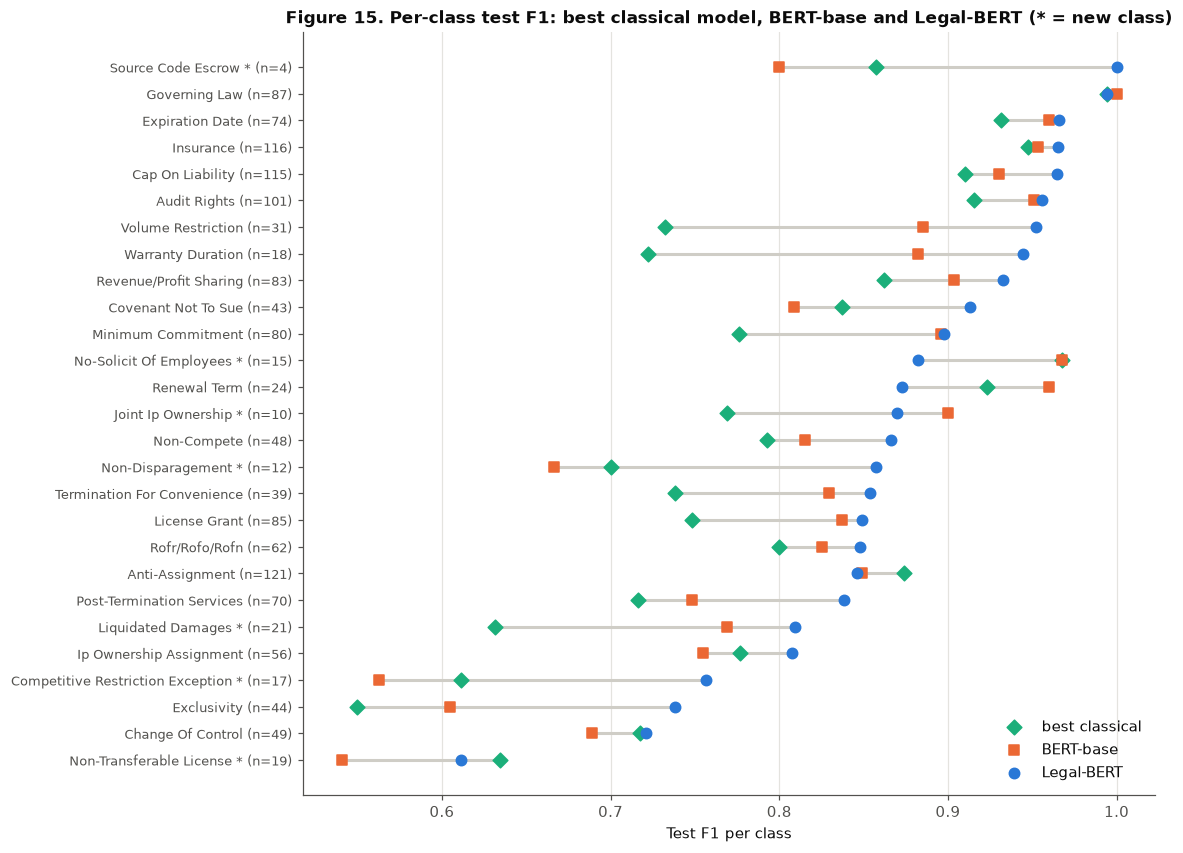

In [50]:
pcs = {}
for name in [best_classical, "bert_base", "legalbert"]:
    pc_ = C.per_class_bootstrap_ci(y, PRED[name], grp, LABELS, n_boot=1000)
    pc_["recall"] = pd.DataFrame(METRICS[f"{name}__test"]["per_class"]).T.recall
    pcs[name] = pc_
pcf = pd.DataFrame({n: pcs[n].f1 for n in pcs}).rename(columns={best_classical: "best classical", "bert_base": "BERT-base",
                                                                  "legalbert": "Legal-BERT"})
pcf["Legal-BERT CI"] = [("n/a (1 contract)" if pd.isna(l) else f"[{l:.2f}, {h:.2f}]")
                        for l, h in zip(pcs["legalbert"].ci_low, pcs["legalbert"].ci_high)]
pcf["Legal-BERT recall"] = pcs["legalbert"].recall
pcf["Legal-BERT - classical"] = pcf["Legal-BERT"] - pcf["best classical"]
pcf["Legal-BERT - BERT-base"] = pcf["Legal-BERT"] - pcf["BERT-base"]
pcf["test clauses"] = pcs["legalbert"].support
pcf["new class"] = ["yes" if c in NEW_CLASSES else "" for c in pcf.index]
pcf = pcf.sort_values("Legal-BERT")
pcf.to_csv(C.RESULTS_DIR / "per_class_f1_models.csv")
display(pcf.round(3))

fig, ax = plt.subplots(figsize=(10, 9))
yy = np.arange(len(pcf))
ax.hlines(yy, pcf[["best classical", "BERT-base", "Legal-BERT"]].min(axis=1),
          pcf[["best classical", "BERT-base", "Legal-BERT"]].max(axis=1), color="#cfcdc6", linewidth=2, zorder=1)
for lab, col, mk in [("best classical", PL.AQUA, "D"), ("BERT-base", PL.ORANGE, "s"), ("Legal-BERT", PL.BLUE, "o")]:
    ax.scatter(pcf[lab], yy, color=col, marker=mk, s=46, label=lab, zorder=3)
ax.set_yticks(yy)
ax.set_yticklabels([f"{c}{' *' if c in NEW_CLASSES else ''} (n={n})" for c, n in zip(pcf.index, pcf["test clauses"])], fontsize=8.5)
ax.set_xlabel("Test F1 per class"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Figure 15. Per-class test F1: best classical model, BERT-base and Legal-BERT (* = new class)", fontsize=11)
PL.savefig(fig, 15, "per_class_f1_models"); plt.show()

In [51]:
# Focus: the 7 new classes and Exclusivity
focus = NEW_CLASSES + ["Exclusivity"]
foc = pd.DataFrame({
    "test clauses": pcs["legalbert"].support[focus], "test contracts": pcs["legalbert"].test_contracts[focus],
    "classical F1": pcs[best_classical].f1[focus], "BERT-base F1": pcs["bert_base"].f1[focus],
    "Legal-BERT F1": pcs["legalbert"].f1[focus],
    "Legal-BERT 95% CI": [("n/a (1 contract)" if pd.isna(l) else f"[{l:.2f}, {h:.2f}]")
                          for l, h in zip(pcs["legalbert"].ci_low[focus], pcs["legalbert"].ci_high[focus])],
    "classical recall": pcs[best_classical].recall[focus], "Legal-BERT recall": pcs["legalbert"].recall[focus]})
foc["best of the three"] = foc[["classical F1", "BERT-base F1", "Legal-BERT F1"]].idxmax(axis=1).str.replace(" F1", "")
foc.to_csv(C.RESULTS_DIR / "per_class_focus_new_classes.csv")
display(foc.round(3))

def confusions_of(name, cls):
    t = pd.Series(PRED[name][y == cls]).value_counts()
    return ", ".join(f"{k} {v}" for k, v in t.items() if k != cls) or "none"
print("Where the clauses of each focus class go (Legal-BERT, test):")
for c in focus:
    print(f"  {c:<34} -> {confusions_of('legalbert', c)}")

,test clauses,test contracts,classical F1,BERT-base F1,Legal-BERT F1,Legal-BERT 95% CI,classical recall,Legal-BERT recall,best of the three
Competitive Restriction Exception,17,11,0.611,0.562,0.757,"[0.62, 0.89]",0.647,0.824,Legal-BERT
Joint Ip Ownership,10,5,0.769,0.900,0.870,"[0.57, 1.00]",1.000,1.000,BERT-base
Liquidated Damages,21,14,0.632,0.769,0.810,"[0.65, 0.90]",0.571,0.810,Legal-BERT
No-Solicit Of Employees,15,10,0.968,0.968,0.882,"[0.72, 1.00]",1.000,1.000,classical
Non-Disparagement,12,7,0.700,0.667,0.857,"[0.67, 1.00]",0.583,0.750,Legal-BERT
Non-Transferable License,19,11,0.634,0.541,0.611,"[0.32, 0.80]",0.684,0.579,classical
Source Code Escrow,4,1,0.857,0.800,1.000,n/a (1 contract),0.750,1.000,Legal-BERT
Exclusivity,44,27,0.549,0.605,0.738,"[0.62, 0.84]",0.568,0.705,Legal-BERT


Where the clauses of each focus class go (Legal-BERT, test):
  Competitive Restriction Exception  -> Exclusivity 1, Non-Compete 1, Audit Rights 1
  Joint Ip Ownership                 -> none
  Liquidated Damages                 -> Post-Termination Services 3, Rofr/Rofo/Rofn 1
  No-Solicit Of Employees            -> none
  Non-Disparagement                  -> Termination For Convenience 1, License Grant 1, No-Solicit Of Employees 1
  Non-Transferable License           -> Anti-Assignment 6, Change Of Control 1, Exclusivity 1
  Source Code Escrow                 -> none
  Exclusivity                        -> License Grant 6, Non-Compete 3, Covenant Not To Sue 1, Minimum Commitment 1, Competitive Restriction Exception 1, Insurance 1


Legal-BERT classes with test recall < 0.70: 2 -> Non-Transferable License 0.58, Change Of Control 0.63
Objective O5 for Legal-BERT: NOT MET


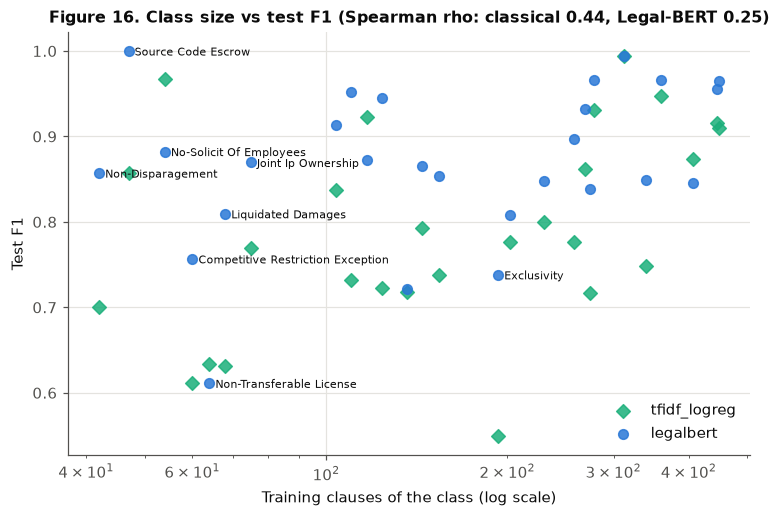

In [52]:
# Objective O5 (recall >= 0.70 for every class) and the effect of class size
lb_rec = pcs["legalbert"].recall
below = lb_rec[lb_rec < 0.70].sort_values()
print(f"Legal-BERT classes with test recall < 0.70: {len(below)} -> " + (", ".join(f"{k} {v:.2f}" for k, v in below.items()) or "none"))
print("Objective O5 for Legal-BERT:", "MET" if below.empty else "NOT MET")
json.dump({"model": "legalbert", "classes_below_0.70_recall": below.round(4).to_dict(), "O5_met": bool(below.empty)},
          open(C.RESULTS_DIR / "objective_O5_legalbert.json", "w"), indent=2)

ntrain = train.category.value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
for name, col, mk in [(best_classical, PL.AQUA, "D"), ("legalbert", PL.BLUE, "o")]:
    ax.scatter(ntrain[LABELS], pcs[name].f1[LABELS], color=col, marker=mk, s=40, label=name, alpha=0.85)
for c in focus:
    ax.annotate(c, (ntrain[c], pcs["legalbert"].f1[c]), fontsize=7, xytext=(4, -3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("Training clauses of the class (log scale)"); ax.set_ylabel("Test F1")
ax.legend(loc="lower right")
from scipy.stats import spearmanr
rho = {n: spearmanr(ntrain[LABELS], pcs[n].f1[LABELS]).correlation for n in [best_classical, "legalbert"]}
ax.set_title(f"Figure 16. Class size vs test F1 (Spearman rho: classical {rho[best_classical]:.2f}, Legal-BERT {rho['legalbert']:.2f})",
             fontsize=10.5)
PL.savefig(fig, 16, "class_size_vs_f1"); plt.show()
json.dump(rho, open(C.RESULTS_DIR / "class_size_vs_f1_spearman.json", "w"), indent=2)

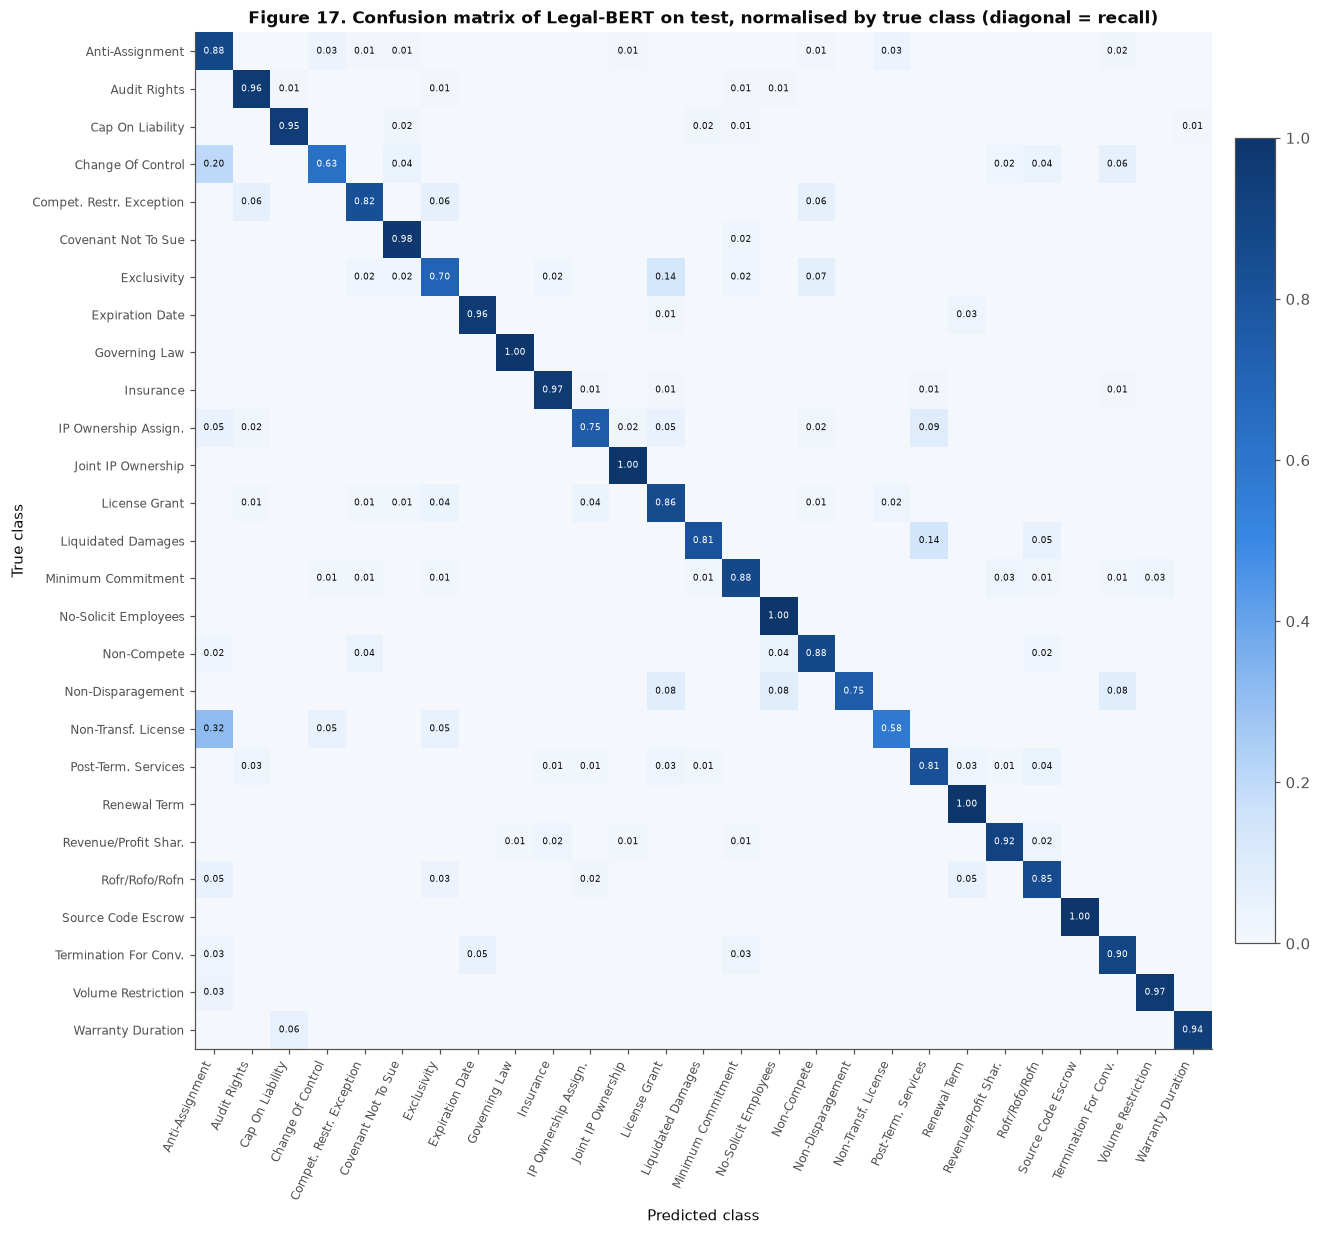

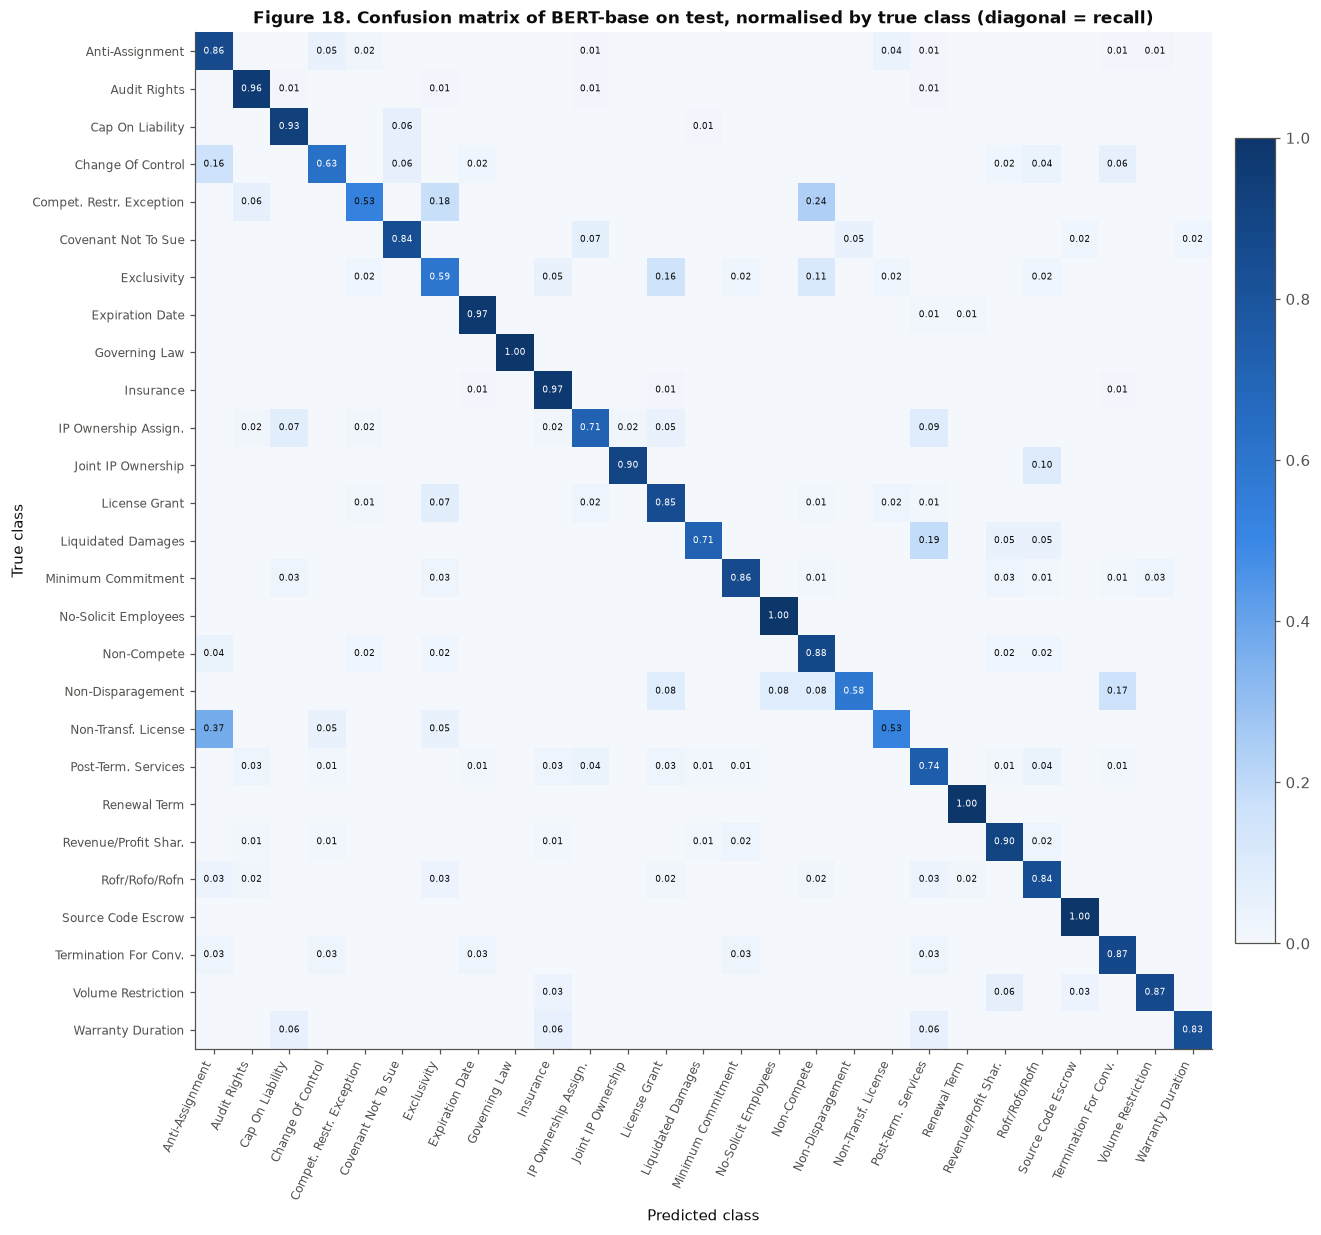

In [53]:
for key, name, num, title in [("legalbert", "legalbert", 17, "Legal-BERT"), ("bert", "bert_base", 18, "BERT-base")]:
    cmx = np.array(METRICS[f"{name}__test"]["confusion_matrix"])
    plot_cm(cmx / cmx.sum(axis=1, keepdims=True), ".2f",
            f"Figure {num}. Confusion matrix of {title} on test, normalised by true class (diagonal = recall)",
            num, f"cm_{name}_normalised", vmax=1)

**Interpretation of the per-class analysis (`results/per_class_f1_models.csv`, `results/per_class_focus_new_classes.csv`).**
* **Legal-BERT is better than the best classical model on 23 of the 27 classes** and better than BERT-base on 22. The largest
  gains over the classical model are on classes defined by legal concepts rather than fixed phrases: Warranty Duration
  (+0.22), Volume Restriction (+0.22), **Exclusivity (+0.19)**, Liquidated Damages (+0.18), Non-Disparagement (+0.16) and
  Competitive Restriction Exception (+0.15).
* **Exclusivity**, the weakest class of the classical model (F1 0.549, recall 0.57), rises to **F1 0.738, recall 0.70**. Its
  remaining errors are the expected ones: 6 clauses predicted as License Grant ("exclusive licence") and 3 as Non-Compete.
* **The 7 new classes:** Legal-BERT is best for Competitive Restriction Exception (0.757 vs 0.611 classical), Liquidated
  Damages (0.810 vs 0.632), Non-Disparagement (0.857 vs 0.700) and Source Code Escrow (1.000 — but all 4 test clauses are in
  one contract, so this is not a reliable estimate). BERT-base is best for Joint Ip Ownership (0.900 vs 0.870; 10 clauses), and
  the classical model for **No-Solicit Of Employees** (0.968 vs 0.882 — a class with distinctive words such as "solicit" and
  "employee") and **Non-Transferable License** (0.634 vs 0.611).
* **Non-Transferable License remains the hardest class for every model** (Legal-BERT F1 0.611, recall 0.58, CI 0.32–0.80): 6 of
  its 19 test clauses are predicted as Anti-Assignment. As section 2.6 showed, most non-transferability statements in CUAD are
  annotated *together* with License Grant and are held out as ambiguous; the 96 single-label examples are the less typical
  remainder, and they read much like assignment restrictions.
* **Objective O5 (recall ≥ 0.70 for every class) — verdict: NOT MET.** O5 is judged on Legal-BERT, the pre-declared best
  Task 1 model: 2 of 27 classes fall below 0.70 recall — Non-Transferable License (0.58) and Change Of Control (0.63, often
  predicted as Anti-Assignment). For context: BERT-base misses it on 5 classes and the best classical model on 6
  (`results/metrics.json`).
* **Class size matters less for Legal-BERT** (Figure 16): the Spearman correlation between training-set size and test F1 is
  0.44 for the classical model but 0.25 for Legal-BERT. Pre-training lets small classes reach high F1 (Non-Disparagement,
  42 training clauses, F1 0.857). The rare-class values come with very wide CIs and should be read with that in mind.

### 5.9 Sensitivity checks (validation only)
Two questions remained after the main runs: is the best learning rate perhaps *above* the pre-declared grid (both models
were best at its top value, 5e-5), and would BERT-base close the gap with more epochs (it was still improving at epoch 5)?
Both are answered on the **validation set only**, with seed 42 and otherwise the identical recipe; the test models, the
test evaluations and the controlled ablation (5 epochs for both models) are unchanged. The runs were made with
`python scripts/train_sensitivity.py` and logged separately (`results/transformer_sensitivity_*.csv`).

In [54]:
sens = pd.read_csv(C.RESULTS_DIR / "transformer_sensitivity_search.csv")
main42 = tsearch[(tsearch.seed == 42) & (~tsearch.class_weighted)]
lr_rows = pd.concat([main42[["model", "lr", "val_macro_f1"]].assign(source="main grid"),
                     sens[sens.epochs == 5][["model", "lr", "val_macro_f1"]].assign(source="sensitivity")])
lr_tab = lr_rows.pivot_table(index="lr", columns="model", values="val_macro_f1").rename(columns={"bert": "BERT-base", "legalbert": "Legal-BERT"})
lr_tab.index = [f"{v:.0e}" + (" (above grid)" if v > 5e-5 else "") for v in lr_tab.index]
print("Validation macro-F1 by learning rate (seed 42, 5 epochs):")
display(lr_tab.round(4))
lr_tab.to_csv(C.RESULTS_DIR / "transformer_lr_sensitivity.csv")

e8 = sens[sens.run_id == "bert_lr5e-05_s42_sens_e8"].iloc[0]
lb42 = tsearch.set_index("run_id").loc[TEST_RUNS["legalbert"]].val_macro_f1
bb42 = tsearch.set_index("run_id").loc[TEST_RUNS["bert"]].val_macro_f1
slog = pd.read_csv(C.RESULTS_DIR / "transformer_sensitivity_log.csv")
curve = slog[(slog.run_id == e8.run_id) & (slog.kind == "epoch")][["epoch", "val_loss", "val_macro_f1"]]
print("BERT-base, lr 5e-5, seed 42, trained for 8 epochs (validation):")
display(curve.round(4).set_index("epoch").T)
epoch_sens = {"bert_5_epochs": float(bb42), "bert_8_epochs_best": float(e8.val_macro_f1), "bert_8_epochs_best_epoch": int(e8.best_epoch),
              "legalbert_5_epochs": float(lb42), "gap_5_epochs": float(lb42 - bb42), "gap_vs_bert_8_epochs": float(lb42 - e8.val_macro_f1)}
json.dump(epoch_sens, open(C.RESULTS_DIR / "transformer_epoch_sensitivity.json", "w"), indent=2)
print(f"Validation gap Legal-BERT - BERT-base: {epoch_sens['gap_5_epochs']:+.4f} with 5 epochs -> "
      f"{epoch_sens['gap_vs_bert_8_epochs']:+.4f} if BERT-base gets 8 epochs")

Validation macro-F1 by learning rate (seed 42, 5 epochs):


model,BERT-base,Legal-BERT
2e-05,0.7595,0.8388
3e-05,0.7971,0.8339
5e-05,0.8358,0.8512
7e-05 (above grid),0.8299,0.8497
1e-04 (above grid),0.8200,0.8404


BERT-base, lr 5e-5, seed 42, trained for 8 epochs (validation):


epoch,1,2,3,4,5,6,7,8
val_loss,1.0294,0.6369,0.5766,0.5902,0.6290,0.6393,0.6560,0.6373
val_macro_f1,0.5290,0.7676,0.7986,0.8211,0.8288,0.8251,0.8343,0.8375


Validation gap Legal-BERT - BERT-base: +0.0154 with 5 epochs -> +0.0137 if BERT-base gets 8 epochs


**Interpretation (`results/transformer_lr_sensitivity.csv`, `results/transformer_epoch_sensitivity.json`).**
* **The optimum is not above the pre-declared grid.** For Legal-BERT, 7e-5 gives 0.850 and 1e-4 gives 0.840 against 0.851 at
  5e-5; for BERT-base, 0.830 and 0.820 against 0.836. Both models peak at 5e-5 and decline above it, so extending the grid would
  not have changed the choice, and the "best value at the edge" limitation of section 5.5 is resolved.
* **More epochs barely help BERT-base.** Trained for 8 epochs it reaches 0.838 (best at epoch 8) against 0.836 after 5, and its
  validation loss rises after epoch 3 (over-confidence). The validation gap to Legal-BERT shrinks only from +0.015 to +0.014, so
  the 5-epoch budget of the controlled ablation does not explain Legal-BERT's advantage.

## 6. Published comparison on the same dataset: Legal-BERT on LEDGAR (LexGLUE)
**Why.** Our CUAD Task 1 has no published result with the same 27 classes and split, so we cannot compare our Legal-BERT
directly with a paper. LexGLUE (Chalkidis et al., 2022, ACL) reports Legal-BERT on **LEDGAR**, a contract-provision
classification dataset that is also built from SEC EDGAR filings. Running *our* fine-tuning code on LEDGAR and comparing with
the paper's number checks that our recipe and code are sound. Afterwards we relate LEDGAR to CUAD, carefully.

**Data.** `coastalcph/lex_glue`, config `ledgar`: 100 provision labels, train / validation / test = 60,000 / 10,000 / 10,000,
split chronologically by the authors (train 2016–2017, development 2018, test 2019). It was loaded directly with the installed
`datasets` library (no fallback was needed).

**What the paper reports and how** (read from the paper). Table 3, p. 4317: Legal-BERT
**88.2 µ-F1 / 83.0 m-F1**, BERT 87.6 / 81.8, TFIDF+SVM 87.2 / 82.4. Set-up (§5.1, p. 4316): Adam with initial learning rate
3e-5, batch size 8, up to 20 epochs with early stopping on the development set, fp16, five seeds, and the **test score of the
seed with the best development score** (not the mean).

**Our run** (`scripts/run_ledgar.py`): the same checkpoint (`nlpaueb/legal-bert-base-uncased`), [CLS] + softmax head, lr 3e-5,
batch 8, max length 512, AdamW without weight decay with linear decay and no warm-up (the Hugging Face defaults), gradient
clipping 1.0, bf16, early stopping with patience 3 on validation micro-F1. **Cut, logged before training:** at most
**10 epochs** instead of 20, so that **3 seeds** fit the 3-hour budget even in the worst case (benchmark: 5.4 min per epoch).
We report the test score of the **best-validation seed**, exactly as the paper does, evaluated **once** (`legalbert_ledgar`).
TF-IDF + linear SVM (`tfidf_ledgar`) is tuned on LEDGAR validation over the paper's three hyper-parameters (number of features,
C, loss).

In [55]:
LEDGAR = json.load(open(C.RESULTS_DIR / "ledgar_data.json"))
L_NAMES = LEDGAR["labels"]
print("Source:", LEDGAR["source"])
print("Splits:", LEDGAR["splits"], "| labels:", LEDGAR["n_labels"], "| training clauses per label: min", LEDGAR["train_label_counts_min_max"][0],
      "max", LEDGAR["train_label_counts_min_max"][1])
display(pd.DataFrame(LEDGAR["tokens_legalbert"]).T.round(3).rename_axis("Legal-BERT tokens per provision"))
PAPER = pd.DataFrame([("TFIDF+SVM", 87.2, 82.4), ("BERT", 87.6, 81.8), ("Legal-BERT", 88.2, 83.0)],
                     columns=["model", "test µ-F1", "test m-F1"]).assign(source="LexGLUE Table 3, p. 4317")
display(PAPER)
lbench = json.load(open(C.RESULTS_DIR / "ledgar_benchmark.json"))
print(f"Benchmark: {lbench['ms_per_step_batch8']:.0f} ms per training step (batch 8), {lbench['steps_per_epoch']:,} steps -> "
      f"{lbench['projected_epoch_minutes']:.1f} min per epoch incl. validation; 3 seeds x 20 epochs = "
      f"{lbench['projection_hours']['20_epochs_x_3_seeds']:.1f} h (over the 3-hour budget), 3 seeds x 10 epochs = "
      f"{lbench['projection_hours']['10_epochs_x_3_seeds']:.1f} h -> cut to at most 10 epochs, 3 seeds kept.")

Source: Hugging Face datasets coastalcph/lex_glue, config ledgar (loaded with datasets 5.1.0, default revision)
Splits: {'train': 60000, 'validation': 10000, 'test': 10000} | labels: 100 | training clauses per label: min 23 max 3167


,median,p95,max,share_over_512
Legal-BERT tokens per provision,,,,
train,101.0,362.0,1742.0,0.015
validation,100.0,349.0,1063.0,0.013
test,92.0,354.0,1216.0,0.014


,model,test µ-F1,test m-F1,source
0,TFIDF+SVM,87.2,82.4,"LexGLUE Table 3, p. 4317"
1,BERT,87.6,81.8,"LexGLUE Table 3, p. 4317"
2,Legal-BERT,88.2,83.0,"LexGLUE Table 3, p. 4317"


Benchmark: 41 ms per training step (batch 8), 7,500 steps -> 5.4 min per epoch incl. validation; 3 seeds x 20 epochs = 5.4 h (over the 3-hour budget), 3 seeds x 10 epochs = 2.7 h -> cut to at most 10 epochs, 3 seeds kept.


,run_id,seed,best_epoch,epochs_run,val_micro_f1,val_macro_f1,mean_epoch_train_seconds,run_seconds,peak_gpu_mem_gb
0,legalbert_ledgar_s42,42,9,10,0.8851,0.8214,348.1510,3656.5401,3.2817
1,legalbert_ledgar_s43,43,10,10,0.8840,0.8165,342.4257,3604.8385,3.3015
2,legalbert_ledgar_s44,44,10,10,0.8845,0.8190,345.1478,3633.1319,3.3032


Best-validation seed (selection as in the paper): legalbert_ledgar_s42 -> validation µ-F1 0.8851, m-F1 0.8214
Validation over our 3 seeds: µ-F1 88.5 ± 0.1, m-F1 81.9 ± 0.2 (paper, Tables 5-6 p. 4327, mean ± std of its 3 best seeds: µ-F1 88.5 ± 0.0, m-F1 82.2 ± 0.3)


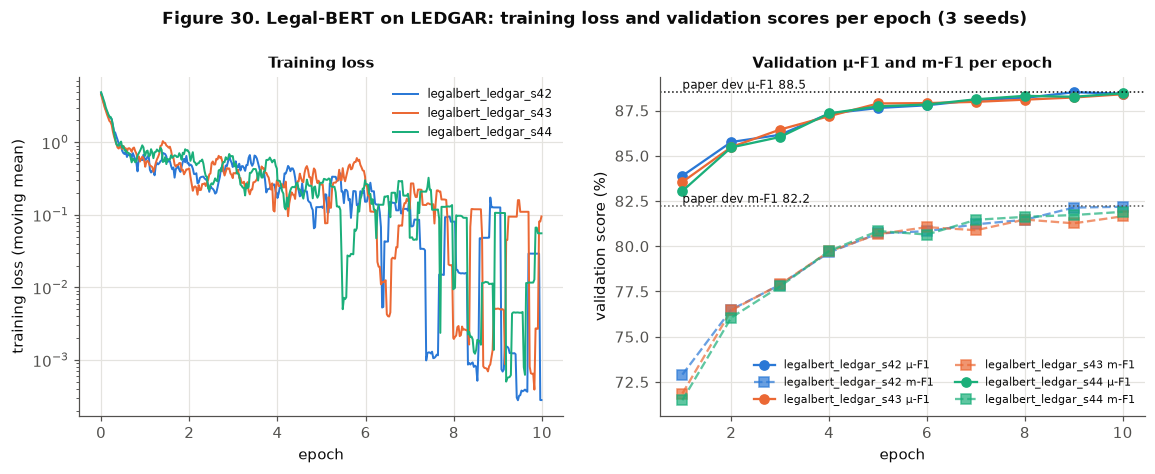

In [56]:
RETRAIN_LEDGAR = False    # True: python scripts/run_ledgar.py --train 42 43 44   (about 2 h on an RTX 5080; run detached)
if RETRAIN_LEDGAR:
    subprocess.run([sys.executable, "scripts/run_ledgar.py", "--train", "42", "43", "44"], check=True)
lsearch = pd.read_csv(C.RESULTS_DIR / "ledgar_search.csv")
llog = pd.read_csv(C.RESULTS_DIR / "ledgar_log.csv")
display(lsearch[["run_id", "seed", "best_epoch", "epochs_run", "val_micro_f1", "val_macro_f1", "mean_epoch_train_seconds",
                 "run_seconds", "peak_gpu_mem_gb"]].round(4))
L_BEST = lsearch.sort_values(["val_micro_f1", "val_macro_f1"], ascending=False, kind="stable").iloc[0]
print(f"Best-validation seed (selection as in the paper): {L_BEST.run_id} -> validation µ-F1 {L_BEST.val_micro_f1:.4f}, m-F1 {L_BEST.val_macro_f1:.4f}")
print(f"Validation over our {len(lsearch)} seeds: µ-F1 {100 * lsearch.val_micro_f1.mean():.1f} ± {100 * lsearch.val_micro_f1.std():.1f}, "
      f"m-F1 {100 * lsearch.val_macro_f1.mean():.1f} ± {100 * lsearch.val_macro_f1.std():.1f} "
      "(paper, Tables 5-6 p. 4327, mean ± std of its 3 best seeds: µ-F1 88.5 ± 0.0, m-F1 82.2 ± 0.3)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
cols = [PL.BLUE, PL.ORANGE, PL.AQUA]
for (rid, g), col in zip(llog.groupby("run_id"), cols):
    st, ep = g[g.kind == "step"], g[g.kind == "epoch"]
    axes[0].plot(st.step / lbench["steps_per_epoch"], st.train_loss.rolling(10, min_periods=1).mean(), color=col, linewidth=1.3, label=rid)
    axes[1].plot(ep.epoch, 100 * ep.val_micro_f1, "o-", color=col, label=f"{rid} µ-F1")
    axes[1].plot(ep.epoch, 100 * ep.val_macro_f1, "s--", color=col, alpha=0.7, label=f"{rid} m-F1")
axes[1].axhline(88.5, color=PL.INK, linestyle=":", linewidth=1); axes[1].text(1, 88.7, "paper dev µ-F1 88.5", fontsize=8)
axes[1].axhline(82.2, color=PL.INK_2, linestyle=":", linewidth=1); axes[1].text(1, 82.4, "paper dev m-F1 82.2", fontsize=8)
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss (moving mean)"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation score (%)"); axes[1].legend(fontsize=7, ncol=2)
axes[0].set_title("Training loss", fontsize=10); axes[1].set_title("Validation µ-F1 and m-F1 per epoch", fontsize=10)
fig.suptitle("Figure 30. Legal-BERT on LEDGAR: training loss and validation scores per epoch (3 seeds)", fontweight="bold", y=1.03, fontsize=11)
PL.savefig(fig, 30, "ledgar_curves"); plt.show()

In [57]:
# TF-IDF + linear SVM: the grid on LEDGAR validation (number of features, C, loss), then a refit of the best configuration
from sklearn.svm import LinearSVC
from datasets import load_dataset
lsvm = pd.read_csv(C.RESULTS_DIR / "ledgar_tfidf_search.csv")
display(lsvm.sort_values("val_micro_f1", ascending=False).head(8).round(4))
SV = lsvm.sort_values(["val_micro_f1", "val_macro_f1"], ascending=False, kind="stable").iloc[0]   # ties (identical configs) -> first in grid order
print(f"Selected on validation: max_features={SV.max_features}, C={SV.C}, loss={SV['loss']} -> val µ-F1 {SV.val_micro_f1:.4f}, m-F1 {SV.val_macro_f1:.4f}")
ld = load_dataset("coastalcph/lex_glue", "ledgar")
LF = {s: pd.DataFrame({"text": ld[s]["text"], "label": ld[s]["label"]}) for s in ["train", "validation", "test"]}
mf = None if SV.max_features == "all" else int(SV.max_features)
with C.timer("tfidf_ledgar", "train_final", notes="refit of the selected TF-IDF + LinearSVC configuration on LEDGAR train"):
    vec_l = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_features=mf)
    svm_l = LinearSVC(C=float(SV.C), loss=SV["loss"], max_iter=5000, random_state=42).fit(vec_l.fit_transform(LF["train"].text), LF["train"].label)
val_check = f1_score(LF["validation"].label, svm_l.predict(vec_l.transform(LF["validation"].text)), average="micro")
assert abs(val_check - SV.val_micro_f1) < 1e-9, "refit does not reproduce the search score"

,max_features,n_features,C,loss,val_micro_f1,val_macro_f1,fit_seconds
29,all,173477,1.0,squared_hinge,0.8835,0.8185,27.8441
21,200000,173477,1.0,squared_hinge,0.8835,0.8185,27.9103
23,200000,173477,3.0,squared_hinge,0.8828,0.8194,35.6002
31,all,173477,3.0,squared_hinge,0.8828,0.8194,35.6732
30,all,173477,3.0,hinge,0.8827,0.8202,70.2373
22,200000,173477,3.0,hinge,0.8827,0.8202,69.1651
13,50000,50000,1.0,squared_hinge,0.8821,0.8180,69.8315
15,50000,50000,3.0,squared_hinge,0.8808,0.8172,52.9325


Selected on validation: max_features=200000, C=1.0, loss=squared_hinge -> val µ-F1 0.8835, m-F1 0.8185


[timer] tfidf_ledgar / train_final: 22.8 s


In [58]:
# Test evaluation, once per model (test-once helper). For single-label classification micro-F1 = accuracy.
yt_l = np.array([L_NAMES[i] for i in LF["test"].label])
ids_l = np.arange(len(yt_l))
pred_file = ROOT / "models" / "ledgar" / L_BEST.run_id / "test_preds.npy"
if not pred_file.exists() and (ROOT / "models" / "ledgar" / L_BEST.run_id / "best").exists():
    subprocess.run([sys.executable, "scripts/run_ledgar.py", "--predict", L_BEST.run_id], check=True)
if pred_file.exists():
    yp_lb = np.array([L_NAMES[i] for i in np.load(pred_file)])
else:
    yp_lb = pd.read_csv(C.RESULTS_DIR / "predictions" / "legalbert_ledgar.csv").pred.values
yp_sv = np.array([L_NAMES[i] for i in svm_l.predict(vec_l.transform(LF["test"].text))])
cfg_lb = {"run": L_BEST.run_id, "selection": "best validation micro-F1 of 3 seeds (as in the paper)", "recipe": json.loads(L_BEST.recipe),
          "val_micro_f1": float(L_BEST.val_micro_f1), "val_macro_f1": float(L_BEST.val_macro_f1)}
cfg_sv = {"max_features": str(SV.max_features), "C": float(SV.C), "loss": SV["loss"], "ngram_range": "(1, 2)", "sublinear_tf": True,
          "min_df": 2, "val_micro_f1": float(SV.val_micro_f1)}
LRES = {"legalbert_ledgar": C.test_once("legalbert_ledgar", cfg_lb, yt_l, yp_lb, L_NAMES, ids_l, ids_l),
        "tfidf_ledgar": C.test_once("tfidf_ledgar", cfg_sv, yt_l, yp_sv, L_NAMES, ids_l, ids_l)}
micro = lambda a, b: f1_score(a, b, average="micro")
rows = []
for name, pred, paper_row in [("tfidf_ledgar", yp_sv, "TFIDF+SVM"), ("legalbert_ledgar", yp_lb, "Legal-BERT")]:
    ci_mi = C.bootstrap_ci(yt_l, pred, ids_l, metric=micro)                 # plain bootstrap over provisions
    ci_ma = C.bootstrap_ci(yt_l, pred, ids_l, labels=L_NAMES)
    p = PAPER.set_index("model").loc[paper_row]
    rows.append({"model": name, "ours test µ-F1": 100 * ci_mi["point"], "µ-F1 95% CI": f"[{100 * ci_mi['ci_low']:.1f}, {100 * ci_mi['ci_high']:.1f}]",
                 "ours test m-F1": 100 * ci_ma["point"], "m-F1 95% CI": f"[{100 * ci_ma['ci_low']:.1f}, {100 * ci_ma['ci_high']:.1f}]",
                 "paper µ-F1": p["test µ-F1"], "paper m-F1": p["test m-F1"],
                 "difference µ-F1": 100 * ci_mi["point"] - p["test µ-F1"], "difference m-F1": 100 * ci_ma["point"] - p["test m-F1"]})
LCMP = pd.DataFrame(rows); display(LCMP.round(2))
LCMP.to_csv(C.RESULTS_DIR / "ledgar_comparison.csv", index=False)
pb_l = C.paired_bootstrap(yt_l, yp_lb, yp_sv, ids_l, labels=L_NAMES)
print(f"Legal-BERT - TF-IDF on LEDGAR test, m-F1: {100 * pb_l['diff']:+.2f} points, 95 % CI [{100 * pb_l['ci_low']:+.2f}, {100 * pb_l['ci_high']:+.2f}]")
json.dump({"comparison": LCMP.to_dict(orient="records"), "paired_legalbert_minus_tfidf_macro": pb_l,
           "best_seed": L_BEST.run_id, "dev_mean_std": {"micro": [float(lsearch.val_micro_f1.mean()), float(lsearch.val_micro_f1.std())],
                                                         "macro": [float(lsearch.val_macro_f1.mean()), float(lsearch.val_macro_f1.std())]}},
          open(C.RESULTS_DIR / "ledgar_results.json", "w"), indent=2, default=float)

[test] legalbert_ledgar: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.
[test] tfidf_ledgar: already evaluated once (see test_eval_log.csv); re-run reproduced the identical predictions, saved metrics re-used.


,model,ours test µ-F1,µ-F1 95% CI,ours test m-F1,m-F1 95% CI,paper µ-F1,paper m-F1,difference µ-F1,difference m-F1
0,tfidf_ledgar,88.09,"[87.4, 88.8]",82.84,"[81.3, 83.8]",87.2,82.4,0.89,0.44
1,legalbert_ledgar,88.65,"[88.0, 89.3]",82.68,"[81.4, 83.8]",88.2,83.0,0.45,-0.32


Legal-BERT - TF-IDF on LEDGAR test, m-F1: -0.16 points, 95 % CI [-1.15, +1.26]


In [59]:
# Compute budget of the LEDGAR runs (training rows are logged by scripts/run_ledgar.py)
budget_now = pd.read_csv(C.RESULTS_DIR / "compute_budget.csv")
display(budget_now[budget_now.model.str.contains("ledgar")][["model", "stage", "seconds", "device", "notes"]])

,model,stage,seconds,device,notes
39,tfidf_ledgar,grid_search,423.50,"CPU (AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD, 16 threads)",32 configs; validation only
42,legalbert_ledgar_s42,train,3667.83,NVIDIA GeForce RTX 5080,"LEDGAR, lr 3e-5, batch 8, max_len 512, early stopping (patience 3)"
43,legalbert_ledgar_s43,train,3610.61,NVIDIA GeForce RTX 5080,"LEDGAR, lr 3e-5, batch 8, max_len 512, early stopping (patience 3)"
44,legalbert_ledgar_s44,train,3638.78,NVIDIA GeForce RTX 5080,"LEDGAR, lr 3e-5, batch 8, max_len 512, early stopping (patience 3)"
49,tfidf_ledgar,train_final,21.94,"CPU (AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD, 16 threads)",refit of the selected TF-IDF + LinearSVC configuration on LEDGAR train
54,tfidf_ledgar,train_final,21.67,"CPU (AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD, 16 threads)",refit of the selected TF-IDF + LinearSVC configuration on LEDGAR train
55,legalbert_ledgar_sub5k_s42,train,479.78,NVIDIA GeForce RTX 5080,stratified 5000-provision subset of LEDGAR train; validation only
56,tfidf_ledgar_sub5k,grid_search,11.11,"CPU (AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD, 16 threads)","stratified 5000-provision subset; C x loss grid, all features; validation only"
62,tfidf_ledgar,train_final,21.30,"CPU (AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD, 16 threads)",refit of the selected TF-IDF + LinearSVC configuration on LEDGAR train
67,tfidf_ledgar,train_final,21.22,"CPU (AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD, 16 threads)",refit of the selected TF-IDF + LinearSVC configuration on LEDGAR train


In [60]:
# Reporting as the paper does: best-dev seed = headline (table above); in addition our validation mean +- std next to Tables 5-6
DEV = pd.DataFrame([{"metric": "validation µ-F1", "ours: mean ± std of 3 seeds": f"{100 * lsearch.val_micro_f1.mean():.1f} ± {100 * lsearch.val_micro_f1.std():.1f}",
                     "ours: best-dev seed": round(100 * L_BEST.val_micro_f1, 2), "paper: mean ± std of its 3 best seeds (Table 5, p. 4327)": "88.5 ± 0.0"},
                    {"metric": "validation m-F1", "ours: mean ± std of 3 seeds": f"{100 * lsearch.val_macro_f1.mean():.1f} ± {100 * lsearch.val_macro_f1.std():.1f}",
                     "ours: best-dev seed": round(100 * L_BEST.val_macro_f1, 2), "paper: mean ± std of its 3 best seeds (Table 5, p. 4327)": "82.2 ± 0.3 (Table 6)"}])
display(DEV); DEV.to_csv(C.RESULTS_DIR / "ledgar_dev_mean_std.csv", index=False)

,metric,ours: mean ± std of 3 seeds,ours: best-dev seed,"paper: mean ± std of its 3 best seeds (Table 5, p. 4327)"
0,validation µ-F1,88.5 ± 0.1,88.51,88.5 ± 0.0
1,validation m-F1,81.9 ± 0.2,82.14,82.2 ± 0.3 (Table 6)


**Interpretation (`results/ledgar_comparison.csv`, `results/ledgar_results.json`, Figure 30).**
* **The published Legal-BERT result is reproduced within its uncertainty.** Our best-validation seed scores **88.65 µ-F1 /
  82.68 m-F1** on the LEDGAR test set, against **88.2 / 83.0** in LexGLUE Table 3 (p. 4317): +0.45 and −0.32 points. Both
  published values lie inside our 95 % bootstrap intervals ([88.0, 89.3] and [81.4, 83.8]). On validation our three seeds give
  88.5 ± 0.1 µ-F1 and 81.9 ± 0.2 m-F1, against the paper's 88.5 ± 0.0 and 82.2 ± 0.3 (Tables 5–6, p. 4327). This is the main
  purpose of the comparison: our fine-tuning code, run with the published set-up on the same data, reaches the published number.
* **TF-IDF + linear SVM:** 88.09 µ-F1 / 82.84 m-F1 vs the paper's 87.2 / 82.4. Ours is slightly higher (µ-F1 by 0.9 points, just
  outside our interval). The paper does not give its grid values, so our grid (word 1–2-grams, sublinear tf, all features,
  C = 1, squared hinge) may simply be a better configuration.
* **Fine-tuning hardly helps on LEDGAR:** Legal-BERT − TF-IDF = −0.16 m-F1 points, 95 % CI [−1.15, +1.26] (+0.56 µ-F1). The paper
  shows the same picture (88.2 vs 87.2 µ-F1, 83.0 vs 82.4 m-F1).
* **Differences from the paper's run, and their likely effect:**
  1. **Epochs:** at most 10 instead of 20 (our budget cut). Seeds 43 and 44 were still at their best in epoch 10 and validation
     m-F1 was still creeping up (Figure 30), so the cut probably costs a few tenths of a point, mostly in m-F1. It is the most
     plausible reason why our m-F1 is 0.3 below the paper while our µ-F1 is above it.
  2. **Seeds:** 3 instead of 5, so the best-validation selection has fewer chances (and with 5 seeds a slightly luckier seed is
     more likely).
  3. **Optimiser details not stated in the paper:** we used AdamW without weight decay and a linear decay over 10 epochs (Hugging
     Face defaults), early-stopping patience 3 on micro-F1, gradient clipping 1.0.
  4. **Precision:** bf16 instead of fp16 (our GPU).
  5. **Hardware:** RTX 5080, about 5.8 min per epoch (3 seeds: 3,668 + 3,611 + 3,639 s ≈ 3.0 h, peak 3.3 GB). The paper reports
     21 min per epoch on its own hardware (Table 7, p. 4328).
  6. **Data version:** the current Hugging Face copy of `lex_glue/ledgar`, with the same split sizes as the paper's Table 1
     (60,000 / 10,000 / 10,000, 100 labels).
  7. **Maximum length:** 512, which the paper implies but does not state; only 1.4 % of test provisions are longer.
  Metrics, label set, split and the reporting rule (test score of the best-validation seed, evaluated once) are identical.

**Learning-curve check (validation only; an extra analysis).** To test the explanation offered below (fine-tuning helps
more when training data are few), Legal-BERT (seed 42, the same LEDGAR recipe, at most 10 epochs) and TF-IDF + LinearSVC
(C and loss re-tuned on validation, all features) were also trained on a **stratified 5,000-provision subset** of LEDGAR
train — roughly the size of our CUAD training set — and compared on the LEDGAR validation set
(`python scripts/run_ledgar.py --subset 5000`). No test evaluation.

In [61]:
ss = pd.read_csv(C.RESULTS_DIR / "ledgar_subset_search.csv").iloc[0]
st_ = pd.read_csv(C.RESULTS_DIR / "ledgar_subset_tfidf.csv").sort_values(["val_micro_f1", "val_macro_f1"], ascending=False, kind="stable").iloc[0]
LC = pd.DataFrame([
    {"training provisions": 5000, "model": "Legal-BERT", "val µ-F1": ss.val_micro_f1, "val m-F1": ss.val_macro_f1, "note": f"seed 42, best epoch {int(ss.best_epoch)}"},
    {"training provisions": 5000, "model": "TF-IDF + LinearSVC", "val µ-F1": st_.val_micro_f1, "val m-F1": st_.val_macro_f1, "note": f"C={st_.C}, {st_['loss']}"},
    {"training provisions": 60000, "model": "Legal-BERT", "val µ-F1": L_BEST.val_micro_f1, "val m-F1": L_BEST.val_macro_f1, "note": "best-dev seed (42)"},
    {"training provisions": 60000, "model": "TF-IDF + LinearSVC", "val µ-F1": SV.val_micro_f1, "val m-F1": SV.val_macro_f1, "note": "selected configuration"}])
display(LC.round(4))
gap = LC.pivot_table(index="training provisions", columns="model", values=["val µ-F1", "val m-F1"])
gap_tab = pd.DataFrame({"Legal-BERT - TF-IDF, µ-F1 (points)": 100 * (gap["val µ-F1"]["Legal-BERT"] - gap["val µ-F1"]["TF-IDF + LinearSVC"]),
                        "Legal-BERT - TF-IDF, m-F1 (points)": 100 * (gap["val m-F1"]["Legal-BERT"] - gap["val m-F1"]["TF-IDF + LinearSVC"])})
display(gap_tab.round(2))
LC.to_csv(C.RESULTS_DIR / "ledgar_learning_curve.csv", index=False)
gap_tab.to_csv(C.RESULTS_DIR / "ledgar_learning_curve_gap.csv")

,training provisions,model,val µ-F1,val m-F1,note
0,5000,Legal-BERT,0.8232,0.7248,"seed 42, best epoch 10"
1,5000,TF-IDF + LinearSVC,0.8007,0.6887,"C=3.0, hinge"
2,60000,Legal-BERT,0.8851,0.8214,best-dev seed (42)
3,60000,TF-IDF + LinearSVC,0.8835,0.8185,selected configuration


,"Legal-BERT - TF-IDF, µ-F1 (points)","Legal-BERT - TF-IDF, m-F1 (points)"
training provisions,,
5000,2.25,3.61
60000,0.16,0.28


In [62]:
# Relating LEDGAR to our CUAD Task 1 result
t1 = {m: C.compute_metrics(test.category, pd.read_csv(C.RESULTS_DIR / "predictions" / f"{m}.csv").set_index("row_id").loc[test.row_id].pred,
                           LABELS, m, "test", save=False) for m in ["legalbert", "tfidf_logreg"]}
rel = pd.DataFrame([
    {"": "classes", "CUAD Task 1 (ours)": len(LABELS), "LEDGAR": LEDGAR["n_labels"]},
    {"": "training clauses", "CUAD Task 1 (ours)": len(train), "LEDGAR": LEDGAR["splits"]["train"]},
    {"": "test clauses", "CUAD Task 1 (ours)": len(test), "LEDGAR": LEDGAR["splits"]["test"]},
    {"": "median training clauses per class", "CUAD Task 1 (ours)": int(train.category.value_counts().median()),
     "LEDGAR": int(pd.Series(LF["train"].label).value_counts().median())},
    {"": "split", "CUAD Task 1 (ours)": "by contract (unseen contracts)", "LEDGAR": "chronological (2016-17 / 2018 / 2019)"},
    {"": "label source", "CUAD Task 1 (ours)": "expert clause annotations", "LEDGAR": "single main topic of each provision (paper, p. 4314)"},
    {"": "Legal-BERT test micro-F1 (= accuracy)", "CUAD Task 1 (ours)": round(100 * t1["legalbert"]["accuracy"], 1),
     "LEDGAR": round(LCMP.set_index("model").loc["legalbert_ledgar", "ours test µ-F1"], 1)},
    {"": "Legal-BERT test macro-F1", "CUAD Task 1 (ours)": round(100 * t1["legalbert"]["macro_f1"], 1),
     "LEDGAR": round(LCMP.set_index("model").loc["legalbert_ledgar", "ours test m-F1"], 1)},
    {"": "best TF-IDF test macro-F1", "CUAD Task 1 (ours)": round(100 * t1["tfidf_logreg"]["macro_f1"], 1),
     "LEDGAR": round(LCMP.set_index("model").loc["tfidf_ledgar", "ours test m-F1"], 1)},
]).set_index("")
display(rel)
rel.to_csv(C.RESULTS_DIR / "ledgar_vs_cuad.csv")

,CUAD Task 1 (ours),LEDGAR
,,
classes,27,100
training clauses,5315,60000
test clauses,1444,10000
median training clauses per class,154,426
split,by contract (unseen contracts),chronological (2016-17 / 2018 / 2019)
label source,expert clause annotations,"single main topic of each provision (paper, p. 4314)"
Legal-BERT test micro-F1 (= accuracy),89.1,88.6
Legal-BERT test macro-F1,87.1,82.7
best TF-IDF test macro-F1,79.4,82.8


**Interpretation — relating LEDGAR to our CUAD result (`results/ledgar_vs_cuad.csv`).** The two numbers cannot be compared
directly, only explained:
* **Different tasks and labels.** CUAD Task 1 has 27 expert-defined clause *types* (legal risk categories). LEDGAR has 100
  provision *topics*, several of which overlap almost by name ("Assigns" / "Assignments", "Waivers" / "No Waivers",
  "Indemnity" / "Indemnifications", "Governing Laws" / "Applicable Laws"). Such pairs cap LEDGAR's macro-F1 for any model.
* **Different sizes.** 5,315 vs 60,000 training clauses (median 154 vs 426 per class). Macro-F1 is averaged over 27 vs 100
  classes, and LEDGAR has a long tail (the rarest label has 23 training provisions).
* **Different splits.** CUAD: by contract (test clauses come from unseen contracts). LEDGAR: chronological (test = 2019), so
  there is also drift over time.
* **Micro vs macro.** Micro-F1 (= accuracy here) is similar on both: 89.1 (CUAD) vs 88.6 (LEDGAR). Macro-F1 differs more
  (87.1 vs 82.7) because of the label-set differences above. Our CUAD macro-F1 is therefore **not** "better than LexGLUE"; the
  datasets differ.
* **The most informative contrast is the gap to TF-IDF.** On CUAD, fine-tuned Legal-BERT beats the best TF-IDF model by
  **+7.7 macro-F1 points** (0.871 vs 0.794; paired contract-bootstrap CI [+0.047, +0.110], section 5). On LEDGAR the gap is
  essentially zero. Explanation: pre-trained knowledge pays off most when labelled data are few, and CUAD's categories depend
  on what a clause *does* (an exception to a restriction, a cap that limits the time to claim) rather than on topic words.
* **The learning-curve check supports the data-size part of this explanation** (`results/ledgar_learning_curve_gap.csv`,
  validation only, one seed). With only 5,000 LEDGAR training provisions, about our CUAD size, Legal-BERT leads TF-IDF by
  **+2.25 µ-F1 / +3.61 m-F1 points** (82.3 / 72.5 vs 80.1 / 68.9). With all 60,000 the lead shrinks to +0.16 / +0.28. So on the
  *same* task the advantage of fine-tuning grows when data are scarce. The remaining difference to CUAD's +7.7 is consistent
  with the second part (functional rather than lexical categories) but is not tested by this check.
* **What is identical:** the checkpoint (`nlpaueb/legal-bert-base-uncased`), the [CLS] + softmax head, the use of validation
  for every choice and a single test evaluation. **What differs:** the hyper-parameters. LEDGAR uses the paper's set-up (lr 3e-5,
  batch 8, length 512, early stopping); CUAD uses our own recipe from section 5 (lr 5e-5, batch 16, warm-up, weight decay,
  length 320, 5 epochs).

## 7. Evaluation and analysis (Part C)
This section brings every Task 1 model together, justifies the metrics, restates the ablation, analyses the errors of the
best model, restates both published comparisons, summarises the prompted LLMs, checks subgroups and states the limitations.
It reads only saved files (`results/`), except for one cached pass of Legal-BERT to obtain its confidence scores.

### 7.1 Why these metrics: the cost of errors
The intended use is **decision support for a human contract reviewer**. In that setting the two kinds of error cost
different amounts:
* a **false negative** (a risk clause such as *Cap On Liability*, *Change Of Control* or *Anti-Assignment* put in the wrong
  category, or, in Task 2, not found at all) can mean the reviewer never looks at it — the expensive error;
* a **false positive** (a clause wrongly labelled as, say, *Non-Compete*, or a spurious Task 2 span) costs the reviewer a few
  seconds to dismiss.

**Task 1.** **Macro-F1** over the 27 classes is the primary metric (pre-declared): every clause type counts equally, so a
model cannot look good by mastering only the frequent types, and rare risk types matter as much as common ones. Because the
rarest classes have very few test clauses (Source Code Escrow 4), we also report macro-F1 over the **24 classes with ≥15 test
clauses**, contract-level bootstrap CIs, accuracy (what share of all clauses is right — what a reviewer experiences on
average), weighted-F1 (frequency-weighted) and **per-class recall for the risk-bearing classes** (below), because recall is
what protects the reviewer from misses.

**Task 2.** Entity-level precision / recall / F1 are the unit a reviewer sees (a clause found or not). IoU ≥ 0.5 is CUAD's own
matching criterion and tolerates the subjective boundaries of annotators; exact match is reported as a strict secondary
number. Macro-F1 over categories is primary for the same reason as in Task 1. **AUPR and precision at 80 % / 90 % recall**
(CUAD's metrics) describe the trade-off a reviewer actually faces: they want most clauses found (high recall) without
drowning in false hits (precision at high recall).

In [63]:
T1_MODELS = {"majority": "Majority class", "tfidf_complementnb": "TF-IDF + ComplementNB", "tfidf_linearsvc": "TF-IDF + LinearSVC",
             "tfidf_logreg": "TF-IDF + LogReg (best classical)", "bert_base": "BERT-base (fine-tuned, ablation)",
             "legalbert": "Legal-BERT (fine-tuned)", "qwen25_1p5b_v2": "Qwen2.5-1.5B-Instruct (prompt v2)",
             "qwen25_3b_v2": "Qwen2.5-3B-Instruct (prompt v2)"}
PRED = {m: pd.read_csv(C.RESULTS_DIR / "predictions" / f"{m}.csv").set_index("row_id").loc[test.row_id].pred.astype(str).values
        for m in T1_MODELS}
YT = test.category.values; CT = test.contract.values
RISK = ["Cap On Liability", "Change Of Control", "Termination For Convenience", "Anti-Assignment", "Non-Compete", "Liquidated Damages"]
METR = {m: C.compute_metrics(YT, PRED[m], LABELS, m, "test", save=False, robust_labels=ROBUST) for m in T1_MODELS}
risk_tab = pd.DataFrame({T1_MODELS[m]: {c: METR[m]["per_class"][c]["recall"] for c in RISK} for m in T1_MODELS}).T
risk_tab.columns = [f"{c} (n={int((YT == c).sum())})" for c in RISK]
print("Test recall for the risk-bearing classes:")
display(risk_tab.round(3))
risk_tab.to_csv(C.RESULTS_DIR / "eval_risk_class_recall.csv")

Test recall for the risk-bearing classes:


,Cap On Liability (n=115),Change Of Control (n=49),Termination For Convenience (n=39),Anti-Assignment (n=121),Non-Compete (n=48),Liquidated Damages (n=21)
Majority class,1.000,0.000,0.000,0.000,0.000,0.000
TF-IDF + ComplementNB,0.817,0.490,0.821,0.942,0.729,0.571
TF-IDF + LinearSVC,0.896,0.633,0.795,0.876,0.896,0.571
TF-IDF + LogReg (best classical),0.878,0.673,0.795,0.860,0.917,0.571
"BERT-base (fine-tuned, ablation)",0.930,0.633,0.872,0.860,0.875,0.714
Legal-BERT (fine-tuned),0.948,0.633,0.897,0.884,0.875,0.810
Qwen2.5-1.5B-Instruct (prompt v2),0.243,0.714,0.128,0.884,0.479,0.714
Qwen2.5-3B-Instruct (prompt v2),0.574,0.653,0.897,0.785,0.333,0.571


**Why these six classes are called "risk-bearing".** The list was fixed in the project plan before any result was produced
(at project set-up). The justification comes from the
**official CUAD category descriptions** (`data/raw/category_descriptions.csv`, downloaded from the CUAD repository by
`scripts/download_cuad.py`): each of the six describes either a limit on what a party can recover or must pay (Cap On Liability,
Liquidated Damages), a party's ability to end or exit the contract (Termination For Convenience, Change Of Control) or a
restriction on what a party may do with the contract or in its business (Anti-Assignment, Non-Compete). A reviewer who misses
such a clause misjudges the exposure, the exit options or the freedom of the client.

In [64]:
cdesc = pd.read_csv(ROOT / "data" / "raw" / "category_descriptions.csv")
cdesc["cat"] = cdesc.iloc[:, 0].str.replace("Category: ", "", regex=False).str.strip().str.lower()
cdesc["desc"] = cdesc.iloc[:, 1].str.replace("Description: ", "", regex=False).str.strip()
WHY = {"Cap On Liability": "limits what can be recovered after a breach", "Liquidated Damages": "fixes an amount payable on breach or termination",
       "Termination For Convenience": "lets a party exit without cause", "Change Of Control": "exit or consent right when ownership changes",
       "Anti-Assignment": "restricts transferring the contract", "Non-Compete": "restricts the party's business activity"}
RJ = pd.DataFrame({"class": RISK, "official CUAD description": [cdesc.set_index("cat").loc[c.lower(), "desc"] for c in RISK],
                   "why it is risk-bearing": [WHY[c] for c in RISK]})
pd.set_option("display.max_colwidth", 220); display(RJ)
RJ.to_csv(C.RESULTS_DIR / "risk_classes_justification.csv", index=False)

,class,official CUAD description,why it is risk-bearing
0,Cap On Liability,Does the contract include a cap on liability upon the breach of a party’s obligation? This includes time limitation for the counterparty to bring claims or maximum amount for recovery.,limits what can be recovered after a breach
1,Change Of Control,"Does one party have the right to terminate or is consent or notice required of the counterparty if such party undergoes a change of control, such as a merger, stock sale, transfer of all or substantially all of its a...",exit or consent right when ownership changes
2,Termination For Convenience,Can a party terminate this contract without cause (solely by giving a notice and allowing a waiting period to expire)?,lets a party exit without cause
3,Anti-Assignment,Is consent or notice required of a party if the contract is assigned to a third party?,restricts transferring the contract
4,Non-Compete,Is there a restriction on the ability of a party to compete with the counterparty or operate in a certain geography or business or technology sector?,restricts the party's business activity
5,Liquidated Damages,Does the contract contain a clause that would award either party liquidated damages for breach or a fee upon the termination of a contract (termination fee)?,fixes an amount payable on breach or termination


### 7.2 One Task 1 comparison table (all models, the same 1,444 test clauses)
Macro-F1 with the corrected contract-level bootstrap (point estimate over all 27 classes, each resample averaged over the
classes present in it; 1,000 resamples of the 93 test contracts). **Cost** = measured seconds per clause × 1,000 / 3,600 ×
the stated hourly price (AWS on-demand, us-east-1, read 2026-10-22: GPU instance g6.xlarge $0.8048/h, CPU instance
c7i.xlarge $0.1785/h; `results/llm_price_sources.json`); **batched cost is the headline column**. Latency = one clause at a
time on the same 100 validation clauses. Training time = the final fit of the selected configuration (searches listed below
the table). The LoRA row is completed in Part F3 (section 9).

In [65]:
inf = json.load(open(C.RESULTS_DIR / "inference_costs.json"))
llm_cost = {r["model"]: r for r in json.load(open(C.RESULTS_DIR / "llm_cost.json"))["rows"]}
prices = json.load(open(C.RESULTS_DIR / "llm_price_sources.json"))["primary"]
GPU_P, CPU_P = prices["g6.xlarge"]["usd_per_hour"], prices["c7i.xlarge"]["usd_per_hour"]
lat_lr = json.load(open(C.RESULTS_DIR / "llm" / "latency_tfidf_logreg.json"))
budget = pd.read_csv(C.RESULTS_DIR / "compute_budget.csv")
first_fit = lambda m: float(budget[(budget.model == m) & (budget.stage == "train_final")].seconds.iloc[0])
tsr = pd.read_csv(C.RESULTS_DIR / "transformer_search.csv").set_index("run_id")
llm_meta = json.load(open(C.RESULTS_DIR / "llm" / "run_meta.json"))
eff = {   # (seconds per clause batched, batch-1 latency ms, price, training seconds, parameters)
    "majority": (inf["majority"]["throughput_seconds_per_clause"], inf["majority"]["median_ms"], CPU_P, 0.0, "27 class counts"),
    "tfidf_complementnb": (inf["tfidf_complementnb"]["throughput_seconds_per_clause"], inf["tfidf_complementnb"]["median_ms"], CPU_P,
                           first_fit("tfidf_complementnb"), "20,000 features x 27"),
    "tfidf_linearsvc": (inf["tfidf_linearsvc"]["throughput_seconds_per_clause"], inf["tfidf_linearsvc"]["median_ms"], CPU_P,
                        first_fit("tfidf_linearsvc"), "41,209 features x 27"),
    "tfidf_logreg": (lat_lr["throughput_seconds_per_clause"], lat_lr["median_ms"], CPU_P, first_fit("tfidf_logreg"), "69,247 features x 27"),
    "bert_base": (inf["bert_base"]["throughput_seconds_per_clause"], inf["bert_base"]["median_ms"], GPU_P, first_fit("bert_base"),
                  f"{tsr.loc['bert_lr5e-05_s42', 'params_million']:.1f} M"),
    "legalbert": (1 / llm_cost["Legal-BERT (fine-tuned)"]["throughput clauses/s (batched)"], llm_cost["Legal-BERT (fine-tuned)"]["latency median ms (batch 1)"],
                  GPU_P, first_fit("legalbert"), f"{tsr.loc['legalbert_lr5e-05_s42', 'params_million']:.1f} M"),
    "qwen25_1p5b_v2": (1 / llm_cost["Qwen2.5-1.5B-Instruct (v2)"]["throughput clauses/s (batched)"],
                       llm_cost["Qwen2.5-1.5B-Instruct (v2)"]["latency median ms (batch 1)"], GPU_P, 0.0,
                       f"{llm_meta['qwen25_1p5b_v2_test']['n_params'] / 1e9:.2f} B"),
    "qwen25_3b_v2": (1 / llm_cost["Qwen2.5-3B-Instruct (v2)"]["throughput clauses/s (batched)"],
                     llm_cost["Qwen2.5-3B-Instruct (v2)"]["latency median ms (batch 1)"], GPU_P, 0.0,
                     f"{llm_meta['qwen25_3b_v2_test']['n_params'] / 1e9:.2f} B")}
rows = []
for m, name in T1_MODELS.items():
    ci = C.bootstrap_ci(YT, PRED[m], CT, labels=LABELS)
    spc, lat, price, tr_s, params = eff[m]
    rows.append({"model": name, "key": m, "test macro-F1": METR[m]["macro_f1"], "95% CI": f"[{ci['ci_low']:.3f}, {ci['ci_high']:.3f}]",
                 "macro-F1 (24 robust classes)": METR[m]["macro_f1_robust"], "accuracy": METR[m]["accuracy"],
                 "weighted-F1": METR[m]["weighted_f1"], "training time (s, final fit)": tr_s,
                 "cost per 1,000 clauses USD (batched)": spc * 1000 / 3600 * price, "latency ms (batch 1)": lat, "parameters": params})
lora_file = C.RESULTS_DIR / "predictions" / "legalbert_lora.csv"
if lora_file.exists():
    PRED["legalbert_lora"] = pd.read_csv(lora_file).set_index("row_id").loc[test.row_id].pred.astype(str).values
    METR["legalbert_lora"] = C.compute_metrics(YT, PRED["legalbert_lora"], LABELS, "legalbert_lora", "test", save=False, robust_labels=ROBUST)
    ci = C.bootstrap_ci(YT, PRED["legalbert_lora"], CT, labels=LABELS)
    li = json.load(open(C.RESULTS_DIR / "lora_inference.json")); lc_ = json.load(open(C.RESULTS_DIR / "lora_choice.json"))
    lsr_ = pd.read_csv(C.RESULTS_DIR / "transformer_lora_search.csv").set_index("run_id")
    rows.append({"model": "Legal-BERT + LoRA (Part F3)", "key": "legalbert_lora", "test macro-F1": METR["legalbert_lora"]["macro_f1"],
                 "95% CI": f"[{ci['ci_low']:.3f}, {ci['ci_high']:.3f}]", "macro-F1 (24 robust classes)": METR["legalbert_lora"]["macro_f1_robust"],
                 "accuracy": METR["legalbert_lora"]["accuracy"], "weighted-F1": METR["legalbert_lora"]["weighted_f1"],
                 "training time (s, final fit)": float(lsr_.loc[lc_["test_run"], "run_seconds"]),
                 "cost per 1,000 clauses USD (batched)": li["throughput_seconds_per_clause"] * 1000 / 3600 * GPU_P,
                 "latency ms (batch 1)": li["median_ms"], "parameters": f"{lsr_.trainable_params.iloc[0] / 1e6:.2f} M trainable of 109.5 M"})
else:
    rows.append({"model": "Legal-BERT + LoRA (Part F3)", "key": "legalbert_lora", "95% CI": "to be filled in Part F3"})
T1_TABLE = pd.DataFrame(rows)
T1_TABLE.to_csv(C.RESULTS_DIR / "task1_comparison_table.csv", index=False)
with pd.option_context("display.float_format", lambda x: f"{x:.4g}"):
    display(T1_TABLE.drop(columns="key"))
search = budget[budget.stage.isin(["grid_search", "all_runs"]) & budget.model.isin(["classical_search", "transformer_plan"])].drop_duplicates("model")
print("Model-selection searches (validation only, not in the table):",
      "; ".join(f"{r.model} {r.seconds:,.0f} s ({r.notes[:45]})" for r in search.itertuples()))

,model,test macro-F1,95% CI,macro-F1 (24 robust classes),accuracy,weighted-F1,"training time (s, final fit)","cost per 1,000 clauses USD (batched)",latency ms (batch 1),parameters
0,Majority class,0.005464,"[0.004, 0.007]",0.006147,0.07964,0.01175,0,2.184e-09,0.0188,27 class counts
1,TF-IDF + ComplementNB,0.7133,"[0.669, 0.738]",0.7009,0.7777,0.7643,0.31,2.221e-06,0.9472,"20,000 features x 27"
2,TF-IDF + LinearSVC,0.7862,"[0.750, 0.817]",0.79,0.8317,0.8306,1.8,9.265e-06,0.467,"41,209 features x 27"
3,TF-IDF + LogReg (best classical),0.7939,"[0.752, 0.824]",0.7962,0.8289,0.83,6.15,1.036e-05,0.5143,"69,247 features x 27"
4,"BERT-base (fine-tuned, ablation)",0.8256,"[0.796, 0.857]",0.8302,0.8615,0.86,95.06,0.0001982,5.844,109.5 M
5,Legal-BERT (fine-tuned),0.8708,"[0.836, 0.896]",0.8661,0.8906,0.8897,94.25,0.0002167,5.786,109.5 M
6,Qwen2.5-1.5B-Instruct (prompt v2),0.4508,"[0.407, 0.475]",0.4311,0.5284,0.5061,0,0.00807,125.6,1.54 B
7,Qwen2.5-3B-Instruct (prompt v2),0.5564,"[0.518, 0.587]",0.5499,0.6115,0.6312,0,0.01536,190.2,3.09 B
8,Legal-BERT + LoRA (Part F3),0.8289,"[0.796, 0.862]",0.8361,0.8733,0.8723,63.42,0.0002162,7.939,0.61 M trainable of 109.5 M


Model-selection searches (validation only, not in the table): classical_search 3,433 s (5776 configs; 14 parallel CPU workers; valida); transformer_plan 1,262 s (LR search x2 models + 2 extra seeds x2 + clas)


In [66]:
# Paired contract-level bootstraps for the key comparisons. Comparisons computed in earlier stages are RE-USED from their
# files (same function, same seed); only LogReg vs majority is new here.
tc = json.load(open(C.RESULTS_DIR / "transformer_comparison.json"))
lpb = pd.read_csv(C.RESULTS_DIR / "llm_paired_bootstrap.csv")
def from_llm(a, b):
    r = lpb[(lpb.A.str.startswith(a)) & (lpb.B.str.startswith(b))].iloc[0]
    return {"diff": r["macro-F1 A - B"], "ci_low": r.ci_low, "ci_high": r.ci_high, "p_a_not_better": r["share of resamples A not better"]}
new = C.paired_bootstrap(YT, PRED["tfidf_logreg"], PRED["majority"], CT, labels=LABELS)
PAIRS = pd.DataFrame([
    {"comparison": "Legal-BERT - TF-IDF LogReg", **{k: tc["H1_legalbert_vs_best_classical"]["all_27"][k] for k in ["diff", "ci_low", "ci_high", "p_a_not_better"]},
     "source": "results/transformer_comparison.json"},
    {"comparison": "TF-IDF LogReg - majority", **{k: new[k] for k in ["diff", "ci_low", "ci_high", "p_a_not_better"]}, "source": "computed here"},
    {"comparison": "Legal-BERT - BERT-base (ablation)", **{k: tc["ablation_legalbert_vs_bert_base"]["all_27"][k] for k in ["diff", "ci_low", "ci_high", "p_a_not_better"]},
     "source": "results/transformer_comparison.json"},
    {"comparison": "Legal-BERT - Qwen2.5-1.5B (v2)", **from_llm("Legal-BERT", "Qwen2.5-1.5B"), "source": "results/llm_paired_bootstrap.csv"},
    {"comparison": "Legal-BERT - Qwen2.5-3B (v2)", **from_llm("Legal-BERT", "Qwen2.5-3B"), "source": "results/llm_paired_bootstrap.csv"},
    {"comparison": "Qwen2.5-3B - Qwen2.5-1.5B", **from_llm("Qwen2.5-3B", "Qwen2.5-1.5B"), "source": "results/llm_paired_bootstrap.csv"}])
PAIRS["95% CI"] = [f"[{l:+.3f}, {h:+.3f}]" for l, h in zip(PAIRS.ci_low, PAIRS.ci_high)]
display(PAIRS[["comparison", "diff", "95% CI", "p_a_not_better", "source"]].round(4))
PAIRS.to_csv(C.RESULTS_DIR / "task1_paired_bootstraps.csv", index=False)

,comparison,diff,95% CI,p_a_not_better,source
0,Legal-BERT - TF-IDF LogReg,0.0769,"[+0.047, +0.110]",0.0,results/transformer_comparison.json
1,TF-IDF LogReg - majority,0.7885,"[+0.746, +0.819]",0.0,computed here
2,Legal-BERT - BERT-base (ablation),0.0452,"[+0.018, +0.064]",0.0,results/transformer_comparison.json
3,Legal-BERT - Qwen2.5-1.5B (v2),0.4200,"[+0.386, +0.467]",0.0,results/llm_paired_bootstrap.csv
4,Legal-BERT - Qwen2.5-3B (v2),0.3144,"[+0.274, +0.351]",0.0,results/llm_paired_bootstrap.csv
5,Qwen2.5-3B - Qwen2.5-1.5B,0.1056,"[+0.081, +0.144]",0.0,results/llm_paired_bootstrap.csv


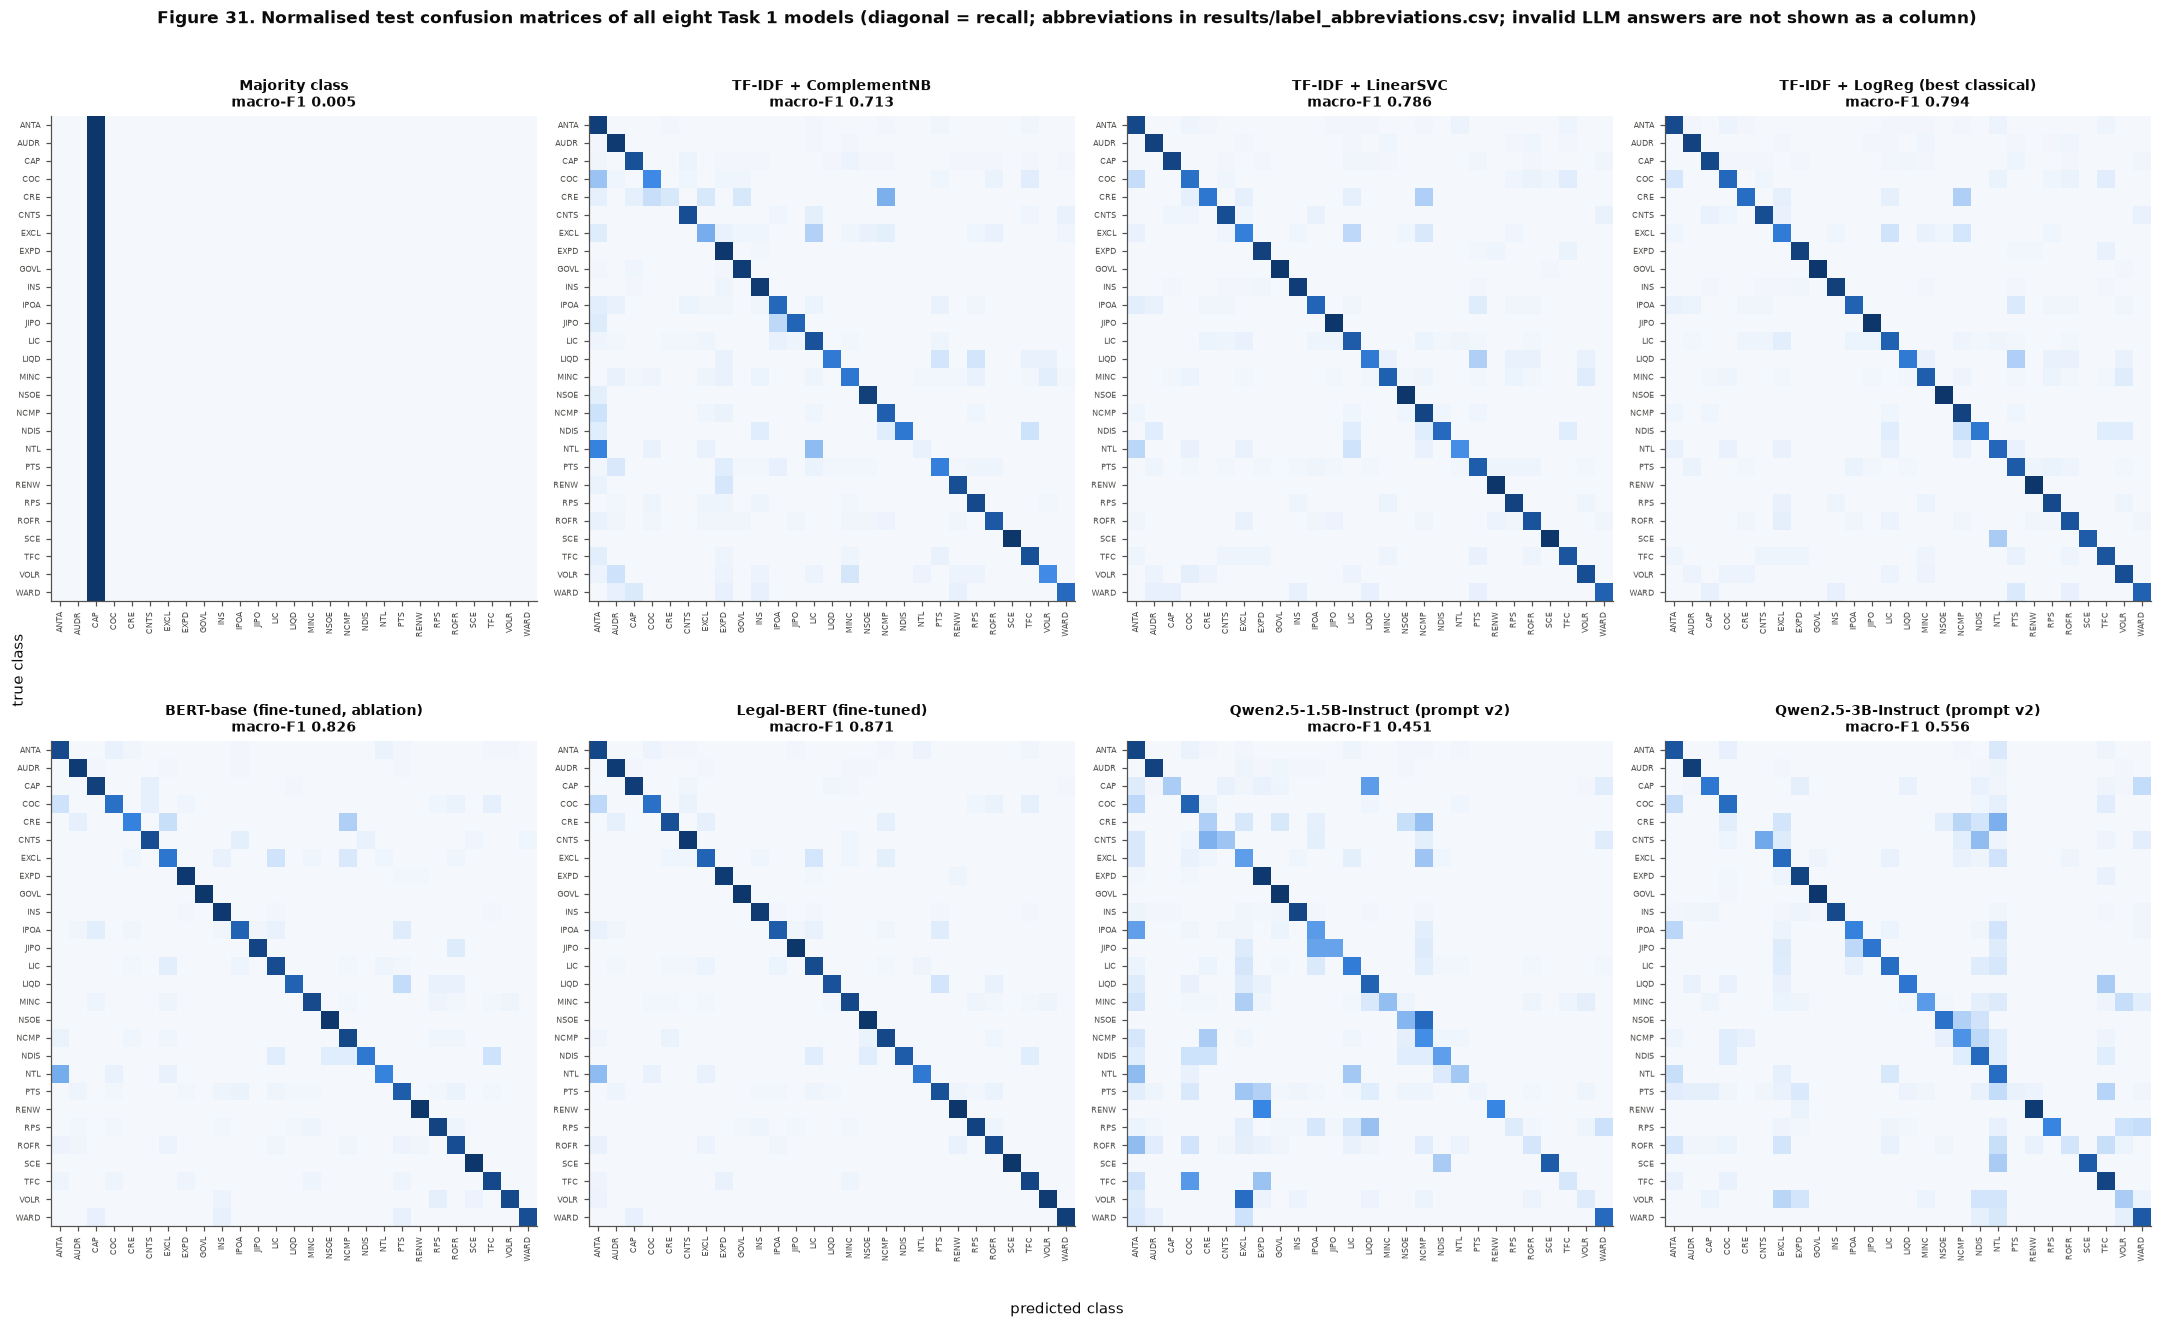

In [67]:
# Confusion matrices of all 8 models (normalised by true class) - appendix grid; Legal-BERT's full-size matrix is Figure 17
ABBR = {l: "".join(w[0] for w in re.split(r"[\s/-]+", l) if w)[:4].upper() for l in LABELS}
ABBR.update({"Non-Compete": "NCMP", "Non-Disparagement": "NDIS", "Non-Transferable License": "NTL", "No-Solicit Of Employees": "NSOE",
             "Competitive Restriction Exception": "CRE", "Change Of Control": "COC", "Cap On Liability": "CAP", "Covenant Not To Sue": "CNTS",
             "Rofr/Rofo/Rofn": "ROFR", "Revenue/Profit Sharing": "RPS", "Renewal Term": "RENW", "Insurance": "INS", "Exclusivity": "EXCL",
             "Expiration Date": "EXPD", "Ip Ownership Assignment": "IPOA", "Joint Ip Ownership": "JIPO", "License Grant": "LIC",
             "Liquidated Damages": "LIQD", "Minimum Commitment": "MINC", "Post-Termination Services": "PTS", "Source Code Escrow": "SCE",
             "Termination For Convenience": "TFC", "Volume Restriction": "VOLR", "Warranty Duration": "WARD", "Anti-Assignment": "ANTA",
             "Audit Rights": "AUDR", "Governing Law": "GOVL"})
assert len(set(ABBR.values())) == len(LABELS)
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(2, 4, figsize=(20, 12))
for ax, m in zip(axes.ravel(), T1_MODELS):
    cmx = confusion_matrix(YT, PRED[m], labels=LABELS).astype(float)
    cmx = cmx / cmx.sum(axis=1, keepdims=True)
    ax.imshow(cmx, cmap=PL.BLUES, vmin=0, vmax=1)
    ax.set_xticks(range(len(LABELS))); ax.set_xticklabels([ABBR[l] for l in LABELS], rotation=90, fontsize=5.5)
    ax.set_yticks(range(len(LABELS))); ax.set_yticklabels([ABBR[l] for l in LABELS], fontsize=5.5)
    ax.grid(False); ax.set_title(f"{T1_MODELS[m]}\nmacro-F1 {METR[m]['macro_f1']:.3f}", fontsize=9)
fig.supxlabel("predicted class", fontsize=10); fig.supylabel("true class", fontsize=10)
fig.suptitle("Figure 31. Normalised test confusion matrices of all eight Task 1 models (diagonal = recall; abbreviations in "
             "results/label_abbreviations.csv; invalid LLM answers are not shown as a column)", fontweight="bold", fontsize=11, y=1.0)
fig.tight_layout(h_pad=3.0); PL.savefig(fig, 31, "cm_grid_all_models"); plt.show()
pd.Series(ABBR, name="abbreviation").rename_axis("class").to_csv(C.RESULTS_DIR / "label_abbreviations.csv")

**Interpretation (`results/task1_comparison_table.csv`, `results/task1_paired_bootstraps.csv`, Figure 31).**
* **Ranking on macro-F1 (test, 27 classes):**
  - fine-tuned **Legal-BERT 0.871** [0.836, 0.896];
  - BERT-base 0.826;
  - TF-IDF + LogReg 0.794 and LinearSVC 0.786 (their difference is not significant: +0.008 [−0.011, +0.024], section 4);
  - ComplementNB 0.713;
  - the prompted Qwen2.5-3B 0.556 and Qwen2.5-1.5B 0.451;
  - majority 0.005;
  - (Part F3) Legal-BERT with LoRA 0.829 [0.796, 0.862], between BERT-base and Legal-BERT (section 9).
  The robustness number over the 24 classes with ≥ 15 test clauses gives the same order. Every key paired comparison
  excludes 0: Legal-BERT − LogReg +0.077 [+0.047, +0.110]; LogReg − majority +0.788 [+0.746, +0.819]; Legal-BERT − BERT-base
  +0.045 [+0.018, +0.064]; Legal-BERT − each LLM +0.420 and +0.314; 3B − 1.5B +0.106.
* **Cost and speed (one basis):** the classical models cost about $0.00001 per 1,000 clauses and answer in under 1 ms; the
  fine-tuned transformers about $0.0002 and 6 ms; the prompted LLMs $0.008–0.015 and 126–190 ms. Training is cheap everywhere
  except in the searches: the final fits take 0.3–6 s (classical) and about 95 s (transformers), while the model selection took
  3,433 s (classical grid) and 1,262 s (transformer plan). The LLMs need no training but are 20–35× slower than Legal-BERT at
  inference.
* **Risk-bearing classes (`results/eval_risk_class_recall.csv`):** Legal-BERT has the highest recall for Cap On Liability
  (0.948) and Liquidated Damages (0.810), and ties with Qwen2.5-3B on Termination For Convenience (0.897). It is not the best
  everywhere: on **Change Of Control** its recall is only 0.633 (LogReg 0.673, Qwen2.5-1.5B 0.714). On Non-Compete it is 0.875
  vs LogReg 0.917. Change Of Control is the weak spot of the best model (section 7.5).
* **Confusion matrices (Figure 31):** the fine-tuned and classical models show clean diagonals with a few off-diagonal cells
  along the known neighbours. The LLM matrices show *column smears*, i.e. labels predicted for many classes (Non-Transferable
  License for the 3B model; Anti-Assignment, Exclusivity and Liquidated Damages for the 1.5B model). The majority baseline
  predicts Cap On Liability for every clause. Legal-BERT's full-size matrix is Figure 17.

### 7.3 Task 2 summary table (from the Task 2 notebook)

In [68]:
t2 = pd.read_csv(C.RESULTS_DIR / "task2_test_summary.csv")
low = pd.read_csv(C.RESULTS_DIR / "task2_lowthr_test.csv")
t2c = json.load(open(C.RESULTS_DIR / "task2_test_comparison.json"))
cmp2 = pd.read_csv(C.RESULTS_DIR / "task2_cuad_comparison.csv")
mr = dict(zip(cmp2.model, cmp2["max recall reached %"]))
T2_TABLE = pd.DataFrame([
    {"model": "TF-IDF segment baseline", **t2.iloc[0][["macro-F1 @ IoU0.5", "95% CI", "micro-F1 @ IoU0.5", "exact macro-F1", "token micro-F1",
                                                       "CUAD-style AUPR (micro)", "P@80%R"]].to_dict(), "max recall": mr["TF-IDF segment baseline (ours)"] / 100},
    {"model": "Legal-BERT tagger (main result, tuned operating point)", **t2.iloc[1][["macro-F1 @ IoU0.5", "95% CI", "micro-F1 @ IoU0.5",
                                     "exact macro-F1", "token micro-F1", "CUAD-style AUPR (micro)", "P@80%R"]].to_dict(),
     "max recall": mr["Legal-BERT tagger (ours)"] / 100},
    {"model": "ANALYSIS ONLY - tagger low-threshold candidate list (theta_i 0.05; ranking metrics only)",
     "macro-F1 @ IoU0.5": low.iloc[1]["macro-F1 @ IoU0.5 (all spans kept)"], "95% CI": "n/a (not an operating point)",
     "CUAD-style AUPR (micro)": low.iloc[1]["CUAD-style AUPR %"] / 100, "P@80%R": low.iloc[1]["P@80%R %"] / 100,
     "max recall": low.iloc[1]["max recall %"] / 100}])
display(T2_TABLE.round(3))
print(f"Tagger - baseline (macro-F1 @ IoU0.5): {t2c['paired_tagger_vs_baseline']['diff']:+.3f} "
      f"[{t2c['paired_tagger_vs_baseline']['ci_low']:+.3f}, {t2c['paired_tagger_vs_baseline']['ci_high']:+.3f}]")
T2_TABLE.to_csv(C.RESULTS_DIR / "task2_final_table.csv", index=False)

,model,macro-F1 @ IoU0.5,95% CI,micro-F1 @ IoU0.5,exact macro-F1,token micro-F1,CUAD-style AUPR (micro),P@80%R,max recall
0,TF-IDF segment baseline,0.394,"[0.367, 0.431]",0.468,0.202,0.558,0.402,0.0,0.479
1,"Legal-BERT tagger (main result, tuned operating point)",0.523,"[0.490, 0.560]",0.575,0.300,0.661,0.524,0.0,0.581
2,ANALYSIS ONLY - tagger low-threshold candidate list (theta_i 0.05; ranking metrics only),0.410,n/a (not an operating point),NaN,NaN,NaN,0.587,0.0,0.690


Tagger - baseline (macro-F1 @ IoU0.5): +0.129 [+0.099, +0.155]


### 7.4 Ablation (restated): general-domain vs legal-domain pre-training
**The single isolated decision:** the pre-trained checkpoint — `bert-base-uncased` (general English) vs
`nlpaueb/legal-bert-base-uncased` (legal English, its own legal vocabulary). Everything else was held constant: architecture and
size, recipe (lr 5e-5 chosen for both on validation, batch 16, 5 epochs, warm-up, weight decay, max length 320, bf16), seeds,
split, metric and the single test evaluation. Because Legal-BERT was pre-trained from scratch with its own vocabulary, corpus
and vocabulary change together (token counts below).

In [69]:
abl = pd.read_csv(C.RESULTS_DIR / "ablation.csv")
display(abl[["model", "val_macro_f1_3seeds_mean", "val_macro_f1_3seeds_std", "test_macro_f1", "test_macro_f1_robust", "test_accuracy",
             "mean_tokens_per_clause", "test_macro_f1_diff_95ci"]].round(4))
lr_s = pd.read_csv(C.RESULTS_DIR / "transformer_lr_sensitivity.csv", index_col=0)
ep_s = json.load(open(C.RESULTS_DIR / "transformer_epoch_sensitivity.json"))
print("Sensitivity (validation only, seed 42): macro-F1 by learning rate"); display(lr_s.round(4))
print(f"BERT-base with 8 instead of 5 epochs: {ep_s['bert_8_epochs_best']:.4f} (best epoch {ep_s['bert_8_epochs_best_epoch']}); "
      f"validation gap to Legal-BERT {ep_s['gap_5_epochs']:+.4f} -> {ep_s['gap_vs_bert_8_epochs']:+.4f}")
ABL_SUM = {"isolated_decision": "general-domain (bert-base-uncased) vs legal-domain (legal-bert-base-uncased) pre-training",
           "test_diff_macro_f1": tc["ablation_legalbert_vs_bert_base"]["all_27"], "test_diff_robust_24": tc["ablation_legalbert_vs_bert_base"]["robust_24"],
           "lr_sensitivity": lr_s.reset_index().to_dict(orient="records"), "epoch_sensitivity": ep_s}
json.dump(ABL_SUM, open(C.RESULTS_DIR / "ablation_summary.json", "w"), indent=2, default=float)

,model,val_macro_f1_3seeds_mean,val_macro_f1_3seeds_std,test_macro_f1,test_macro_f1_robust,test_accuracy,mean_tokens_per_clause,test_macro_f1_diff_95ci
0,Legal-BERT,0.8484,0.0045,0.8708,0.8661,0.8906,69.2804,NaN
1,BERT-base,0.8261,0.0089,0.8256,0.8302,0.8615,70.5899,NaN
2,difference (Legal-BERT - BERT-base),0.0223,NaN,0.0452,0.0359,0.0291,-1.3094,"[0.0177, 0.0640]"


Sensitivity (validation only, seed 42): macro-F1 by learning rate


,BERT-base,Legal-BERT
2e-05,0.7595,0.8388
3e-05,0.7971,0.8339
5e-05,0.8358,0.8512
7e-05 (above grid),0.8299,0.8497
1e-04 (above grid),0.8200,0.8404


BERT-base with 8 instead of 5 epochs: 0.8375 (best epoch 8); validation gap to Legal-BERT +0.0154 -> +0.0137


**Interpretation.** With everything else held constant, legal-domain pre-training improves test macro-F1 by **+0.045**
[+0.018, +0.064] (robust-24: +0.036). On validation (3 seeds each) the means are 0.848 vs 0.826. The sensitivity runs rule out
two easy explanations. The gain is not an artefact of a learning rate that suits only one model (both peak at 5e-5, and higher
rates are worse for both). Nor is it BERT-base needing more training: with 8 epochs the validation gap shrinks only from 0.015
to 0.014. The two tokenisers produce almost the same number of tokens per clause (69.3 vs 70.6), so sequence length is not
the reason either. Because Legal-BERT changes corpus and vocabulary together, the ablation measures the effect of *legal
pre-training as a package*, not of the vocabulary alone. Per-class winners are in section 5.8.

### 7.5 Error analysis of the best model (Legal-BERT)
Confidence = the softmax probability of the predicted class. It is obtained once by running the saved test model again
(predictions identical to the ones scored on test) and cached in `results/legalbert_test_confidence.csv`; the same pass
labels the 557 held-out multi-label clauses.

In [70]:
conf_file = C.RESULTS_DIR / "legalbert_test_confidence.csv"; amb_file = C.RESULTS_DIR / "legalbert_ambiguous_predictions.csv"
AMB = C.load_ambiguous()
if not (conf_file.exists() and amb_file.exists()):
    from transformers import AutoModelForSequenceClassification
    from src.preprocess import preprocess_for_transformer
    from src.finetune import RECIPE as FT
    d = ROOT / "models" / "legalbert_lr5e-05_s42" / "best"
    tok_lb = AutoTokenizer.from_pretrained(d); lb = AutoModelForSequenceClassification.from_pretrained(d).to("cuda").eval()
    def probs(texts):
        out = []
        for i in range(0, len(texts), 64):
            enc = tok_lb([preprocess_for_transformer(t) for t in texts[i:i + 64]], truncation=True, max_length=FT["max_length"],
                         padding=True, return_tensors="pt").to("cuda")
            with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
                out.append(torch.softmax(lb(**enc).logits.float(), -1).cpu().numpy())
        return np.concatenate(out)
    order = [lb.config.id2label[i] for i in range(len(LABELS))]
    Pt = probs(list(test.text))
    pd.DataFrame({"row_id": test.row_id, "pred": [order[i] for i in Pt.argmax(1)], "confidence": Pt.max(1),
                  "p_true": Pt[np.arange(len(Pt)), [order.index(t) for t in test.category]]}).to_csv(conf_file, index=False)
    Pa = probs(list(AMB.text))
    pd.DataFrame({"contract": AMB.contract, "start": AMB.start, "pred": [order[i] for i in Pa.argmax(1)], "confidence": Pa.max(1)}).to_csv(amb_file, index=False)
    del lb; torch.cuda.empty_cache()
CONF = pd.read_csv(conf_file).set_index("row_id").loc[test.row_id]
assert (CONF.pred.values == PRED["legalbert"]).all(), "cached confidences do not belong to the tested predictions"
ERR = test.assign(pred=CONF.pred.values, confidence=CONF.confidence.values, p_true=CONF.p_true.values)
ERR = ERR[ERR.pred != ERR.category]
print(f"{len(ERR)} of {len(test)} test clauses misclassified ({100 * len(ERR) / len(test):.1f} %). Mean confidence: errors "
      f"{ERR.confidence.mean():.3f}, correct {CONF.confidence.values[CONF.pred.values == YT].mean():.3f}; "
      f"{(ERR.confidence < 0.9).mean() * 100:.0f} % of the errors have confidence < 0.9 vs "
      f"{(CONF.confidence.values[CONF.pred.values == YT] < 0.9).mean() * 100:.0f} % of the correct predictions.")

158 of 1444 test clauses misclassified (10.9 %). Mean confidence: errors 0.802, correct 0.968; 51 % of the errors have confidence < 0.9 vs 7 % of the correct predictions.


In [71]:
# Seven misclassified test clauses: causes verified by reading each full clause (see the text column)
CAUSES = {
    7223: ("misleading keyword in a very short clause", "Only 10 words; 'insurance carriers' dominates, but the clause is about receiving commissions (a revenue share), not about insurance cover."),
    3708: ("overlapping legal functions (top confusion pair)", "An assignment restriction triggered by a merger or sale of assets: CUAD labels it Change Of Control, while its wording is that of an anti-assignment clause."),
    5543: ("annotation-span fragment", "The span starts mid-sentence ('other Party with notice of the transfer or assignment.'); the change-of-control trigger lies outside the 9 annotated words."),
    2952: ("multi-label reality", "The clause grants an exclusive licence: in substance it is both Exclusivity and License Grant, and only one label can be right in single-label Task 1."),
    1367: ("jargon category with overlapping surface words", "A right of first negotiation about renewing the agreement; 'expiration of the term' and 'renewed' are typical Renewal Term words."),
    3733: ("misleading verb in a very short clause", "'The Contract Term shall extend for a period of fifty (50) years' states the initial term (Expiration Date), but 'extend' is typical of renewal clauses."),
    5075: ("one annotated span covering two functions", "A warranty followed by an exclusive-remedy sentence and 'in no event will the Company be liable for incidental or consequential damages'; the model picks the liability limitation."),
}
EX = ERR.set_index("row_id").loc[list(CAUSES)]
EXT = pd.DataFrame({"row_id": EX.index, "excerpt": [t[:300] + ("..." if len(t) > 300 else "") for t in EX.text], "words": EX.n_words.values,
                    "true": EX.category.values, "predicted": EX.pred.values, "confidence": EX.confidence.round(3).values,
                    "P(true class)": EX.p_true.round(3).values, "cause": [CAUSES[r][0] for r in EX.index],
                    "verified by reading the clause": [CAUSES[r][1] for r in EX.index]})
pd.set_option("display.max_colwidth", 200)
display(EXT)
EXT.to_csv(C.RESULTS_DIR / "error_examples_task1.csv", index=False)
EXT.drop(columns="excerpt").assign(full_text=EX.text.values).to_csv(C.RESULTS_DIR / "error_examples_task1_fulltext.csv", index=False)   # report appendix

,row_id,excerpt,words,true,predicted,confidence,P(true class),cause,verified by reading the clause
0,7223,We will receive all Commissions (defined below) from insurance carriers.,10,Revenue/Profit Sharing,Insurance,0.996,0.000,misleading keyword in a very short clause,"Only 10 words; 'insurance carriers' dominates, but the clause is about receiving commissions (a revenue share), not about insurance cover."
1,3708,"In the case of reorganization, merger, consolidation, or sale of all or substantially all of its assets, any attempt to assign this Agreement other than as permitted above will be null and void.",33,Change Of Control,Anti-Assignment,0.993,0.003,overlapping legal functions (top confusion pair),"An assignment restriction triggered by a merger or sale of assets: CUAD labels it Change Of Control, while its wording is that of an anti-assignment clause."
2,5543,other Party with notice of the transfer or assignment.,9,Change Of Control,Anti-Assignment,0.993,0.003,annotation-span fragment,The span starts mid-sentence ('other Party with notice of the transfer or assignment.'); the change-of-control trigger lies outside the 9 annotated words.
3,2952,"of the SpinCo Group, hereby grants to RemainCo (x) a perpetual, irrevocable, exclusive, royalty-free, worldwide right and license to use the Foundational Software, including any Intellectual Prope...",139,Exclusivity,License Grant,0.992,0.001,multi-label reality,"The clause grants an exclusive licence: in substance it is both Exclusivity and License Grant, and only one label can be right in single-label Task 1."
4,1367,"Commencing not later than [****] prior to the expiration of the term of the Agreement, Excite will negotiate with Sponsor in good faith with respect to the terms and conditions under which this Ag...",37,Rofr/Rofo/Rofn,Renewal Term,0.990,0.001,jargon category with overlapping surface words,A right of first negotiation about renewing the agreement; 'expiration of the term' and 'renewed' are typical Renewal Term words.
5,3733,The Contract Term shall extend for a period of fifty (50) years.,12,Expiration Date,Renewal Term,0.989,0.004,misleading verb in a very short clause,"'The Contract Term shall extend for a period of fifty (50) years' states the initial term (Expiration Date), but 'extend' is typical of renewal clauses."
6,5075,"The Company hereby warrants that all Products sold to the Customer hereunder, at the time of shipment to the Customer, (a) will be merchantable and of generally commercially salable quality; and (...",177,Warranty Duration,Cap On Liability,0.994,0.002,one annotated span covering two functions,A warranty followed by an exclusive-remedy sentence and 'in no event will the Company be liable for incidental or consequential damages'; the model picks the liability limitation.


In [72]:
# Common patterns: confused pairs (vs the hypotheses of section 2.2), clause length, contracts, ambiguous clauses
pairs_t = ERR.groupby(["category", "pred"]).size().sort_values(ascending=False).rename("test clauses").reset_index()
pairs_t["share of true class"] = [n / (YT == c).sum() for c, n in zip(pairs_t.category, pairs_t["test clauses"])]
print("Most frequent confusions of Legal-BERT on test:"); display(pairs_t.head(10).round(3))
pairs_t.to_csv(C.RESULTS_DIR / "legalbert_test_confusions.csv", index=False)
hyp = pd.read_csv(C.RESULTS_DIR / "confusion_hypotheses.csv")
hyp["Legal-BERT test errors (true -> hypothesised)"] = [int(((ERR.category == a) & (ERR.pred == b)).sum()) for a, b in zip(hyp["new class"], hyp["likely confused with"])]
hyp["true clauses"] = [int((YT == a).sum()) for a in hyp["new class"]]
print("Confusion hypotheses written before training (section 2.2) checked on Legal-BERT's test errors:")
display(hyp[["new class", "likely confused with", "Legal-BERT test errors (true -> hypothesised)", "true clauses"]])
hyp.to_csv(C.RESULTS_DIR / "confusion_hypotheses_legalbert_test.csv", index=False)

terc = pd.qcut(test.n_words, 3, labels=["short", "medium", "long"])
by_len = pd.DataFrame({"words": [f"{test.n_words[terc == t].min()}-{test.n_words[terc == t].max()}" for t in ["short", "medium", "long"]],
                       "clauses": [int((terc == t).sum()) for t in ["short", "medium", "long"]],
                       "error rate": [float((PRED["legalbert"][terc == t] != YT[terc == t]).mean()) for t in ["short", "medium", "long"]]},
                      index=["short", "medium", "long"])
print("Legal-BERT error rate by clause-length tercile:"); display(by_len.round(3))
per_c = ERR.contract.value_counts()
print(f"Errors are spread over {per_c.size} of the {test.contract.nunique()} test contracts; the 5 contracts with most errors hold "
      f"{per_c.head(5).sum()} of {len(ERR)} errors ({100 * per_c.head(5).sum() / len(ERR):.0f} %).")

AMBP = pd.read_csv(amb_file)
import ast
valid = AMB.all_labels.apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else list(s))
hit = np.array([p in v for p, v in zip(AMBP.pred, valid)])
amb_tab = pd.DataFrame({"clauses": AMB.groupby("split").size(), "predicted one of its valid labels": pd.Series(hit).groupby(AMB.split.values).mean()})
amb_tab.loc["all"] = [len(AMB), hit.mean()]
print("The 557 held-out multi-label clauses (never used for training or the main score):"); display(amb_tab.round(3))
combos = valid.apply(lambda v: " + ".join(sorted(v))).value_counts().head(5)
print("Most frequent label combinations among them:", combos.to_dict())
amb_tab.to_csv(C.RESULTS_DIR / "ambiguous_check.csv")
json.dump({"n_errors": int(len(ERR)), "error_rate_by_length": by_len.to_dict(orient="index"), "errors_top5_contracts": int(per_c.head(5).sum()),
           "contracts_with_errors": int(per_c.size), "ambiguous_hit_rate": float(hit.mean()), "ambiguous_top_combinations": combos.to_dict()},
          open(C.RESULTS_DIR / "error_patterns_task1.json", "w"), indent=2, default=float)

Most frequent confusions of Legal-BERT on test:


,category,pred,test clauses,share of true class
0,Change Of Control,Anti-Assignment,10,0.204
1,Non-Transferable License,Anti-Assignment,6,0.316
2,Exclusivity,License Grant,6,0.136
3,Ip Ownership Assignment,Post-Termination Services,5,0.089
4,Anti-Assignment,Non-Transferable License,4,0.033
5,Anti-Assignment,Change Of Control,4,0.033
6,Change Of Control,Termination For Convenience,3,0.061
7,Ip Ownership Assignment,Anti-Assignment,3,0.054
8,License Grant,Exclusivity,3,0.035
9,Liquidated Damages,Post-Termination Services,3,0.143


Confusion hypotheses written before training (section 2.2) checked on Legal-BERT's test errors:


,new class,likely confused with,Legal-BERT test errors (true -> hypothesised),true clauses
0,Non-Transferable License,License Grant,0,19
1,Non-Transferable License,Anti-Assignment,6,19
2,No-Solicit Of Employees,Non-Compete,0,15
3,Competitive Restriction Exception,Exclusivity,1,17
4,Competitive Restriction Exception,Non-Compete,1,17
5,Liquidated Damages,Cap On Liability,0,21
6,Joint Ip Ownership,Ip Ownership Assignment,0,10
7,Source Code Escrow,License Grant,0,4
8,Non-Disparagement,Covenant Not To Sue,0,12


Legal-BERT error rate by clause-length tercile:


,words,clauses,error rate
short,1-31,488,0.121
medium,32-54,484,0.095
long,55-461,472,0.112


Errors are spread over 53 of the 93 test contracts; the 5 contracts with most errors hold 66 of 158 errors (42 %).
The 557 held-out multi-label clauses (never used for training or the main score):


,clauses,predicted one of its valid labels
test,110.0,0.918
train,367.0,0.926
validation,80.0,0.962
all,557.0,0.930


Most frequent label combinations among them: {'License Grant + Non-Transferable License': 163, 'Exclusivity + License Grant': 69, 'Expiration Date + Renewal Term': 40, 'Anti-Assignment + Change Of Control': 22, 'Competitive Restriction Exception + Exclusivity': 18}


**Interpretation (`results/error_examples_task1.csv`, `results/error_patterns_task1.json`, `results/ambiguous_check.csv`).**
* **How many, how sure.** Legal-BERT misclassifies 158 of 1,444 test clauses (10.9 %). It is usually less sure when it is
  wrong: mean confidence 0.80 on errors vs 0.97 on correct predictions, and 51 % of the errors but only 7 % of the correct
  predictions have confidence below 0.9. A review tool could route low-confidence clauses to a human and catch half of the
  errors at a small cost (future work: calibration and abstention). Many errors are still confidently wrong: the seven examples
  all have confidence ≥ 0.99.
* **Causes of the seven examples** (verified by reading each clause):
  - overlapping legal functions (an assignment restriction triggered by a merger, labelled Change Of Control);
  - multi-label reality (an exclusive licence: Exclusivity and License Grant at once);
  - annotation boundaries (a 9-word fragment that starts mid-sentence; a span that joins a warranty and a liability limitation);
  - misleading surface words in very short clauses ("insurance carriers" in a commission clause; "extend" in an initial-term
    clause);
  - jargon (a right of first negotiation phrased as a renewal negotiation).
* **Common patterns.**
  1. *Functional neighbours.* The top confusions are Change Of Control → Anti-Assignment (10 clauses, 20 % of Change Of
     Control), Non-Transferable License → Anti-Assignment (6, 32 %), Exclusivity → License Grant (6) and IP Ownership Assignment
     → Post-Termination Services (5). They mirror the label combinations of the held-out multi-label clauses (License Grant +
     Non-Transferable License 163, Exclusivity + License Grant 69, Anti-Assignment + Change Of Control 22). These categories
     genuinely co-occur in the same sentences.
  2. *Hypotheses written before training (section 2.2).* Only one is confirmed on Legal-BERT's test errors:
     Non-Transferable License → Anti-Assignment (6 errors). Non-Transferable License → License Grant, No-Solicit → Non-Compete,
     Liquidated Damages → Cap On Liability and Joint → Assignment IP ownership produce 0 errors, and Competitive Restriction
     Exception produces 1 each. The fine-tuned model separates most of the pairs that confused the classical models.
  3. *Clause length matters only a little:* error rate 12.1 % for short clauses (≤ 31 words), 9.5 % medium, 11.2 % long.
     Short clauses lack context, and long ones more often mix functions.
  4. *Contracts:* the errors fall in 53 of the 93 test contracts, but the 5 worst contracts hold 42 % of them. Drafting style
     and annotation habits of single contracts matter, which is why we resample contracts in the bootstrap.
* **The 557 held-out multi-label clauses:** Legal-BERT predicts **one of the clause's valid labels for 93.0 %** (test-split
  clauses 91.8 %). On these clauses the model is mostly "right in one of the valid ways". Single-label scoring cannot credit
  this, and it slightly overstates real-world accuracy (honesty-log item 4).

**Task 2 error analysis** lives in the Task 2 notebook: section 8.1 (error taxonomy over all 102 test contracts, Figure 25;
per-category table `results/task2_error_taxonomy_per_category.csv`), section 8.2 (ten gold vs predicted examples) and
section 8.3 (five concrete incorrect or low-quality extractions of the tagger, each with its cause).

### 7.6 Published comparisons (restated with their caveats)

In [73]:
lc = pd.read_csv(C.RESULTS_DIR / "ledgar_comparison.csv")
cc = pd.read_csv(C.RESULTS_DIR / "task2_cuad_comparison.csv")
pub_rows = []
for _, r in lc.iterrows():
    nm = {"tfidf_ledgar": "TF-IDF + linear SVM", "legalbert_ledgar": "Legal-BERT"}[r.model]
    pub_rows.append({"task": "Task 1 - LEDGAR test (identical dataset)", "model": nm, "run by": "ours",
                     "result": f"µ-F1 {r['ours test µ-F1']:.2f} {r['µ-F1 95% CI']}, m-F1 {r['ours test m-F1']:.2f} {r['m-F1 95% CI']}", "source": "results/ledgar_comparison.csv"})
    pub_rows.append({"task": "Task 1 - LEDGAR test (identical dataset)", "model": nm, "run by": "paper",
                     "result": f"µ-F1 {r['paper µ-F1']}, m-F1 {r['paper m-F1']}", "source": "LexGLUE (Chalkidis et al., 2022) Table 3, p. 4317"})
for _, r in cc.iterrows():
    pub_rows.append({"task": "Task 2 - CUAD official test contracts (equivalent, not identical: 27 vs 41 categories)", "model": r.model,
                     "run by": "paper" if r.source.startswith("CUAD paper") else "ours",
                     "result": f"AUPR {r['AUPR %']:.1f}, P@80%R {r['P@80%R %']:.1f}, P@90%R {r['P@90%R %']:.1f}", "source": r.source})
PUB = pd.DataFrame(pub_rows)
display(PUB)
PUB.to_csv(C.RESULTS_DIR / "published_comparisons.csv", index=False)

,task,model,run by,result,source
0,Task 1 - LEDGAR test (identical dataset),TF-IDF + linear SVM,ours,"µ-F1 88.09 [87.4, 88.8], m-F1 82.84 [81.3, 83.8]",results/ledgar_comparison.csv
1,Task 1 - LEDGAR test (identical dataset),TF-IDF + linear SVM,paper,"µ-F1 87.2, m-F1 82.4","LexGLUE (Chalkidis et al., 2022) Table 3, p. 4317"
2,Task 1 - LEDGAR test (identical dataset),Legal-BERT,ours,"µ-F1 88.65 [88.0, 89.3], m-F1 82.68 [81.4, 83.8]",results/ledgar_comparison.csv
3,Task 1 - LEDGAR test (identical dataset),Legal-BERT,paper,"µ-F1 88.2, m-F1 83.0","LexGLUE (Chalkidis et al., 2022) Table 3, p. 4317"
4,"Task 2 - CUAD official test contracts (equivalent, not identical: 27 vs 41 categories)",BERT-base,paper,"AUPR 32.4, P@80%R 8.2, P@90%R 0.0","CUAD paper, Table 2 p. 6 (41 categories)"
5,"Task 2 - CUAD official test contracts (equivalent, not identical: 27 vs 41 categories)",RoBERTa-base,paper,"AUPR 42.6, P@80%R 31.1, P@90%R 0.0","CUAD paper, Table 2 p. 6 (41 categories)"
6,"Task 2 - CUAD official test contracts (equivalent, not identical: 27 vs 41 categories)",RoBERTa-base + Contracts Pretraining,paper,"AUPR 45.2, P@80%R 34.1, P@90%R 0.0","CUAD paper, Table 2 p. 6 (41 categories)"
7,"Task 2 - CUAD official test contracts (equivalent, not identical: 27 vs 41 categories)",RoBERTa-large,paper,"AUPR 48.2, P@80%R 38.1, P@90%R 0.0","CUAD paper, Table 2 p. 6 (41 categories)"
8,"Task 2 - CUAD official test contracts (equivalent, not identical: 27 vs 41 categories)",DeBERTa-xlarge (best in paper),paper,"AUPR 47.8, P@80%R 44.0, P@90%R 17.8","CUAD paper, Table 2 p. 6 (41 categories)"
9,"Task 2 - CUAD official test contracts (equivalent, not identical: 27 vs 41 categories)",TF-IDF segment baseline (ours),ours,"AUPR 40.2, P@80%R 0.0, P@90%R 0.0","ours, CUAD-style evaluation (27 categories)"


**Interpretation (`results/published_comparisons.csv`).**
* **Task 1 — LEDGAR (identical dataset, metrics and reporting rule).** Our Legal-BERT reaches 88.65 µ-F1 / 82.68 m-F1 vs the
  paper's 88.2 / 83.0, and our TF-IDF + SVM 88.09 / 82.84 vs 87.2 / 82.4. The published Legal-BERT values lie inside our 95 % CIs,
  so the result is reproduced within uncertainty. What is *not* identical: at most 10 vs 20 epochs, 3 vs 5 seeds, bf16 vs fp16,
  optimiser details the paper leaves unstated, and the hardware. The CUAD score cannot be compared with LEDGAR's (section 6).
* **Task 2 — CUAD paper (equivalent, not identical).** Same official test contracts and the same `evaluate.py` matching rule,
  but 27 vs 41 categories and a windowed tagger vs extractive QA. Our CUAD-style AUPR (52.4 %; 58.7 % for the low-threshold
  candidate list) is numerically above the paper's best (48.2 % RoBERTa-large, 47.8 % DeBERTa-xlarge). However, our curves stop
  at 58 % / 69 % recall, and our precision at 80 % recall is 0 vs 44.0 % for DeBERTa-xlarge. **We therefore do not claim to beat
  the paper.** The category difficulty ranking agrees moderately (Spearman 0.66).

### 7.7 Prompted LLMs: summary for the report (details in `202609212_LLM.ipynb`)

In [74]:
vs = pd.read_csv(C.RESULTS_DIR / "llm_validation_summary.csv")
LLM_SUM = vs[["model", "version", "macro-F1", "invalid %", "mean prompt tokens", "GPU s per clause"]].rename(columns={"macro-F1": "validation macro-F1"})
LLM_SUM["chosen (validation)"] = [v == json.load(open(C.RESULTS_DIR / "llm_choice.json"))[k]["version"] for k, v in zip(vs.key, vs.version)]
display(LLM_SUM.round(4))
r4 = json.load(open(C.RESULTS_DIR / "llm_retrieval_v4_summary.json"))
print(f"Analysis only (validation): retrieval few-shot v4 for the 3B model {r4['v4_val_macro_f1']:.3f}; nearest-neighbour label without LLM "
      f"{r4['nn1_val_macro_f1']:.3f}; majority of 3 neighbours {r4['nn3_vote_val_macro_f1']:.3f}.")
print("Output conversion: exact -> normalised -> unique longest contained label -> INVALID (counted wrong); 23 hand-made tests pass.")
LLM_SUM.to_csv(C.RESULTS_DIR / "llm_summary_for_report.csv", index=False)

,model,version,validation macro-F1,invalid %,mean prompt tokens,GPU s per clause,chosen (validation)
0,Qwen2.5-1.5B-Instruct,v1,0.4376,2.0468,281.9776,0.0161,False
1,Qwen2.5-1.5B-Instruct,v2,0.4412,0.5848,728.9776,0.0352,True
2,Qwen2.5-1.5B-Instruct,v3,0.3296,0.0000,1960.9776,0.1065,False
3,Qwen2.5-3B-Instruct,v1,0.5219,5.2632,281.9776,0.0283,False
4,Qwen2.5-3B-Instruct,v2,0.5632,4.2885,728.9776,0.0688,True
5,Qwen2.5-3B-Instruct,v3,0.4169,0.0975,1960.9776,0.1999,False


Analysis only (validation): retrieval few-shot v4 for the 3B model 0.694; nearest-neighbour label without LLM 0.655; majority of 3 neighbours 0.661.
Output conversion: exact -> normalised -> unique longest contained label -> INVALID (counted wrong); 23 hand-made tests pass.


### 7.8 Subgroups: clause length and contract family (best model, with the best classical model for contrast)
**Contract family** is derived from the contract title by keyword rules applied in this order: *franchise*; *licence / IP*
(license, licensing, intellectual property); *distribution / supply* (distribut-, supply, reseller, manufactur-); *marketing /
promotion* (endorsement, sponsorship, promotion, co-branding, marketing, agency, affiliate); *development / collaboration*
(development, joint venture, collaboration, alliance, cooperation); *services* (service, outsourc-, consult-, hosting,
maintenance, transportation); otherwise *other*. Only families with ≥ 50 test clauses are reported; smaller ones are merged into
*other*.

In [75]:
FAMILY_RULES = [("franchise", ["franchise"]), ("licence / IP", ["license", "licensing", "intellectual property"]),
                ("distribution / supply", ["distribut", "supply", "reseller", "manufactur"]),
                ("marketing / promotion", ["endorsement", "sponsorship", "promotion", "co-branding", "marketing", "agency", "affiliate"]),
                ("development / collaboration", ["development", "joint venture", "collaboration", "alliance", "cooperation"]),
                ("services", ["service", "outsourc", "consult", "hosting", "maintenance", "transportation"])]
def family(title):
    t = title.lower()
    for fam, keys in FAMILY_RULES:
        if any(k in t for k in keys):
            return fam
    return "other"
fam = test.contract.map(family)
small = fam.value_counts()[lambda s: s < 50].index
fam = fam.where(~fam.isin(small), "other")
if (fam == "other").sum() < 50:      # 'other' itself too small to report -> excluded from the subgroup table
    print(f"'other' family has only {(fam == 'other').sum()} test clauses (< 50) and is not reported.")
    fam = fam.where(fam != "other", None)
sub_rows = []
for kind, groups in [("clause length", terc), ("contract family", fam)]:
    for g in (["short", "medium", "long"] if kind == "clause length" else fam.dropna().value_counts().index):
        msk = (groups == g).values
        for m in ["legalbert", "tfidf_logreg"]:
            mm = C.compute_metrics(YT[msk], PRED[m][msk], LABELS, "x", "test", save=False)
            present = sorted(set(YT[msk]))
            sub_rows.append({"subgroup type": kind, "subgroup": g, "clauses": int(msk.sum()), "contracts": int(test.contract[msk].nunique()),
                             "model": T1_MODELS[m], "accuracy": mm["accuracy"],
                             "macro-F1 (classes present)": f1_score(YT[msk], PRED[m][msk], labels=present, average="macro", zero_division=0)})
SUB = pd.DataFrame(sub_rows)
display(SUB.pivot_table(index=["subgroup type", "subgroup", "clauses", "contracts"], columns="model", values=["accuracy", "macro-F1 (classes present)"]).round(3))
SUB.to_csv(C.RESULTS_DIR / "subgroups_task1.csv", index=False)
print("Task 2 subgroups (contract-length terciles, category frequency) are in the Task 2 notebook, section 6 (results/task2_subgroups.csv).")

'other' family has only 27 test clauses (< 50) and is not reported.


accuracy  \
model                                                         Legal-BERT (fine-tuned)   
subgroup type   subgroup                    clauses contracts                           
clause length   long                        472     76                          0.888   
                medium                      484     82                          0.905   
                short                       488     85                          0.879   
contract family development / collaboration 250     21                          0.928   
                distribution / supply       195     12                          0.928   
                franchise                   128     2                           0.789   
                licence / IP                171     10                          0.795   
                marketing / promotion       502     28                          0.894   
                services                    171     16                          0.947   

                                                                                                \
model                                                         TF-IDF + LogReg (best classical)   
subgroup type   subgroup                    clauses contracts                                    
clause length   long                        472     76                                   0.847   
                medium                      484     82                                   0.822   
                short                       488     85                                   0.818   
contract family development / collaboration 250     21                                   0.888   
                distribution / supply       195     12                                   0.867   
                franchise                   128     2                                    0.773   
                licence / IP                171     10                                   0.772   
                marketing / promotion       502     28                                   0.793   
                services                    171     16                                   0.889   

                                                              macro-F1 (classes present)  \
model                                                            Legal-BERT (fine-tuned)   
subgroup type   subgroup                    clauses contracts                              
clause length   long                        472     76                             0.842   
                medium                      484     82                             0.890   
                short                       488     85                             0.822   
contract family development / collaboration 250     21                             0.886   
                distribution / supply       195     12                             0.842   
                franchise                   128     2                              0.719   
                licence / IP                171     10                             0.821   
                marketing / promotion       502     28                             0.824   
                services                    171     16                             0.944   

                                                                                                
model                                                         TF-IDF + LogReg (best classical)  
subgroup type   subgroup                    clauses contracts                                   
clause length   long                        472     76                                   0.751  
                medium                      484     82                                   0.789  
                short                       488     85                                   0.743  
contract family development / collaboration 250     21                                   0.853  
                distribution / supply       195

Task 2 subgroups (contract-length terciles, category frequency) are in the Task 2 notebook, section 6 (results/task2_subgroups.csv).


**Interpretation (`results/subgroups_task1.csv`).**
* **Clause length:** Legal-BERT is fairly stable across the terciles (accuracy 0.879 short / 0.905 medium / 0.888 long) and is
  better than TF-IDF + LogReg in every tercile. Short clauses are the hardest for both models (macro-F1 0.822 vs 0.743), because
  a few words give little context.
* **Contract family (≥ 50 test clauses each; "other", 27 clauses, is not reported):** Legal-BERT is strongest on services
  (accuracy 0.947), development / collaboration and distribution / supply (0.928 each), and weakest on **licence / IP (0.795)**
  and **franchise (0.789)**. Licence / IP contracts are full of the confusable licence categories (License Grant,
  Non-Transferable License, Exclusivity, IP Ownership Assignment). The franchise family comes from only **2 test contracts**, so
  it says as much about two documents as about franchises. Legal-BERT beats TF-IDF in every family, but the gap is smallest
  exactly in these two weak families (+0.016 and +0.023 accuracy).
* **Implication:** a reviewer working mainly on licence or franchise agreements should expect noticeably more errors than the
  overall 89 % accuracy suggests. Per-class results (section 5.8) and the confidence-based review routing (section 7.5) matter
  most there.

### 7.9 Limitations and responsible use

**Data and coverage.** CUAD contains English, US, SEC-filed commercial contracts, mostly from large public companies. The
models have not been tested on other jurisdictions, languages, private or small-business contracts, or recent drafting styles.
They should not be assumed to transfer, and they would be unfair to users whose contracts look different. The subgroup analysis
shows this already within CUAD (section 7.8): the franchise and licence families are clearly weaker, and the franchise family
comes from only 2 test contracts.

**Privacy.** The contracts are public SEC filings, but they name companies and individual signatories (and sometimes
addresses). We used the published dataset as distributed (CC BY 4.0) and identified no one. We created no new personal data,
and the raw data are not redistributed in the submission (notebooks download them from the official source).

**Over-reliance.** This is decision support for a human reviewer, not legal advice. The best classifier is wrong on 1 clause
in 9 and is sometimes wrong with confidence ≥ 0.99. The extractor misses about 4 in 10 annotated clauses (maximum recall 58 % at
its operating point). It must never be the only check, and its output should be shown with confidence scores and in context.

**Annotation boundaries and label noise.** CUAD spans range from 9-word fragments to whole sections. 557 clauses carry several
categories and are held out of Task 1. Several of the verified errors are annotation artefacts rather than model failures.
Task 2's exact-boundary F1 (0.30) is limited by the same granularity differences.

**Rare classes.** Source Code Escrow (4 test clauses), Joint Ip Ownership (10) and Non-Disparagement (12) have very wide
per-class intervals. Macro-F1 is noisy for them, which is why we report the robustness number over 24 classes and contract-level
CIs. We claim no differences the intervals cannot support.

**Honesty-log items:**
1. The label set (≥ 60 unambiguous clauses) was chosen with whole-corpus counts, including the test contracts' counts but no
   model performance.
2. **D7:** a complete 20-class dry run, including test evaluations, existed before the proposal was approved. It is archived
   and never reported, and the test log was reset for design v2. The v2 recipe was designed with knowledge of it (grids,
   epochs, learning-rate range), but every v2 choice was made on v2 validation data and every v2 model was scored on test once.
3. Legal-BERT's pre-training corpus includes EDGAR contracts, so memorised boilerplate may help it on CUAD. There is no label
   leakage, but this cannot be checked; the Qwen models' pre-training data are not documented in enough detail to rule out
   exposure either.
4. Task 1 is single-label although clauses can be multi-label.
5. The prompted LLMs are small (1.5 B and 3 B), so their results are a lower bound for prompting.
6. Single-label classes hide cross-category similarity (the top confusions above).
7. Task 2 is an equivalent, not a replication, of CUAD's QA set-up.
8. Anomaly flagging (Part F) has no ground truth.

**Licences.**
- CUAD: CC BY 4.0. LEDGAR / LexGLUE: CC BY 4.0 (dataset card).
- Legal-BERT: CC BY-SA 4.0. bert-base-uncased: Apache-2.0.
- Qwen2.5-1.5B-Instruct: Apache-2.0. **Qwen2.5-3B-Instruct: Qwen Research Licence** — research or evaluation use only, with an
  attribution notice. It could not be used in a commercial review product without a separate licence.
- Llama-3.2-3B was not used (gated).

**Compute.** About 5.0 GPU hours (RTX 5080) and 1.3 CPU hours of measured jobs are logged in `results/compute_budget.csv`,
excluding notebook re-runs of light cells. LEDGAR is the largest single item (3.0 h). We did not estimate energy or emissions
(no verified conversion source was used).

**Specific future work.**
1. Calibrated confidence with an *abstain → human review* option (half of Legal-BERT's errors have confidence < 0.9).
2. Multi-label Task 1, to credit clauses that are both, e.g., Exclusivity and License Grant.
3. Retrieval-augmented prompting tested as a pre-declared model (v4 reached 0.694 on validation), and larger LLMs.
4. Domain-adaptive pre-training on unlabelled contracts.
5. More jurisdictions and contract families.
6. A span-ranking extractor (QA-style n-best) to raise Task 2 recall beyond 69 %.
7. Active learning with reviewers on the most confused category pairs (Change Of Control / Anti-Assignment).

### 7.10 Objectives O1–O6
The objectives table is at the end of the notebook (section 10), after Part F, because objective O6 depends on the anomaly
flagging results of section 8.

## 8. PART F — EXTRA CHALLENGING WORK: F1 anomaly flagging ("clauses that read unusually for their type")
**Goal (tutor's suggestion; the reviewer-support promise of the problem statement).** For a clause *x* and a type *c* — the
type a review tool believes the clause has (the gold type for evaluation, the predicted type in deployment) — a score
`score(x, c)` is high when *x* is unlike typical TRAIN clauses of type *c*. A clause is **flagged** when its score exceeds a
per-type threshold set on **validation** so that **5 %** of genuine validation clauses of that type are flagged.

**Two families of scorers (fit on TRAIN only), kept apart on purpose:**
* **"Unusual wording" family** — how far the clause is from the training clauses of type *c*:
  (a) **TF-IDF kNN**: 1 − mean cosine similarity to the 5 most similar TRAIN clauses of type *c* (word vectors);
  (b) **embedding kNN** with the **fine-tuned** Legal-BERT (seed-42 test model; mean-pooled last layer), and the same with the
  **non-fine-tuned** Legal-BERT as a contrast (does fine-tuning make the space type-aware?);
  (c) **class-conditional Mahalanobis distance** on PCA-reduced (50-d) fine-tuned embeddings with a Ledoit-Wolf shrinkage
  covariance per type (a kNN looks at the nearest neighbours; Mahalanobis at the whole shape of the type's cloud).
* **"Doubt about the type" family** — (d) **1 − p(c | x)** from the Task 1 Legal-BERT. This is *not* "unusual wording": a clause
  can be worded very unusually and still be clearly of type *c* (p ≈ 1), and a perfectly normal clause can be doubtful because
  it sits between two types. It is reported separately so the conclusion is not just "the classifier detects wrong labels".

**Selection rule (fixed before looking at results).** The headline scorer is the **"unusual wording" scorer with the best mean
validation AUROC over the two injected-pair proxies** (random and hard wrong types). The doubt score is evaluated with the same
proxies as a separate family. Only the headline scorer is scored on test through the test-once helper
(`anomaly_<scorer>`); every other test number in this section is **analysis only** (no choice depends on it).

**No gold anomaly labels exist in CUAD.** Evaluation uses proxies — **P1** injected wrong-type pairs (random and *hard* =
one of the 3 types most confused with the true type on validation), **P2** Legal-BERT's own test errors, **P3** the 557
multi-type clauses — plus an optional blind human review sheet. Representations are computed once by
`python scripts/anomaly_features.py` (cached in `models/anomaly_cache/`, about 20 s on the GPU).

In [76]:
%%needs_models models/legalbert_lr5e-05_s42/best
from src import anomaly as AN
importlib.reload(AN)
from sklearn.feature_extraction.text import TfidfVectorizer as _TV
feat_file = ROOT / "models" / "anomaly_cache" / "features.npz"
if not feat_file.exists():
    subprocess.run([sys.executable, "scripts/anomaly_features.py"], check=True)
FE = np.load(feat_file)
assert list(FE["labels"]) == LABELS and (FE["row_id"] == df.row_id.values).all()
POS = {s: np.flatnonzero(df.split.values == s) for s in ["train", "validation", "test"]}
TRN = df.iloc[POS["train"]]
tf_vec = _TV(sublinear_tf=True, min_df=2).fit(TRN.text)
X_TF = tf_vec.transform(df.text)
AMB_TF = tf_vec.transform(AMB.text)
SCORERS = {"tfidf_knn": AN.KNNScorer(X_TF[POS["train"]], TRN.category.values, LABELS, sparse=True),
           "legalbert_ft_knn": AN.KNNScorer(FE["emb_ft"][POS["train"]], TRN.category.values, LABELS),
           "legalbert_base_knn": AN.KNNScorer(FE["emb_base"][POS["train"]], TRN.category.values, LABELS),
           "mahalanobis_ft": AN.MahalanobisScorer(FE["emb_ft"][POS["train"]], TRN.category.values, LABELS)}
REPR = {"tfidf_knn": (X_TF, AMB_TF), "legalbert_ft_knn": (FE["emb_ft"], FE["amb_emb_ft"]),
        "legalbert_base_knn": (FE["emb_base"], FE["amb_emb_base"]), "mahalanobis_ft": (FE["emb_ft"], FE["amb_emb_ft"])}
FAMILY = {"tfidf_knn": "unusual wording", "legalbert_ft_knn": "unusual wording", "legalbert_base_knn": "unusual wording",
          "mahalanobis_ft": "unusual wording", "doubt": "doubt about the type"}
def score_pairs(name, positions, claimed, ambiguous=False):
    """score(x, claimed type) for clauses given by their row positions in df (or in AMB if ambiguous=True)."""
    if name == "doubt":
        P = FE["amb_probs"] if ambiguous else FE["probs"]
        return AN.doubt_score(P[positions], np.asarray(claimed), LABELS)
    X = REPR[name][1] if ambiguous else REPR[name][0]
    return SCORERS[name].score(X[positions], np.asarray(claimed))

# hard alternatives: the 3 types each type is most often confused with on VALIDATION (Legal-BERT), ties/gaps filled by
# the most similar types by TF-IDF centroid cosine on TRAIN
vpred = pd.read_csv(C.RESULTS_DIR / "predictions" / "val_legalbert_lr5e-05_s42.csv")
Xtr = X_TF[POS["train"]]
cent = {c: (lambda m: m / np.linalg.norm(m))(np.asarray(Xtr[(TRN.category == c).values].mean(0)).ravel()) for c in LABELS}
csim = pd.DataFrame([[cent[a] @ cent[b] for b in LABELS] for a in LABELS], index=LABELS, columns=LABELS)
HARD = AN.hard_types(vpred.true, vpred.pred, LABELS, csim)
json.dump(HARD, open(C.RESULTS_DIR / "anomaly_hard_types.json", "w"), indent=2)
print("Hard alternatives (examples):", {c: HARD[c] for c in ["Change Of Control", "Non-Transferable License", "Exclusivity"]})

VALC = df.iloc[POS["validation"]].copy(); VALC.index = POS["validation"]
val_rows = []
for kind, hm in [("P1 random", None), ("P1 hard", HARD)]:
    pr = AN.make_pairs(VALC, LABELS, hm, seed=42)
    for nm in list(SCORERS) + ["doubt"]:
        r = AN.auc_ci(pr.injected.values, score_pairs(nm, pr.pos.values, pr.claimed.values), pr.contract.values)
        val_rows.append({"scorer": nm, "family": FAMILY[nm], "proxy": kind, "AUROC": r["auroc"], "AUROC 95% CI": r["auroc_ci"],
                         "AUPR": r["aupr"], "pairs": r["n"]})
AVAL = pd.DataFrame(val_rows)
AVAL.to_csv(C.RESULTS_DIR / "anomaly_validation.csv", index=False)
display(AVAL.assign(**{"AUROC 95% CI": AVAL["AUROC 95% CI"].map(lambda c: f"[{c[0]:.3f}, {c[1]:.3f}]")}).round(3))
mean_auc = AVAL.groupby("scorer").AUROC.mean()
wording = [s for s in SCORERS]
HEAD = mean_auc[wording].idxmax()
json.dump({"rule": "best mean validation AUROC (P1 random + P1 hard) among the unusual-wording scorers", "mean_auroc": mean_auc.to_dict(),
           "headline": HEAD, "doubt_family_mean_auroc": float(mean_auc["doubt"])}, open(C.RESULTS_DIR / "anomaly_choice.json", "w"), indent=2)
print(f"Headline scorer (chosen on validation within the 'unusual wording' family): {HEAD} (mean AUROC {mean_auc[HEAD]:.3f}); "
      f"doubt score 1 - p(type): {mean_auc['doubt']:.3f} (separate family)")

Hard alternatives (examples): {'Change Of Control': ['Revenue/Profit Sharing', 'Anti-Assignment', 'Post-Termination Services'], 'Non-Transferable License': ['Anti-Assignment', 'License Grant', 'Exclusivity'], 'Exclusivity': ['License Grant', 'Non-Compete', 'Competitive Restriction Exception']}


,scorer,family,proxy,AUROC,AUROC 95% CI,AUPR,pairs
0,tfidf_knn,unusual wording,P1 random,0.940,"[0.928, 0.952]",0.926,2052
1,legalbert_ft_knn,unusual wording,P1 random,0.988,"[0.981, 0.993]",0.984,2052
2,legalbert_base_knn,unusual wording,P1 random,0.881,"[0.860, 0.903]",0.844,2052
3,mahalanobis_ft,unusual wording,P1 random,0.974,"[0.967, 0.981]",0.966,2052
4,doubt,doubt about the type,P1 random,0.993,"[0.989, 0.996]",0.992,2052
5,tfidf_knn,unusual wording,P1 hard,0.885,"[0.868, 0.902]",0.861,2052
6,legalbert_ft_knn,unusual wording,P1 hard,0.963,"[0.954, 0.973]",0.952,2052
7,legalbert_base_knn,unusual wording,P1 hard,0.815,"[0.790, 0.842]",0.775,2052
8,mahalanobis_ft,unusual wording,P1 hard,0.943,"[0.931, 0.955]",0.924,2052
9,doubt,doubt about the type,P1 hard,0.981,"[0.975, 0.987]",0.979,2052


Headline scorer (chosen on validation within the 'unusual wording' family): legalbert_ft_knn (mean AUROC 0.976); doubt score 1 - p(type): 0.987 (separate family)


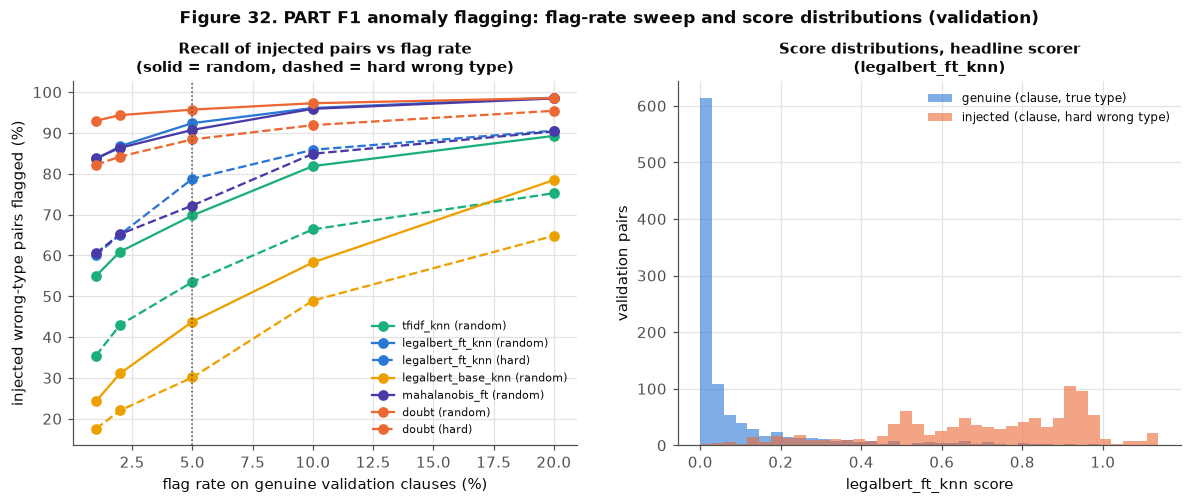

In [77]:
%%needs_models models/legalbert_lr5e-05_s42/best
# Per-type thresholds at a 5 % flag rate on genuine VALIDATION clauses, and the flag-rate sweep (validation, P1 pairs)
gen_val = {nm: score_pairs(nm, VALC.index.values, VALC.category.values) for nm in list(SCORERS) + ["doubt"]}
THR = {nm: AN.thresholds_at(gen_val[nm], VALC.category.values, LABELS, 0.05) for nm in gen_val}
pr_r = AN.make_pairs(VALC, LABELS, None, seed=42); pr_h = AN.make_pairs(VALC, LABELS, HARD, seed=42)
sweep = []
for rate in [0.01, 0.02, 0.05, 0.10, 0.20]:
    for nm in gen_val:
        th = AN.thresholds_at(gen_val[nm], VALC.category.values, LABELS, rate)
        for kind, pr in [("random", pr_r), ("hard", pr_h)]:
            inj = pr[pr.injected == 1]
            sweep.append({"flag rate on genuine validation clauses": rate, "scorer": nm, "wrong type": kind,
                          "recall of injected pairs": AN.flagged(score_pairs(nm, inj.pos.values, inj.claimed.values), inj.claimed.values, th).mean()})
SW = pd.DataFrame(sweep); SW.to_csv(C.RESULTS_DIR / "anomaly_flag_rate_sweep.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
cols = {"tfidf_knn": PL.AQUA, "legalbert_ft_knn": PL.BLUE, "legalbert_base_knn": PL.YELLOW, "mahalanobis_ft": PL.VIOLET, "doubt": PL.ORANGE}
for nm in gen_val:
    for kind, ls in [("random", "-"), ("hard", "--")]:
        g = SW[(SW.scorer == nm) & (SW["wrong type"] == kind)]
        axes[0].plot(100 * g["flag rate on genuine validation clauses"], 100 * g["recall of injected pairs"], ls, marker="o", color=cols[nm],
                     label=f"{nm} ({kind})" if kind == "random" or nm in (HEAD, "doubt") else None)
axes[0].axvline(5, color=PL.INK_2, linestyle=":", linewidth=1)
axes[0].set_xlabel("flag rate on genuine validation clauses (%)"); axes[0].set_ylabel("injected wrong-type pairs flagged (%)")
axes[0].set_title("Recall of injected pairs vs flag rate\n(solid = random, dashed = hard wrong type)", fontsize=10); axes[0].legend(fontsize=7)
s_gen = gen_val[HEAD]; s_inj = score_pairs(HEAD, pr_h[pr_h.injected == 1].pos.values, pr_h[pr_h.injected == 1].claimed.values)
bins = np.linspace(min(s_gen.min(), s_inj.min()), max(s_gen.max(), s_inj.max()), 40)
axes[1].hist(s_gen, bins=bins, alpha=0.6, color=PL.BLUE, label="genuine (clause, true type)")
axes[1].hist(s_inj, bins=bins, alpha=0.6, color=PL.ORANGE, label="injected (clause, hard wrong type)")
axes[1].set_xlabel(f"{HEAD} score"); axes[1].set_ylabel("validation pairs"); axes[1].legend(fontsize=8)
axes[1].set_title(f"Score distributions, headline scorer\n({HEAD})", fontsize=10)
fig.suptitle("Figure 32. PART F1 anomaly flagging: flag-rate sweep and score distributions (validation)", fontweight="bold", y=1.03, fontsize=11)
PL.savefig(fig, 32, "anomaly_validation"); plt.show()

In [78]:
%%needs_models models/legalbert_lr5e-05_s42/best
# TEST: P1 (random / hard), P2 (Legal-BERT's own errors, scored against the PREDICTED type), P3 (557 multi-type clauses)
TESTC = df.iloc[POS["test"]].copy(); TESTC.index = POS["test"]
assert (TESTC.row_id.values == test.row_id.values).all()
LB_PRED = PRED["legalbert"]
pt_r = AN.make_pairs(TESTC, LABELS, None, seed=42); pt_h = AN.make_pairs(TESTC, LABELS, HARD, seed=42)
gen_test = {nm: score_pairs(nm, TESTC.index.values, TESTC.category.values) for nm in gen_val}
amb_pairs = pd.DataFrame([(i, c, AMB.contract.iloc[i]) for i, v in enumerate(valid) for c in v], columns=["apos", "claimed", "contract"])
rows, TEST_SCORES = [], {}
for nm in gen_val:
    res = {}
    for kind, pr in [("P1 random", pt_r), ("P1 hard", pt_h)]:
        s = score_pairs(nm, pr.pos.values, pr.claimed.values)
        r = AN.auc_ci(pr.injected.values, s, pr.contract.values)
        inj = pr.injected.values == 1
        r["recall_at_5pct"] = float(AN.flagged(s[inj], pr.claimed.values[inj], THR[nm]).mean())
        r["flag_rate_genuine"] = float(AN.flagged(s[~inj], pr.claimed.values[~inj], THR[nm]).mean())
        res[kind] = r
        if kind == "P1 random":
            TEST_SCORES[nm] = pr.assign(score=s)
    s2 = score_pairs(nm, TESTC.index.values, LB_PRED)
    err = (LB_PRED != TESTC.category.values).astype(int)
    r2 = AN.auc_ci(err, s2, TESTC.contract.values)
    r2["recall_at_5pct"] = float(AN.flagged(s2[err == 1], LB_PRED[err == 1], THR[nm]).mean())
    r2["flag_rate_genuine"] = float(AN.flagged(s2[err == 0], LB_PRED[err == 0], THR[nm]).mean())
    res["P2 own errors"] = r2
    s3 = score_pairs(nm, amb_pairs.apos.values, amb_pairs.claimed.values, ambiguous=True)
    y3 = np.r_[np.ones(len(s3)), np.zeros(len(gen_test[nm]))]
    r3 = AN.auc_ci(y3, np.r_[s3, gen_test[nm]], np.r_[amb_pairs.contract.values, TESTC.contract.values])
    r3["recall_at_5pct"] = float(AN.flagged(s3, amb_pairs.claimed.values, THR[nm]).mean())
    r3["flag_rate_genuine"] = float(AN.flagged(gen_test[nm], TESTC.category.values, THR[nm]).mean())
    res["P3 multi-type clauses"] = r3
    for k, r in res.items():
        rows.append({"scorer": nm, "family": FAMILY[nm], "status": "HEADLINE (test-once)" if nm == HEAD else "analysis only", "proxy": k,
                     "AUROC": r["auroc"], "AUROC 95% CI": f"[{r['auroc_ci'][0]:.3f}, {r['auroc_ci'][1]:.3f}]", "AUPR": r["aupr"],
                     "recall at 5 % operating point": r["recall_at_5pct"], "flag rate on genuine / correct": r["flag_rate_genuine"],
                     "positives / n": f"{r['positives']} / {r['n']}"})
    if nm == HEAD:
        HEAD_RES = res
ATEST = pd.DataFrame(rows); ATEST.to_csv(C.RESULTS_DIR / "anomaly_test.csv", index=False)
display(ATEST.round(3))
cfg_an = {"scorer": HEAD, "k": 5, "fit_on": "train", "threshold": "per type, 95th percentile of genuine validation scores (5 % flag rate)",
          "selection": "best mean validation AUROC (P1 random + hard) among the unusual-wording scorers"}
C.test_once_scores(f"anomaly_{HEAD}", cfg_an, {k: {kk: vv for kk, vv in v.items()} for k, v in HEAD_RES.items()},
                   TEST_SCORES[HEAD][["row_id", "contract", "true", "claimed", "injected", "score"]],
                   {"macro_f1": HEAD_RES["P1 random"]["auroc"], "accuracy": HEAD_RES["P1 hard"]["auroc"],
                    "weighted_f1": HEAD_RES["P1 random"]["recall_at_5pct"]},
                   reason="Part F1 anomaly scorer: macro_f1 column = AUROC P1 random, accuracy column = AUROC P1 hard, "
                          "weighted_f1 column = recall of injected pairs at the 5 % operating point")

,scorer,family,status,proxy,AUROC,AUROC 95% CI,AUPR,recall at 5 % operating point,flag rate on genuine / correct,positives / n
0,tfidf_knn,unusual wording,analysis only,P1 random,0.945,"[0.935, 0.954]",0.932,0.722,0.073,1444 / 2888
1,tfidf_knn,unusual wording,analysis only,P1 hard,0.891,"[0.878, 0.903]",0.873,0.522,0.073,1444 / 2888
2,tfidf_knn,unusual wording,analysis only,P2 own errors,0.735,"[0.692, 0.780]",0.230,0.247,0.050,158 / 1444
3,tfidf_knn,unusual wording,analysis only,P3 multi-type clauses,0.545,"[0.510, 0.582]",0.470,0.057,0.073,1163 / 2607
4,legalbert_ft_knn,unusual wording,HEADLINE (test-once),P1 random,0.988,"[0.982, 0.992]",0.983,0.923,0.076,1444 / 2888
5,legalbert_ft_knn,unusual wording,HEADLINE (test-once),P1 hard,0.964,"[0.955, 0.973]",0.952,0.790,0.076,1444 / 2888
6,legalbert_ft_knn,unusual wording,HEADLINE (test-once),P2 own errors,0.867,"[0.840, 0.892]",0.433,0.247,0.018,158 / 1444
7,legalbert_ft_knn,unusual wording,HEADLINE (test-once),P3 multi-type clauses,0.714,"[0.684, 0.745]",0.622,0.181,0.076,1163 / 2607
8,legalbert_base_knn,unusual wording,analysis only,P1 random,0.882,"[0.867, 0.898]",0.839,0.454,0.080,1444 / 2888
9,legalbert_base_knn,unusual wording,analysis only,P1 hard,0.823,"[0.806, 0.843]",0.778,0.329,0.080,1444 / 2888


[test] anomaly_legalbert_ft_knn: already evaluated once (see test_eval_log.csv); re-run reproduced the identical scores.


{'P1 random': {'auroc': 0.9875399014740527,
  'aupr': 0.9833961476318099,
  'auroc_ci': [0.9819936852944958, 0.9920332443815687],
  'aupr_ci': [0.975557758462164, 0.9899727598976789],
  'positives': 1444,
  'n': 2888,
  'recall_at_5pct': 0.9231301939058172,
  'flag_rate_genuine': 0.07617728531855955},
 'P1 hard': {'auroc': 0.9644814534879259,
  'aupr': 0.9523301016689101,
  'auroc_ci': [0.955085970709894, 0.9731395524834101],
  'aupr_ci': [0.9388942207678047, 0.9654900807914744],
  'positives': 1444,
  'n': 2888,
  'recall_at_5pct': 0.7901662049861495,
  'flag_rate_genuine': 0.07617728531855955},
 'P2 own errors': {'auroc': 0.8665866094454396,
  'aupr': 0.433033380605453,
  'auroc_ci': [0.8398157679826352, 0.89211781202077],
  'aupr_ci': [0.35338025284128116, 0.5210725413384847],
  'positives': 158,
  'n': 1444,
  'recall_at_5pct': 0.2468354430379747,
  'flag_rate_genuine': 0.017884914463452566},
 'P3 multi-type clauses': {'auroc': 0.713814449687145,
  'aupr': 0.6221185155122044,
  'au

**Interpretation — PART F1 (`results/anomaly_validation.csv`, `results/anomaly_test.csv`, Figure 32). Proxy-evaluated only,
not human-validated.**
* **Choice on validation:** within the "unusual wording" family, the **fine-tuned Legal-BERT embedding kNN** is best (mean
  AUROC 0.976 over random and hard injected pairs). It beats Mahalanobis (0.958), TF-IDF kNN (0.913) and the non-fine-tuned
  embedding kNN (0.848). The doubt score 1 − p(type) is higher still (0.987), but it measures a different thing and was not
  eligible as the headline.
* **Test (headline, evaluated once):**
  - **P1 injected wrong-type pairs:** AUROC **0.988** [0.982, 0.992] with random wrong types and **0.964** [0.955, 0.973] with
    hard ones. At the 5 % operating point it flags 92 % (random) and 79 % (hard) of the injected pairs. On genuine test clauses
    the flag rate is **7.6 %** instead of the 5 % set on validation, so the thresholds transfer only approximately.
  - **P2 the classifier's own errors** (scored against Legal-BERT's predicted type): AUROC 0.867 [0.840, 0.892]. Only 25 % of the
    158 errors are flagged at the operating point, while just 1.8 % of the correct predictions are.
  - **P3 the 557 multi-type clauses:** AUROC 0.714 [0.684, 0.745]. Clauses that genuinely belong to two types look more unusual
    for each of them than clean clauses do, as expected. Only 18 % are flagged.
* **The two families, side by side.** The doubt score is at least as good on every proxy (P1 0.993 / 0.983, P2 0.875, P3 0.849).
  That is no surprise: every proxy is about the *type*, and the classifier was trained for exactly that. The contrast inside
  the wording family is the informative part. With the **non-fine-tuned** Legal-BERT space the same kNN reaches only 0.882 /
  0.823 on P1, and P3 falls *below* 0.5 (0.430). Its scores also correlate negatively with clause length (Spearman −0.35):
  general embeddings mostly react to form. The fine-tuned space has learnt what distinguishes the 27 types, so "far from the
  type's training clauses" there means "far in a type-aware sense". The headline wording score is therefore **partly type
  information inherited from fine-tuning**, not pure surface oddity. The honest conclusion is that a clause-embedding kNN in the
  fine-tuned space detects mislabelled or atypical clauses well on proxies. Whether its flags match what a lawyer finds
  "unusual" is **not assessed**, because the blind review was not filled.

In [79]:
%%needs_models models/legalbert_lr5e-05_s42/best
# Is the headline score just clause length? Spearman correlation with the number of words (genuine test pairs)
from scipy.stats import spearmanr
TESTC["head_score"] = gen_test[HEAD]; TESTC["doubt_score"] = gen_test["doubt"]
TESTC["flag"] = AN.flagged(gen_test[HEAD], TESTC.category.values, THR[HEAD])
TESTC["excess"] = gen_test[HEAD] - np.array([THR[HEAD][c] for c in TESTC.category])
len_corr = {nm: float(spearmanr(gen_test[nm], TESTC.n_words).correlation) for nm in gen_test}
print("Spearman correlation of each score with clause length (words), genuine test clauses:", {k: round(v, 3) for k, v in len_corr.items()})
q1, q3 = TESTC.n_words.quantile([0.25, 0.75])
normal = TESTC[TESTC.flag & TESTC.n_words.between(q1, q3)].sort_values("excess", ascending=False)
print(f"Test flag rate of the headline scorer: {TESTC.flag.mean():.3f} (5 % on validation by construction). "
      f"{len(normal)} of {TESTC.flag.sum()} flagged clauses have a normal length ({q1:.0f}-{q3:.0f} words, the middle 50 %). Examples:")
display(normal.head(5)[["row_id", "category", "n_words", "text"]].assign(text=lambda d: d.text.str[:220]))
json.dump({"spearman_with_length": len_corr, "test_flag_rate": float(TESTC.flag.mean()), "flagged": int(TESTC.flag.sum()),
           "flagged_normal_length": int(len(normal))}, open(C.RESULTS_DIR / "anomaly_length_check.json", "w"), indent=2)

Spearman correlation of each score with clause length (words), genuine test clauses: {'tfidf_knn': 0.108, 'legalbert_ft_knn': 0.098, 'legalbert_base_knn': -0.348, 'mahalanobis_ft': 0.02, 'doubt': 0.077}
Test flag rate of the headline scorer: 0.076 (5 % on validation by construction). 34 of 110 flagged clauses have a normal length (27-63 words, the middle 50 %). Examples:


,row_id,category,n_words,text
2035,2035,Anti-Assignment,29,"The Parties agree that ECOPETROL may declare the termination in advance of the Contract at any time, without any indemnity in favor of the SENDER in the following events:"
5570,5570,Anti-Assignment,50,"This Agreement may also be terminated by MusclePharm, upon fifteen days prior written notice, if death, or physical disability, physical injury, or other incapacity lasting more than eight (8) wee..."
2758,2758,Exclusivity,42,"Each Party agrees that it will not circumvent or attempt to circumvent the other by contacting or participating with any third party with respect to, or otherwise attempting to consummate, the tra..."
2764,2764,Minimum Commitment,49,"During the term of this Agreement, and so long as Oxbow continues to own at least 15,000 common shares of Global Energy (as such amount may be adjusted to reflect any subsequent stock splits), Glo..."
7158,7158,Exclusivity,55,"The Insurance Center shall be hosted solely by ebix and contained in an About Wrapper and ebix shall, during the Term, provide site maintenance services relative to the Insurance Center substantia..."


In [80]:
%%needs_models models/legalbert_lr5e-05_s42/best
# Blind review sheet (optional, for the student to fill in) of the top flags and 30 random unflagged clauses
fl = TESTC[TESTC.flag].sort_values("excess", ascending=False)
groups_ = {c: list(g.sort_values("excess", ascending=False).index) for c, g in fl.groupby("category")}
TOP = []
while len(TOP) < 30 and any(groups_.values()):                  # round robin over types -> spread over many types
    for c in sorted(groups_, key=lambda c: -fl.loc[groups_[c][0], "excess"] if groups_[c] else 0):
        if groups_[c]:
            TOP.append(groups_[c].pop(0))
        if len(TOP) >= 30:
            break
rng_ = np.random.default_rng(42)
unfl = TESTC[~TESTC.flag].index.values
RAND = list(rng_.choice(unfl, 30, replace=False))
sheet_file, key_file = C.RESULTS_DIR / "anomaly_review_sheet.csv", C.RESULTS_DIR / "anomaly_review_key.csv"
filled = sheet_file.exists() and pd.read_csv(sheet_file).unusual_for_type.notna().any()
if not filled:
    items = pd.DataFrame({"pos": TOP + RAND, "group": ["flagged"] * 30 + ["random unflagged"] * 30}).sample(frac=1, random_state=7).reset_index(drop=True)
    items["id"] = [f"R{i + 1:02d}" for i in range(len(items))]
    sheet = pd.DataFrame({"id": items.id, "type": TESTC.loc[items.pos, "category"].values, "clause_text": TESTC.loc[items.pos, "text"].values,
                          "unusual_for_type": "", "reason": ""})
    sheet.to_csv(sheet_file, index=False)
    items.assign(row_id=TESTC.loc[items.pos, "row_id"].values)[["id", "row_id", "group"]].to_csv(key_file, index=False)
    print(f"Review sheet written: {sheet_file.name} ({len(sheet)} clauses, {sheet.type.nunique()} types, flagged clauses from "
          f"{TESTC.loc[TOP, 'category'].nunique()} types). Labels are EMPTY -> flags are proxy-evaluated only, NOT human-validated; "
          "O6 human part: not assessed.")
else:
    sh = pd.read_csv(sheet_file).merge(pd.read_csv(key_file), on="id")
    yes = sh.unusual_for_type.str.lower().eq("yes")
    print("Filled review sheet found: yes-rate flagged", yes[sh.group == "flagged"].mean(), "vs random", yes[sh.group != "flagged"].mean())

Review sheet written: anomaly_review_sheet.csv (60 clauses, 23 types, flagged clauses from 21 types). Labels are EMPTY -> flags are proxy-evaluated only, NOT human-validated; O6 human part: not assessed.


**Length check (descriptive, not validation).** The headline score is almost independent of clause length (Spearman 0.10), and
34 of the 110 flagged test clauses have a normal length (27–63 words). The top flags are therefore not simply very short or very
long clauses.

**Blind review.** `results/anomaly_review_sheet.csv` holds 30 flagged and 30 random unflagged test clauses, shuffled, without
scores, with empty label columns (the key is in `results/anomaly_review_key.csv` — do not open it before reviewing). It has
**not** been filled, so the flags are **proxy-evaluated only, not human-validated**, and the human part of objective O6 is
**not assessed**.

**Responsible use.** A flag directs a reviewer's attention; it is not a legal conclusion. "Unusual" does not mean "wrong" or
"risky", and false flags cost reviewer time (7.6 % of genuine test clauses are flagged).

## 9. PART F — EXTRA CHALLENGING WORK: F3 LoRA vs full fine-tuning (Task 1)
**Question.** Can parameter-efficient fine-tuning (LoRA) match full fine-tuning of Legal-BERT on our 27 classes, and what does
it save? **Set-up (identical to section 5 except the trainable parameters):** same data, split, recipe (batch 16, 5 epochs,
warm-up 10 %, weight decay 0.01, max length 320, bf16), seeds (42, 43, 44) and metric. LoRA (Hu et al., 2022) freezes the
pre-trained weights and learns small low-rank updates *W + BA* (rank 16, scaling α = 32, dropout 0.1) for the attention
**query** and **value** matrices; the classification head is trained fully. Learning rate from {1e-4, 3e-4, 1e-3} on
validation (seed 42; rule fixed before the runs: best validation macro-F1, ties → smaller lr); seeds 43 and 44 at that lr; the
test model is seed 42 (`legalbert_lora`, evaluated once: `python scripts/train_lora.py --test`).

,run_id,lr,seed,best_epoch,val_macro_f1,mean_epoch_seconds,run_seconds,peak_gpu_mem_gb,trainable_params
0,legalbert_lr1e-04_s42_lora,0.0001,42,5,0.5345,11.5821,64.5325,2.3373,610587
1,legalbert_lr3e-04_s42_lora,0.0003,42,5,0.7751,11.4227,63.7664,2.3311,610587
2,legalbert_lr1e-03_s42_lora,0.0010,42,5,0.8302,11.3547,63.4215,2.3311,610587
3,legalbert_lr1e-03_s43_lora,0.0010,43,5,0.8094,11.4163,63.6025,2.3185,610587
4,legalbert_lr1e-03_s44_lora,0.0010,44,5,0.8231,11.4170,63.5613,2.3269,610587


Chosen lr: 1e-03 (top of the grid; every run's best epoch is its last one). Validation macro-F1 over 3 seeds: 0.8209 ± 0.0106


,method,trainable parameters,share trainable %,time per epoch (s),"total training (s, final run)",peak GPU memory (GB),saved weights (MB),validation macro-F1 (3 seeds),test macro-F1,test 95% CI,latency ms (batch 1)
0,full fine-tuning,109503003,100.000,17.354,94.254,3.697,438.740,0.8484 ± 0.0045,0.871,"[0.836, 0.896]",5.786
1,"LoRA r16 (query, value) + head",610587,0.558,11.396,63.422,2.326,3.158,0.8209 ± 0.0106,0.829,"[0.796, 0.862]",7.939


Full - LoRA on test macro-F1: +0.0419 [+0.0142, +0.0609] (paired contract bootstrap)


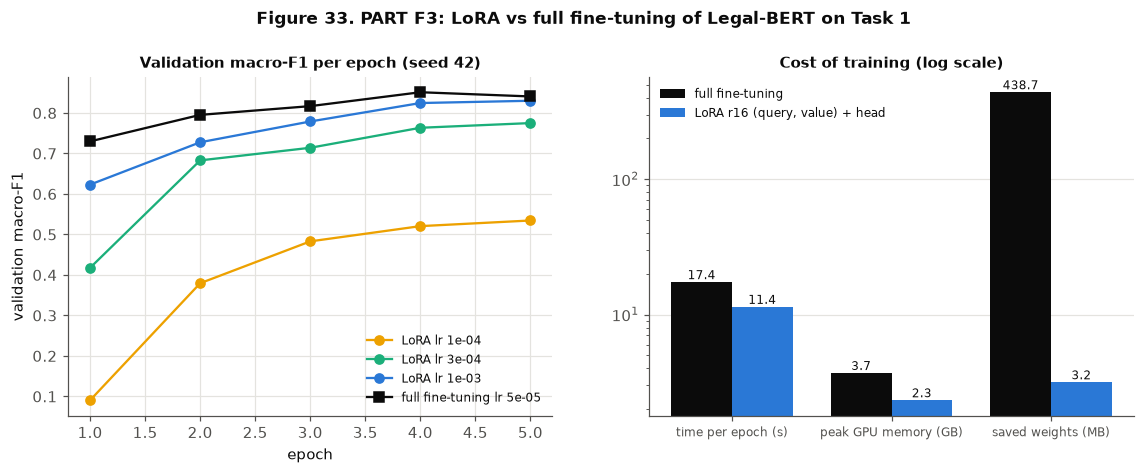

In [83]:
lsr = pd.read_csv(C.RESULTS_DIR / "transformer_lora_search.csv")
lch = json.load(open(C.RESULTS_DIR / "lora_choice.json"))
llog_ = pd.read_csv(C.RESULTS_DIR / "transformer_lora_log.csv")
display(lsr[["run_id", "lr", "seed", "best_epoch", "val_macro_f1", "mean_epoch_seconds", "run_seconds", "peak_gpu_mem_gb", "trainable_params"]].round(4))
print(f"Chosen lr: {lch['best_lr']:.0e} (top of the grid; every run's best epoch is its last one). Validation macro-F1 over 3 seeds: "
      f"{lch['val_macro_f1_mean']:.4f} ± {lch['val_macro_f1_std']:.4f}")
# the single test evaluation (re-check on notebook re-runs; the first evaluation was made by scripts/train_lora.py --test)
if not C.already_evaluated("legalbert_lora"):
    subprocess.run([sys.executable, "scripts/train_lora.py", "--test"], check=True)
lora_pred = pd.read_csv(C.RESULTS_DIR / "predictions" / "legalbert_lora.csv").set_index("row_id").loc[test.row_id].pred.astype(str).values
full_runs = tsr[(tsr.index.str.startswith("legalbert_lr5e-05")) & (~tsr.class_weighted)]
size_mb = lambda p: sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6
full_dir = ROOT / "models" / "legalbert_lr5e-05_s42" / "best"; lora_dir = ROOT / "models" / lch["test_run"] / "best"
lm = C.compute_metrics(YT, lora_pred, LABELS, "legalbert_lora", "test", save=False, robust_labels=ROBUST)
ci_l = C.bootstrap_ci(YT, lora_pred, CT, labels=LABELS)
pb_lf = C.paired_bootstrap(YT, PRED["legalbert"], lora_pred, CT, labels=LABELS)
lora_inf = json.load(open(C.RESULTS_DIR / "lora_inference.json"))
LCOMP = pd.DataFrame([
    {"method": "full fine-tuning", "trainable parameters": int(full_runs.params_million.iloc[0] * 1e6), "share trainable %": 100.0,
     "time per epoch (s)": float(full_runs.mean_epoch_seconds.mean()), "total training (s, final run)": float(tsr.loc["legalbert_lr5e-05_s42", "run_seconds"]),
     "peak GPU memory (GB)": float(full_runs.peak_gpu_mem_gb.mean()),
     "saved weights (MB)": size_mb(full_dir) if full_dir.exists() else np.nan,
     "validation macro-F1 (3 seeds)": f"{full_runs.val_macro_f1.mean():.4f} ± {full_runs.val_macro_f1.std():.4f}",
     "test macro-F1": METR["legalbert"]["macro_f1"], "test 95% CI": T1_TABLE.set_index("key").loc["legalbert", "95% CI"],
     "latency ms (batch 1)": eff["legalbert"][1]},
    {"method": "LoRA r16 (query, value) + head", "trainable parameters": int(lsr.trainable_params.iloc[0]),
     "share trainable %": 100 * lsr.trainable_params.iloc[0] / (full_runs.params_million.iloc[0] * 1e6),
     "time per epoch (s)": float(lsr[lsr.lr == lch["best_lr"]].mean_epoch_seconds.mean()),
     "total training (s, final run)": float(lsr.set_index("run_id").loc[lch["test_run"], "run_seconds"]),
     "peak GPU memory (GB)": float(lsr[lsr.lr == lch["best_lr"]].peak_gpu_mem_gb.mean()),
     "saved weights (MB)": size_mb(lora_dir) if lora_dir.exists() else np.nan,
     "validation macro-F1 (3 seeds)": f"{lch['val_macro_f1_mean']:.4f} ± {lch['val_macro_f1_std']:.4f}",
     "test macro-F1": lm["macro_f1"], "test 95% CI": f"[{ci_l['ci_low']:.3f}, {ci_l['ci_high']:.3f}]", "latency ms (batch 1)": lora_inf["median_ms"]}])
display(LCOMP.round(3))
LCOMP.to_csv(C.RESULTS_DIR / "lora_vs_full.csv", index=False)
print(f"Full - LoRA on test macro-F1: {pb_lf['diff']:+.4f} [{pb_lf['ci_low']:+.4f}, {pb_lf['ci_high']:+.4f}] (paired contract bootstrap)")
json.dump({"paired_full_minus_lora": pb_lf, "lora_test": {k: lm[k] for k in ["macro_f1", "macro_f1_robust", "accuracy", "weighted_f1"]},
           "lora_ci": ci_l}, open(C.RESULTS_DIR / "lora_results.json", "w"), indent=2, default=float)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
for rid, col in [("legalbert_lr1e-04_s42_lora", PL.YELLOW), ("legalbert_lr3e-04_s42_lora", PL.AQUA), ("legalbert_lr1e-03_s42_lora", PL.BLUE)]:
    ep = llog_[(llog_.run_id == rid) & (llog_.kind == "epoch")]
    axes[0].plot(ep.epoch, ep.val_macro_f1, "o-", color=col, label=f"LoRA lr {rid.split('_lr')[1].split('_')[0]}")
fl_log = pd.read_csv(C.RESULTS_DIR / "transformer_log.csv")
ep = fl_log[(fl_log.run_id == "legalbert_lr5e-05_s42") & (fl_log.kind == "epoch")]
axes[0].plot(ep.epoch, ep.val_macro_f1, "s-", color=PL.INK, label="full fine-tuning lr 5e-05")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation macro-F1"); axes[0].legend(fontsize=8); axes[0].set_title("Validation macro-F1 per epoch (seed 42)", fontsize=10)
metrics_ = ["time per epoch (s)", "peak GPU memory (GB)", "saved weights (MB)"]
x_ = np.arange(len(metrics_))
for i, (meth, col) in enumerate([("full fine-tuning", PL.INK), ("LoRA r16 (query, value) + head", PL.BLUE)]):
    vals = LCOMP.set_index("method").loc[meth, metrics_].astype(float).values
    b = axes[1].bar(x_ + (i - 0.5) * 0.38, vals, 0.38, color=col, label=meth); axes[1].bar_label(b, fmt="%.1f", fontsize=8)
axes[1].set_yscale("log"); axes[1].set_xticks(x_); axes[1].set_xticklabels(metrics_, fontsize=8); axes[1].legend(fontsize=8)
axes[1].set_title("Cost of training (log scale)", fontsize=10); axes[1].grid(axis="x", visible=False)
fig.suptitle("Figure 33. PART F3: LoRA vs full fine-tuning of Legal-BERT on Task 1", fontweight="bold", y=1.03, fontsize=11)
PL.savefig(fig, 33, "lora_vs_full"); plt.show()

**Interpretation — PART F3 (`results/lora_vs_full.csv`, `results/lora_results.json`, Figure 33).**
* **What LoRA saves:**
  - trains **0.61 M parameters (0.56 %)** instead of 109.5 M;
  - **11.4 s vs 17.4 s per epoch (−34 %)**;
  - **2.3 vs 3.7 GB peak GPU memory (−37 %)**;
  - **3.2 MB vs 439 MB** of saved weights (an adapter per task instead of a full model copy).
* **What it costs:** test macro-F1 **0.829** [0.796, 0.862] vs **0.871** for full fine-tuning. The paired difference is
  **+0.042** [+0.014, +0.061] in favour of full fine-tuning (validation: 0.821 ± 0.011 vs 0.848 ± 0.004 over 3 seeds). LoRA
  still beats the best classical model (0.794) and BERT-base (0.826). At batch size 1, the unmerged adapter is slightly
  *slower* at inference (7.9 vs 5.8 ms).
* **Why the gap:** within the fixed 5-epoch budget, the best learning rate was the top of the pre-declared grid (1e-3) and every
  LoRA run peaked in its last epoch (Figure 33, left). That suggested under-training, which the sensitivity runs below check.
* **Trade-off.** With a 110 M-parameter model and about 5,000 training clauses, full fine-tuning is cheap anyway (94 s on one
  GPU), so LoRA's savings matter little here. They would matter with many tasks or clients (one small adapter each), with
  larger models, or on GPUs with little memory.

**LoRA sensitivity (validation only; an extra analysis).** Is the gap to full fine-tuning mainly under-training? Two extra
runs with seed 42 (`python scripts/train_lora.py --sensitivity`; logged in `results/transformer_lora_sensitivity_*.csv`): (a) the
chosen lr 1e-3 for **10** epochs, (b) lr **3e-3** for 5 epochs. The tested LoRA model is unchanged.

In [84]:
lss = pd.read_csv(C.RESULTS_DIR / "transformer_lora_sensitivity_search.csv")
lsl = pd.read_csv(C.RESULTS_DIR / "transformer_lora_sensitivity_log.csv")
base42 = lsr.set_index("run_id").loc[lch["test_run"]]
SENS = pd.concat([pd.DataFrame([{"run": "tested LoRA (lr 1e-3, 5 epochs)", "best epoch": int(base42.best_epoch), "val macro-F1": base42.val_macro_f1}]),
                  pd.DataFrame([{"run": {"legalbert_lr1e-03_s42_sens_e10_lora": "lr 1e-3, 10 epochs", "legalbert_lr3e-03_s42_sens_lora": "lr 3e-3, 5 epochs"}[r.run_id],
                                 "best epoch": int(r.best_epoch), "val macro-F1": r.val_macro_f1} for r in lss.itertuples()])], ignore_index=True)
full42 = float(tsr.loc["legalbert_lr5e-05_s42", "val_macro_f1"])
SENS["gap to full fine-tuning (val, seed 42)"] = full42 - SENS["val macro-F1"]
display(SENS.round(4))
ep10 = lsl[(lsl.run_id == "legalbert_lr1e-03_s42_sens_e10_lora") & (lsl.kind == "epoch")][["epoch", "val_macro_f1"]]
print("lr 1e-3, 10 epochs - validation macro-F1 per epoch:", dict(zip(ep10.epoch, ep10.val_macro_f1.round(3))))
SENS.to_csv(C.RESULTS_DIR / "lora_sensitivity.csv", index=False)

,run,best epoch,val macro-F1,"gap to full fine-tuning (val, seed 42)"
0,"tested LoRA (lr 1e-3, 5 epochs)",5,0.8302,0.0211
1,"lr 1e-3, 10 epochs",7,0.8264,0.0249
2,"lr 3e-3, 5 epochs",2,0.0057,0.8455


lr 1e-3, 10 epochs - validation macro-F1 per epoch: {1: 0.501, 2: 0.712, 3: 0.756, 4: 0.786, 5: 0.812, 6: 0.807, 7: 0.826, 8: 0.826, 9: 0.818, 10: 0.809}


**Interpretation (`results/lora_sensitivity.csv`).** The gap is **not mainly under-training**:
* With 10 epochs at lr 1e-3, LoRA peaks at validation macro-F1 0.826 in epoch 7 and then declines. That is no better than the
  0.830 of the tested 5-epoch run: the longer schedule changes the learning-rate decay, and the extra epochs over-fit rather
  than help.
* With lr 3e-3 training diverges (macro-F1 about 0.006: the model predicts essentially one class).

So the remaining gap of about 0.02 macro-F1 on validation (0.04 on test) between LoRA r16 on query/value and full fine-tuning
looks like a **capacity limit of this LoRA configuration**: only 0.56 % of the weights adapt, and the feed-forward layers are
frozen. It is not a too-short schedule. More target modules or a higher rank would be the next things to try (not done).

## 10. Objectives O1–O6 (final verdicts)

In [85]:
%%needs_models models/legalbert_lr5e-05_s42/best
o5 = json.load(open(C.RESULTS_DIR / "objective_O5_legalbert.json"))
OBJ = pd.DataFrame([
    {"objective": "O1", "criterion": "all Task 1 models on the same 1,444 test clauses (93 contracts); Task 2 on the 102 official test contracts",
     "verdict": "met", "evidence": "results/test_eval_log.csv (one entry per model, forced = False); task1_comparison_table.csv; task2_test_summary.csv"},
    {"objective": "O2", "criterion": "best TF-IDF classifier beats the majority baseline by a wide margin",
     "verdict": "met", "evidence": f"TF-IDF LogReg - majority = {new['diff']:+.3f} [{new['ci_low']:+.3f}, {new['ci_high']:+.3f}] (task1_paired_bootstraps.csv)"},
    {"objective": "O3", "criterion": "fine-tuned transformer vs best classical vs two prompted LLMs on macro-F1, cost per 1,000 clauses and latency",
     "verdict": "met", "evidence": "task1_comparison_table.csv, task1_paired_bootstraps.csv, llm_cost.json (second LLM = Qwen2.5-3B, deviation D3)"},
    {"objective": "O4", "criterion": "Task 2: Legal-BERT extractor beats the TF-IDF segment baseline (paired CI above 0) and is compared with CUAD's published AUPR",
     "verdict": "met", "evidence": f"+{t2c['paired_tagger_vs_baseline']['diff']:.3f} [{t2c['paired_tagger_vs_baseline']['ci_low']:+.3f}, "
                                   f"{t2c['paired_tagger_vs_baseline']['ci_high']:+.3f}]; CUAD comparison in Task 2 section 7 (not like-for-like)"},
    {"objective": "O5", "criterion": "(exploratory) recall >= 0.70 for every Task 1 class on test",
     "verdict": "not met", "evidence": "results/objective_O5_legalbert.json (Legal-BERT below 0.70: Non-Transferable License, Change Of Control)"},
    {"objective": "O6", "criterion": "(Part F) best anomaly scorer detects injected wrong-type clauses with AUROC CI above 0.5; human part only if the blind review is done",
     "verdict": ("proxy part: " + ("met" if HEAD_RES["P1 random"]["auroc_ci"][0] > 0.5 else "not met") + "; human part: "
                 + ("see review results" if filled else "not assessed (review sheet not filled)")),
     "evidence": (f"{HEAD}: test AUROC P1 random {HEAD_RES['P1 random']['auroc']:.3f} "
                  f"[{HEAD_RES['P1 random']['auroc_ci'][0]:.3f}, {HEAD_RES['P1 random']['auroc_ci'][1]:.3f}], hard "
                  f"{HEAD_RES['P1 hard']['auroc']:.3f} (results/anomaly_test.csv); flags are proxy-evaluated only, not human-validated")}])
display(OBJ)
OBJ.to_csv(C.RESULTS_DIR / "objectives.csv", index=False)

,objective,criterion,verdict,evidence
0,O1,"all Task 1 models on the same 1,444 test clauses (93 contracts); Task 2 on the 102 official test contracts",met,"results/test_eval_log.csv (one entry per model, forced = False); task1_comparison_table.csv; task2_test_summary.csv"
1,O2,best TF-IDF classifier beats the majority baseline by a wide margin,met,"TF-IDF LogReg - majority = +0.788 [+0.746, +0.819] (task1_paired_bootstraps.csv)"
2,O3,"fine-tuned transformer vs best classical vs two prompted LLMs on macro-F1, cost per 1,000 clauses and latency",met,"task1_comparison_table.csv, task1_paired_bootstraps.csv, llm_cost.json (second LLM = Qwen2.5-3B, deviation D3)"
3,O4,Task 2: Legal-BERT extractor beats the TF-IDF segment baseline (paired CI above 0) and is compared with CUAD's published AUPR,met,"+0.129 [+0.099, +0.155]; CUAD comparison in Task 2 section 7 (not like-for-like)"
4,O5,(exploratory) recall >= 0.70 for every Task 1 class on test,not met,"results/objective_O5_legalbert.json (Legal-BERT below 0.70: Non-Transferable License, Change Of Control)"
5,O6,(Part F) best anomaly scorer detects injected wrong-type clauses with AUROC CI above 0.5; human part only if the blind review is done,proxy part: met; human part: not assessed (review sheet not filled),"legalbert_ft_knn: test AUROC P1 random 0.988 [0.982, 0.992], hard 0.964 (results/anomaly_test.csv); flags are proxy-evaluated only, not human-validated"


## 11. DEMO — classify any clause and flag it if it reads unusually
Paste any clause into `MY_CLAUSES`. For the same clauses, **side by side**: the three most likely types with probabilities from
the best classical model (TF-IDF character n-grams + logistic regression, refit here from its saved configuration in a few
seconds) and from the fine-tuned Legal-BERT, plus the Part F1 flag saying whether the clause reads unusually for each model's
predicted type (threshold: 5 % of genuine validation clauses). Everything is loaded from saved files, so this group runs on its own.
**Without `models/`** (e.g. on Colab) the logistic regression still runs live; the Legal-BERT columns and the flags then show
the **saved output of the real run** for clauses the demo has seen before (`results/demo_cache.json`), and the table says so
in its `source` column.

In [86]:
# DEMO setup: refit the best classical model (seconds, no GPU) and, if models/ is present, load the saved Legal-BERT,
# the cached training embeddings and the validation thresholds of the anomaly flag
import time, json
from sklearn.feature_extraction.text import TfidfVectorizer as _TV2
from sklearn.linear_model import LogisticRegression as _LR2
from sklearn.pipeline import make_pipeline as _mp
from src.preprocess import clean_text as _clean, preprocess_for_transformer
from src import common as C
_tr = (df.split == "train").values; _va = (df.split == "validation").values
# best classical model, refit from its saved test-once configuration (identical predictions to the evaluated model)
_cfg = json.loads(pd.read_csv(C.RESULTS_DIR / "test_eval_log.csv").set_index("model").loc["tfidf_logreg", "config"])
demo_lr = _mp(_TV2(analyzer="char_wb", preprocessor=lambda s_: _clean(s_, _cfg["preprocessing"]), lowercase=False, ngram_range=(3, 6),
                   min_df=int(_cfg["min_df"]), max_df=float(_cfg["max_df"]), sublinear_tf=True),
              _LR2(C=float(_cfg["C_or_alpha"]), class_weight="balanced", max_iter=3000))
demo_lr.fit(df[_tr].text, df[_tr].category)
_dir, _feat = ROOT / "models" / "legalbert_lr5e-05_s42" / "best", ROOT / "models" / "anomaly_cache" / "features.npz"
DEMO_LIVE = _dir.exists() and _feat.exists()
if DEMO_LIVE:
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    from src import anomaly as AN
    from src.finetune import RECIPE as FT
    demo_tok = AutoTokenizer.from_pretrained(_dir)
    demo_model = AutoModelForSequenceClassification.from_pretrained(_dir).to("cuda" if torch.cuda.is_available() else "cpu").eval()
    _fe = np.load(_feat)
    demo_knn = AN.KNNScorer(_fe["emb_ft"][_tr], df.category.values[_tr], LABELS)
    demo_thr = AN.thresholds_at(demo_knn.score(_fe["emb_ft"][_va], df.category.values[_va]), df.category.values[_va], LABELS, 0.05)
    demo_labels = [demo_model.config.id2label[i] for i in range(len(LABELS))]
else:
    print("models/ not found (normal on Colab): the logistic regression runs live; the Legal-BERT columns and the flags show "
          "the SAVED output of the real run where available (results/demo_cache.json).")

def classify(clauses):
    top3 = lambda row, names: "; ".join(f"{names[i]} {row[i]:.2f}" for i in np.argsort(-row)[:3])
    PL_ = demo_lr.predict_proba(clauses); lr_cls = list(demo_lr.classes_)
    lr_top = [top3(r, lr_cls) for r in PL_]
    if DEMO_LIVE:
        dev = next(demo_model.parameters()).device
        enc = demo_tok([preprocess_for_transformer(t) for t in clauses], truncation=True, max_length=FT["max_length"], padding=True,
                       return_tensors="pt").to(dev)
        with torch.no_grad(), torch.autocast(device_type=dev.type, dtype=torch.bfloat16, enabled=dev.type == "cuda"):
            out = demo_model(**enc, output_hidden_states=True)
        P = torch.softmax(out.logits.float(), -1).cpu().numpy()
        m = enc["attention_mask"].unsqueeze(-1).float(); E = ((out.hidden_states[-1].float() * m).sum(1) / m.sum(1)).cpu().numpy()
        flag = lambda preds: ["UNUSUAL" if sc > demo_thr[pr] else "typical" for sc, pr in zip(demo_knn.score(E, preds), preds)]
        rest = [{"flag (LogReg type)": fl, "Legal-BERT: top 3": top3(r, demo_labels), "flag (Legal-BERT type)": fb}
                for fl, r, fb in zip(flag([lr_cls[i] for i in PL_.argmax(1)]), P, flag([demo_labels[i] for i in P.argmax(1)]))]
        for t, r in zip(clauses, rest):
            C.demo_cache_put("task1", t, r)            # lets the demo show this real output where models/ is absent
        source = ["live"] * len(clauses)
    else:
        na = "n/a (needs models/)"
        saved = [C.demo_cache_get("task1", t) for t in clauses]
        rest = [r or {"flag (LogReg type)": na, "Legal-BERT: top 3": na, "flag (Legal-BERT type)": na} for r in saved]
        source = ["LogReg live; rest SAVED from the real run" if r else "LogReg live; rest not available" for r in saved]
    out_tab = pd.DataFrame([{"clause": t[:90] + ("..." if len(t) > 90 else ""), "TF-IDF + LogReg: top 3": lt, **r, "source": s}
                            for t, lt, r, s in zip(clauses, lr_top, rest, source)])
    with pd.option_context("display.max_colwidth", 120):
        display(out_tab)
    return out_tab

In [87]:
MY_CLAUSES = [
    "Neither party may assign this Agreement without the prior written consent of the other party, except to an Affiliate.",
    "In no event shall either party be liable for any indirect, incidental or consequential damages, and each party's total "
    "liability shall not exceed the fees paid in the twelve months before the claim.",
    "Either party may terminate this Agreement for any reason upon sixty (60) days' prior written notice to the other party.",
    "South Dakota",                                     # a fragment, as found among the top anomaly flags
]
t0 = time.perf_counter(); classify(MY_CLAUSES); print(f"({time.perf_counter() - t0:.2f} s)")

,clause,TF-IDF + LogReg: top 3,flag (LogReg type),Legal-BERT: top 3,flag (Legal-BERT type),source
0,Neither party may assign this Agreement without the prior written consent of the other par...,Anti-Assignment 0.97; Change Of Control 0.00; Termination For Convenience 0.00,typical,Anti-Assignment 1.00; Change Of Control 0.00; Non-Transferable License 0.00,typical,live
1,"In no event shall either party be liable for any indirect, incidental or consequential dam...",Cap On Liability 0.98; Liquidated Damages 0.00; Volume Restriction 0.00,typical,Cap On Liability 1.00; Liquidated Damages 0.00; Warranty Duration 0.00,typical,live
2,Either party may terminate this Agreement for any reason upon sixty (60) days' prior writt...,Termination For Convenience 0.99; Change Of Control 0.00; Renewal Term 0.00,typical,Termination For Convenience 0.99; Expiration Date 0.00; Renewal Term 0.00,typical,live
3,South Dakota,Volume Restriction 0.11; Minimum Commitment 0.07; Revenue/Profit Sharing 0.07,UNUSUAL,Governing Law 0.40; Audit Rights 0.14; Anti-Assignment 0.08,UNUSUAL,live


(0.07 s)


Both models give the obvious type to the first three clauses (both with probabilities of 0.97 or more) and both read them as typical. The bare fragment "South Dakota" is uncertain for both
models and is flagged as unusual — the kind of fragment the anomaly scorer flagged among its top test flags. The demo shows how a
reviewer would use the outputs together: two independent opinions on the type, and a warning when a clause does not look like its
type. (Exact probabilities are printed above; the flags are proxy-evaluated only, not human-validated.)

---
*Next: the prompted LLMs are compared in `202609212_LLM.ipynb`, Task 2 (clause extraction) is in `202609212_Task2.ipynb`,
and the full evaluation and error analysis (Part C) bring all Task 1 models together in one comparison table.*